# **SAE Comfort Prediction for Stellantis LATAM | SimCenter PUC MG**
Algorithm intended to predict the vehicle comfort level in simulator runs from objective data of virtual models and their respective influence on the subjective results.

####**Steps:**

####**1. Importing the packages and libraries**
####**2. Reading and Exploring the Data**
2.1. Data Processing and Dictionary Creation
2.2. Dictionary Test
####**3. Dictionary**
####**4. Subroutine for obtaining Brand and Category**
4.1. Dimensionality Reduction and Visualisation
4.2. Brand and Category Prediction Result
####**5. Data Analysis**
5.1. General
5.2. Subjective Variable
5.3. Results Correlation
####**6. Visual Data Analysis**
* Pitch vs Front Longitudinal Acceleration Seat Rail – XXG​​
* Impact vs Rear Longitudinal Acceleration Seat Rail – XXG​​
* Smoothness (3 to 8 Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG​​
* Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG​​
* Pitch vs Ratio Front / Rear Acc Seat Rail - XXG
* Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​
* Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​
* Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​
* Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG
* Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)
* Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)
* Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)
* Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)
* Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)
* Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)
* Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)
* Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)
* Impact vs RMS pitch acceleration (0.5 to 3 Hz)
* Pitch vs RMS pitch acceleration (0.5 to 3 Hz)
* Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)
* Impact vs RMS roll acceleration (0.5 to 3 Hz)
* Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​
####**7. Feature Engineering - Regression Problem**
####**8. Machine learning - Regression Problem**
####**9. Results - Regression Problem**
####**10. Feature Engineering - Classification Problem**
####**11. Machine learning - Classification Problem**
####**12. Results - Classification Problem**
####**13. Final Results**

## **1 - Importing the packages and libraries**

In [1]:
!pip install dataframe-image
!pip install matplotlib
!pip install plotly
!pip install lightgbm catboost
!apt-get install -y chromium-chromedriver
!pip install dataframe_image nest_asyncio

#load the packages and libraries required for the analysis
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
pd.options.display.float_format = '{:.2f}'.format
import re
import warnings
warnings.filterwarnings('ignore')

#for data visualisation
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px
import dataframe_image as dfi

#save images
from google.colab import files


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 385.7/385.7 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.2 MB/s eta 0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  apparmor chromium-browser libfuse3-3 snapd squashfs-tools systemd-hwe-hwdb
  udev
Suggested packages:
  apparmor-profiles-extra apparmor-utils fuse3 zenity | kdialog
The following NEW packages will be installed:
  apparmor chromium-browser chromium-chromedriver libfuse3-3 snapd
  squashfs-tools systemd-hwe-hwdb udev
0 upgraded, 8 newly installed, 0 to remove and 1 not upgraded.
Need to get 34.2 MB of archives.
After this operation, 135 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-update

In [2]:
#importing the objective and subjective data databases
obj_df = pd.read_csv('drive/MyDrive/1. Pós-Graduação/05 - Doutorado Direto/PPGMEC 04 - Dinâmica Veicular Avançada/Artigo/database/db_obj.csv', encoding = "utf-8", on_bad_lines='skip', sep=';')
sub_df = pd.read_csv('drive/MyDrive/1. Pós-Graduação/05 - Doutorado Direto/PPGMEC 04 - Dinâmica Veicular Avançada/Artigo/database/db_sub.csv', encoding = "utf-8", on_bad_lines='skip', sep=';')
validation_df = pd.read_csv('drive/MyDrive/1. Pós-Graduação/05 - Doutorado Direto/PPGMEC 04 - Dinâmica Veicular Avançada/Artigo/database/db_validation.csv', encoding = "utf-8", on_bad_lines='skip', sep=';')

## **2 - Check the data**

### Data processing and dictionary creation

In [3]:
obj_df.head()

,Model,Sequency,Segment,Category,Brand,Front Longitudinal Acceleration Seat Rail – XXG​​,Front Longitudinal Dissipation Time Seat Rail – XXG​​,Rear Longitudinal Acceleration Seat Rail – XXG​​,Rear Longitudinal Dissipation Time Seat Rail - XXG​​,Ratio Front / Rear Acc Seat Rail - XXG,...,Peak Jounce Front Left at TopMount Vertical Force – ZZG​​,Peak Jounce Front Right at TopMount Vertical Force – ZZG​​,Peak Jounce Rear Left at TopMount Vertical Force – ZZG​​,Peak Jounce Rear Right at TopMount Vertical Foce – ZZG​​,Peak Rebound Front Left at TopMount Vertical Force – ZZG​​,Peak Rebound Front Right at TopMount Vertical Force – ZZG​​,Peak Rebound Rear Left at hub TopMount Vertical Force – ZZG​​,Peak Rebound Rear Right at hub TopMount Vertical Force – ZZG​​,Peak to peak pitch amplitude,Peak to peak roll amplitude
0,M000,0,C,SUV,Citroën,0.46,0.13,1.18,0.16,0.39,...,1524.94,1086.81,1789.63,1588.52,-1255.01,-914.08,-1046.96,-740.91,obter phi max menos o phi minimo,obter theta max menos o theta minimo
1,M001,1,NaN,NaN,NaN,0.45,0.13,1.20,0.17,0.38,...,1475.24,1088.43,1781.84,1580.02,-1254.11,-909.86,-1047.92,-738.95,NaN,NaN
2,M002,2,NaN,NaN,NaN,0.45,0.13,1.21,0.16,0.37,...,1528.47,1087.80,1790.71,1593.04,-1255.03,-912.63,-1035.19,-727.42,NaN,NaN
3,M005,3,NaN,NaN,NaN,0.47,0.13,1.03,0.14,0.45,...,1768.97,1502.67,1824.86,1616.27,-1164.30,-906.35,-1049.76,-746.75,NaN,NaN
4,M013,4,NaN,NaN,NaN,0.47,0.13,1.21,0.17,0.39,...,1523.68,1087.42,1775.56,1587.75,-1256.23,-916.89,-1045.62,-742.34,NaN,NaN


In [4]:
sub_df.head()

,Sequency,Low frequency vertical comfort (0 to 3 Hz),Smoothness (3 to 8 Hz),Wheel Bounce,Vibrations,Impact,Pitch,Roll
0,0,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,1,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,2,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,3,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,4,7.50,7.50,7.25,7.50,7.00,7.50,6.75


In [5]:
validation_df.head()

,Model,Segment,Category,Brand,Front Longitudinal Acceleration Seat Rail – XXG​​,Front Longitudinal Dissipation Time Seat Rail – XXG​​,Rear Longitudinal Acceleration Seat Rail – XXG​​,Rear Longitudinal Dissipation Time Seat Rail - XXG​​,Ratio Front / Rear Acc Seat Rail - XXG,Ratio Front / Rear Dissipation Seat Rail - XXG,...,Peak Jounce Front Left at TopMount Vertical Force – ZZG​​,Peak Jounce Front Right at TopMount Vertical Force – ZZG​​,Peak Jounce Rear Left at TopMount Vertical Force – ZZG​​,Peak Jounce Rear Right at TopMount Vertical Foce – ZZG​​,Peak Rebound Front Left at TopMount Vertical Force – ZZG​​,Peak Rebound Front Right at TopMount Vertical Force – ZZG​​,Peak Rebound Rear Left at hub TopMount Vertical Force – ZZG​​,Peak Rebound Rear Right at hub TopMount Vertical Force – ZZG​​,Peak to peak pitch amplitude,Peak to peak roll amplitude
0,M000,C,SUV,Citroën,0.46,0.13,1.18,0.16,0.39,0.79,...,1524.94,1086.81,1789.63,1588.52,-1255.01,-914.08,-1046.96,-740.91,NaN,NaN
1,M056,B,SUV,Jeep,0.55,0.20,0.61,0.21,0.89,0.97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,M057,B,SUV,Jeep,0.55,0.20,0.61,0.20,0.90,0.99,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,M058,B,SUV,Jeep,0.46,0.20,0.68,0.20,0.68,1.04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,M059,C/D,SUP,FIAT,1.19,0.08,0.77,0.03,1.54,2.57,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
obj_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 39 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   Model                                                           32 non-null     object 
 1   Sequency                                                        32 non-null     int64  
 2   Segment                                                         1 non-null      object 
 3   Category                                                        1 non-null      object 
 4   Brand                                                           1 non-null      object 
 5   Front Longitudinal Acceleration Seat Rail – XXG​​               32 non-null     float64
 6   Front Longitudinal Dissipation Time Seat Rail  – XXG​​          32 non-null     float64
 7   Rear Longitudinal Acceleration Seat Rail – XXG​​       

In [7]:
sub_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 8 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Sequency                                    32 non-null     int64  
 1   Low frequency vertical comfort (0 to 3 Hz)  32 non-null     float64
 2   Smoothness (3 to 8 Hz)                      32 non-null     float64
 3   Wheel Bounce                                32 non-null     float64
 4   Vibrations                                  32 non-null     float64
 5   Impact                                      32 non-null     float64
 6   Pitch                                       32 non-null     float64
 7   Roll                                        32 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 2.1 KB


In [8]:
validation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 38 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   Model                                                           27 non-null     object 
 1   Segment                                                         27 non-null     object 
 2   Category                                                        27 non-null     object 
 3   Brand                                                           27 non-null     object 
 4   Front Longitudinal Acceleration Seat Rail – XXG​​               27 non-null     float64
 5   Front Longitudinal Dissipation Time Seat Rail – XXG​​           27 non-null     float64
 6   Rear Longitudinal Acceleration Seat Rail – XXG​​                27 non-null     float64
 7   Rear Longitudinal Dissipation Time Seat Rail - XXG​​   

In [9]:
pd.DataFrame(zip(obj_df.isnull().sum(),obj_df.isnull().sum()/len(obj_df)), columns=['Count', 'Proportion'], index=obj_df.columns)

,Count,Proportion
Model,0,0.00
Sequency,0,0.00
Segment,31,0.97
Category,31,0.97
Brand,31,0.97
Front Longitudinal Acceleration Seat Rail – XXG​​,0,0.00
Front Longitudinal Dissipation Time Seat Rail – XXG​​,0,0.00
Rear Longitudinal Acceleration Seat Rail – XXG​​,0,0.00
Rear Longitudinal Dissipation Time Seat Rail - XXG​​,0,0.00
Ratio Front / Rear Acc Seat Rail - XXG,0,0.00


In [10]:
pd.DataFrame(zip(sub_df.isnull().sum(),sub_df.isnull().sum()/len(sub_df)), columns=['Count', 'Proportion'], index=sub_df.columns)

,Count,Proportion
Sequency,0,0.00
Low frequency vertical comfort (0 to 3 Hz),0,0.00
Smoothness (3 to 8 Hz),0,0.00
Wheel Bounce,0,0.00
Vibrations,0,0.00
Impact,0,0.00
Pitch,0,0.00
Roll,0,0.00


In [11]:
pd.DataFrame(zip(validation_df.isnull().sum(),validation_df.isnull().sum()/len(validation_df)), columns=['Count', 'Proportion'], index=validation_df.columns)

,Count,Proportion
Model,0,0.00
Segment,0,0.00
Category,0,0.00
Brand,0,0.00
Front Longitudinal Acceleration Seat Rail – XXG​​,0,0.00
Front Longitudinal Dissipation Time Seat Rail – XXG​​,0,0.00
Rear Longitudinal Acceleration Seat Rail – XXG​​,0,0.00
Rear Longitudinal Dissipation Time Seat Rail - XXG​​,0,0.00
Ratio Front / Rear Acc Seat Rail - XXG,0,0.00
Ratio Front / Rear Dissipation Seat Rail - XXG,0,0.00


In [12]:
#drop columns that have no data or have missing data - Remember to delete this part of the code once all data are complete

#identify which columns are missing and save them in a list
cols_with_missing_obj = obj_df.columns[obj_df.isnull().any()].tolist()
cols_with_missing_sub = sub_df.columns[sub_df.isnull().any()].tolist()
cols_with_missing_validation = validation_df.columns[validation_df.isnull().any()].tolist()

#store the initial number of columns
initial_cols_obj = obj_df.shape[1]
initial_cols_sub = sub_df.shape[1]
initial_cols_validation = validation_df.shape[1]

#drop the columns in the list and overwrite the dataframe
obj_df = obj_df.drop(columns=cols_with_missing_obj)
sub_df = sub_df.drop(columns=cols_with_missing_sub)
validation_df = validation_df.drop(columns=cols_with_missing_validation)

#store the final number of columns
final_cols_obj = obj_df.shape[1]
final_cols_sub = sub_df.shape[1]
final_cols_validation = validation_df.shape[1]

print(f"Número de colunas removidas de obj_df: {initial_cols_obj - final_cols_obj}")
print(f"Número de colunas removidas de sub_df: {initial_cols_sub - final_cols_sub}")
print(f"Número de colunas removidas de validation_df: {initial_cols_validation - final_cols_validation}")

Número de colunas removidas de obj_df: 9
Número de colunas removidas de sub_df: 0
Número de colunas removidas de validation_df: 18


In [13]:
obj_df_original = obj_df.copy()
sub_df_original = sub_df.copy()
validation_df_original = validation_df.copy()

In [14]:
train_df_original = pd.merge(obj_df, sub_df, on='Sequency')
train_df = train_df_original.copy()
display(train_df.head())

,Model,Sequency,Front Longitudinal Acceleration Seat Rail – XXG​​,Front Longitudinal Dissipation Time Seat Rail – XXG​​,Rear Longitudinal Acceleration Seat Rail – XXG​​,Rear Longitudinal Dissipation Time Seat Rail - XXG​​,Ratio Front / Rear Acc Seat Rail - XXG,Ratio Front / Rear Dissipation Seat Rail - XXG,Front Vertical Acceleration Seat Rail – ZZG​​,Front Vertical Dissipation Time Seat Rail – ZZG​​,...,Peak Rebound Front Right at TopMount Vertical Force – ZZG​​,Peak Rebound Rear Left at hub TopMount Vertical Force – ZZG​​,Peak Rebound Rear Right at hub TopMount Vertical Force – ZZG​​,Low frequency vertical comfort (0 to 3 Hz),Smoothness (3 to 8 Hz),Wheel Bounce,Vibrations,Impact,Pitch,Roll
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,-914.08,-1046.96,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,-909.86,-1047.92,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-912.63,-1035.19,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,-906.35,-1049.76,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,-916.89,-1045.62,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75


In [15]:
# Replace variable names and create reference tables for later substitution of titles in data and results presentations

def generate_column_names(n_columns):
    """Generates column names like a, b, c, ..., z, aa, ab, ..."""
    names = []
    for i in range(n_columns):
        if i < 26:
            names.append(chr(ord('a') + i))
        else:
            first_char = chr(ord('a') + (i // 26) - 1)
            second_char = chr(ord('a') + (i % 26))
            names.append(first_char + second_char)
    return names

# Create a combined list of original column names for train_df (obj_df_original + sub_df_original, excluding the common 'Sequency')
train_original_columns = list(obj_df_original.columns) + [col for col in sub_df_original.columns if col != 'Sequency']

train_col_reference = pd.DataFrame({'Letter': generate_column_names(len(train_df.columns)),
                                  'Original Name': train_original_columns})

validation_col_reference = pd.DataFrame({'Letter': generate_column_names(len(validation_df.columns)),
                                         'Original Name': validation_df_original.columns})

# Rename columns to letters
train_df.columns = train_col_reference['Letter']
validation_df.columns = validation_col_reference['Letter']

print("train_df com letras nas colunas:")
display(train_df.head())
print("\nvalidation_df com letras nas colunas:")
display(validation_df.head())

train_df com letras nas colunas:


Letter,a,b,c,d,e,f,g,h,i,j,...,ab,ac,ad,ae,af,ag,ah,ai,aj,ak
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,-914.08,-1046.96,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,-909.86,-1047.92,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-912.63,-1035.19,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,-906.35,-1049.76,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,-916.89,-1045.62,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75



validation_df com letras nas colunas:


Letter,a,b,c,d,e,f,g,h,i,j,k,l,m,n,o,p,q,r,s,t
0,M000,C,SUV,Citroën,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,0.71,0.19,0.44,0.67,0.01,0.05,24.30,21.80
1,M056,B,SUV,Jeep,0.55,0.20,0.61,0.21,0.89,0.97,0.70,0.13,0.71,0.11,0.98,1.14,0.01,0.05,28.84,14.56
2,M057,B,SUV,Jeep,0.55,0.20,0.61,0.20,0.90,0.99,0.73,0.13,0.76,0.11,0.96,1.10,0.01,0.05,30.37,15.42
3,M058,B,SUV,Jeep,0.46,0.20,0.68,0.20,0.68,1.04,0.63,0.12,0.63,0.09,0.99,1.41,0.01,0.04,28.90,15.00
4,M059,C/D,SUP,FIAT,1.19,0.08,0.77,0.03,1.54,2.57,0.45,0.15,0.63,0.07,0.72,2.20,0.01,0.05,30.46,15.69


### Dictionary test

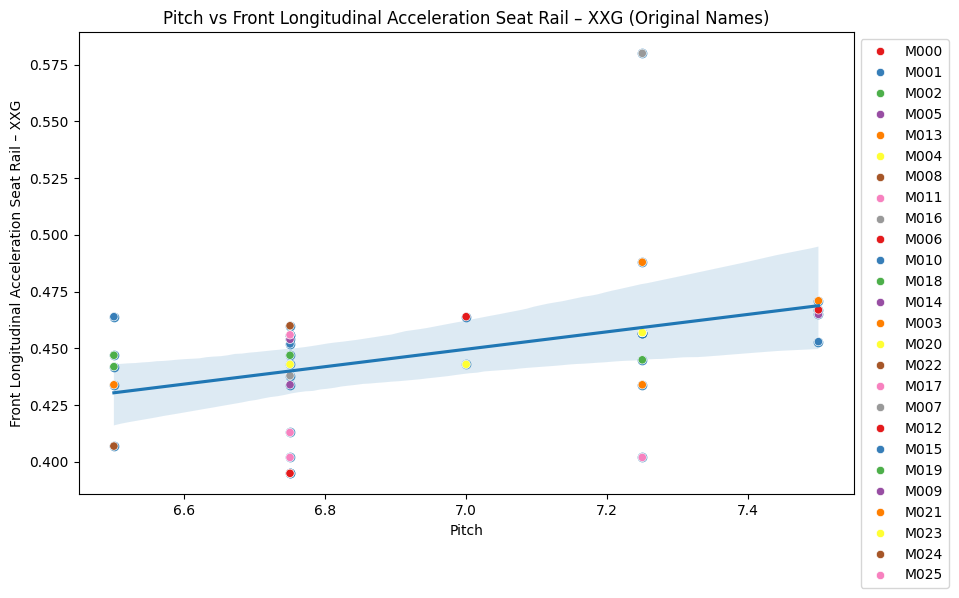

In [16]:
# Temporary renaming test for data visualisation only

#create a temporary copy of the dataframe for visualisation
train_df_plot = train_df.copy()

#locate the original column name for each of the 4 possible features that may be analysed
w_name = train_col_reference[train_col_reference['Letter'] == 'aj']['Original Name'].iloc[0]
x_name = train_col_reference[train_col_reference['Letter'] == 'c']['Original Name'].iloc[0]
y_name = train_col_reference[train_col_reference['Letter'] == 'a']['Original Name'].iloc[0]
z_name = train_col_reference[train_col_reference['Letter'] == 'b']['Original Name'].iloc[0]

#create a dictionary for temporary renaming for plotting
temp_rename_map = {
    'aj': w_name,
    'c': x_name,
    'a': y_name,
    'b': z_name
}

train_df_plot = train_df_plot.rename(columns=temp_rename_map)

#chart generation from temporary feature names
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df_plot[w_name], y=train_df_plot[x_name])
sns.scatterplot(data=train_df_plot, x=w_name, y=x_name, hue=y_name, palette='Set1')
plt.xlabel(w_name)
plt.ylabel(x_name)
plt.title(f"{w_name} vs {x_name} (Original Names)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

##**3 - Dictionary**

In [17]:
# Concatenate the two dataframes side-by-side and display
display(pd.concat([train_col_reference, validation_col_reference], axis=1))

,Letter,Original Name,Letter,Original Name
0,a,Model,a,Model
1,b,Sequency,b,Segment
2,c,Front Longitudinal Acceleration Seat Rail – XXG​​,c,Category
3,d,Front Longitudinal Dissipation Time Seat Rail ...,d,Brand
4,e,Rear Longitudinal Acceleration Seat Rail – XXG​​,e,Front Longitudinal Acceleration Seat Rail – XXG​​
5,f,Rear Longitudinal Dissipation Time Seat Rail -...,f,Front Longitudinal Dissipation Time Seat Rail ...
6,g,Ratio Front / Rear Acc Seat Rail - XXG,g,Rear Longitudinal Acceleration Seat Rail – XXG​​
7,h,Ratio Front / Rear Dissipation Seat Rail - XXG,h,Rear Longitudinal Dissipation Time Seat Rail -...
8,i,Front Vertical Acceleration Seat Rail – ZZG​​,i,Ratio Front / Rear Acc Seat Rail - XXG
9,j,Front Vertical Dissipation Time Seat Rail – ZZG​​,j,Ratio Front / Rear Dissipation Seat Rail - XXG


##**4 - Subroutine for obtaining Brand and Category**

###**Dimensionality Reduction and Visualisation**

##### PC1 -> first linear combination of the original features, which explains most of the variance in the data.
##### PC2 -> second linear combination, chosen so that it is:
#####   - Orthogonal to (independent of) PC1, i.e. it cannot repeat the same information;
#####   - It maximises the remaining variance (what PC1 did not explain).
##### PC3 -> third linear combination, also orthogonal to PC1 and PC2, which maximises the variance not yet captured by the first two.
##### And so on up to the total number of features.

#### **2 Principais Features**

Variância explicada por componente: [0.22565581 0.18472154]
Variância total explicada (2 PCs): 0.41037735091899086


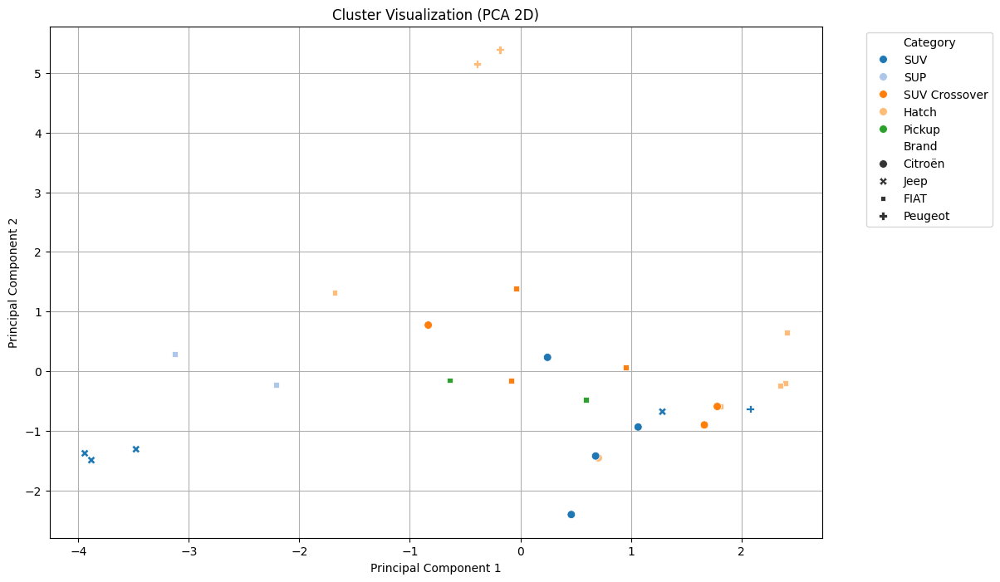

In [18]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Selection of the common numeric features
common_features = list(set(train_df.columns) & set(validation_df.columns))
features = [col for col in common_features if train_df[col].dtype in ['int64', 'float64'] and col not in ['a', 'b', 'c', 'd']]

# Scale validation_df
scaler = StandardScaler()
X_val_scaled = scaler.fit_transform(validation_df[features])

# PCA on validation_df only
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_val_scaled)

# DataFrame for plotting
pca_df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
pca_df['Category'] = validation_df_original['Category']
pca_df['Brand'] = validation_df_original['Brand']

print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada (2 PCs):", pca.explained_variance_ratio_.sum())

# Plot - PCA + 2D Prediction Overlay: makes hits, errors and confusions easy to see.
plt.figure(figsize=(12, 8))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='Category', style='Brand', palette='tab20', s=50)
plt.title('Cluster Visualization (PCA 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

#### **3 Principais Features**

Variância explicada por componente: [0.22565581 0.18472154 0.16337124]
Variância total explicada (3 PCs): 0.5737485864170766


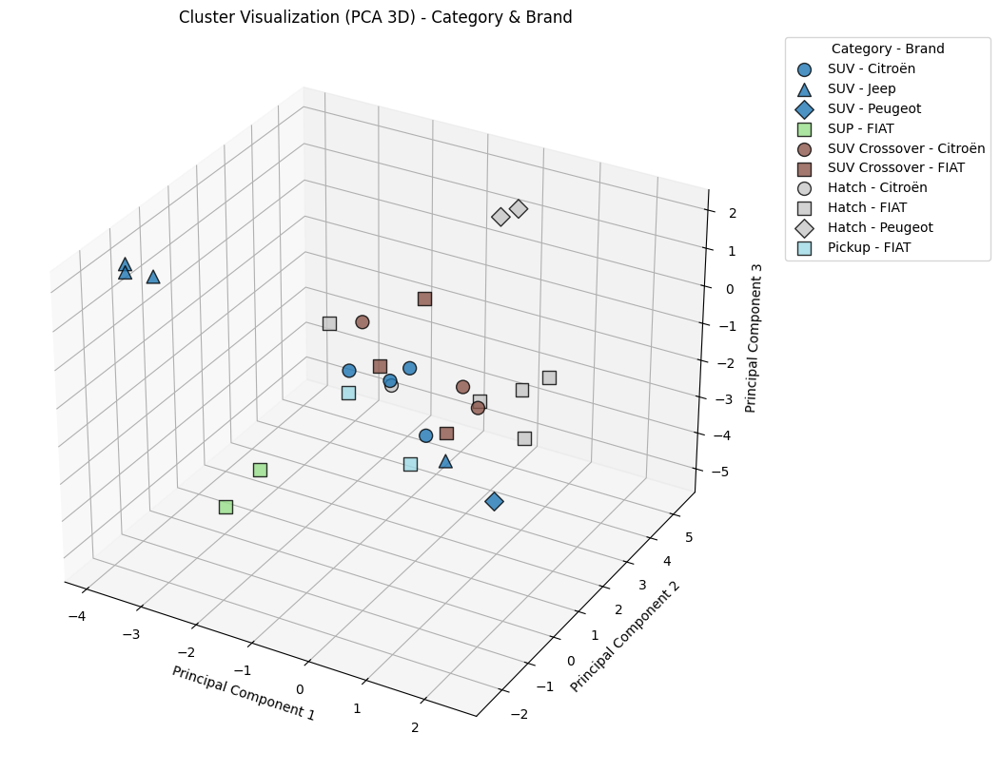

In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa

# ------------------------------
# 1) Data preparation
# ------------------------------
LABEL_COLS = ['Category', 'Brand', 'a', 'b', 'c', 'd', 'Model', 'Sequency']

common = list(set(train_df.columns) & set(validation_df.columns))
features = [col for col in common
            if np.issubdtype(train_df[col].dtype, np.number) and col not in LABEL_COLS]

mask_val = validation_df_original['Category'].notna() & validation_df_original['Brand'].notna()
mask_val &= validation_df[features].notna().all(axis=1)

validation_df_filtered = validation_df.loc[mask_val].reset_index(drop=True)
validation_df_original_filtered = validation_df_original.loc[mask_val].reset_index(drop=True)

X_val_scaled = StandardScaler().fit_transform(validation_df_filtered[features])

# ------------------------------
# 2) PCA 3D
# ------------------------------
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_val_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2', 'PCA3'])
pca_df['Category'] = validation_df_original_filtered['Category'].astype(str)
pca_df['Brand'] = validation_df_original_filtered['Brand'].astype(str)

print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada (3 PCs):", pca.explained_variance_ratio_.sum())

# ------------------------------
# 3) Plot - PCA + 3D Prediction Overlay: makes hits, errors and confusions easy to see.
# ------------------------------
fig = plt.figure(figsize=(20, 10))
ax = fig.add_subplot(111, projection='3d')

# Map Category to colors
categories = pca_df['Category'].unique()
color_map = {cat: i for i, cat in enumerate(categories)}
colors = plt.cm.tab20(np.linspace(0, 1, len(categories)))

# Define markers for Brands
brands = pca_df['Brand'].unique()
markers = ['o', '^', 's', 'D', 'v', '*', 'P', 'X', '<', '>']  # add more if necessary
brand_markers = {b: markers[i % len(markers)] for i, b in enumerate(brands)}

# Plot each Category-Brand combination
for cat in categories:
    for brand in brands:
        subset = pca_df[(pca_df['Category'] == cat) & (pca_df['Brand'] == brand)]
        if not subset.empty:
            ax.scatter(
                subset['PCA1'], subset['PCA2'], subset['PCA3'],
                color=colors[color_map[cat]],
                marker=brand_markers[brand],
                s=100,
                label=f"{cat} - {brand}",
                edgecolor='k',
                alpha=0.8
            )

# Remove duplicates in the legend
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), title='Category - Brand', bbox_to_anchor=(1.05, 1), loc='upper left')

ax.set_title('Cluster Visualization (PCA 3D) - Category & Brand')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

plt.show()

#### **4 Principais Features**

In [20]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Selection of the common numeric features
common_features = list(set(train_df.columns) & set(validation_df.columns))
features = [col for col in common_features
            if np.issubdtype(train_df[col].dtype, np.number) and col not in ['a', 'b', 'c', 'd']]

# Normalisation
scaler = StandardScaler()
X = scaler.fit_transform(validation_df[features])

# PCA with 4 components
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X)

# DataFrame for display
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4'])
pca_df['Category'] = validation_df_original['Category']
pca_df['Brand'] = validation_df_original['Brand']

print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada (4 PCs):", pca.explained_variance_ratio_.sum())

# Interactive 3D visualisation - PCA + 4D Prediction Overlay: makes hits, errors and confusions easy to see.
fig = px.scatter_3d(pca_df,
                    x='PC1', y='PC2', z='PC3',
                    color='Category',
                    symbol='Brand',
                    title='PCA 3D: Category e Brand',
                    labels={'PC1': 'PC1',
                            'PC2': 'PC2',
                            'PC3': 'PC3'},
                    color_continuous_scale='Viridis')

# Adding PC4 as the marker size (using absolute value for size)
fig.update_traces(marker=dict(size=abs(pca_df['PC4'])*10, opacity=0.8)) # Use abs()

fig.show()

Variância explicada por componente: [0.22565581 0.18472154 0.16337124 0.12922126]
Variância total explicada (4 PCs): 0.7029698443790995


#### **5 Principais Features**

In [21]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Selection of the common numeric features
common_features = list(set(train_df.columns) & set(validation_df.columns))
features = [col for col in common_features
            if np.issubdtype(train_df[col].dtype, np.number) and col not in ['a', 'b', 'c', 'd']]

# Normalisation
scaler = StandardScaler()
X = scaler.fit_transform(validation_df[features])

# PCA with 5 components
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)

# DataFrame for display
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
pca_df['Category'] = validation_df_original['Category']
pca_df['Brand'] = validation_df_original['Brand']

print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada (5 PCs):", pca.explained_variance_ratio_.sum())

# Interactive 3D visualisation - PCA + 5D Prediction Overlay: makes hits, errors and confusions easy to see.
fig = px.scatter_3d(pca_df,
                    x='PC1', y='PC2', z='PC3',
                    color='PC4',       # PC4 as colour
                    size=abs(pca_df['PC5']), # Use absolute value for size
                    symbol='Brand',    # Brand as symbol
                    hover_data=['Category'])
fig.show()

Variância explicada por componente: [0.22565581 0.18472154 0.16337124 0.12922126 0.08112977]
Variância total explicada (5 PCs): 0.7840996105172127


###**Brand and Category Prediction Result**

In [22]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# PCA with 7 components
pca = PCA(n_components=7)
X_pca = pca.fit_transform(X)

# DataFrame with the PCs
pca_df = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(pca.n_components)] # Use pca.n_components for column names
)
pca_df['Category'] = validation_df_original['Category']
pca_df['Brand'] = validation_df_original['Brand']

# Explained variance
print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada (7 PCs):", pca.explained_variance_ratio_.sum())

# Principal component loadings (features x PCs)
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1','PC2','PC3','PC4','PC5','PC6','PC7']
)

# sum of the absolute contributions over all PCs
abs_loadings = loadings.abs().sum(axis=1)
# take top 7
top_features = abs_loadings.sort_values(ascending=False).head(7).index.tolist()

# maps to descriptive names
top_features_named = [train_col_reference[train_col_reference['Letter'] == f]['Original Name'].iloc[0] for f in top_features]

print("\nTop 7 features mais relevantes (nomes originais):\n", top_features)
print("\nTop 7 features mais relevantes (nomes descritivos):\n")
for name, variance in zip(top_features_named, pca.explained_variance_ratio_):
    print(f"- {name}: {variance * 100:.2f}%")
print(f"\nTotal: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

Variância explicada por componente: [0.22565581 0.18472154 0.16337124 0.12922126 0.08112977 0.07760476
 0.04814779]
Variância total explicada (7 PCs): 0.9098521625008128

Top 7 features mais relevantes (nomes originais):
 ['q', 'l', 'f', 'e', 'n', 'g', 'j']

Top 7 features mais relevantes (nomes descritivos):

- RMS longitudinal acceleration at seat rail (8 to 20 Hz): 22.57%
- Rear Vertical Dissipation Time Seat Rail - ZZG​​: 18.47%
- Rear Longitudinal Dissipation Time Seat Rail - XXG​​: 16.34%
- Rear Longitudinal Acceleration Seat Rail – XXG​​: 12.92%
- Ratio Front / Rear Dissipation Seat Rail - ZZG: 8.11%
- Ratio Front / Rear Acc Seat Rail - XXG: 7.76%
- Front Vertical Dissipation Time Seat Rail – ZZG​​: 4.81%

Total: 90.99%


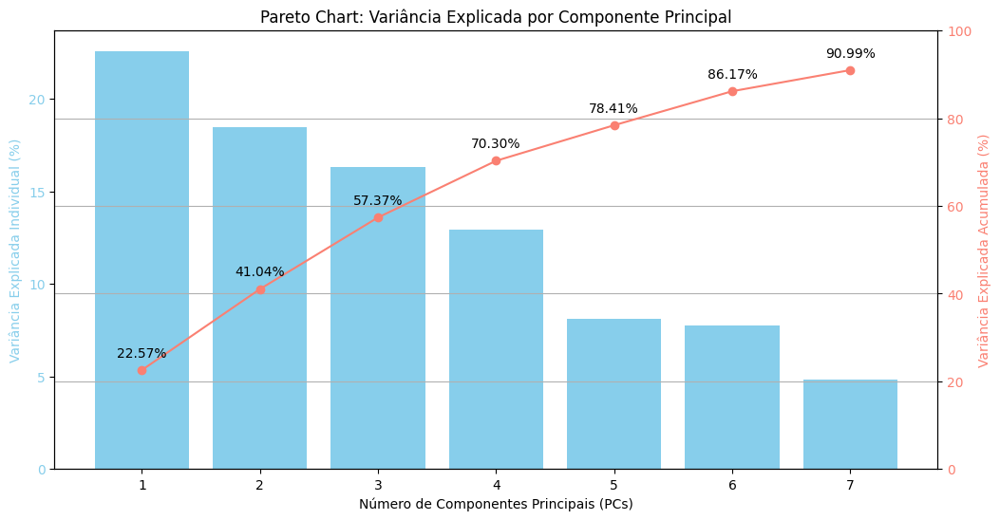

In [23]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features, # Use the 'features' list which contains the column names
    columns=[f'PC{i+1}' for i in range(pca.n_components)] # Use pca.n_components for column names
)
abs_loadings = loadings.abs().sum(axis=1)  # sum of the absolute contributions over all PCs
top_features = abs_loadings.sort_values(ascending=False).head(7).index.tolist()

# Convert to the descriptive names from the second column of the train_col_reference dataframe
top_features_named = [train_col_reference[train_col_reference['Letter'] == f]['Original Name'].iloc[0] for f in top_features]

# Plot - Variance explained by each PC as a Pareto chart
explained_variance = pca.explained_variance_ratio_ * 100 # Convert to percentage

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Create Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for individual explained variance
ax1.bar(range(1, len(explained_variance) + 1), explained_variance, color='skyblue')
ax1.set_xlabel("Número de Componentes Principais (PCs)")
ax1.set_ylabel("Variância Explicada Individual (%)", color='skyblue') # Update label
ax1.tick_params(axis='y', labelcolor='skyblue')

# Create a second y-axis for cumulative explained variance
ax2 = ax1.twinx()
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, color='salmon', marker='o', linestyle='-')
ax2.set_ylabel("Variância Explicada Acumulada (%)", color='salmon') # Update label
ax2.tick_params(axis='y', labelcolor='salmon')
ax2.set_ylim(0, 100) # Set y-axis limit to 0-100 for percentage

# Add cumulative percentage labels on the line
for i, txt in enumerate(cumulative_variance):
    ax2.annotate(f'{txt:.2f}%', (i + 1, txt), textcoords="offset points", xytext=(0, 10), ha='center') # Add % to annotation

plt.title("Pareto Chart: Variância Explicada por Componente Principal")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.show()

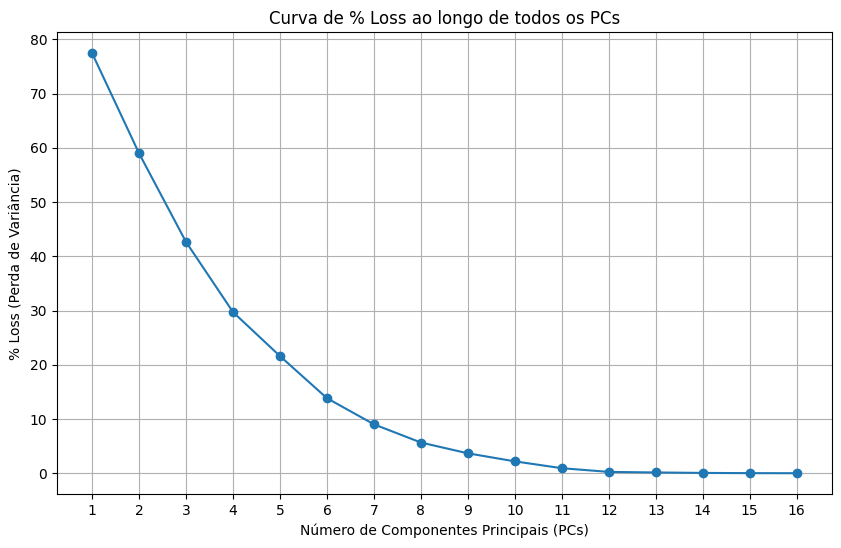

In [24]:
# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(validation_df[features])  # use all features

# PCA with the maximum number of components
pca_full = PCA(n_components=len(features))
X_pca_full = pca_full.fit_transform(X_scaled)

# Explained and cumulative variance
explained_variance_full = pca_full.explained_variance_ratio_
cumulative_variance_full = np.cumsum(explained_variance_full)

# % Loss = 100% - cumulative variance
percent_loss_full = 100 * (1 - cumulative_variance_full)

# Plot of the % Loss curve over all PCs - Shows the information loss when dimensionality is reduced.
plt.figure(figsize=(10,6))
plt.plot(range(1, len(percent_loss_full)+1), percent_loss_full, marker='o', linestyle='-')
plt.xticks(range(1, len(percent_loss_full)+1))
plt.xlabel("Número de Componentes Principais (PCs)")
plt.ylabel("% Loss (Perda de Variância)")
plt.title("Curva de % Loss ao longo de todos os PCs")
plt.grid(True)
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.manifold import TSNE
import umap

# Scaling
scaler = StandardScaler()
X_val_scaled = scaler.fit_transform(validation_df[features])  # Features still from validation_df
y_val_cat = validation_df_original['Category'].values # Use original for Category
y_val_brand = validation_df_original['Brand'].values # Use original for Brand


# PCA
n_pcs = min(10, len(features))  # up to 10 PCs or as many features as you have
pca = PCA(n_components=n_pcs)
X_val_pca = pca.fit_transform(X_val_scaled)

# DataFrame PCA
pca_df = pd.DataFrame(X_val_pca, columns=[f'PC{i+1}' for i in range(n_pcs)])
pca_df['Category'] = y_val_cat
pca_df['Brand'] = y_val_brand

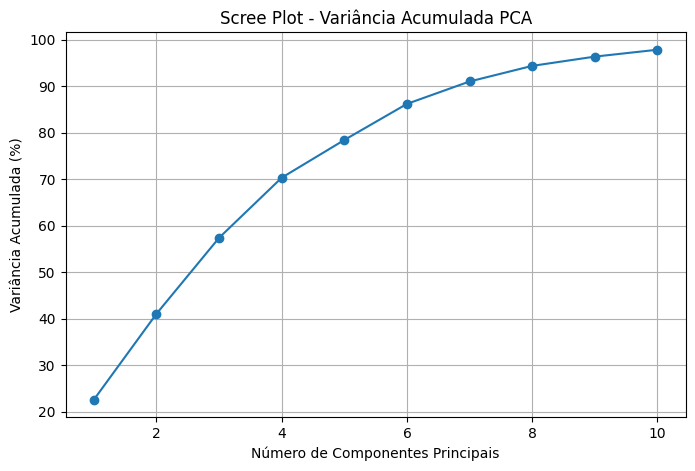

In [26]:
# Explained Variance Curve / Scree Plot - Shows the percentage of variance explained by each principal component.
plt.figure(figsize=(8,5))
plt.plot(range(1,n_pcs+1), np.cumsum(pca.explained_variance_ratio_)*100, marker='o')
plt.xlabel("Número de Componentes Principais")
plt.ylabel("Variância Acumulada (%)")
plt.title("Scree Plot - Variância Acumulada PCA")
plt.grid(True)
plt.show()

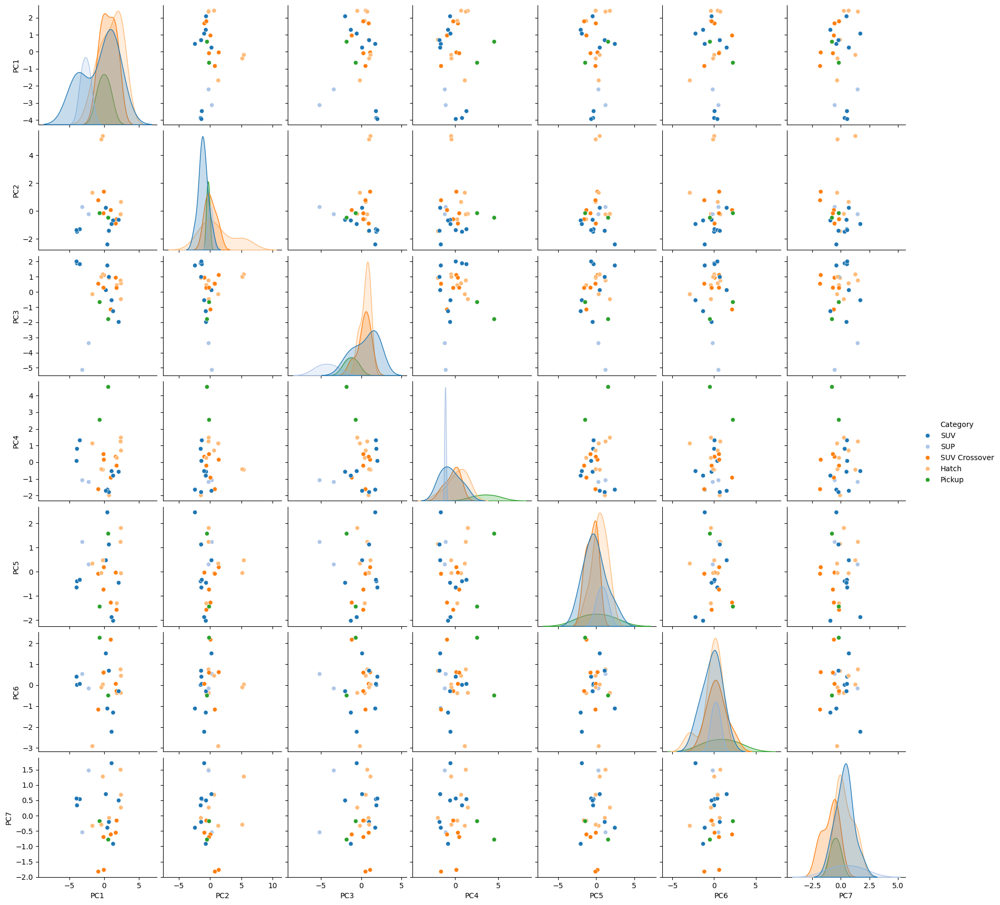

In [27]:
# PCA with 7 components
pca = PCA(n_components=7)
X_pca = pca.fit_transform(X)

# DataFrame for display
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7'])
pca_df['Category'] = validation_df_original['Category']
pca_df['Brand'] = validation_df_original['Brand']

# Pairplot / Scatter Matrix of the main PCs - Shows pairwise relationships between the most important PCs.
sns.pairplot(pca_df, hue='Category', vars=['PC1','PC2','PC3','PC4','PC5','PC6','PC7'], palette='tab20')

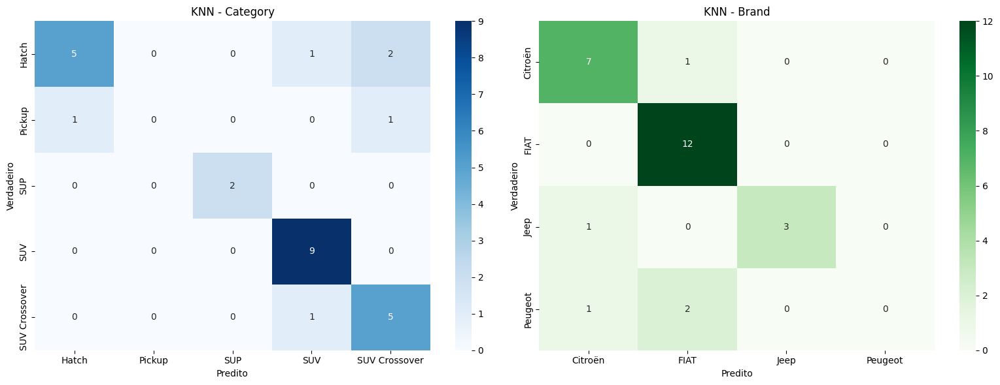

In [28]:
# 1) KNN for Category
knn_cat = KNeighborsClassifier(n_neighbors=5)
knn_cat.fit(X_val_scaled, y_val_cat)
y_pred_cat = knn_cat.predict(X_val_scaled)

# 2) KNN for Brand
knn_brand = KNeighborsClassifier(n_neighbors=5)
knn_brand.fit(X_val_scaled, y_val_brand)
y_pred_brand = knn_brand.predict(X_val_scaled)

# Confusion Matrices - Show the KNN performance for the inferred categories and brands.
cm_cat = confusion_matrix(y_val_cat, knn_cat.predict(X_val_scaled))
cm_brand = confusion_matrix(y_val_brand, knn_brand.predict(X_val_scaled))

labels_cat = sorted(np.unique(y_val_cat))
labels_brand = sorted(np.unique(y_val_brand))

# Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix - Category
sns.heatmap(cm_cat, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=labels_cat, yticklabels=labels_cat)
axes[0].set_title("KNN - Category")
axes[0].set_xlabel("Predito")
axes[0].set_ylabel("Verdadeiro")

# Confusion Matrix - Brand
sns.heatmap(cm_brand, annot=True, fmt='d', cmap='Greens', ax=axes[1], xticklabels=labels_brand, yticklabels=labels_brand)
axes[1].set_title("KNN - Brand")
axes[1].set_xlabel("Predito")
axes[1].set_ylabel("Verdadeiro")

plt.tight_layout()
plt.show()

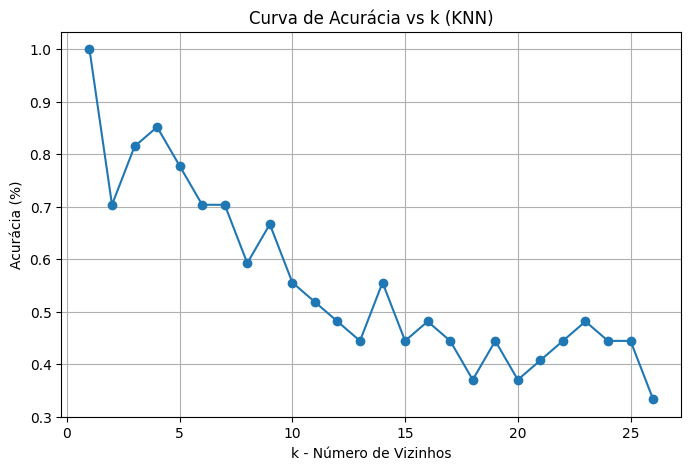

In [29]:
# KNN Accuracy vs. k curve - Assesses the model's sensitivity to the choice of the number of neighbours.
k_values = range(1, min(30,len(X_val_scaled)))  # k up to 30 or n samples
accuracies = [accuracy_score(y_val_cat, KNeighborsClassifier(n_neighbors=k).fit(X_val_scaled, y_val_cat).predict(X_val_scaled)) for k in k_values]

plt.figure(figsize=(8,5))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("k - Número de Vizinhos")
plt.ylabel("Acurácia (%)")
plt.title("Curva de Acurácia vs k (KNN)")
plt.grid(True)
plt.show()

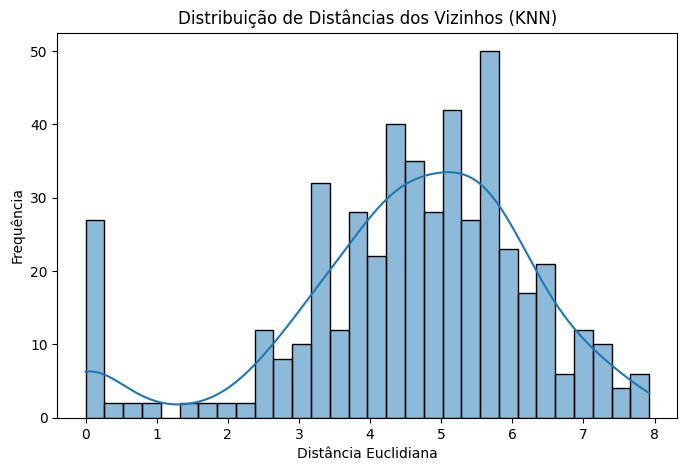

In [30]:
# Distribution of Neighbour Distances - Helps justify the choice of k and identify outliers or instabilities
knn_dist = KNeighborsClassifier(n_neighbors=18)
knn_dist.fit(X_val_scaled, y_val_cat)
distances, indices = knn_dist.kneighbors(X_val_scaled)

plt.figure(figsize=(8,5))
sns.histplot(distances.flatten(), bins=30, kde=True)
plt.title("Distribuição de Distâncias dos Vizinhos (KNN)")
plt.xlabel("Distância Euclidiana")
plt.ylabel("Frequência")
plt.show()

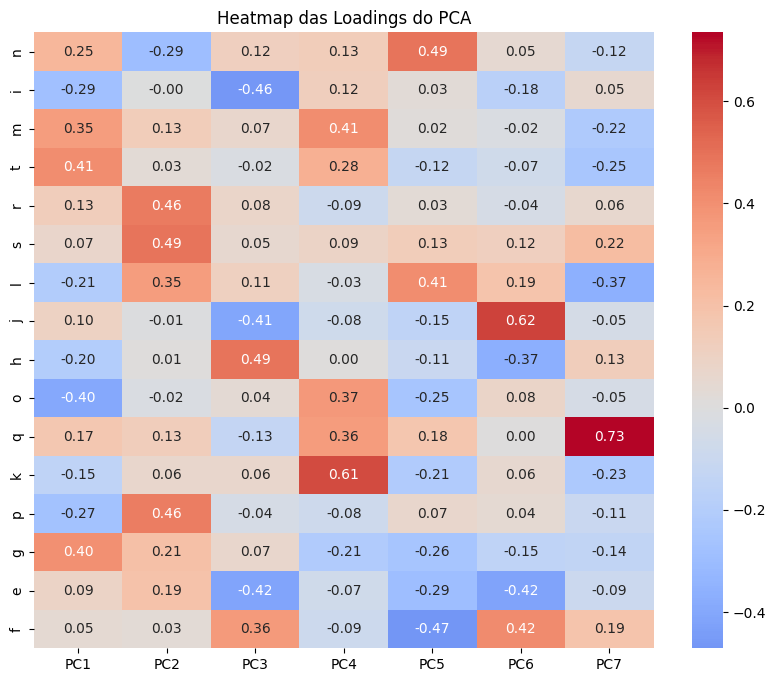

In [31]:
# Heatmap of the PCA Loadings - contribution of each feature to each PC
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

plt.figure(figsize=(10, 8))
sns.heatmap(loadings, cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title("Heatmap das Loadings do PCA")
plt.show()

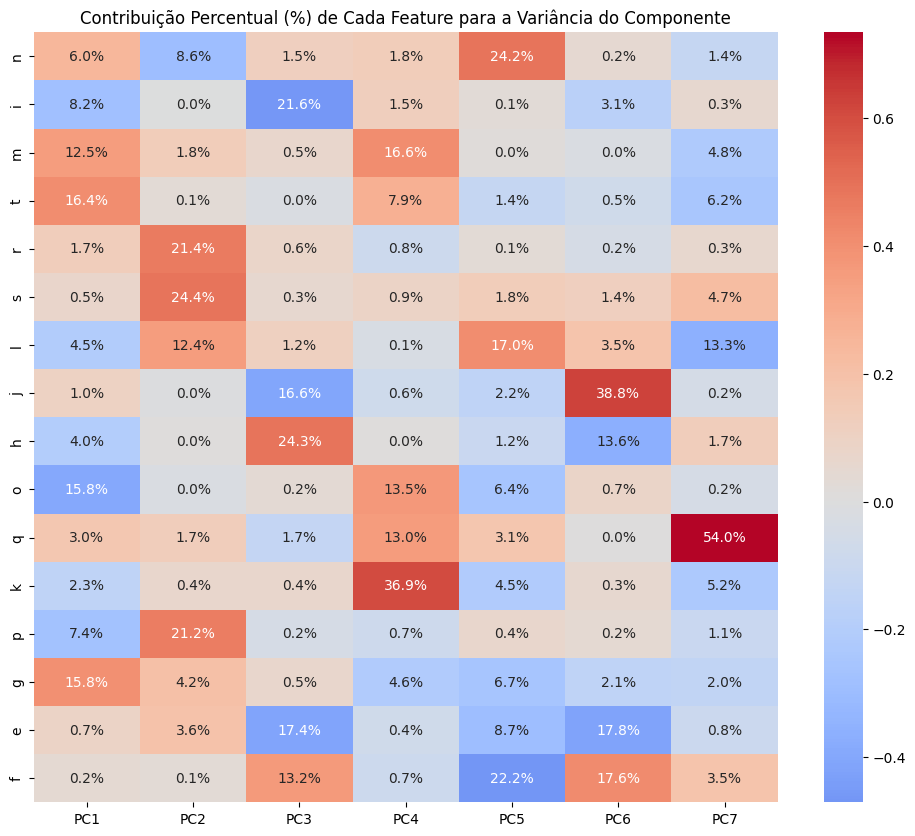

In [32]:
# Heatmap of the PCA Loadings - contribution of each feature to each PC
loadings_contribution_percent = (loadings ** 2) * 100
annot_labels = loadings_contribution_percent.applymap(lambda x: f'{x:.1f}%')

plt.figure(figsize=(12, 10))
sns.heatmap(loadings,               # Colour the map with the original values (+/-)
            cmap='coolwarm',
            center=0,
            annot=annot_labels,     # Add the percentage labels
            fmt=''                  # Disable the default annot formatting
           )
plt.title("Contribuição Percentual (%) de Cada Feature para a Variância do Componente")
plt.show()

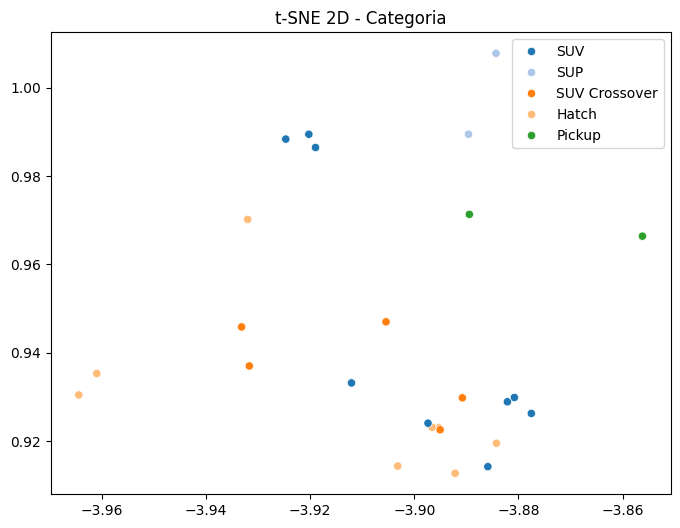

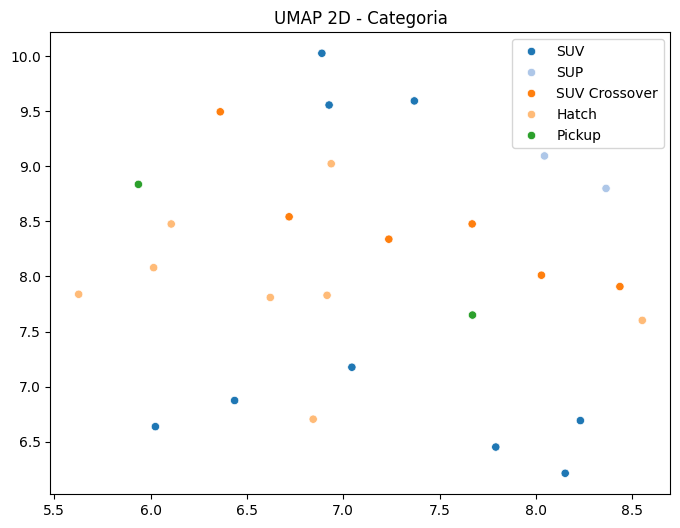

In [33]:
# t-SNE & UMAP - Complements PCA by showing more non-linear cluster structures; useful for visual validation of KNN and the consistency of the inferred categories.

# t-SNE
n_amostras = X_val_scaled.shape[0]
perplexidade_ajustada = n_amostras - 1 # Ensures it is smaller than n_amostras
tsne = TSNE(n_components=2, random_state=42, perplexity=perplexidade_ajustada)
X_tsne = tsne.fit_transform(X_val_scaled)
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=y_val_cat, palette='tab20')
plt.title("t-SNE 2D - Categoria")
plt.show()

# UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_val_scaled)
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=y_val_cat, palette='tab20')
plt.title("UMAP 2D - Categoria")
plt.show()

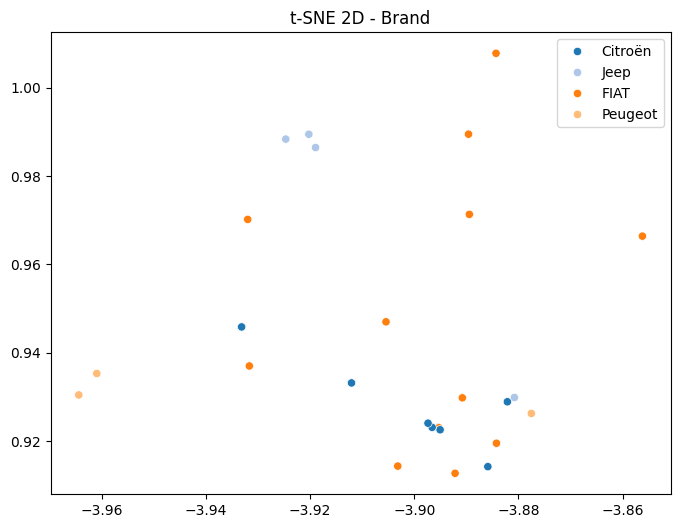

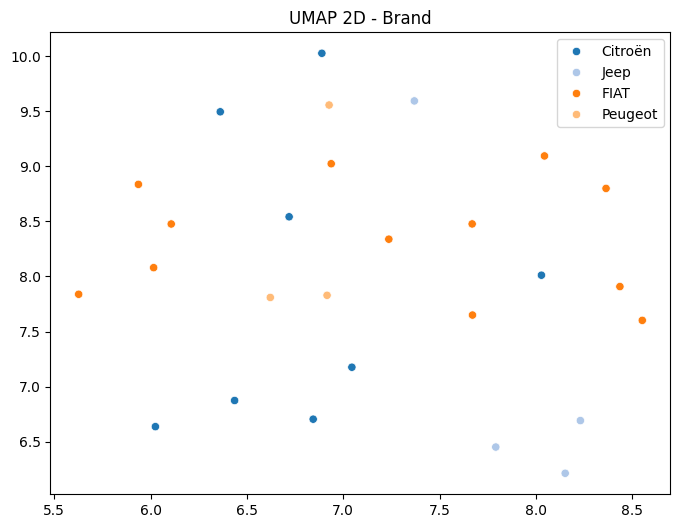

In [34]:
# t-SNE
n_amostras = X_val_scaled.shape[0]
perplexidade_ajustada = n_amostras - 1 # Ensures it is smaller than n_amostras
tsne = TSNE(n_components=2, random_state=42, perplexity=perplexidade_ajustada)

X_tsne = tsne.fit_transform(X_val_scaled)

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=y_val_brand, palette='tab20')
plt.title("t-SNE 2D - Brand")
plt.show()

# UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_val_scaled)
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=y_val_brand, palette='tab20')
plt.title("UMAP 2D - Brand")
plt.show()

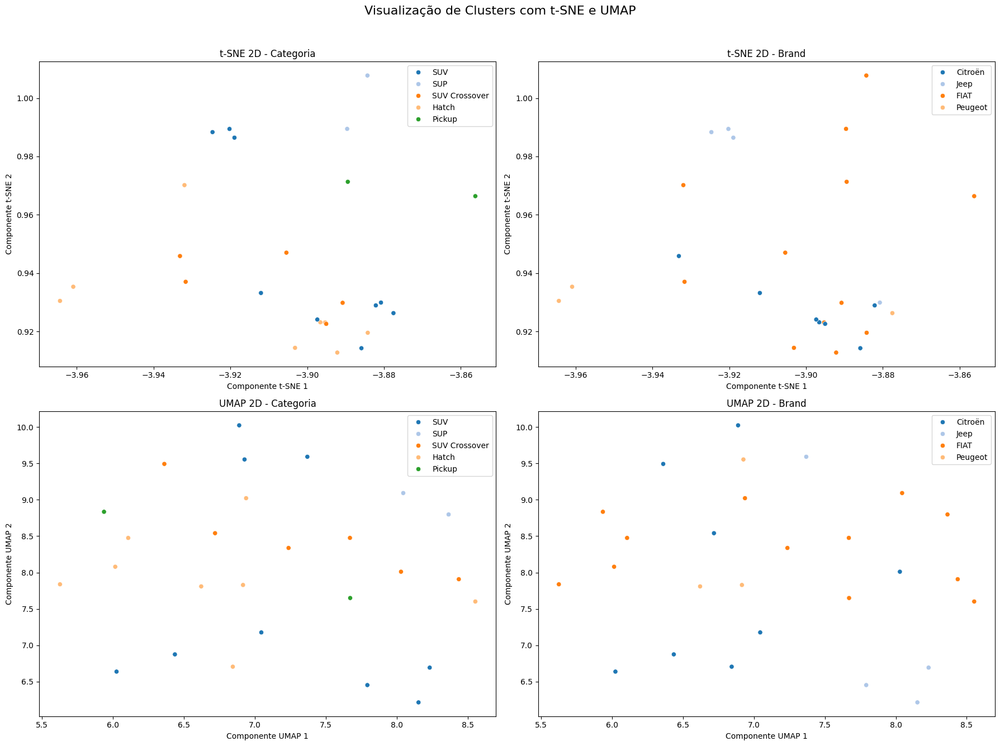

In [35]:
# t-SNE
n_amostras = X_val_scaled.shape[0]
perplexidade_ajustada = max(1, n_amostras - 1) # Ensures it is at least 1
tsne = TSNE(n_components=2, random_state=42, perplexity=perplexidade_ajustada)
X_tsne = tsne.fit_transform(X_val_scaled)

# UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_val_scaled)


# --- 2. Creating the 2x2 Subplot Grid ---
# We create a figure and an array of axes with 2 rows and 2 columns.
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Add an overall title for the whole figure
fig.suptitle('Visualização de Clusters com t-SNE e UMAP', fontsize=16)


# --- 3. Filling each subplot ---

# Chart 1 (row 0, column 0): t-SNE Category
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=y_val_cat, palette='tab20', ax=axes[0, 0], legend='auto')
axes[0, 0].set_title("t-SNE 2D - Categoria")
axes[0, 0].set_xlabel("Componente t-SNE 1")
axes[0, 0].set_ylabel("Componente t-SNE 2")

# Chart 2 (row 0, column 1): t-SNE Brand
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=y_val_brand, palette='tab20', ax=axes[0, 1], legend='auto')
axes[0, 1].set_title("t-SNE 2D - Brand")
axes[0, 1].set_xlabel("Componente t-SNE 1")
axes[0, 1].set_ylabel("Componente t-SNE 2")

# Chart 3 (row 1, column 0): UMAP Category
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=y_val_cat, palette='tab20', ax=axes[1, 0], legend='auto')
axes[1, 0].set_title("UMAP 2D - Categoria")
axes[1, 0].set_xlabel("Componente UMAP 1")
axes[1, 0].set_ylabel("Componente UMAP 2")

# Chart 4 (row 1, column 1): UMAP Brand
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=y_val_brand, palette='tab20', ax=axes[1, 1], legend='auto')
axes[1, 1].set_title("UMAP 2D - Brand")
axes[1, 1].set_xlabel("Componente UMAP 1")
axes[1, 1].set_ylabel("Componente UMAP 2")


# --- 4. Final adjustment and display ---
# Adjust spacing to avoid overlapping titles and axes
plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # rect adjusts so that the suptitle does not overlap
plt.show()

In [36]:
# Silhouette Score - Assesses the coherence of the clusters formed.
labels = y_val_cat
sil_score = silhouette_score(X_val_pca, labels)
print(f"Silhouette Score: {sil_score * 100:.2f}%")

Silhouette Score: 2.76%


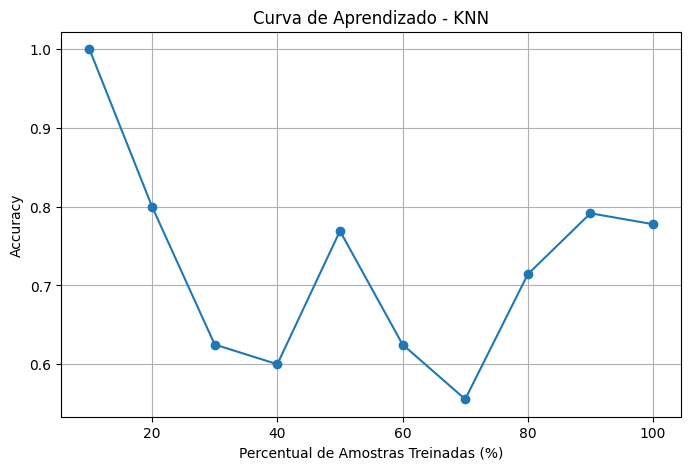

In [37]:
# Learning Curves (Accuracy vs. number of samples)
train_sizes = np.linspace(0.1, 1.0, 10)
accs = []
for frac in train_sizes:
    n_samples = int(len(X_val_scaled)*frac)
    if n_samples == 0: # Avoid fitting with 0 samples
        continue
    n_neighbors_adjusted = min(n_samples, 5) # Adjust n_neighbors based on current sample size
    knn_temp = KNeighborsClassifier(n_neighbors=n_neighbors_adjusted)
    knn_temp.fit(X_val_scaled[:n_samples], y_val_cat[:n_samples])
    accs.append(accuracy_score(y_val_cat[:n_samples], knn_temp.predict(X_val_scaled[:n_samples])))

plt.figure(figsize=(8,5))
plt.plot(train_sizes[:len(accs)]*100, accs, marker='o') # Adjust train_sizes to match accs length
plt.xlabel("Percentual de Amostras Treinadas (%)")
plt.ylabel("Accuracy")
plt.title("Curva de Aprendizado - KNN")
plt.grid(True)
plt.show()

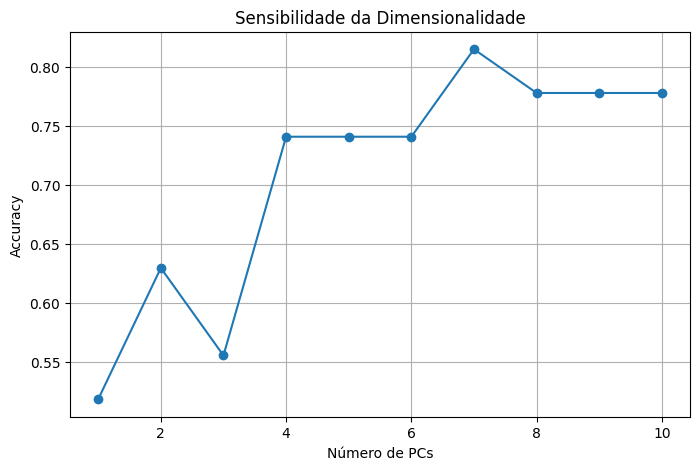

In [38]:
# Dimensionality Sensitivity (Accuracy vs. number of PCs)
acc_pcs = []
for n in range(1, n_pcs+1):
    X_tmp = PCA(n_components=n).fit_transform(X_val_scaled)
    knn_tmp = KNeighborsClassifier(n_neighbors=5)
    knn_tmp.fit(X_tmp, y_val_cat)
    acc_pcs.append(accuracy_score(y_val_cat, knn_tmp.predict(X_tmp)))

plt.figure(figsize=(8,5))
plt.plot(range(1,n_pcs+1), acc_pcs, marker='o')
plt.xlabel("Número de PCs")
plt.ylabel("Accuracy")
plt.title("Sensibilidade da Dimensionalidade")
plt.grid(True)
plt.show()

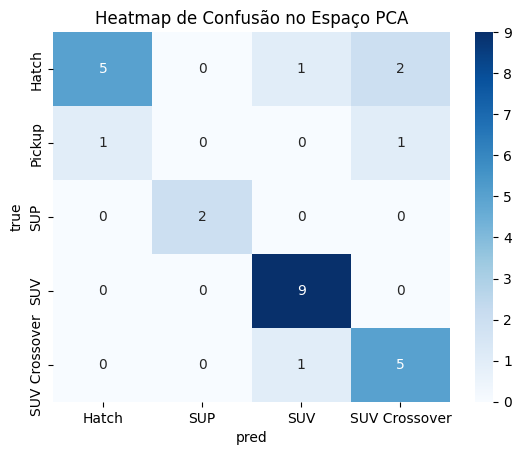

In [39]:
# Confusion Heatmap in PCA Space
df_overlay = pd.DataFrame(X_val_pca[:, :2], columns=['PC1','PC2'])
df_overlay['true'] = y_val_cat
df_overlay['pred'] = y_pred_cat
cm_pca = pd.crosstab(df_overlay['true'], df_overlay['pred'])

sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Blues')
plt.title("Heatmap de Confusão no Espaço PCA")
plt.show()

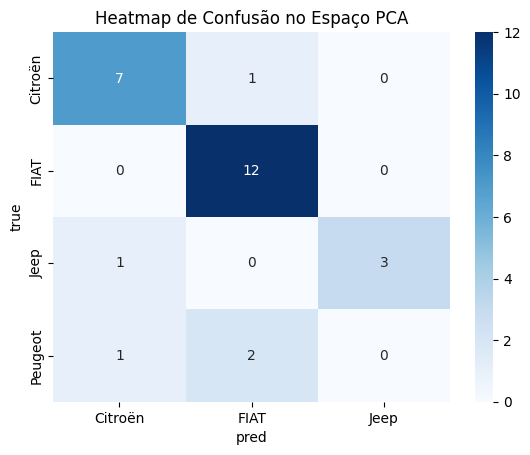

In [40]:
# Confusion Heatmap in PCA Space
df_overlay = pd.DataFrame(X_val_pca[:, :2], columns=['PC1','PC2'])
df_overlay['true'] = y_val_brand
df_overlay['pred'] = y_pred_brand
cm_pca = pd.crosstab(df_overlay['true'], df_overlay['pred'])

sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Blues')
plt.title("Heatmap de Confusão no Espaço PCA")
plt.show()

In [41]:
# Minimal filtering (removal of NaNs)
mask_val = validation_df_original['Category'].notna() & validation_df_original['Brand'].notna()
mask_val &= validation_df[features].notna().all(axis=1)

validation_df_filtered = validation_df.loc[mask_val].reset_index(drop=True)
validation_df_original_filtered = validation_df_original.loc[mask_val].reset_index(drop=True)

mask_tr = train_df[features].notna().all(axis=1)
train_df_filtered = train_df.loc[mask_tr].reset_index(drop=True)

# Rescaling
scaler = StandardScaler()
X_val_scaled = scaler.fit_transform(validation_df_filtered[features])
X_train_scaled = scaler.transform(train_df_filtered[features])

y_cat = validation_df_original_filtered['Category'].values
y_brand = validation_df_original_filtered['Brand'].values

# Training and Prediction
k = min(4, len(validation_df_filtered))  # avoids k > n_samples

knn_cat = KNeighborsClassifier(n_neighbors=k, metric='euclidean', weights='distance')
knn_cat.fit(X_val_scaled, y_cat)
cat_pred = knn_cat.predict(X_train_scaled)

knn_brand = KNeighborsClassifier(n_neighbors=k, metric='euclidean', weights='distance')
knn_brand.fit(X_val_scaled, y_brand)
brand_pred = knn_brand.predict(X_train_scaled)

# Insert predictions into train_df
train_df['Category'] = np.nan
train_df['Brand'] = np.nan
train_df.loc[mask_tr, 'Category'] = cat_pred
train_df.loc[mask_tr, 'Brand'] = brand_pred
display(train_df)

Letter,a,b,c,d,e,f,g,h,i,j,...,ad,ae,af,ag,ah,ai,aj,ak,Category,Brand
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00,SUV,Citroën
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75,SUV,Citroën
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25,SUV,Citroën
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50,SUV,Jeep
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75,SUV,Citroën
5,M002,5,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-727.42,7.00,6.75,6.50,6.50,7.25,6.50,7.00,SUV,Citroën
6,M004,6,0.46,0.13,1.22,0.17,0.37,0.77,0.31,0.13,...,-818.83,7.25,7.25,7.25,6.75,6.50,6.75,7.25,SUV,Citroën
7,M008,7,0.46,0.13,1.26,0.18,0.36,0.71,0.31,0.13,...,-738.52,7.50,7.00,7.25,7.25,7.25,7.25,6.75,SUV,Citroën
8,M011,8,0.40,0.09,1.10,0.17,0.36,0.54,0.28,0.13,...,-742.21,7.25,7.25,6.50,6.50,7.75,7.25,7.50,Hatch,FIAT
9,M016,9,0.44,0.09,1.20,0.20,0.37,0.45,0.36,0.13,...,-799.18,7.50,6.50,6.25,6.25,7.50,6.75,7.25,Hatch,FIAT


## **5 - Data Analysis**

###**General**

In [42]:
estatisticas_df = train_df.describe().round(3).T

mapa_de_traducao = train_col_reference.set_index('Letter')['Original Name']
estatisticas = estatisticas_df.rename(index=mapa_de_traducao)

print("\nRESULTADO FINAL (Tabela com Índice Traduzido)")
display(estatisticas)


RESULTADO FINAL (Tabela com Índice Traduzido)


,count,mean,std,min,25%,50%,75%,max
Letter,,,,,,,,
Sequency,32.00,15.50,9.38,0.00,7.75,15.50,23.25,31.00
Front Longitudinal Acceleration Seat Rail – XXG​​,32.00,0.45,0.03,0.40,0.43,0.45,0.46,0.58
Front Longitudinal Dissipation Time Seat Rail – XXG​​,32.00,0.12,0.03,0.08,0.09,0.13,0.13,0.19
Rear Longitudinal Acceleration Seat Rail – XXG​​,32.00,1.22,0.09,1.03,1.19,1.21,1.23,1.44
Rear Longitudinal Dissipation Time Seat Rail - XXG​​,32.00,0.17,0.02,0.12,0.16,0.17,0.17,0.22
Ratio Front / Rear Acc Seat Rail - XXG,32.00,0.37,0.03,0.29,0.36,0.37,0.39,0.45
Ratio Front / Rear Dissipation Seat Rail - XXG,32.00,0.74,0.25,0.40,0.54,0.78,0.79,1.62
Front Vertical Acceleration Seat Rail – ZZG​​,32.00,0.32,0.03,0.28,0.31,0.31,0.34,0.39
Front Vertical Dissipation Time Seat Rail – ZZG​​,32.00,0.13,0.02,0.08,0.13,0.13,0.13,0.18


In [43]:
train_df[['Brand', 'Category']].describe().T

,count,unique,top,freq
Letter,,,,
Brand,32,3,Citroën,13
Category,32,2,SUV,22


In [44]:
cont_brand = train_df['Brand'].value_counts()
cont_categoria = train_df['Category'].value_counts()

print("--- Distribuição de Brands ---")
print(cont_brand)
print("\n" + "="*30 + "\n") # Separator line
print("--- Distribuição de Categorias ---")
print(cont_categoria)

--- Distribuição de Brands ---
Brand
Citroën    13
FIAT       10
Jeep        9
Name: count, dtype: int64


--- Distribuição de Categorias ---
Category
SUV      22
Hatch    10
Name: count, dtype: int64


--- Prevalência de Brands (%) ---
         Percentual (%)
Brand                  
Citroën           40.62
FIAT              31.25
Jeep              28.12


--- Prevalência de Categorias (%) ---
          Percentual (%)
Category                
SUV                68.75
Hatch              31.25


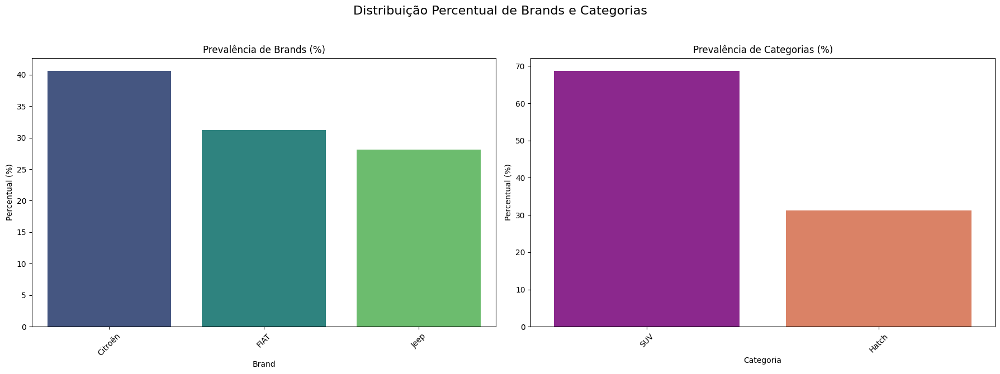

In [45]:
prevalencia_brand = (train_df['Brand'].value_counts(normalize=True) * 100).round(2)
prevalencia_categoria = (train_df['Category'].value_counts(normalize=True) * 100).round(2)

print("--- Prevalência de Brands (%) ---")
print(prevalencia_brand.to_frame(name='Percentual (%)'))

print("\n" + "="*30 + "\n")

print("--- Prevalência de Categorias (%) ---")
print(prevalencia_categoria.to_frame(name='Percentual (%)'))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

fig.suptitle('Distribuição Percentual de Brands e Categorias', fontsize=16)

sns.barplot(x=prevalencia_brand.index, y=prevalencia_brand.values, ax=axes[0], palette='viridis')
axes[0].set_title('Prevalência de Brands (%)')
axes[0].set_ylabel('Percentual (%)')
axes[0].set_xlabel('Brand')

axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=prevalencia_categoria.index, y=prevalencia_categoria.values, ax=axes[1], palette='plasma')
axes[1].set_title('Prevalência de Categorias (%)')
axes[1].set_ylabel('Percentual (%)')
axes[1].set_xlabel('Categoria')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

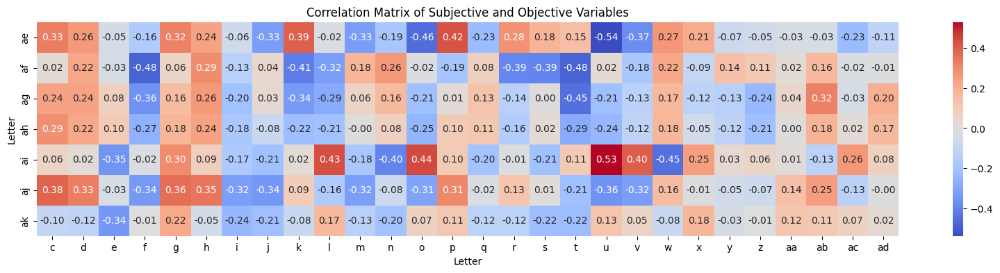

In [46]:
%matplotlib inline

numeric_cols = train_df.select_dtypes(include=np.number).columns
corr_matrix = train_df[numeric_cols].corr(method='pearson')

subset_corr_matrix = corr_matrix.iloc[29:, 1:29]

plt.figure(figsize=(20 , 4))
sns.heatmap(subset_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Subjective and Objective Variables')
plt.show()

###**Subjective Variables**

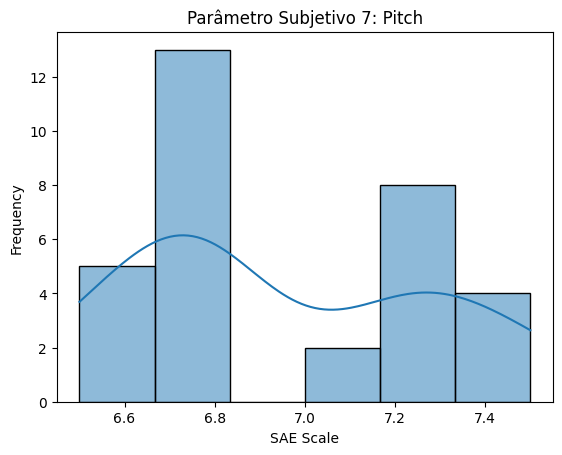

A média de Nota SAE para Pitch é: 6.75
O desvio padrão de Nota SAE para Pitch é: 0.33


In [47]:
sns.histplot(train_df['aj'], kde=True)
plt.xlabel('SAE Scale')
plt.ylabel('Frequency')
plt.title('Parâmetro Subjetivo 7: Pitch')
plt.show()
print(f"A média de Nota SAE para Pitch é: {train_df['aj'].median():.2f}")
print(f"O desvio padrão de Nota SAE para Pitch é: {train_df['aj'].std():.2f}")

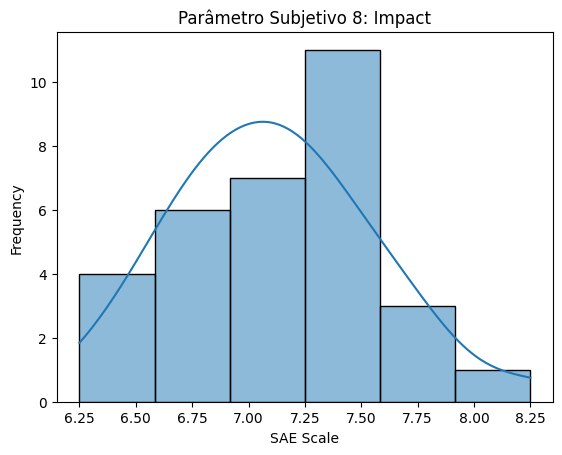

A média de Nota SAE para Impact é: 7.00
O desvio padrão de Nota SAE para Impact é: 0.44


In [48]:
sns.histplot(train_df['ai'], kde=True)
plt.xlabel('SAE Scale')
plt.ylabel('Frequency')
plt.title('Parâmetro Subjetivo 8: Impact')
plt.show()
print(f"A média de Nota SAE para Impact é: {train_df['ai'].median():.2f}")
print(f"O desvio padrão de Nota SAE para Impact é: {train_df['ai'].std():.2f}")

###**Results Correlation**

In [49]:
positive_threshold = 0.35
negative_threshold = -0.35

subset_cols = subset_corr_matrix.columns
subset_index = subset_corr_matrix.index

output_data = []

for col_name in subset_cols:
    for index_name in subset_index:
        if col_name != index_name:
            correlation_value = corr_matrix.loc[index_name, col_name]
            if correlation_value > positive_threshold or correlation_value < negative_threshold:
                output_data.append([index_name, col_name, correlation_value])

output_df = pd.DataFrame(output_data, columns=['Subjective Variable', 'Objective Variable', 'Correlation'])
output_df['Objective Variable']  = output_df['Objective Variable'].map(mapa_de_traducao).fillna(output_df['Objective Variable'])
output_df['Subjective Variable'] = output_df['Subjective Variable'].map(mapa_de_traducao).fillna(output_df['Subjective Variable'])

pd.set_option('display.max_colwidth', None)
display(output_df)

,Subjective Variable,Objective Variable,Correlation
0,Pitch,Front Longitudinal Acceleration Seat Rail – XXG​​,0.38
1,Impact,Rear Longitudinal Acceleration Seat Rail – XXG​​,-0.35
2,Smoothness (3 to 8 Hz),Rear Longitudinal Dissipation Time Seat Rail - XXG​​,-0.48
3,Wheel Bounce,Rear Longitudinal Dissipation Time Seat Rail - XXG​​,-0.36
4,Pitch,Ratio Front / Rear Acc Seat Rail - XXG,0.36
5,Low frequency vertical comfort (0 to 3 Hz),Rear Vertical Acceleration Seat Rail – ZZG​​,0.39
6,Smoothness (3 to 8 Hz),Rear Vertical Acceleration Seat Rail – ZZG​​,-0.41
7,Impact,Rear Vertical Dissipation Time Seat Rail - ZZG​​,0.43
8,Impact,Ratio Front / Rear Dissipation Seat Rail - ZZG,-0.40
9,Low frequency vertical comfort (0 to 3 Hz),RMS longitudinal acceleration at seat rail (0.5 to 3 Hz),-0.46


In [50]:
positive_threshold = 0.35
negative_threshold = -0.35

subset_cols = subset_corr_matrix.columns
subset_index = subset_corr_matrix.index

output_data = []

for col_name in subset_cols:
    for index_name in subset_index:
        if col_name != index_name:
            correlation_value = corr_matrix.loc[index_name, col_name]
            if correlation_value > positive_threshold or correlation_value < negative_threshold:
                output_data.append([index_name, col_name, correlation_value])

output_df = pd.DataFrame(output_data, columns=['Subjective Variable', 'Objective Variable', 'Correlation'])
output_df['Objective Variable']  = output_df['Objective Variable'].map(mapa_de_traducao).fillna(output_df['Objective Variable'])
output_df['Subjective Variable'] = output_df['Subjective Variable'].map(mapa_de_traducao).fillna(output_df['Subjective Variable'])

styled_corr_table = output_df.style

styled_corr_table = styled_corr_table.background_gradient(
    cmap='bwr',          #'bwr' (Blue -> White -> Red)
    subset=['Correlation'],
    vmin=-1.0,           # Blue = -1.0
    vmax=1.0             # Red = 1.0
)

styled_corr_table = styled_corr_table.format({'Correlation': '{:,.2f}'})

styled_corr_table = styled_corr_table.set_properties(
    **{'border': '1px solid #000000', 'width': 'auto'}
)

styled_corr_table = styled_corr_table.set_properties(
    subset=['Subjective Variable', 'Objective Variable'],
    **{
        'background-color': '#ffffff',
        'color': '#000000',
        'border': '1px solid #000000'
    }
)

styled_corr_table = styled_corr_table.set_properties(
    subset=['Correlation'],
    **{'text-align': 'center', 'width': 'auto'}
)

styled_corr_table = styled_corr_table.set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#ffffff'),
        ('color', '#000000'),
        ('font-size', '11px'),
        ('border-bottom', '1px solid #000000'),
        ('text-align', 'center')
    ]},
    {'selector': '.index_name', 'props': [('background-color', '#ffffff'), ('color', '#000000')]},
    {'selector': 'tbody', 'props': [('background-color', '#ffffff'), ('color', '#000000')]}

])

styled_corr_table = styled_corr_table.hide(axis='index')

display(styled_corr_table)

Subjective Variable,Objective Variable,Correlation
Pitch,Front Longitudinal Acceleration Seat Rail – XXG​​,0.38
Impact,Rear Longitudinal Acceleration Seat Rail – XXG​​,-0.35
Smoothness (3 to 8 Hz),Rear Longitudinal Dissipation Time Seat Rail - XXG​​,-0.48
Wheel Bounce,Rear Longitudinal Dissipation Time Seat Rail - XXG​​,-0.36
Pitch,Ratio Front / Rear Acc Seat Rail - XXG,0.36
Low frequency vertical comfort (0 to 3 Hz),Rear Vertical Acceleration Seat Rail – ZZG​​,0.39
Smoothness (3 to 8 Hz),Rear Vertical Acceleration Seat Rail – ZZG​​,-0.41
Impact,Rear Vertical Dissipation Time Seat Rail - ZZG​​,0.43
Impact,Ratio Front / Rear Dissipation Seat Rail - ZZG,-0.40
Low frequency vertical comfort (0 to 3 Hz),RMS longitudinal acceleration at seat rail (0.5 to 3 Hz),-0.46


##**6 - Visual Data Analysis**

###**Pitch Components**

In [51]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='aj',        # X axis
        y='c',    # Y axis
        z='u',    # Z axis
        size='g',       # Size
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='aj',
        labels=labels_map,
        title=f"3D Analysis of Components vs. {labels_map.get('aj', 'aj')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('aj', 'aj'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

###**Low Frequency Vertical Comfort (0 to 3 Hz) Components**

In [52]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ae',        # X axis - Low Frequency Vertical Comfort (0 to 3 Hz)
        y='p',    # Y axis - RMS Longitudinal Acceleration at Seat Rail (3 to 8 Hz)
        z='o',    # Z axis - RMS Longitudinal Acceleration at Seat Rail (0.5 to 3 Hz)
        size='k',       # Size - Rear Vertical Acceleration Seat Rail - ZZG
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ae',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ae', 'ae')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ae', 'ae'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

In [53]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ae',        # X axis - Low Frequency Vertical Comfort (0 to 3 Hz)
        y='u',    # Y axis - RMS Pitch Acceleration (3 to 8 Hz)
        z='v',    # Z axis - RMS Roll Acceleration (0.5 to 3 Hz)
        size='ae',       # Size - Low Frequency Vertical Comfort (0 to 3 Hz)
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ae',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ae', 'ae')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ae', 'ae'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

###**Smoothness (3 to 8 Hz) Components**

In [54]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='af',        # X axis - Smoothness (3 to 8 Hz)
        y='f',    # Y axis - Rear Longitudinal Dissipation Time Seat Rail - XXG
        z='k',    # Z axis - Rear Vertical Acceleration Seat Rail - ZZG
        size='af',       # Size - Smoothness (3 to 8 Hz)
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='af',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('af', 'af')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('af', 'af'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

In [55]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='af',        # X axis - Smoothness (3 to 8 Hz)
        y='o',    # Y axis - RMS vertical acceleration at seat reail 0.5 to 3 Hz
        z='p',    # Z axis - RMS vertical acceleration at seat reail 3 to 8 Hz
        size='q',       # Size - RMS vertical acceleration at seat reail 8 to 20 Hz
        symbol='af',  # Symbol (e.g. Circle, X)
        color='q',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('af', 'af')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('q', 'q'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.92,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='RMS vertical acceleration at seat reail 8 to 20 Hz',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

###**Wheel Bounce Components**

In [56]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ag',        # X axis - Wheel Bounce
        y='f',    # Y axis - Rear Longitudinal Dissipation Time Seat Rail - XXG
        z='t',    # Z axis - RMS vertical acceleration at seat rail (8 to 20 Hz)
        size='ag',       # Size - Wheel Bounce
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ag',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ag', 'ag')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ag', 'ag'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

###**Impact Components**

In [57]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ai',        # X axis - Impact
        y='l',    # Y axis - Rear Vertical Dissipation Time Seat Rail – ZZG
        z='e',    # Z axis - Rear Longitudinal Acceleration Seat Rail – XXG
        size='n',       # Size - Ratio Front / Rear Dissipation Seat Rail – ZZG
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ai',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ai', 'ai')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ai', 'ai'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

In [58]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ai',        # X axis - Impact
        y='u',    # Y axis - RMS pitch acceleration 0.5 to 3 Hz
        z='v',    # Z axis - RMS roll acceleration 0.5 to 3 Hz
        size='ai',       # Size - Impact
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ai',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ai', 'ai')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ai', 'ai'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

In [59]:
df_original = train_df
labels_map = mapa_de_traducao

try:
    fig = px.scatter_3d(
        data_frame=train_df,
        x='ai',        # X axis - Impact
        y='o',    # Y axis - RMS longitudinal acceleration at seat rail 0.5 to 3 Hz
        z='w',    # Z axis - Peak Jounce Front Left at TopMount Vertical Force – ZZG
        size='ai',       # Size - Impact
        symbol='Category',  # Symbol (e.g. Circle, X)
        color='ai',
        labels=labels_map, # Use your translation map for the axis titles
        title=f"3D Analysis of Components vs. {labels_map.get('ai', 'ai')}"
    )

    fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

    fig.update_layout(

        width=1500,  # Width in pixels
        height=1500, # Height in pixels

        # --- 1. Editing the "Legend Bar" (Colorbar for 'aj') ---
        coloraxis_colorbar=dict(
            title=labels_map.get('ai', 'ai'), # Colour bar title
            orientation='v',   # 'h' = horizontal
            y=0.4,            # Y position (below the chart)
            x=1,             # X position (centre)
            xanchor='center',
            len=0.94,
            thickness=20
        ),

        # --- 2. Editing the Symbol Legend ('Category') ---
        legend=dict(
            title_text='Category',
            orientation='v',
            y=0.95,
            x=1,
            xanchor='center',
            yanchor='top'
        ),

        # (Adjust the bottom margin to leave room for the colour bar)
        margin=dict(b=100)
    )

    fig.show()

except NameError as e:
    print(f"\n!!!!!!!! ERRO DE NOME: {e} !!!!!!!!")
    print("Isso pode ter acontecido se 'labels_map' ou 'train_df' não estiverem definidos.")
except KeyError as e:
    print(f"\n!!!!!!!! ERRO: Nome da coluna não encontrado: {e} !!!!!!!!")
    print("Por favor, verifique se os nomes 'aj', 'c', 'u', 'g', 'category' existem EXATAMENTE no seu DataFrame 'train_df'.")
    print(f"Colunas disponíveis: {list(train_df.columns)}")
except Exception as e:
     print(f"\n!!!!!!!! ERRO ao gerar o gráfico !!!!!!!!")
     print(f"Erro: {e}")

###Pitch vs Front Longitudinal Acceleration Seat Rail - XXG

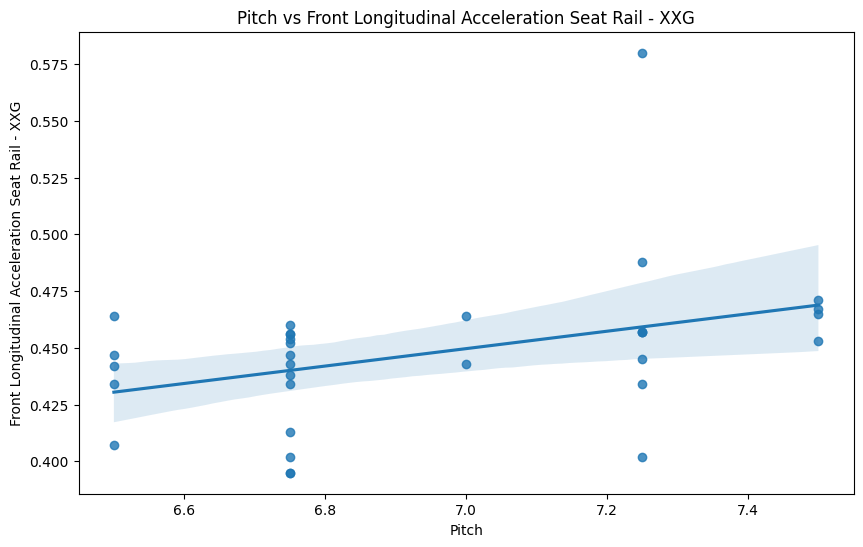

In [60]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["c"])
plt.xlabel("Pitch")
plt.ylabel("Front Longitudinal Acceleration Seat Rail - XXG")
plt.title("Pitch vs Front Longitudinal Acceleration Seat Rail - XXG")
plt.show()

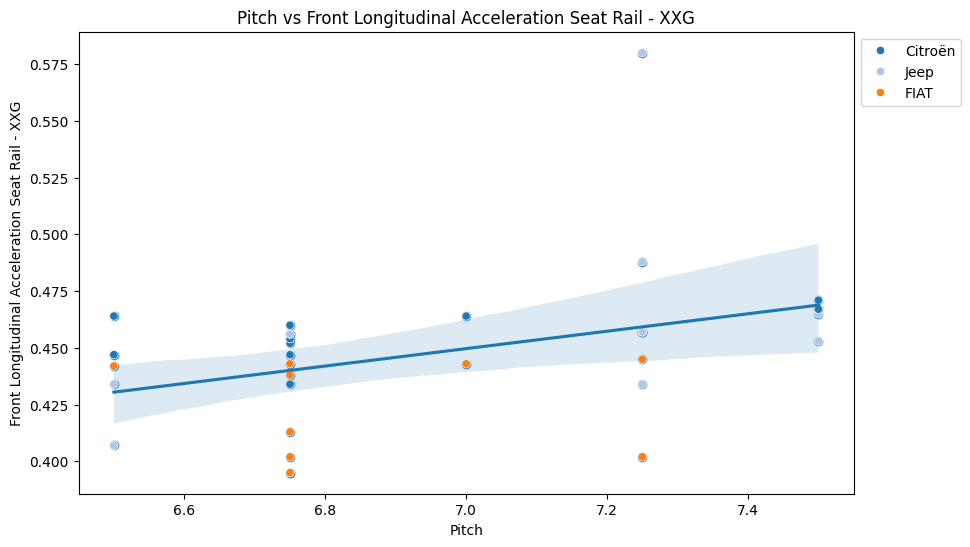

In [61]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["c"])
sns.scatterplot(data=train_df, x="aj", y="c", hue='Brand', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("Front Longitudinal Acceleration Seat Rail - XXG")
plt.title("Pitch vs Front Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

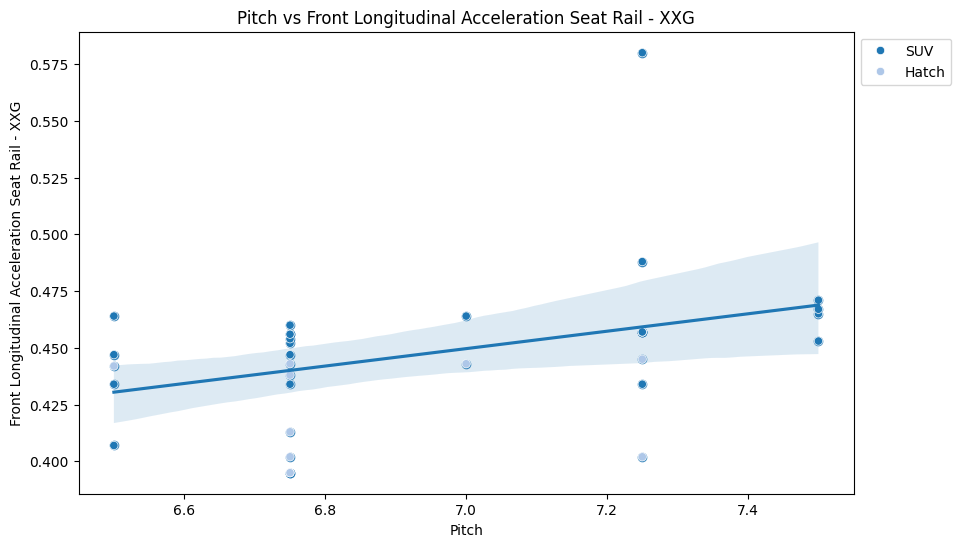

In [62]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["c"])
sns.scatterplot(data=train_df, x="aj", y="c", hue='Category', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("Front Longitudinal Acceleration Seat Rail - XXG")
plt.title("Pitch vs Front Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

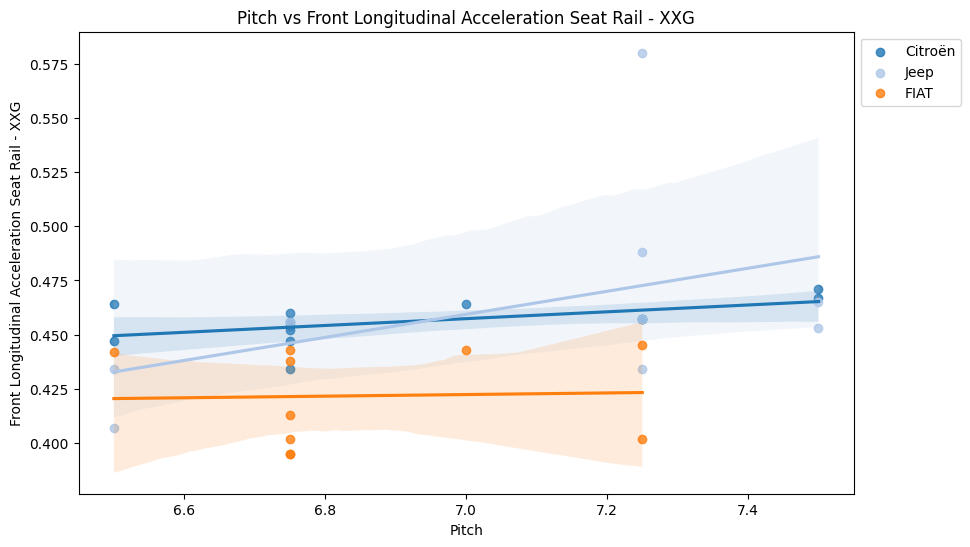

In [63]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="aj", y="c", color=color, label=brand)

plt.xlabel("Pitch")
plt.ylabel("Front Longitudinal Acceleration Seat Rail - XXG")
plt.title("Pitch vs Front Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

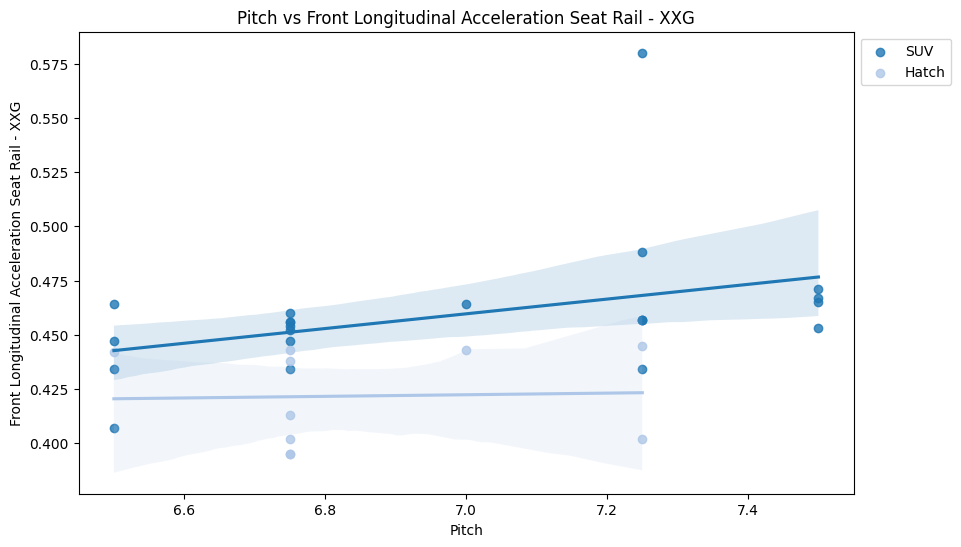

In [64]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="aj", y="c", color=color, label=category)

plt.xlabel("Pitch")
plt.ylabel("Front Longitudinal Acceleration Seat Rail - XXG")
plt.title("Pitch vs Front Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs Rear Longitudinal Acceleration Seat Rail - XXG

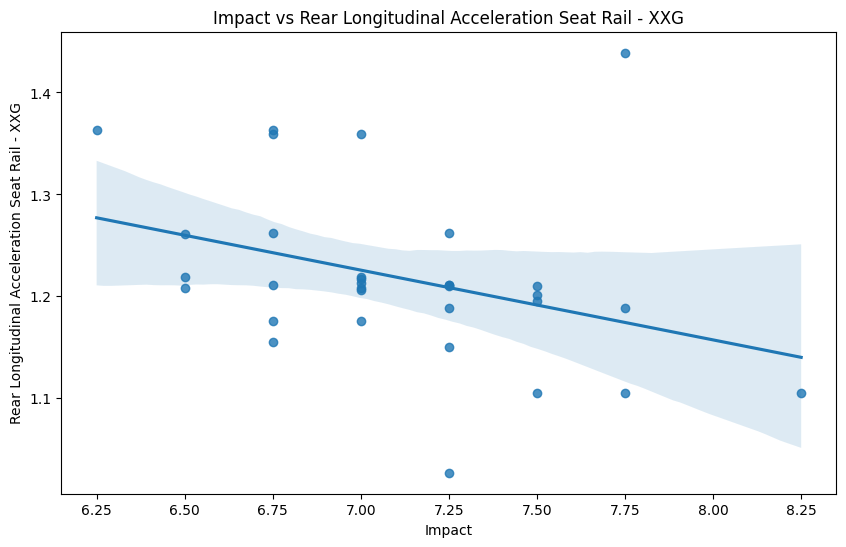

In [65]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["e"])
plt.xlabel("Impact")
plt.ylabel("Rear Longitudinal Acceleration Seat Rail - XXG")
plt.title("Impact vs Rear Longitudinal Acceleration Seat Rail - XXG")
plt.show()

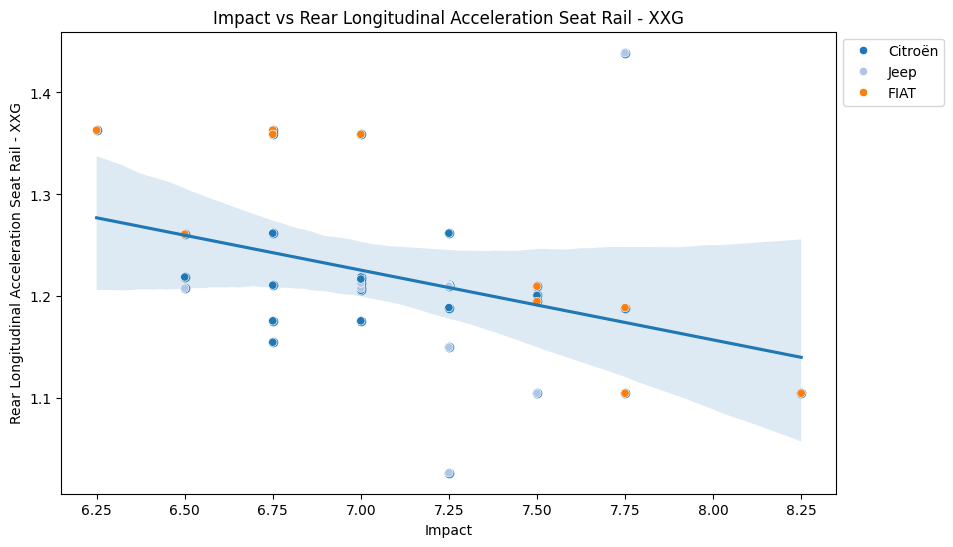

In [66]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["e"])
sns.scatterplot(data=train_df, x="ai", y="e", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Rear Longitudinal Acceleration Seat Rail - XXG")
plt.title("Impact vs Rear Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

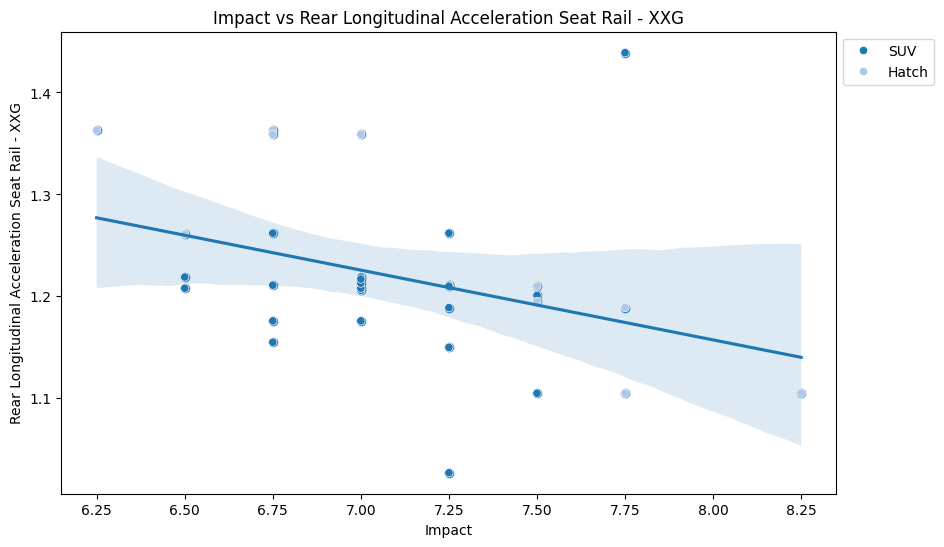

In [67]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["e"])
sns.scatterplot(data=train_df, x="ai", y="e", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Rear Longitudinal Acceleration Seat Rail - XXG")
plt.title("Impact vs Rear Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

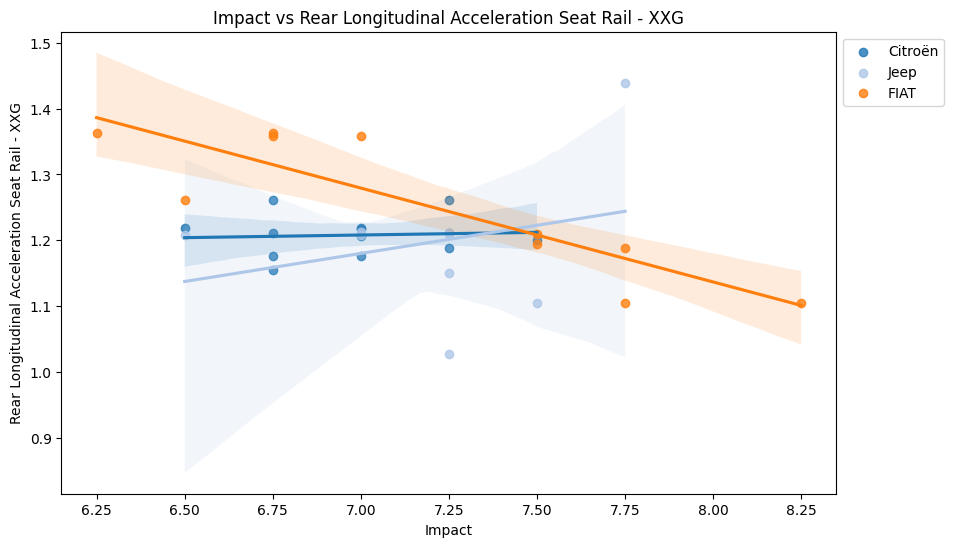

In [68]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="e", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("Rear Longitudinal Acceleration Seat Rail - XXG")
plt.title("Impact vs Rear Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

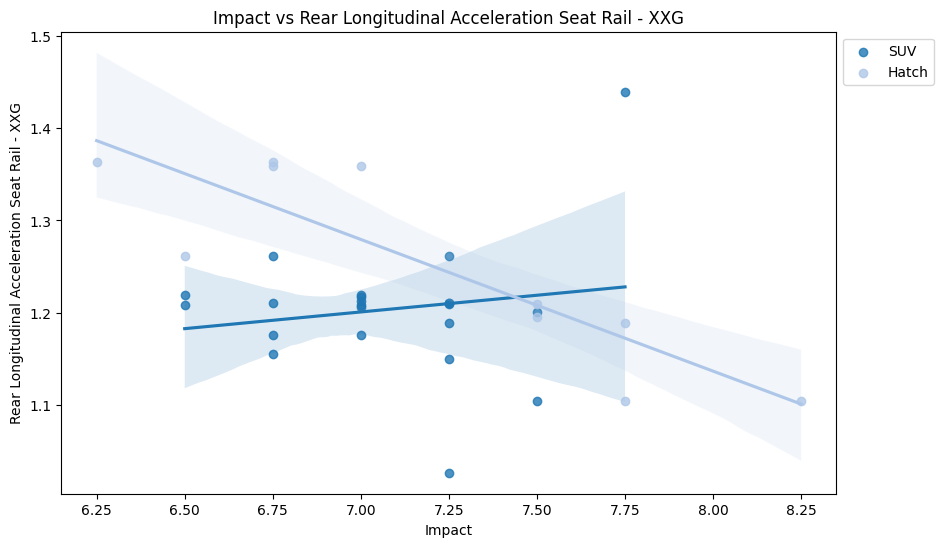

In [69]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="e", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("Rear Longitudinal Acceleration Seat Rail - XXG")
plt.title("Impact vs Rear Longitudinal Acceleration Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Smoothness (3 to 8 Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG​​

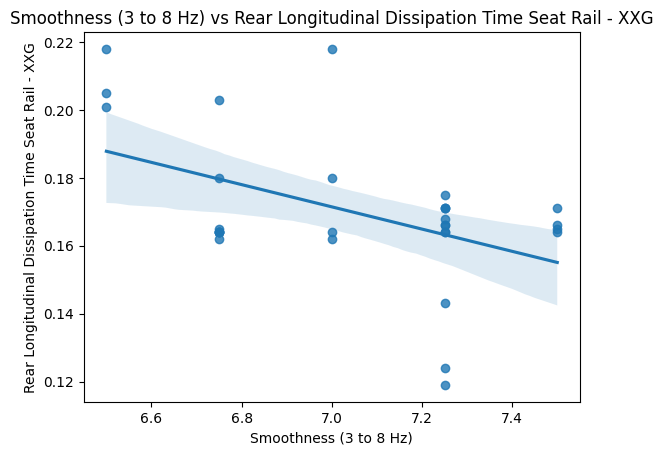

In [70]:
sns.regplot(x=train_df["af"], y=train_df["f"])
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Smoothness (3 to 8 Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

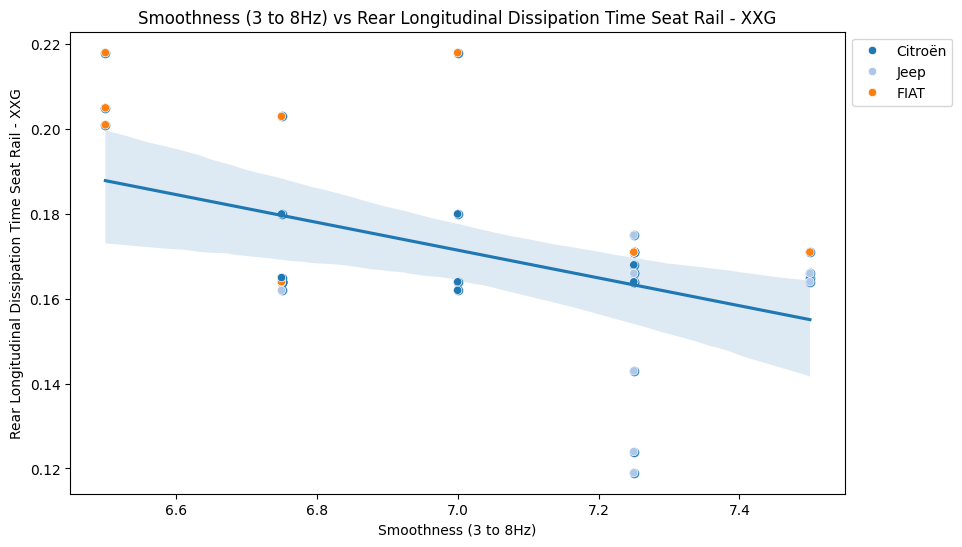

In [71]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["f"])
sns.scatterplot(data=train_df, x="af", y="f", hue='Brand', palette='tab20')
plt.xlabel("Smoothness (3 to 8Hz)")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Smoothness (3 to 8Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

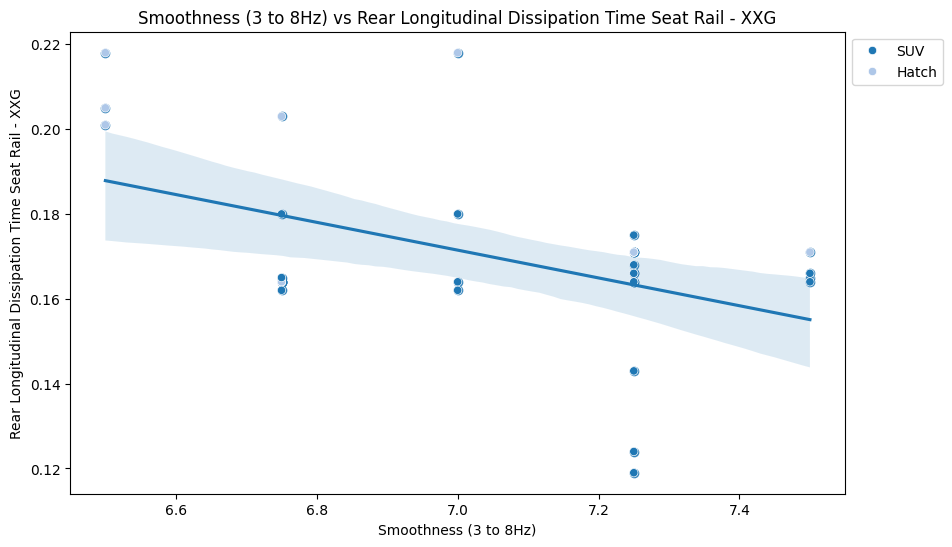

In [72]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["f"])
sns.scatterplot(data=train_df, x="af", y="f", hue='Category', palette='tab20')
plt.xlabel("Smoothness (3 to 8Hz)")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Smoothness (3 to 8Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

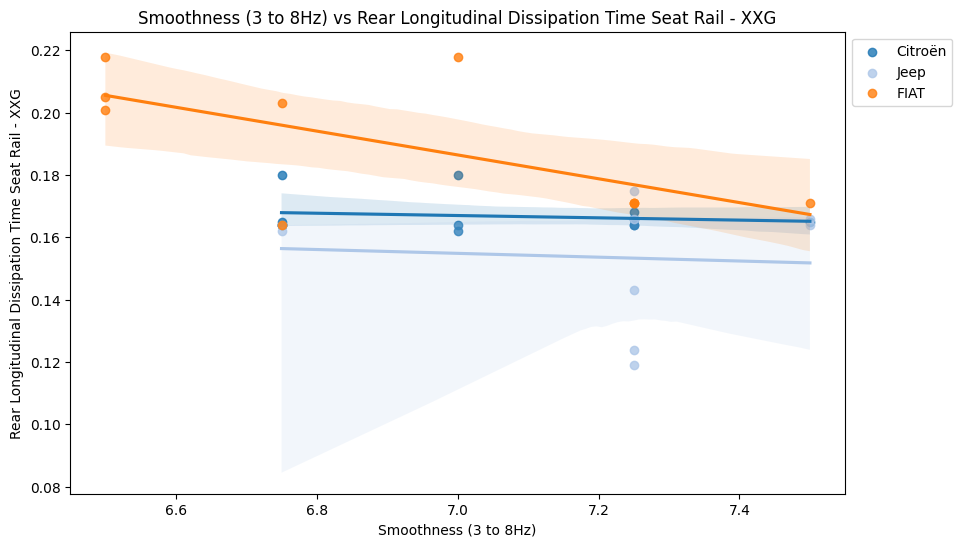

In [73]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="af", y="f", color=color, label=brand)

plt.xlabel("Smoothness (3 to 8Hz)")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Smoothness (3 to 8Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

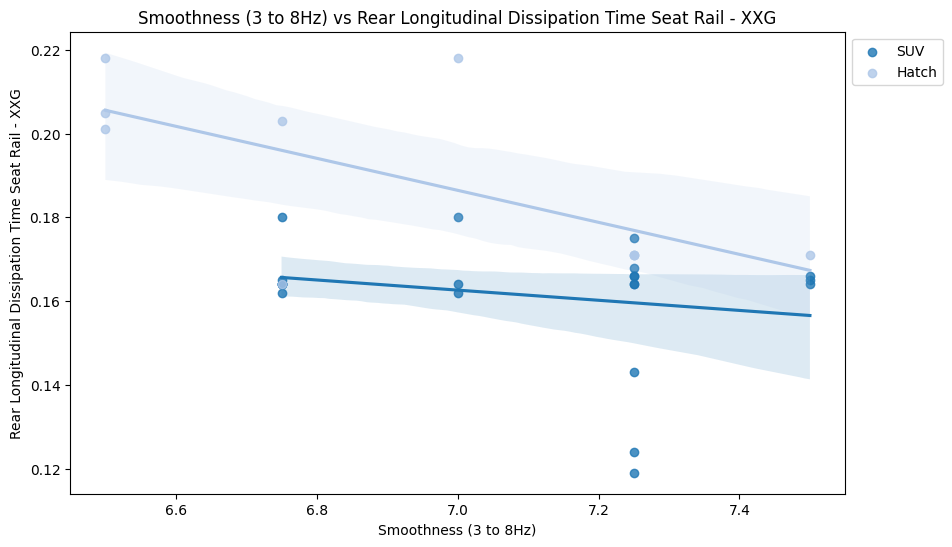

In [74]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="af", y="f", color=color, label=category)

plt.xlabel("Smoothness (3 to 8Hz)")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Smoothness (3 to 8Hz) vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG​​

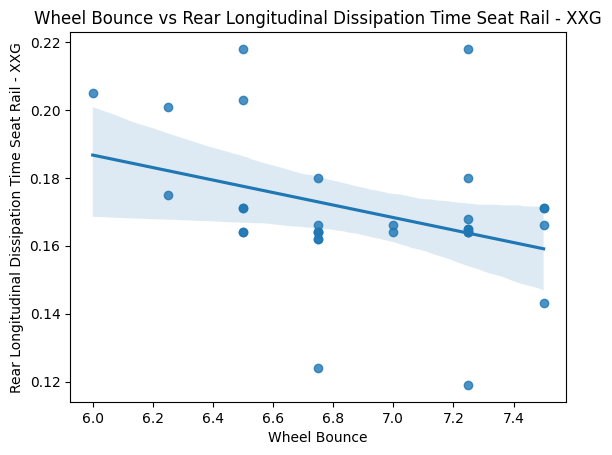

In [75]:
sns.regplot(x=train_df["ag"], y=train_df["f"])
plt.xlabel("Wheel Bounce")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

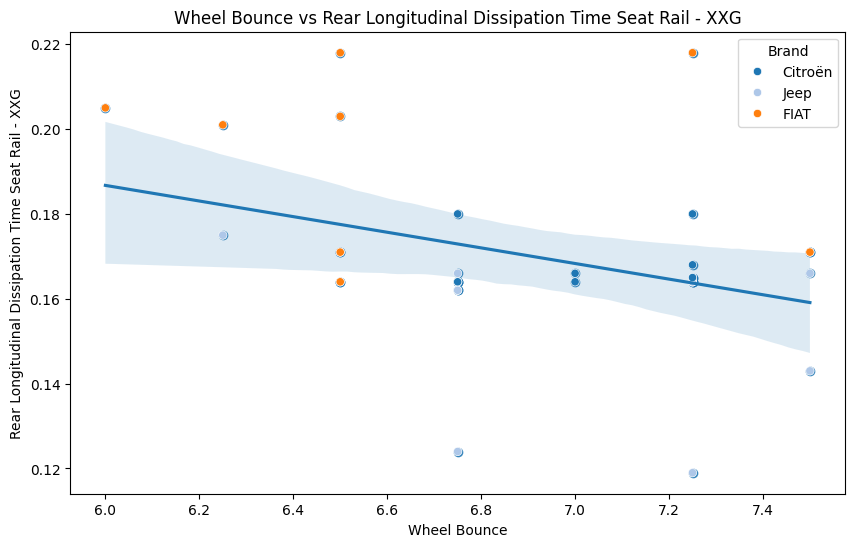

In [76]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ag"], y=train_df["f"])
sns.scatterplot(data=train_df, x="ag", y="f", hue='Brand', palette='tab20')
plt.xlabel("Wheel Bounce")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

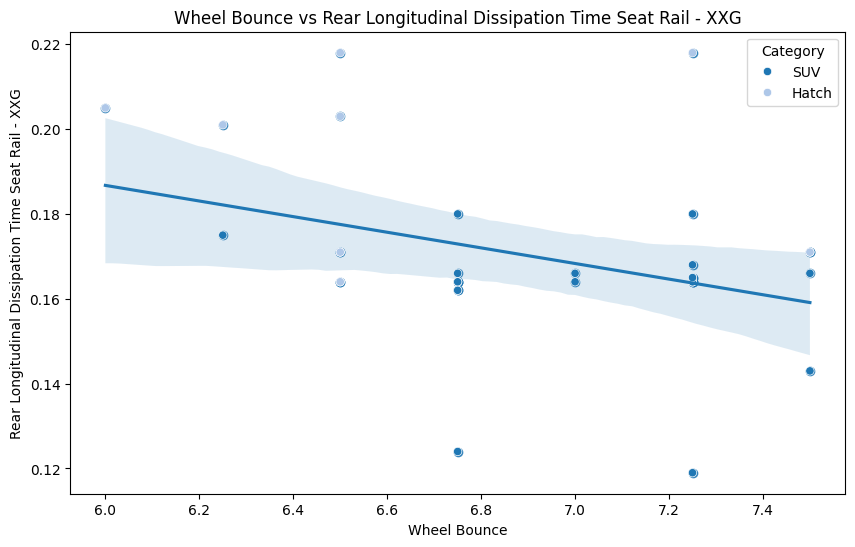

In [77]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ag"], y=train_df["f"])
sns.scatterplot(data=train_df, x="ag", y="f", hue='Category', palette='tab20')
plt.xlabel("Wheel Bounce")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

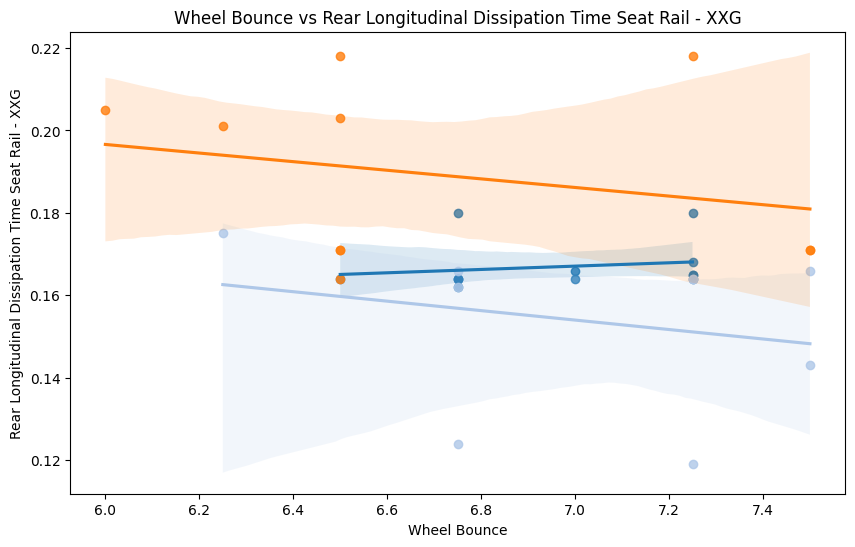

In [78]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ag", y="f", color=color, label=brand)

plt.xlabel("Wheel Bounce")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

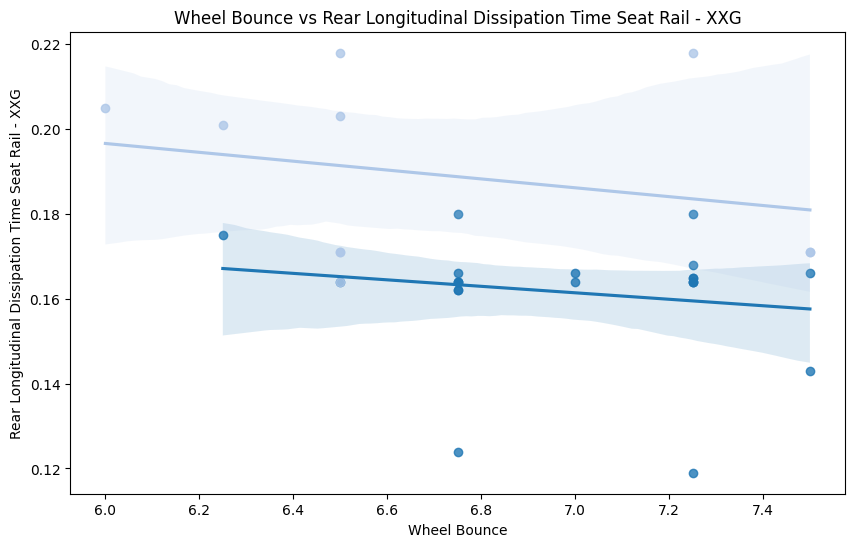

In [79]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ag", y="f", color=color, label=category)

plt.xlabel("Wheel Bounce")
plt.ylabel("Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.title("Wheel Bounce vs Rear Longitudinal Dissipation Time Seat Rail - XXG")
plt.show()

###Pitch vs Ratio Front / Rear Acc Seat Rail - XXG​​

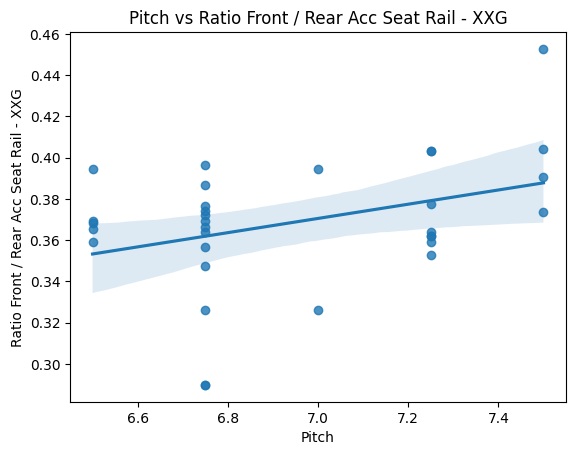

In [80]:
sns.regplot(x=train_df["aj"], y=train_df["g"])
plt.xlabel("Pitch")
plt.ylabel("Ratio Front / Rear Acc Seat Rail - XXG")
plt.title("Pitch vs Ratio Front / Rear Acc Seat Rail - XXG")
plt.show()

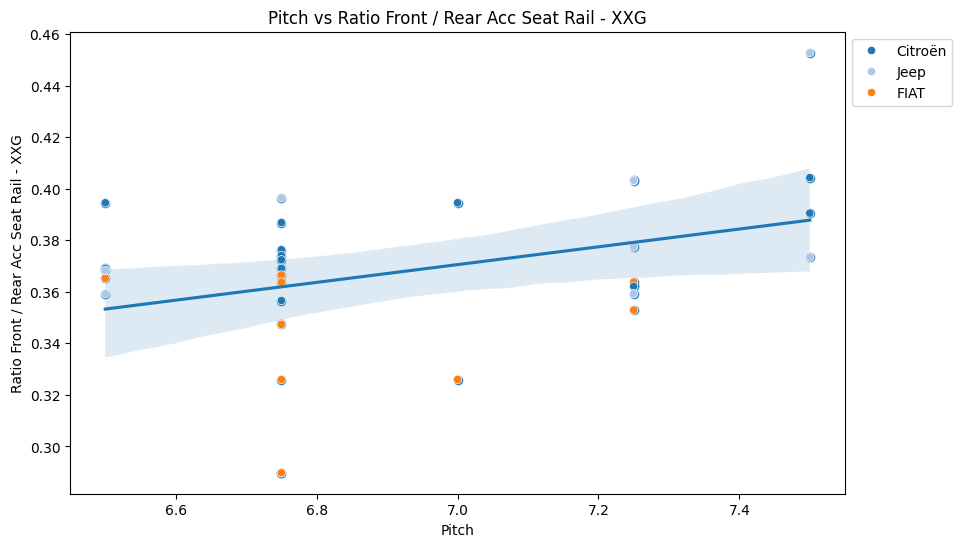

In [81]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["g"])
sns.scatterplot(data=train_df, x="aj", y="g", hue='Brand', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("Ratio Front / Rear Acc Seat Rail - XXG")
plt.title("Pitch vs Ratio Front / Rear Acc Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

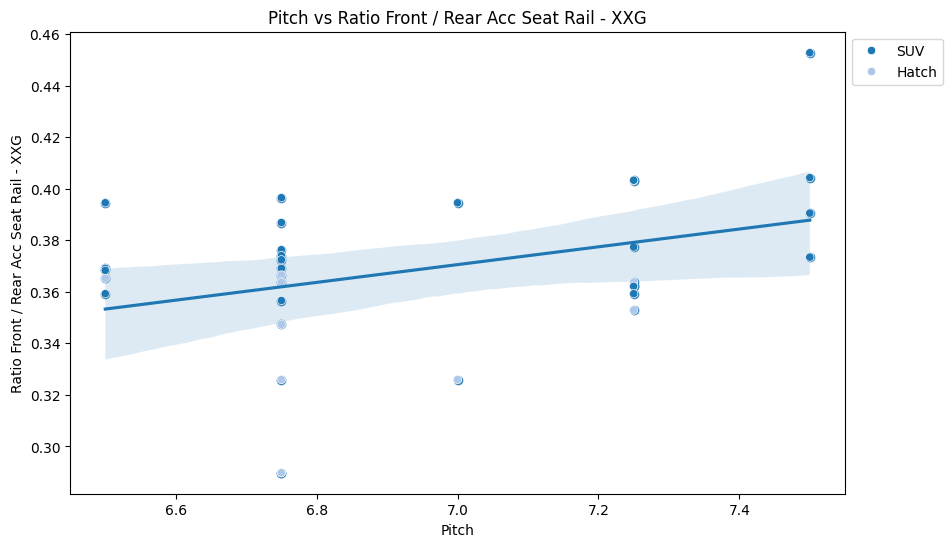

In [82]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["g"])
sns.scatterplot(data=train_df, x="aj", y="g", hue='Category', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("Ratio Front / Rear Acc Seat Rail - XXG")
plt.title("Pitch vs Ratio Front / Rear Acc Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

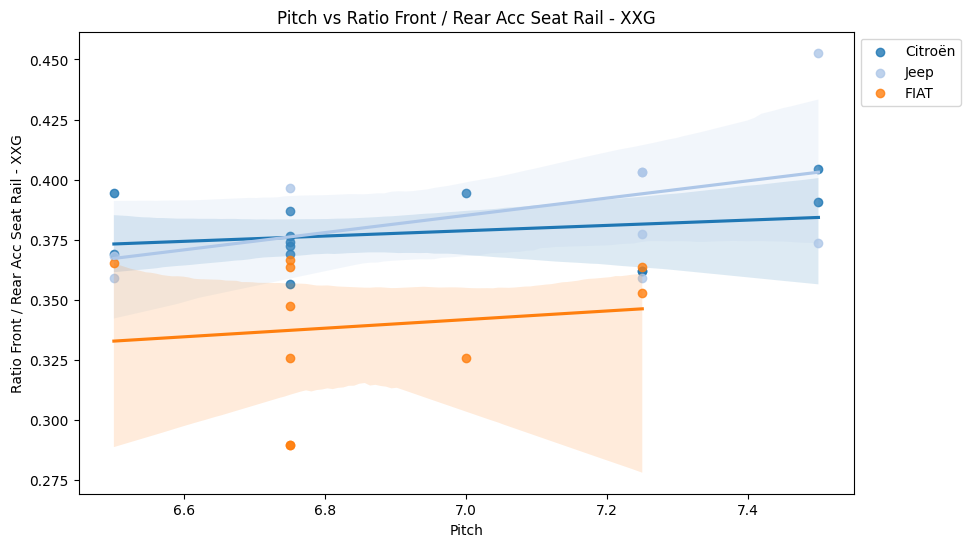

In [83]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="aj", y="g", color=color, label=brand)

plt.xlabel("Pitch")
plt.ylabel("Ratio Front / Rear Acc Seat Rail - XXG")
plt.title("Pitch vs Ratio Front / Rear Acc Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

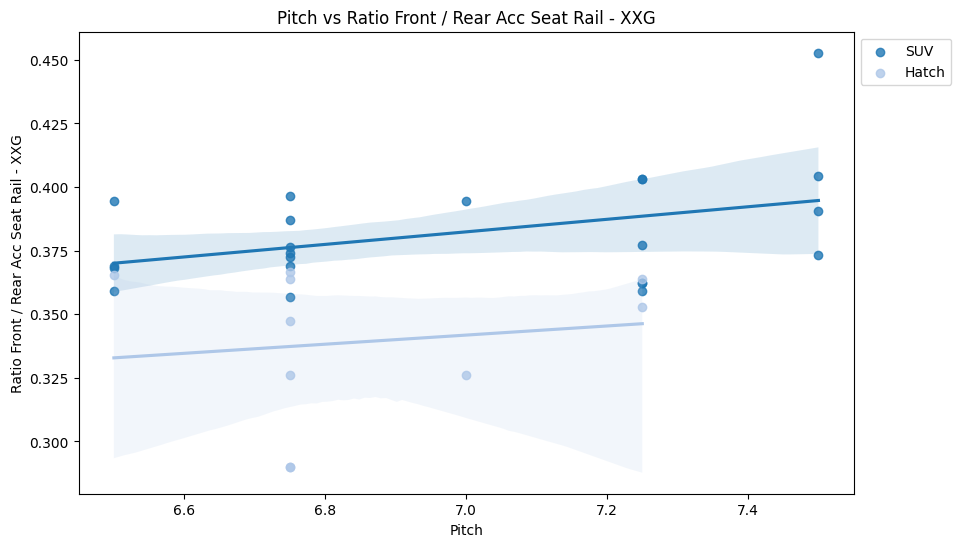

In [84]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="aj", y="g", color=color, label=category)

plt.xlabel("Pitch")
plt.ylabel("Ratio Front / Rear Acc Seat Rail - XXG")
plt.title("Pitch vs Ratio Front / Rear Acc Seat Rail - XXG")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​

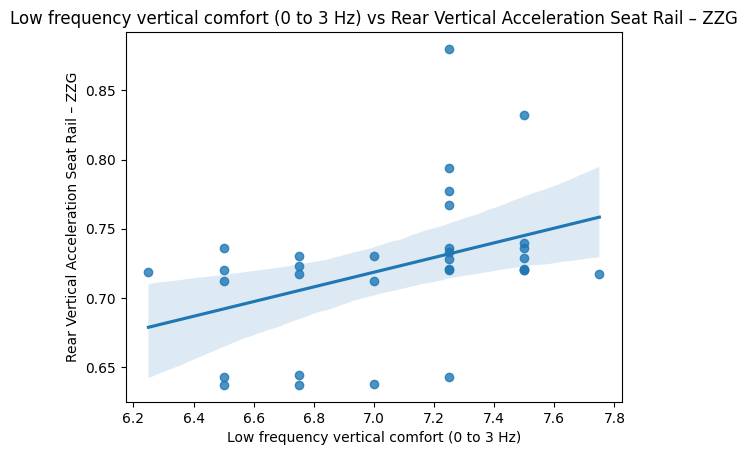

In [85]:
sns.regplot(x=train_df["ae"], y=train_df["k"])
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.show()

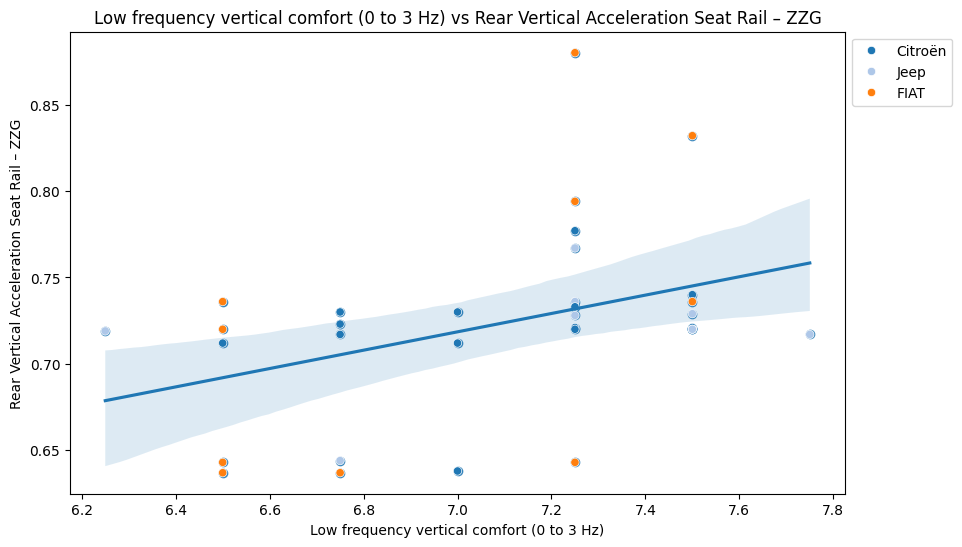

In [86]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["k"])
sns.scatterplot(data=train_df, x="ae", y="k", hue='Brand', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

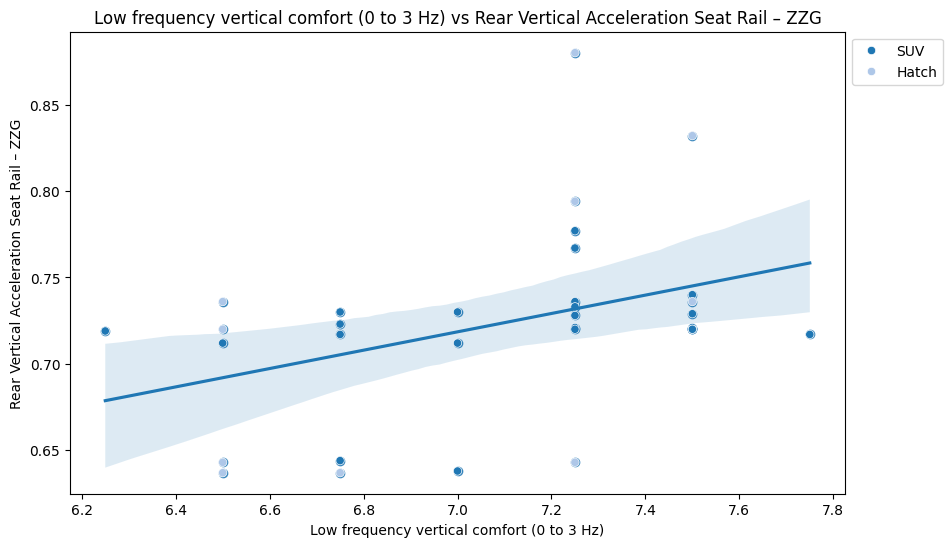

In [87]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["k"])
sns.scatterplot(data=train_df, x="ae", y="k", hue='Category', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

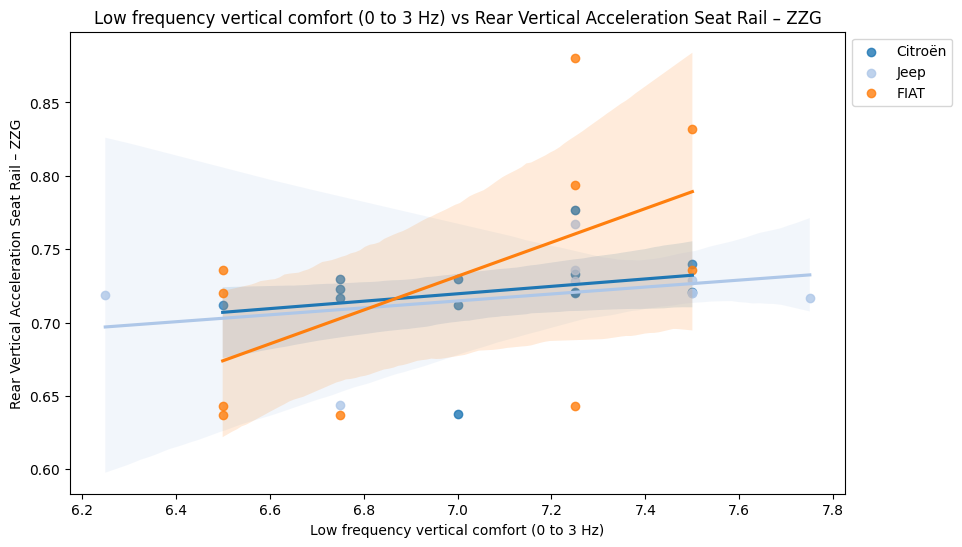

In [88]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ae", y="k", color=color, label=brand)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

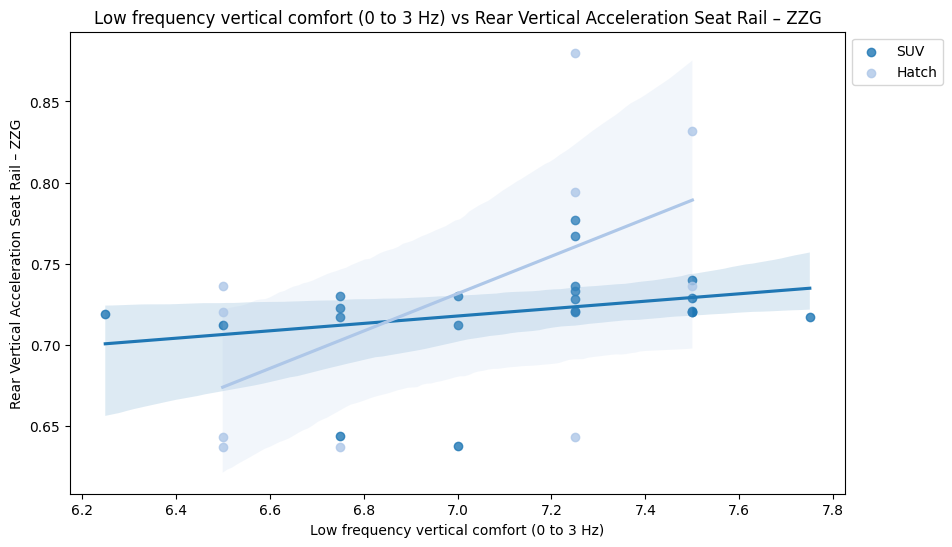

In [89]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ae", y="k", color=color, label=category)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​

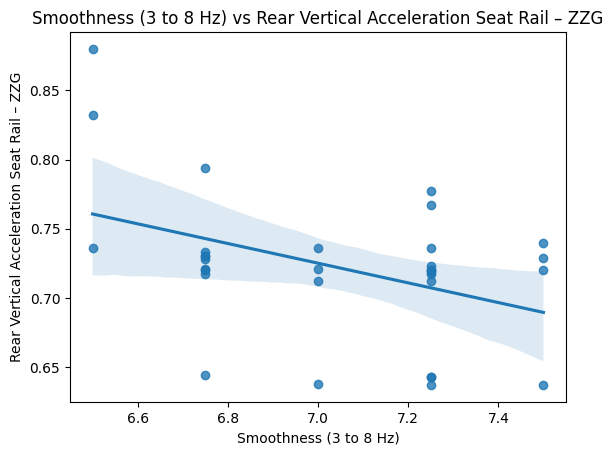

In [90]:
sns.regplot(x=train_df["af"], y=train_df["k"])
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.show()

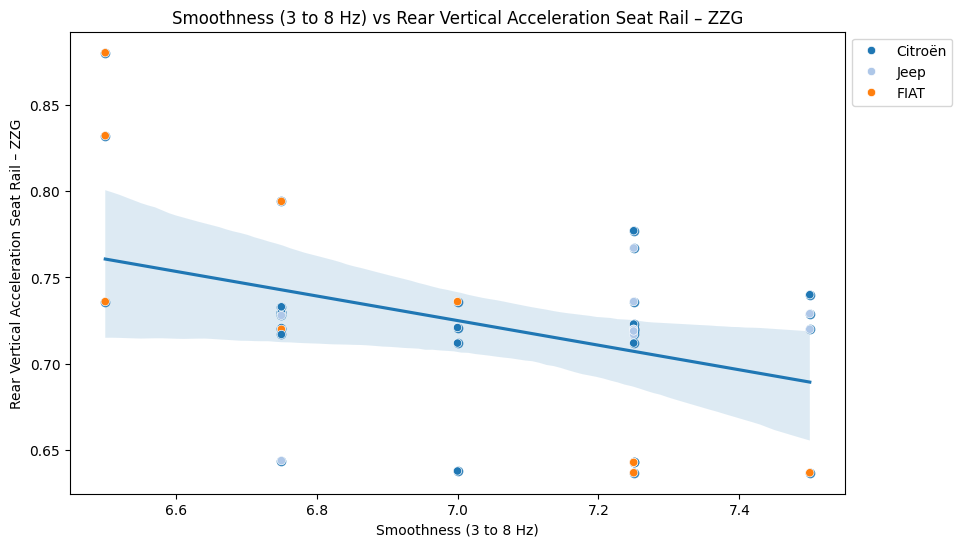

In [91]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["k"])
sns.scatterplot(data=train_df, x="af", y="k", hue='Brand', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

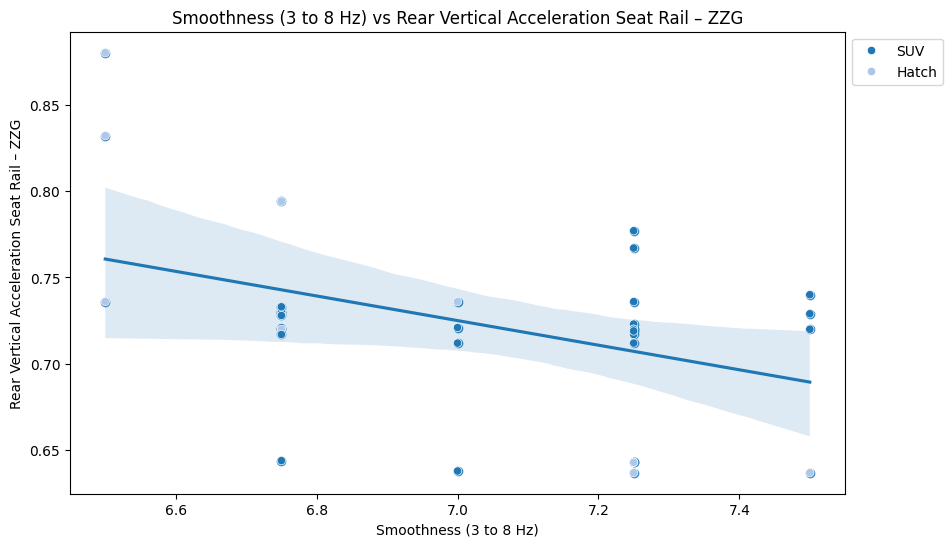

In [92]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["k"])
sns.scatterplot(data=train_df, x="af", y="k", hue='Category', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

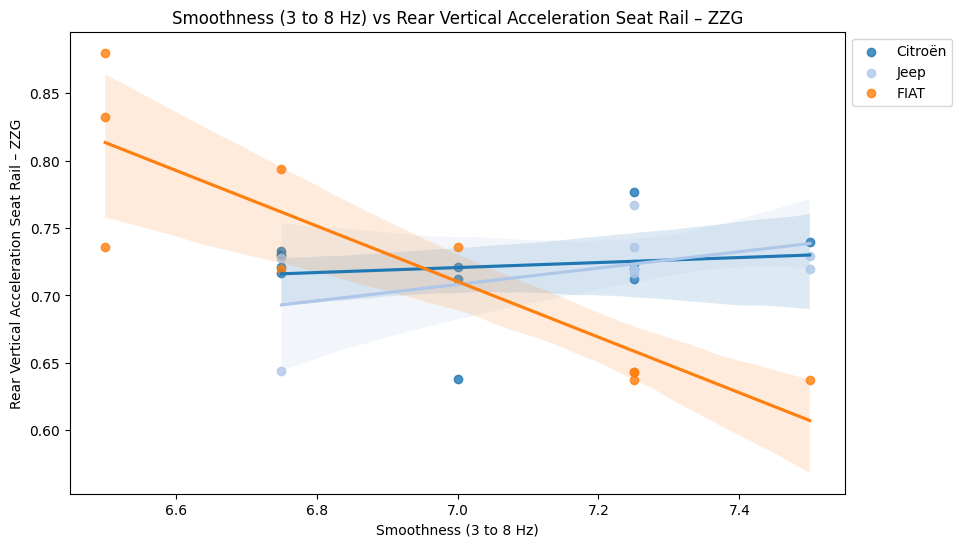

In [93]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="af", y="k", color=color, label=brand)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

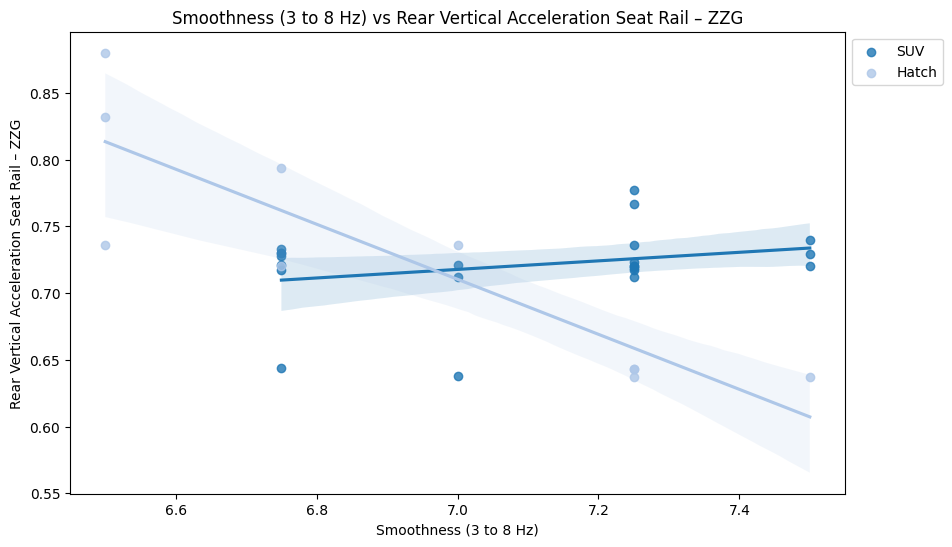

In [94]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="af", y="k", color=color, label=category)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("Rear Vertical Acceleration Seat Rail – ZZG​")
plt.title("Smoothness (3 to 8 Hz) vs Rear Vertical Acceleration Seat Rail – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​

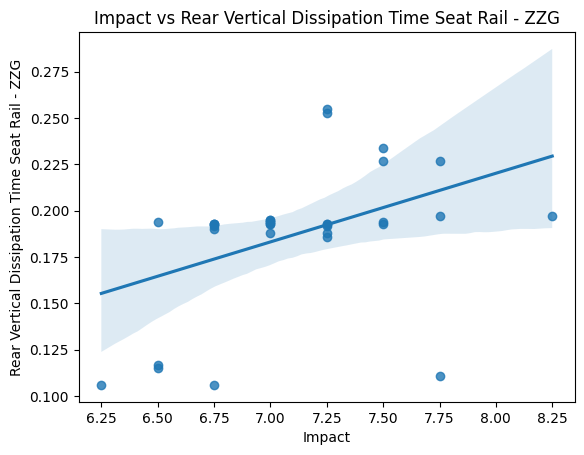

In [95]:
sns.regplot(x=train_df["ai"], y=train_df["l"])
plt.xlabel("Impact")
plt.ylabel("Rear Vertical Dissipation Time Seat Rail - ZZG​")
plt.title("Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​")
plt.show()

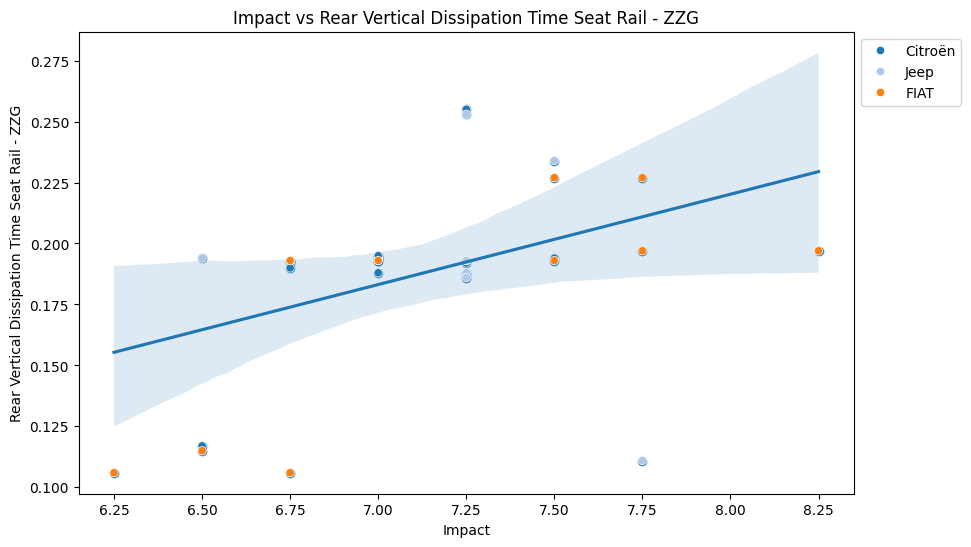

In [96]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["l"])
sns.scatterplot(data=train_df, x="ai", y="l", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Rear Vertical Dissipation Time Seat Rail - ZZG​")
plt.title("Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

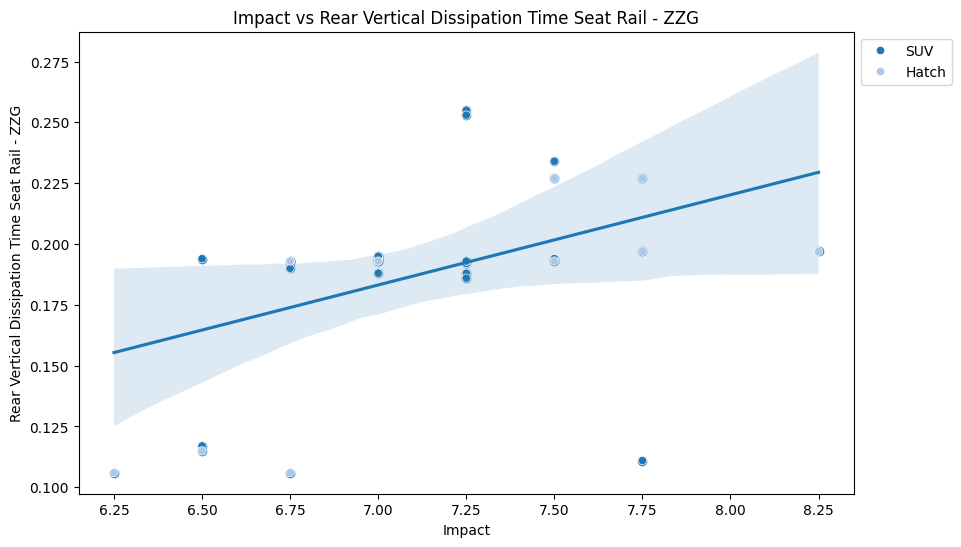

In [97]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["l"])
sns.scatterplot(data=train_df, x="ai", y="l", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Rear Vertical Dissipation Time Seat Rail - ZZG​")
plt.title("Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

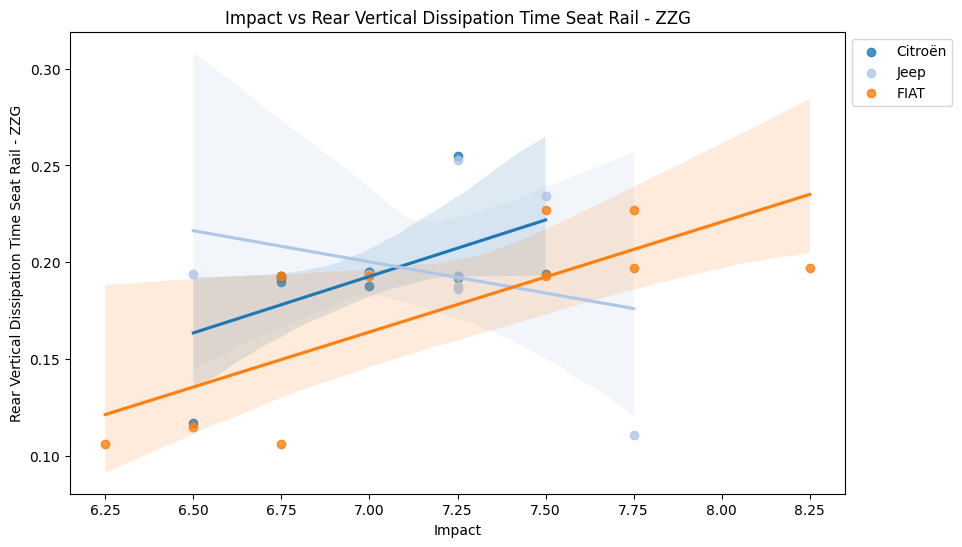

In [98]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="l", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("Rear Vertical Dissipation Time Seat Rail - ZZG​")
plt.title("Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

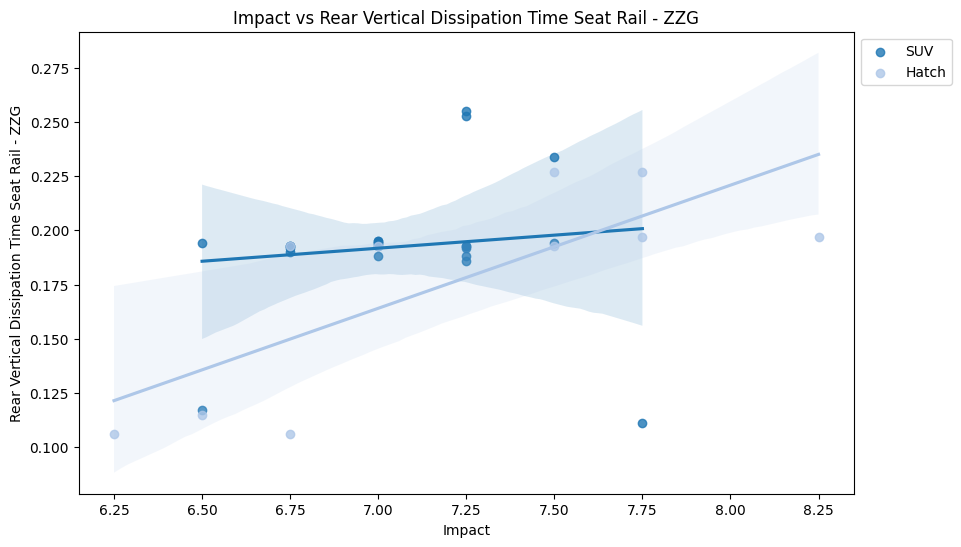

In [99]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="l", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("Rear Vertical Dissipation Time Seat Rail - ZZG​")
plt.title("Impact vs Rear Vertical Dissipation Time Seat Rail - ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG

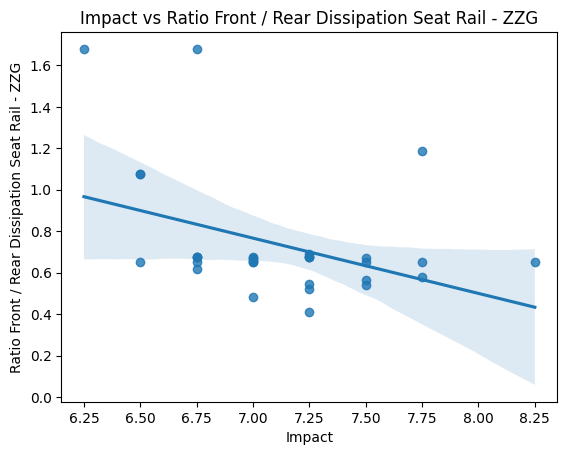

In [100]:
sns.regplot(x=train_df["ai"], y=train_df["n"])
plt.xlabel("Impact")
plt.ylabel("Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.title("Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.show()

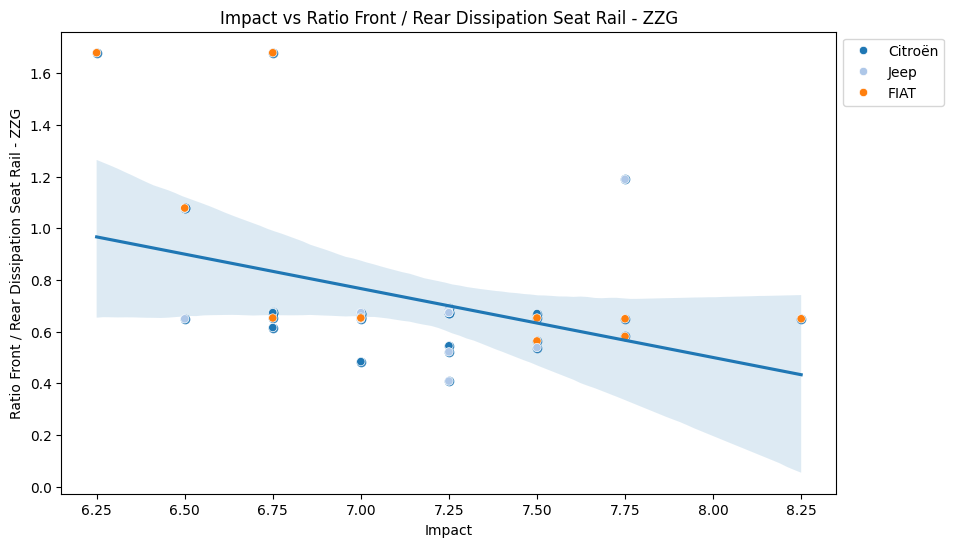

In [101]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["n"])
sns.scatterplot(data=train_df, x="ai", y="n", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.title("Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

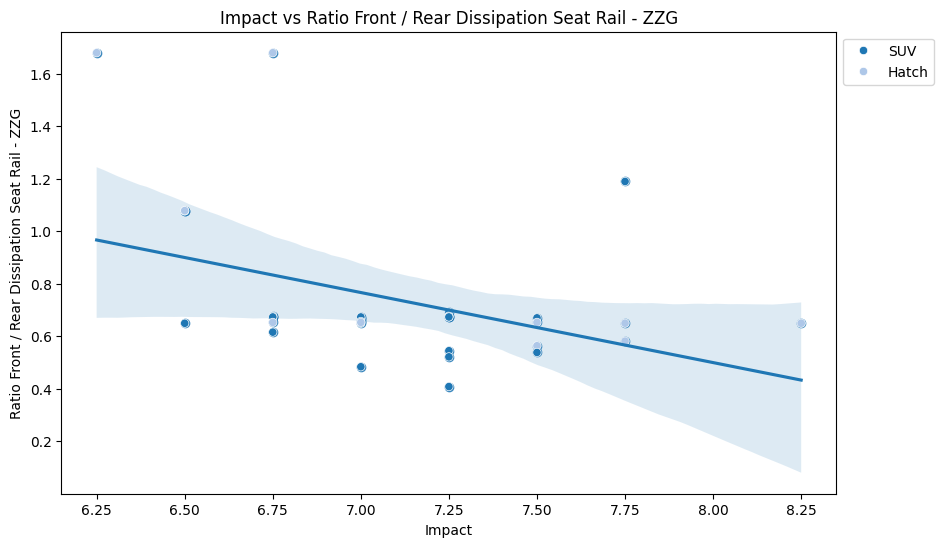

In [102]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["n"])
sns.scatterplot(data=train_df, x="ai", y="n", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.title("Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

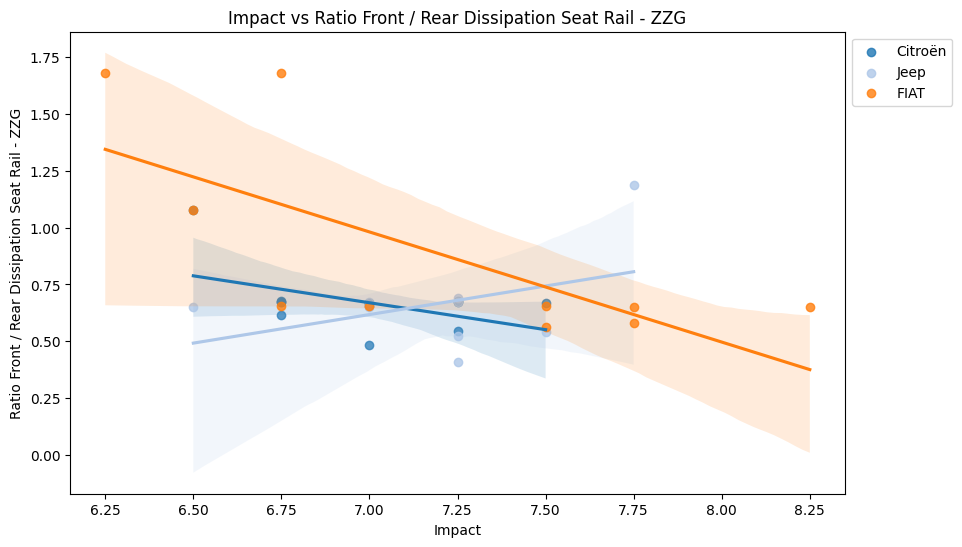

In [103]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="n", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.title("Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

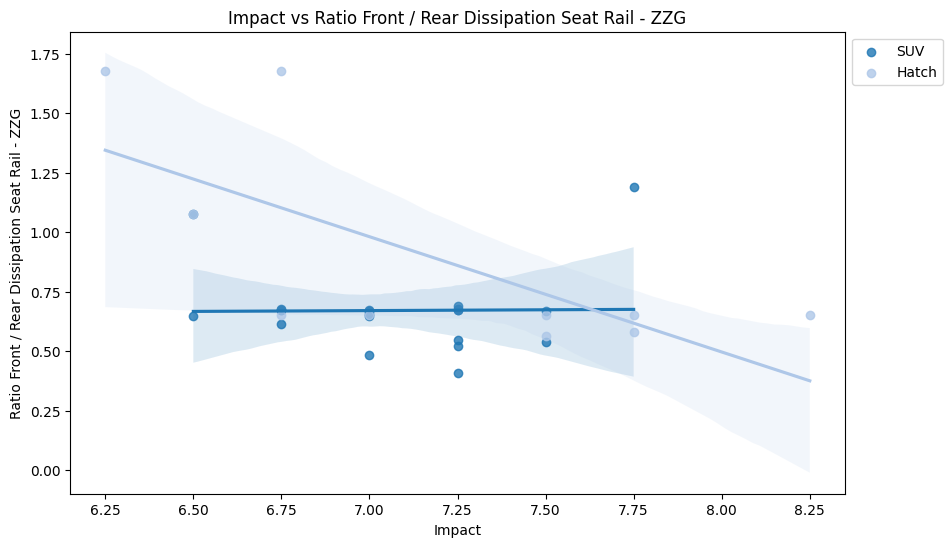

In [104]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="n", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.title("Impact vs Ratio Front / Rear Dissipation Seat Rail - ZZG​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)

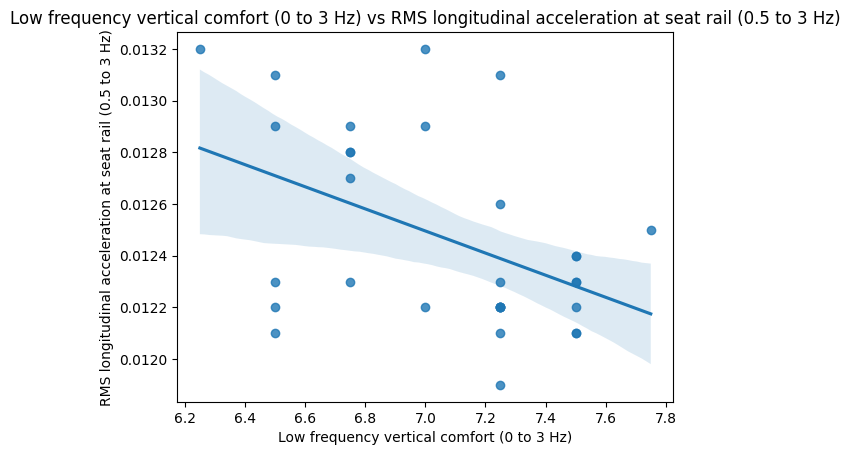

In [105]:
sns.regplot(x=train_df["ae"], y=train_df["o"])
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.show()

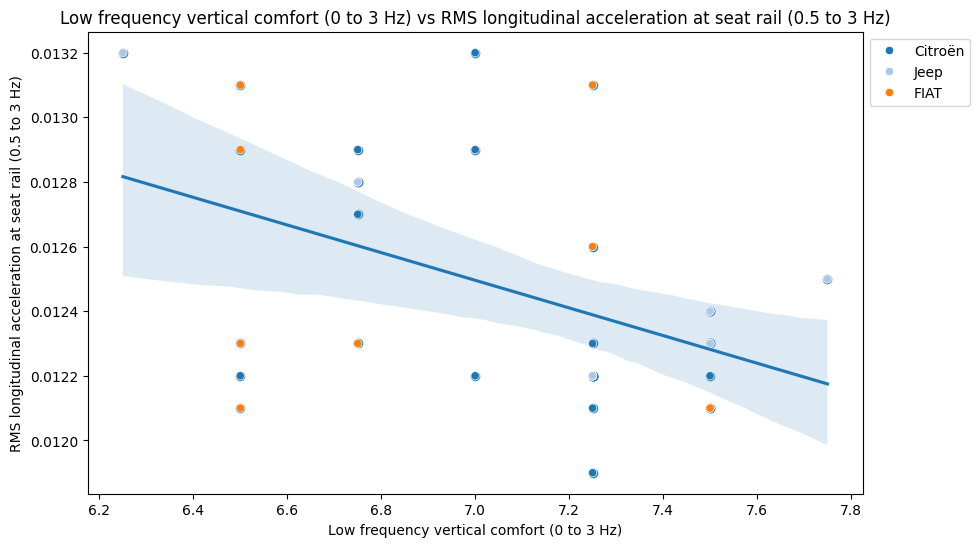

In [106]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["o"])
sns.scatterplot(data=train_df, x="ae", y="o", hue='Brand', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

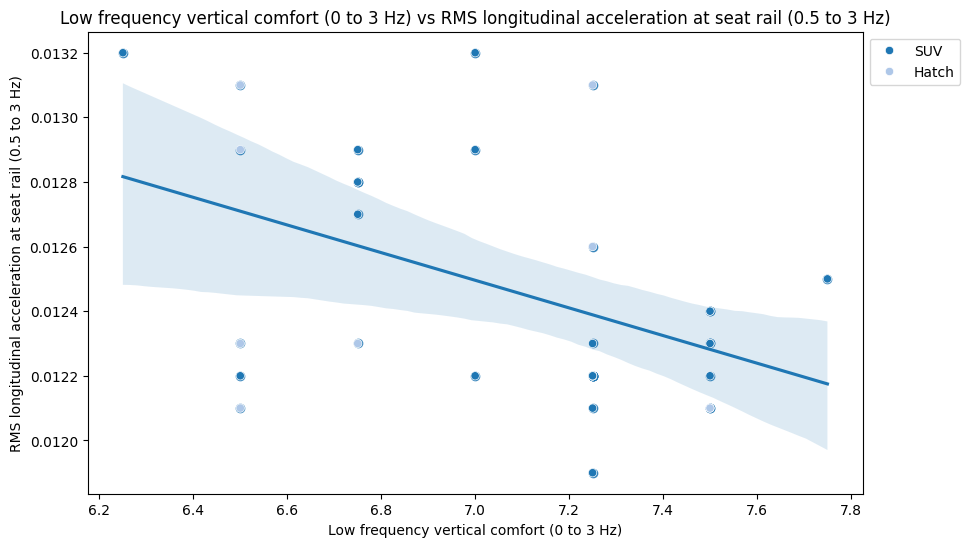

In [107]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["o"])
sns.scatterplot(data=train_df, x="ae", y="o", hue='Category', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

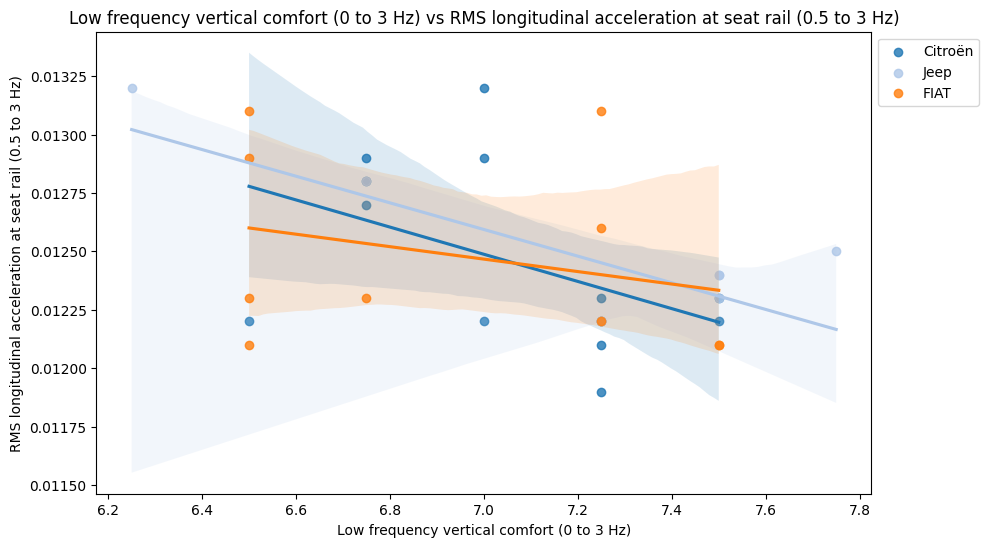

In [108]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ae", y="o", color=color, label=brand)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

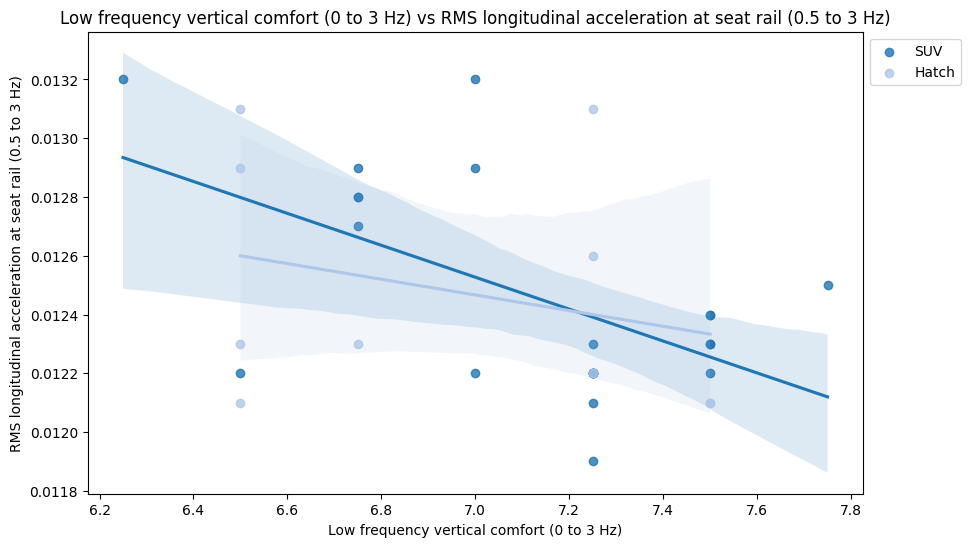

In [109]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ae", y="o", color=color, label=category)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)

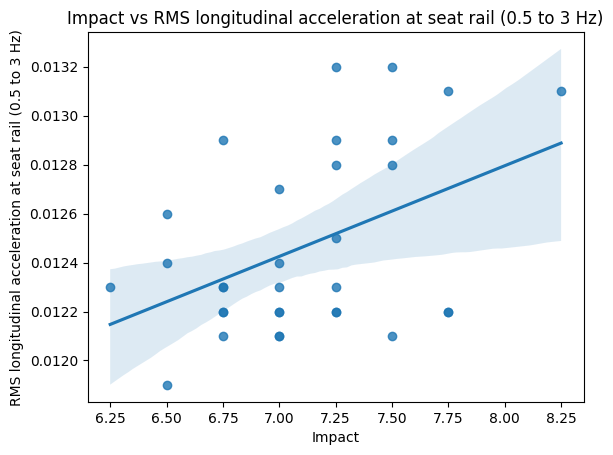

In [110]:
sns.regplot(x=train_df["ai"], y=train_df["o"])
plt.xlabel("Impact")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.show()

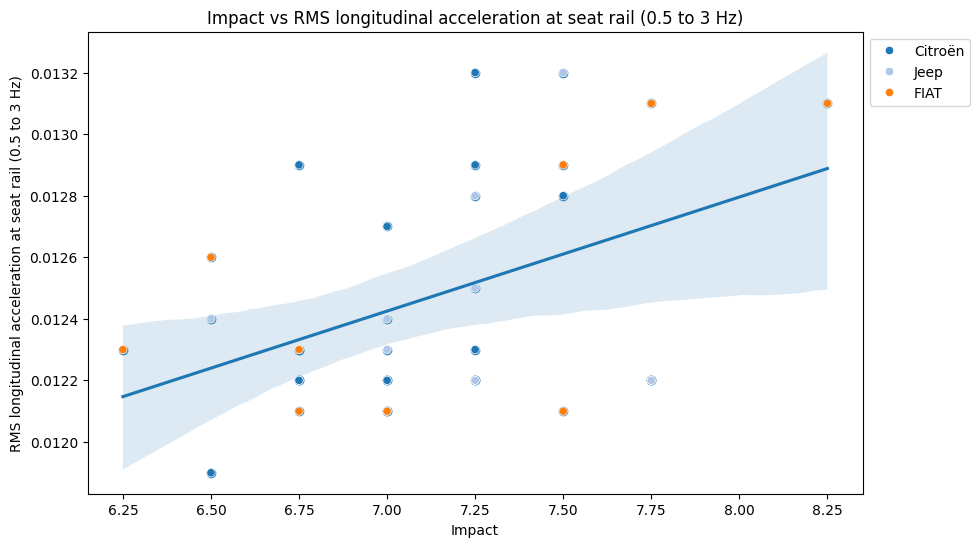

In [111]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["o"])
sns.scatterplot(data=train_df, x="ai", y="o", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

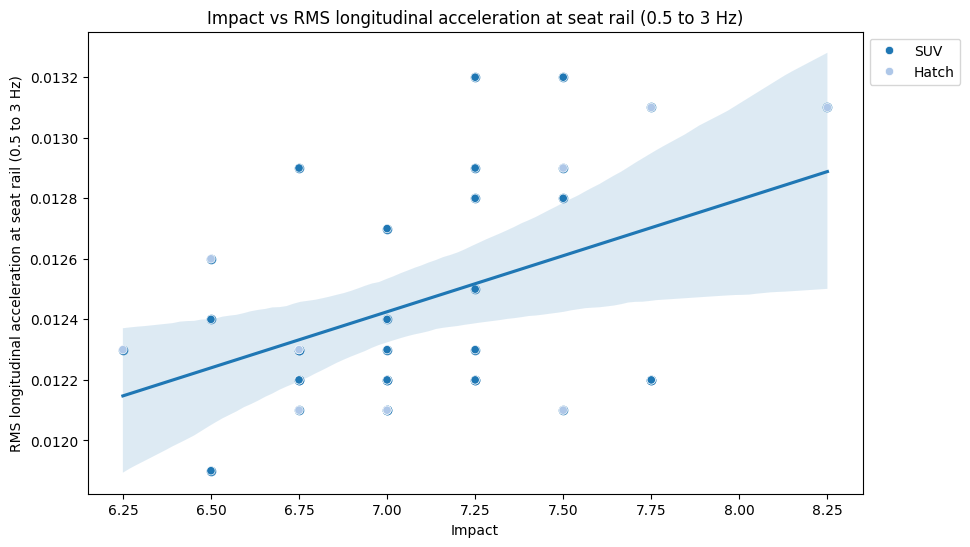

In [112]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["o"])
sns.scatterplot(data=train_df, x="ai", y="o", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

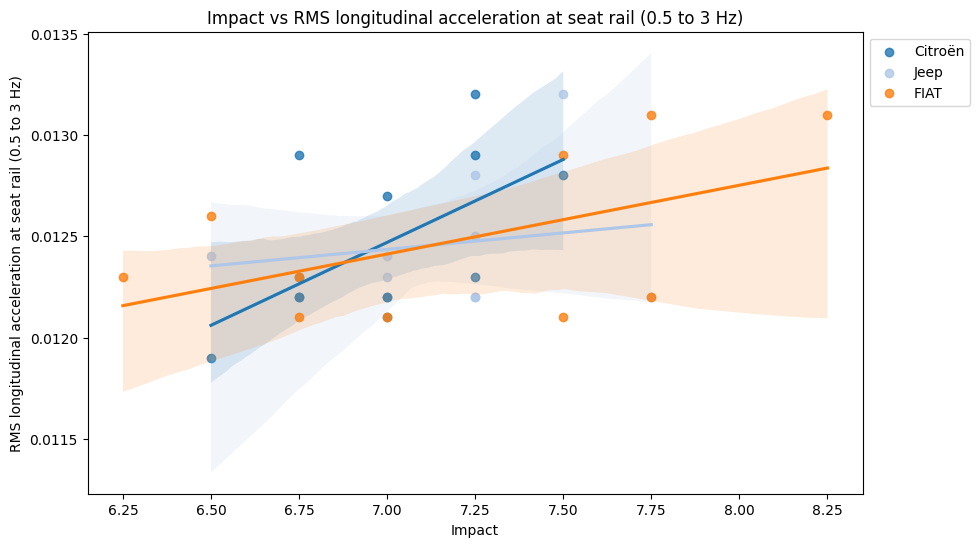

In [113]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="o", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

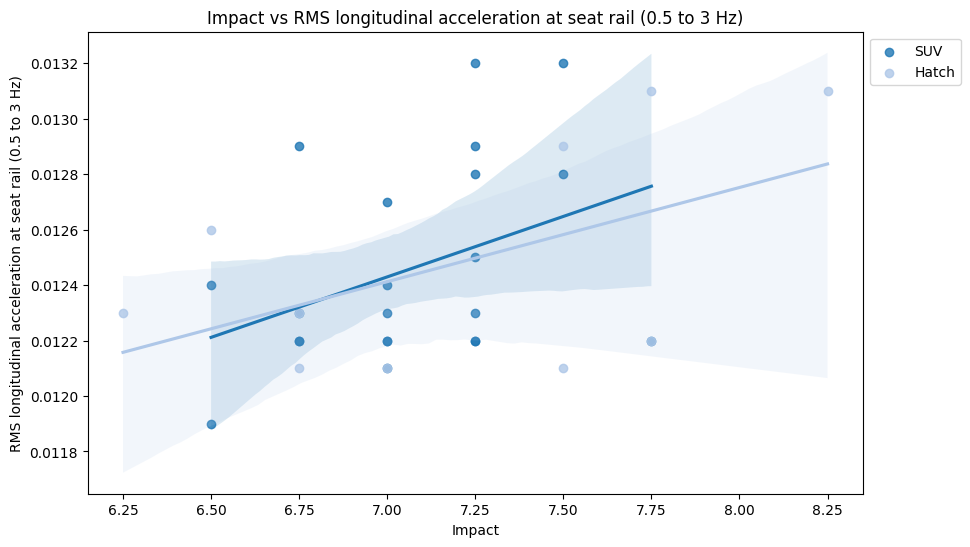

In [114]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="o", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Impact vs RMS longitudinal acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)

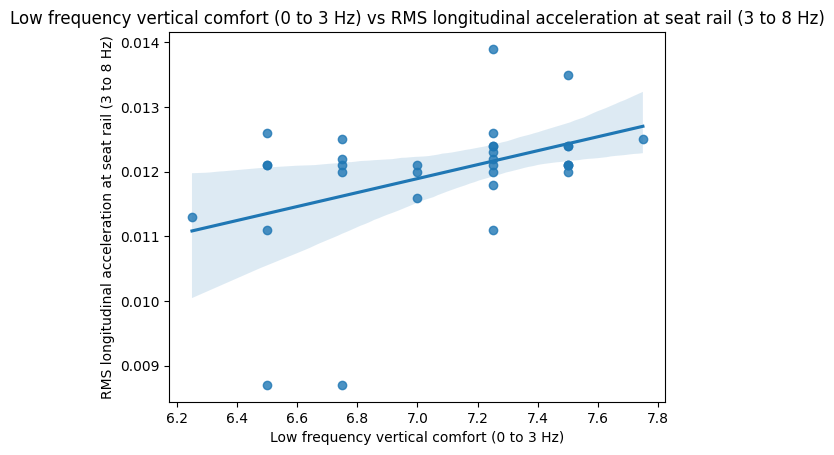

In [115]:
sns.regplot(x=train_df["ae"], y=train_df["p"])
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.show()

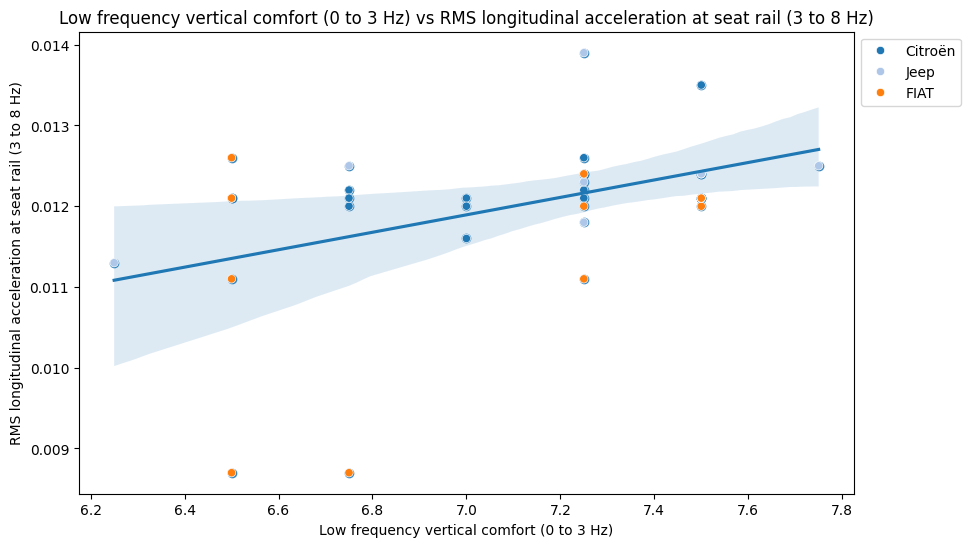

In [116]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["p"])
sns.scatterplot(data=train_df, x="ae", y="p", hue='Brand', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

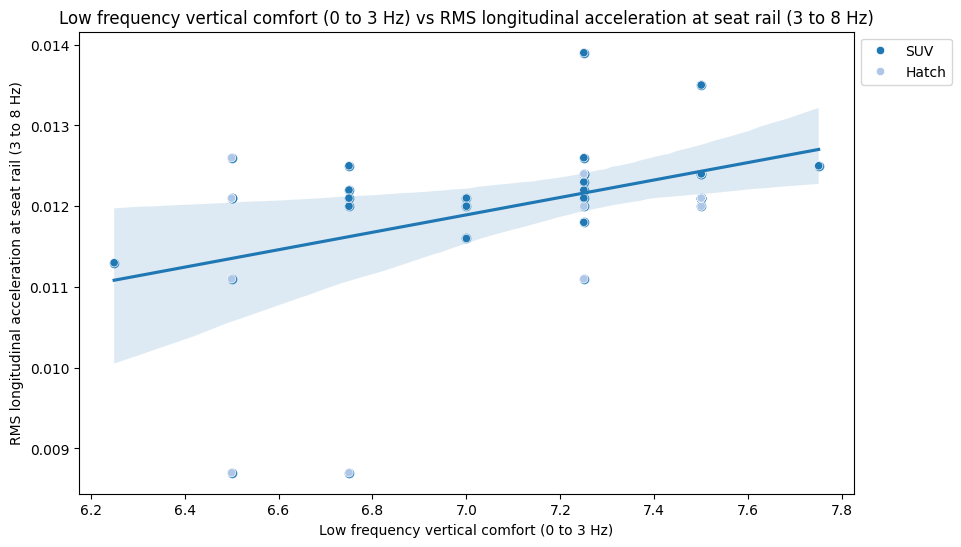

In [117]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["p"])
sns.scatterplot(data=train_df, x="ae", y="p", hue='Category', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

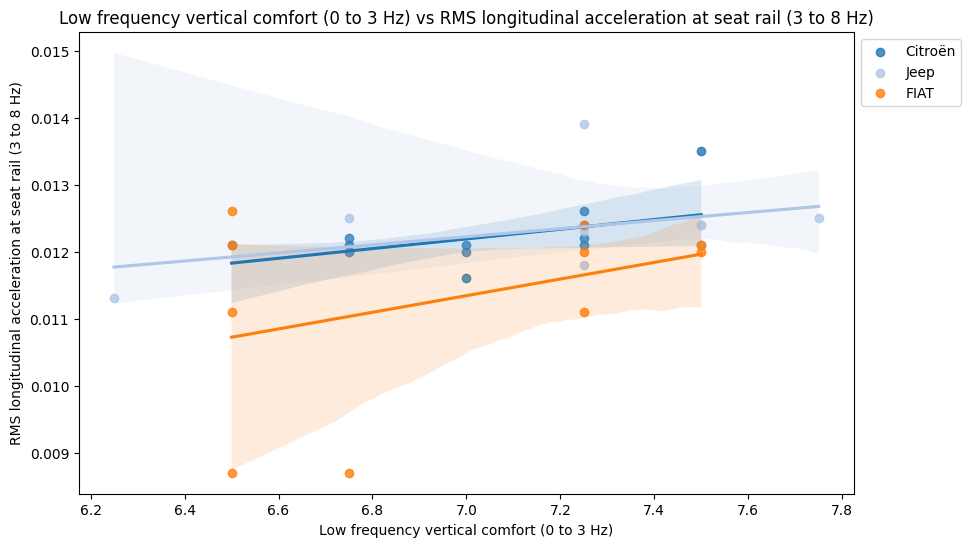

In [118]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ae", y="p", color=color, label=brand)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

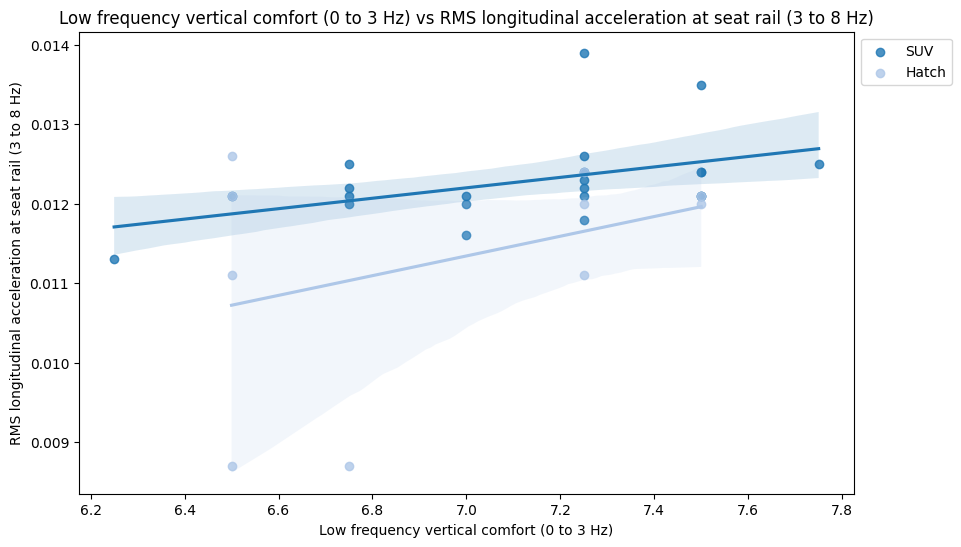

In [119]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ae", y="p", color=color, label=category)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS longitudinal acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)

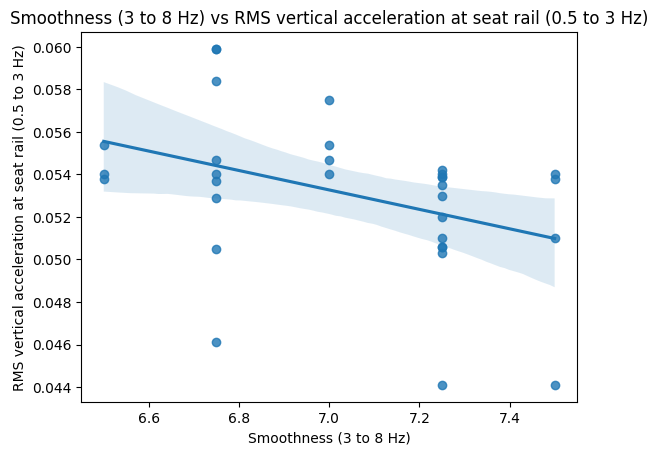

In [120]:
sns.regplot(x=train_df["af"], y=train_df["r"])
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.show()

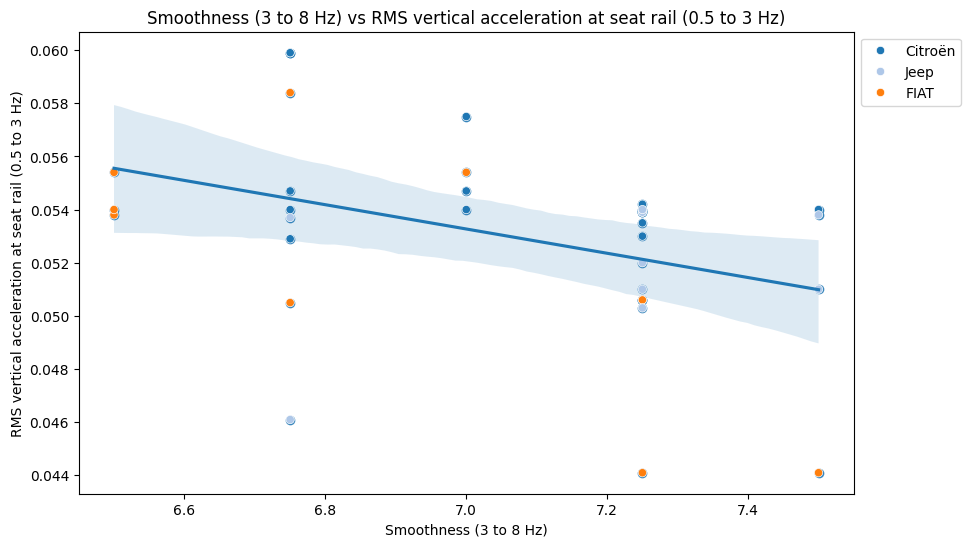

In [121]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["r"])
sns.scatterplot(data=train_df, x="af", y="r", hue='Brand', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

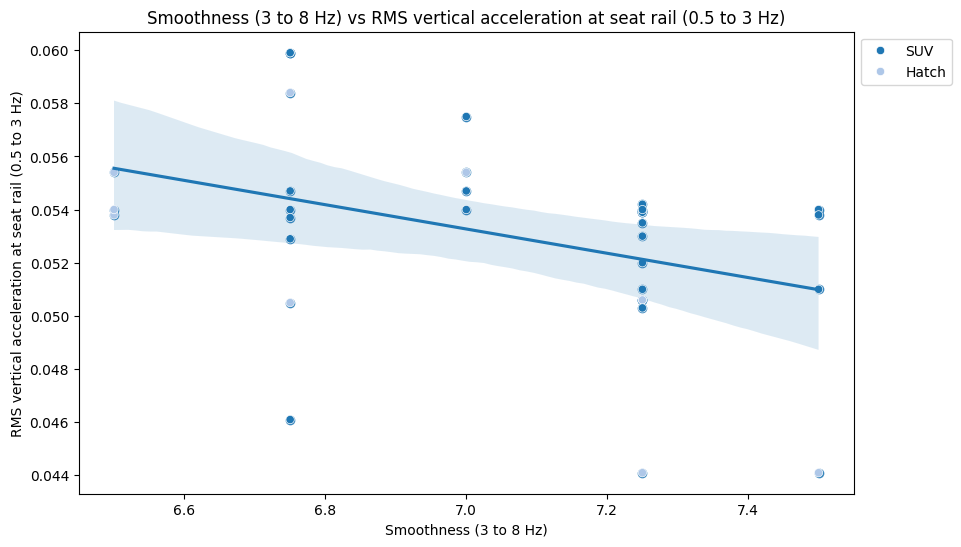

In [122]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["r"])
sns.scatterplot(data=train_df, x="af", y="r", hue='Category', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

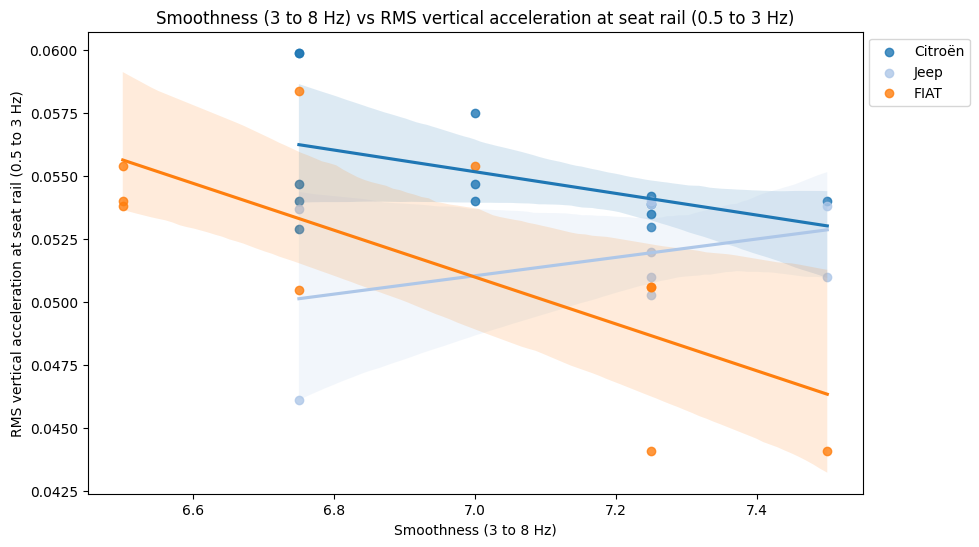

In [123]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="af", y="r", color=color, label=brand)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

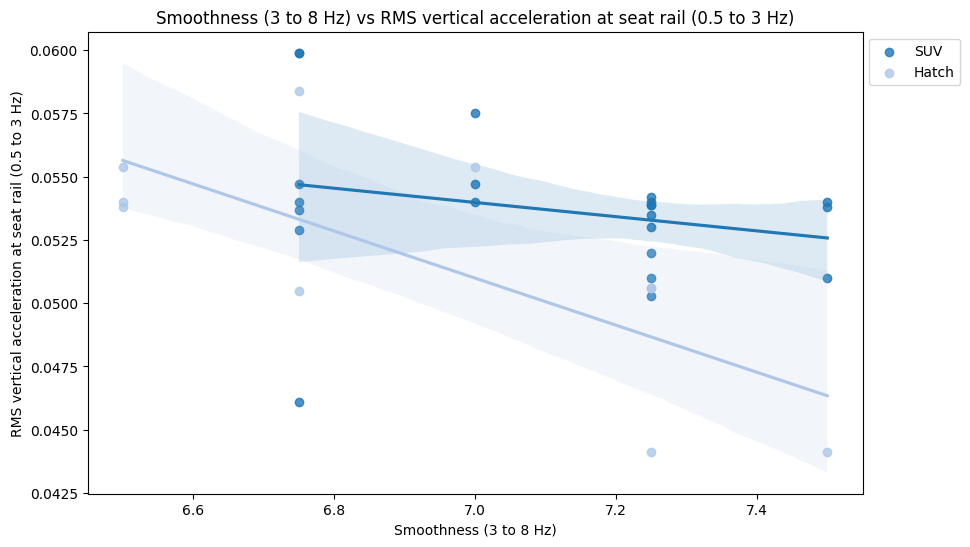

In [124]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="af", y="r", color=color, label=category)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)

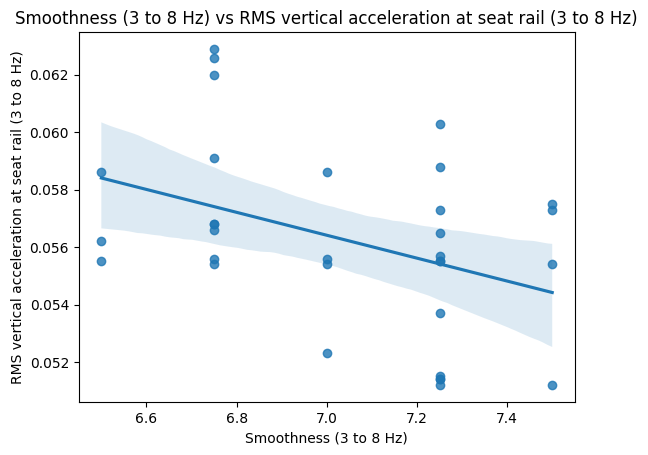

In [125]:
sns.regplot(x=train_df["af"], y=train_df["s"])
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.show()

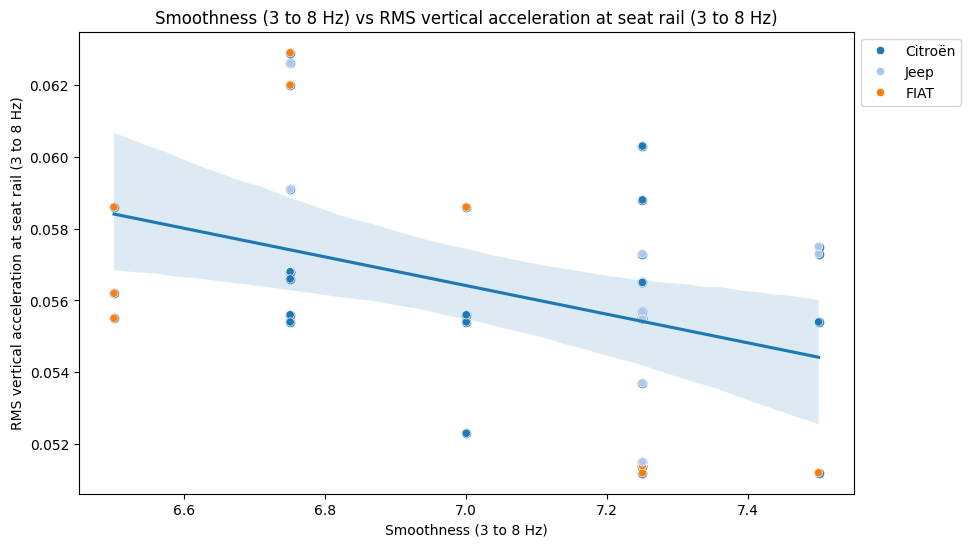

In [126]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["s"])
sns.scatterplot(data=train_df, x="af", y="s", hue='Brand', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

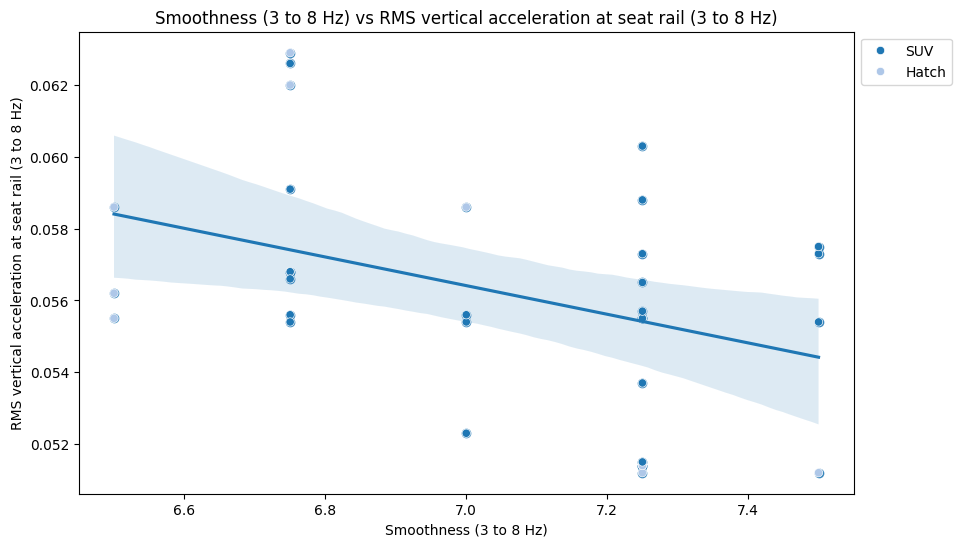

In [127]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["s"])
sns.scatterplot(data=train_df, x="af", y="s", hue='Category', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

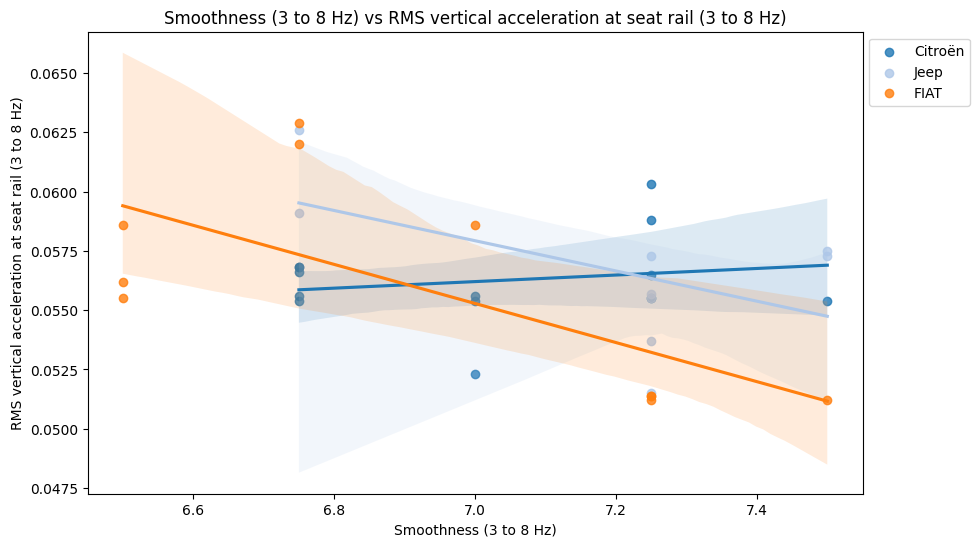

In [128]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="af", y="s", color=color, label=brand)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

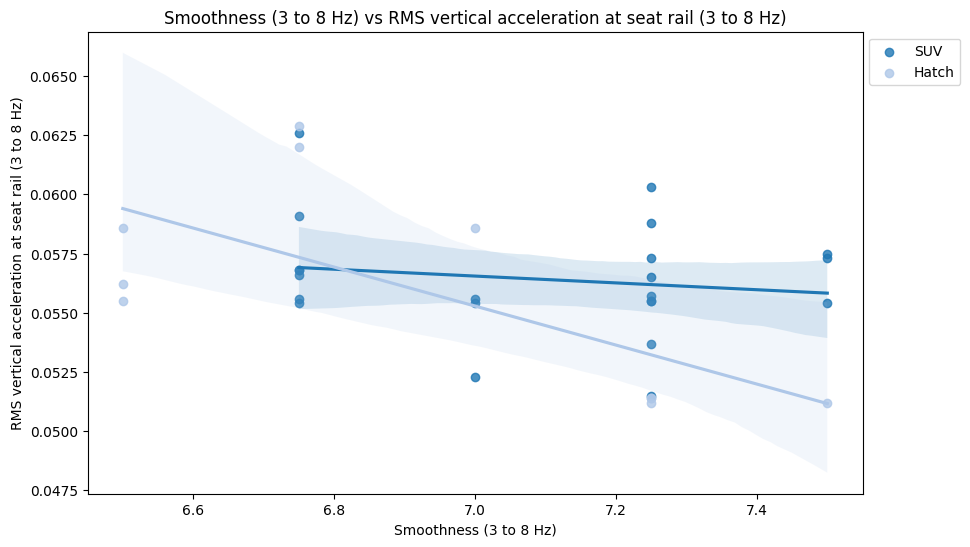

In [129]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="af", y="s", color=color, label=category)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (3 to 8 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)

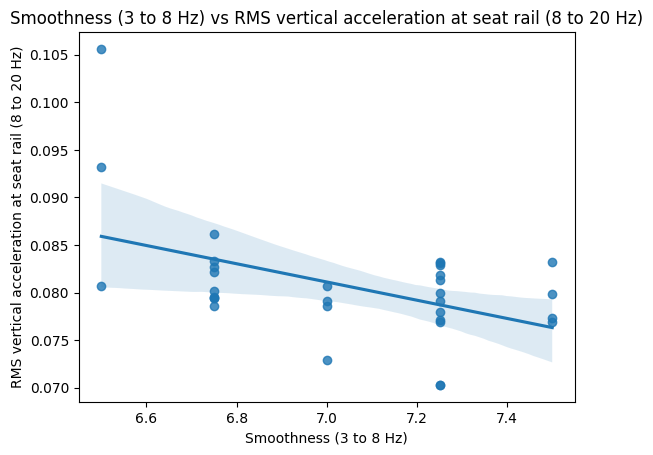

In [130]:
sns.regplot(x=train_df["af"], y=train_df["t"])
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.show()

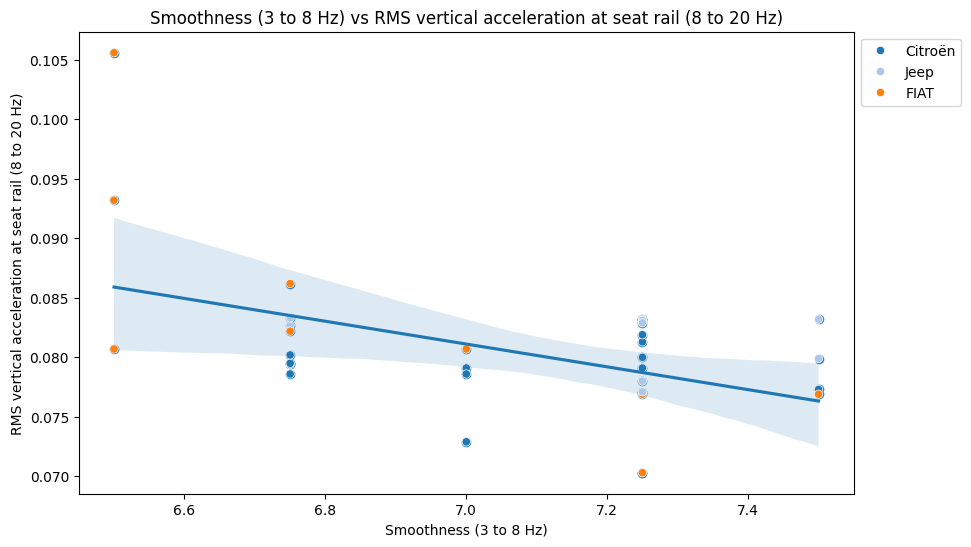

In [131]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["t"])
sns.scatterplot(data=train_df, x="af", y="t", hue='Brand', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

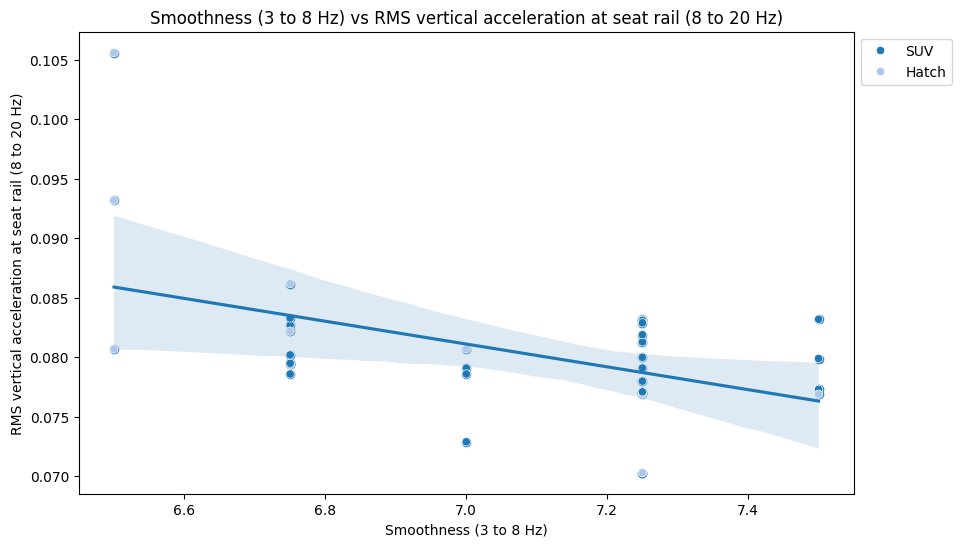

In [132]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["af"], y=train_df["t"])
sns.scatterplot(data=train_df, x="af", y="t", hue='Category', palette='tab20')
plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

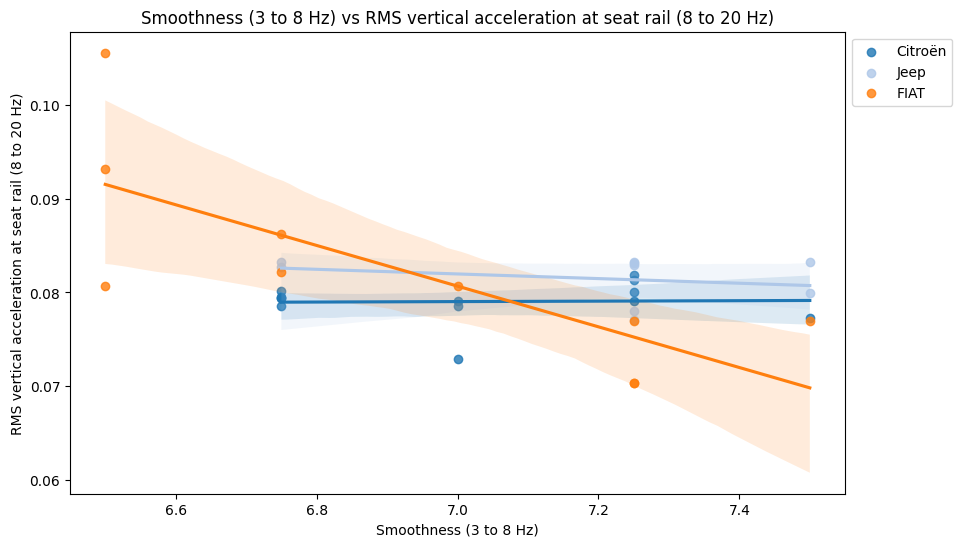

In [133]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="af", y="t", color=color, label=brand)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

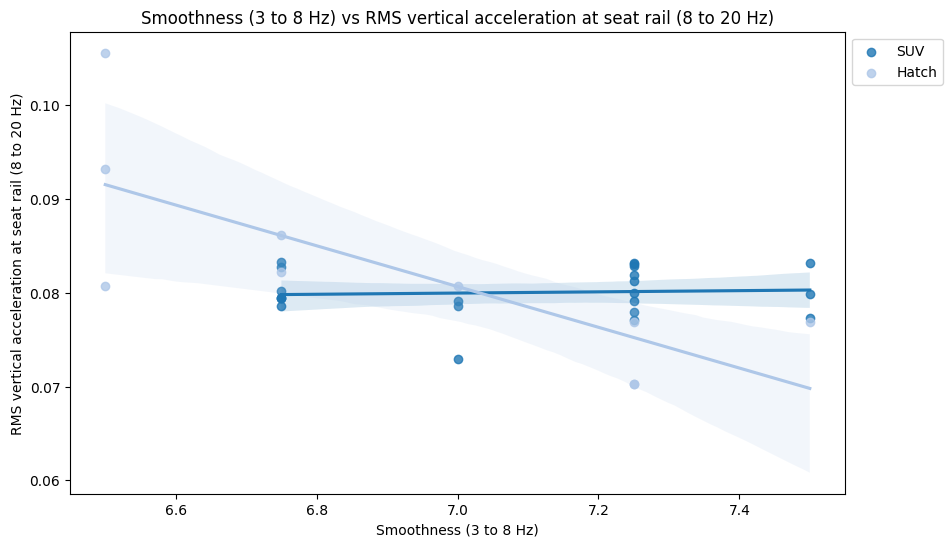

In [134]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="af", y="t", color=color, label=category)

plt.xlabel("Smoothness (3 to 8 Hz)")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Smoothness (3 to 8 Hz) vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)

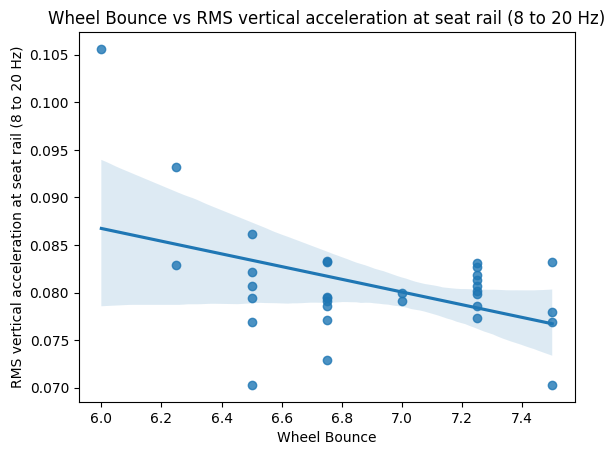

In [135]:
sns.regplot(x=train_df["ag"], y=train_df["t"])
plt.xlabel("Wheel Bounce")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.show()

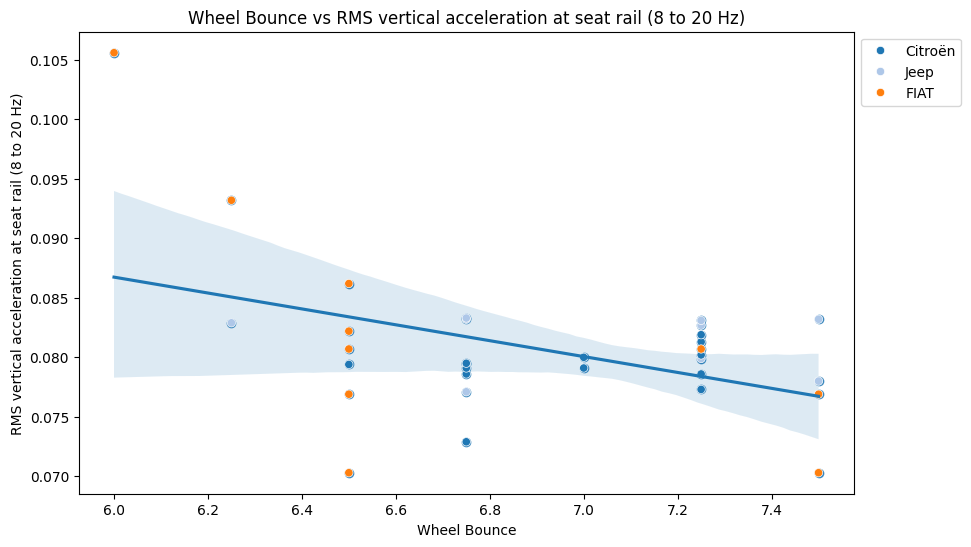

In [136]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ag"], y=train_df["t"])
sns.scatterplot(data=train_df, x="ag", y="t", hue='Brand', palette='tab20')
plt.xlabel("Wheel Bounce")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

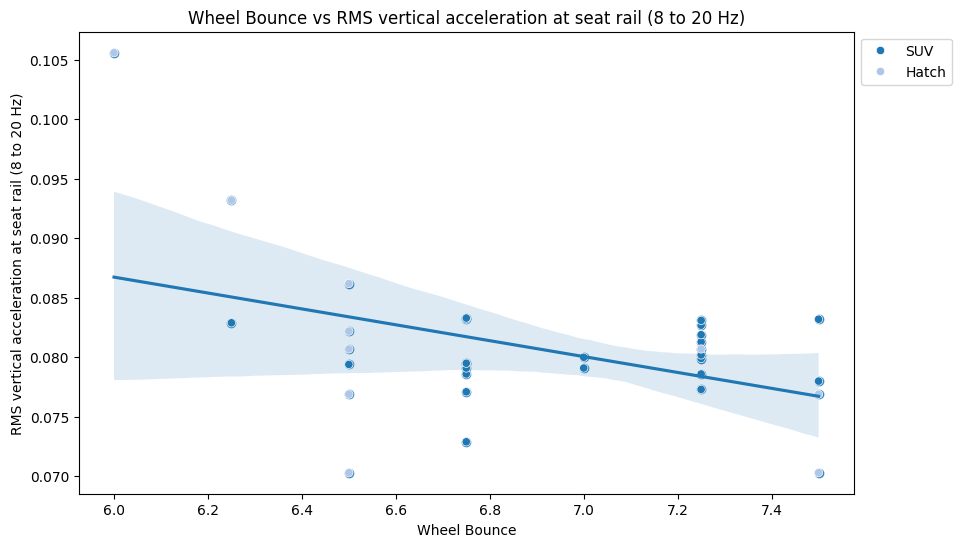

In [137]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ag"], y=train_df["t"])
sns.scatterplot(data=train_df, x="ag", y="t", hue='Category', palette='tab20')
plt.xlabel("Wheel Bounce")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

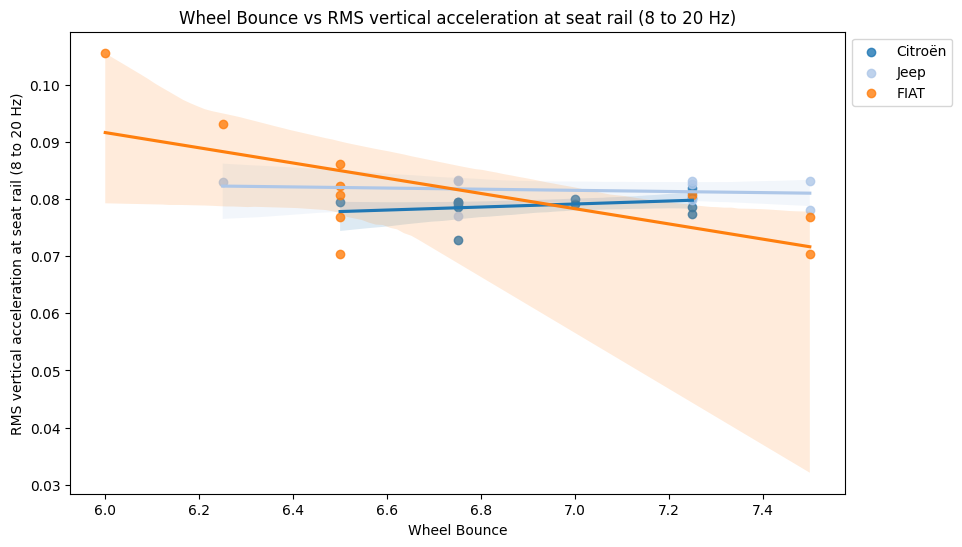

In [138]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ag", y="t", color=color, label=brand)

plt.xlabel("Wheel Bounce")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

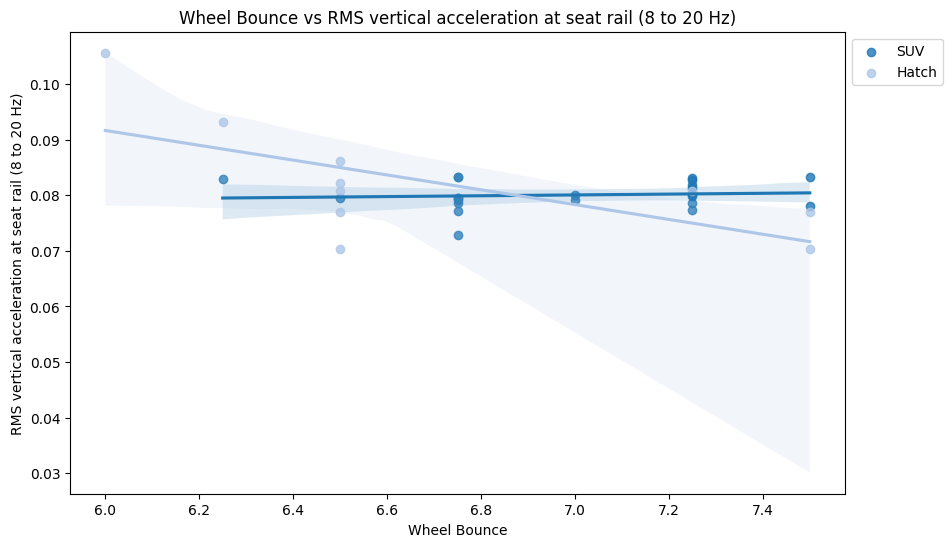

In [139]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ag", y="t", color=color, label=category)

plt.xlabel("Wheel Bounce")
plt.ylabel("RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.title("Wheel Bounce vs RMS vertical acceleration at seat rail (8 to 20 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)

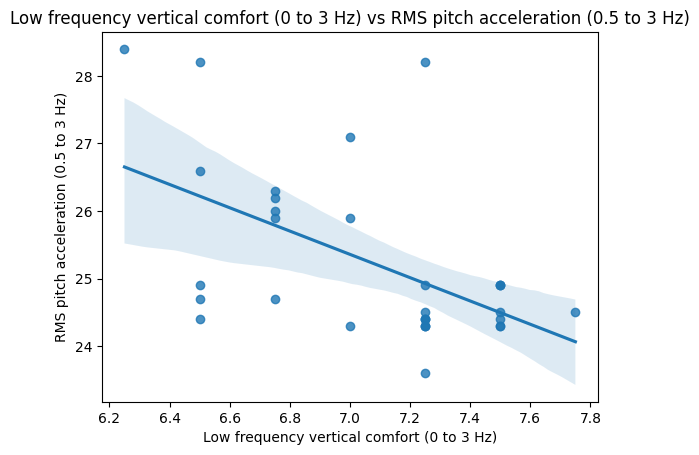

In [140]:
sns.regplot(x=train_df["ae"], y=train_df["u"])
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.show()

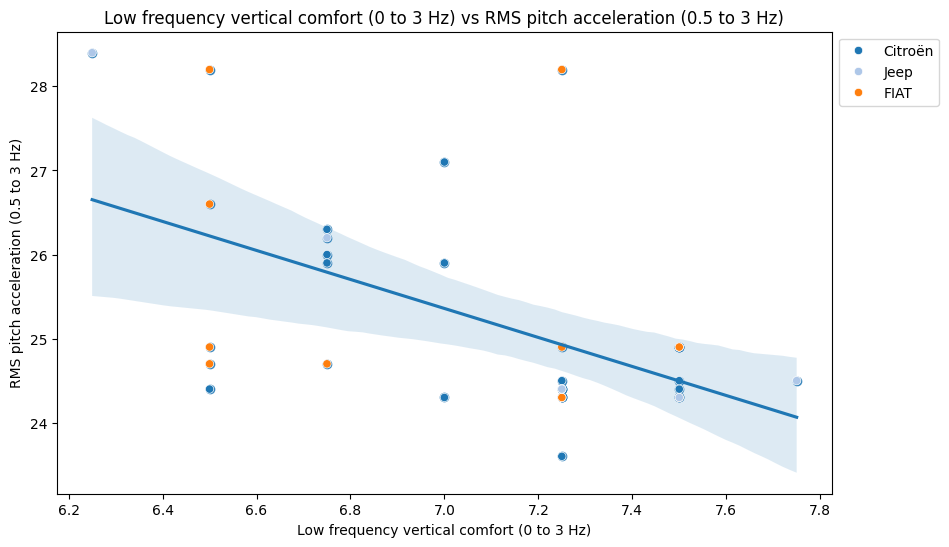

In [141]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["u"])
sns.scatterplot(data=train_df, x="ae", y="u", hue='Brand', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

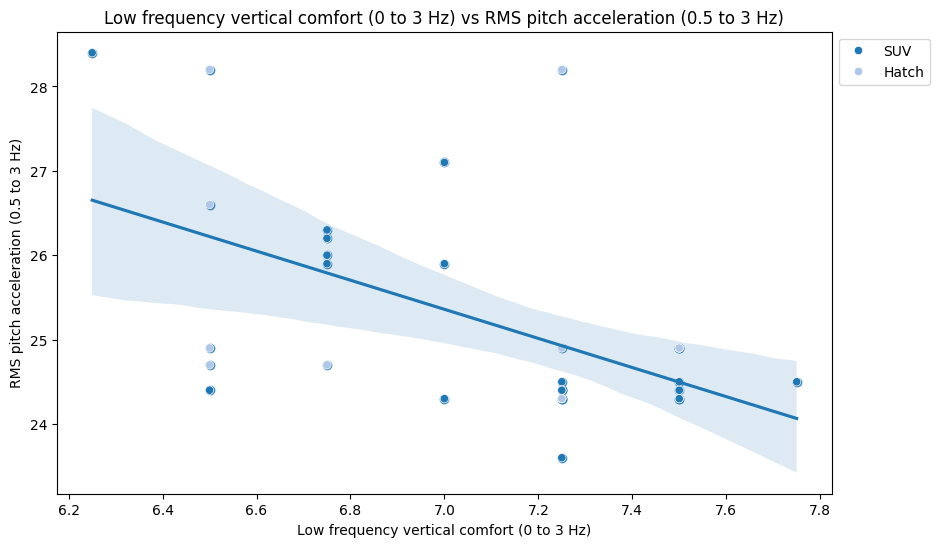

In [142]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["u"])
sns.scatterplot(data=train_df, x="ae", y="u", hue='Category', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

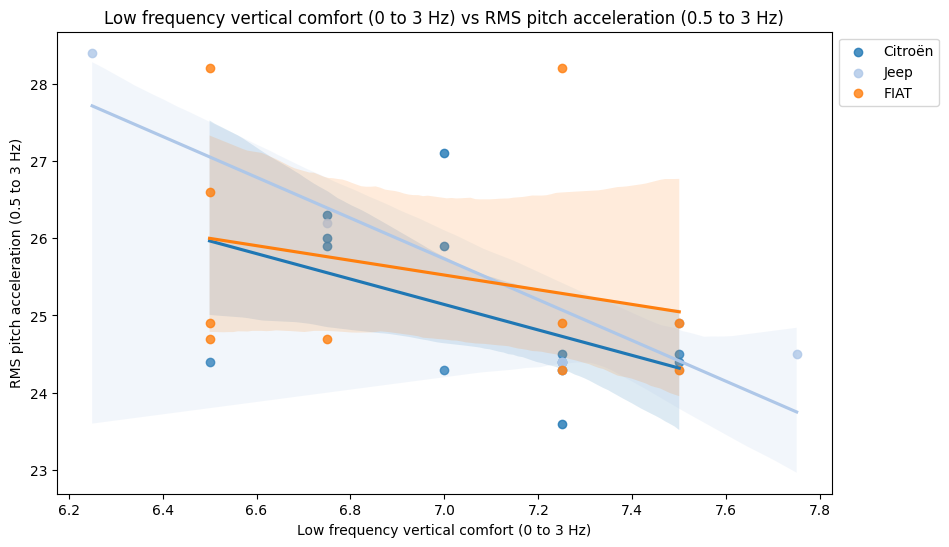

In [143]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ae", y="u", color=color, label=brand)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

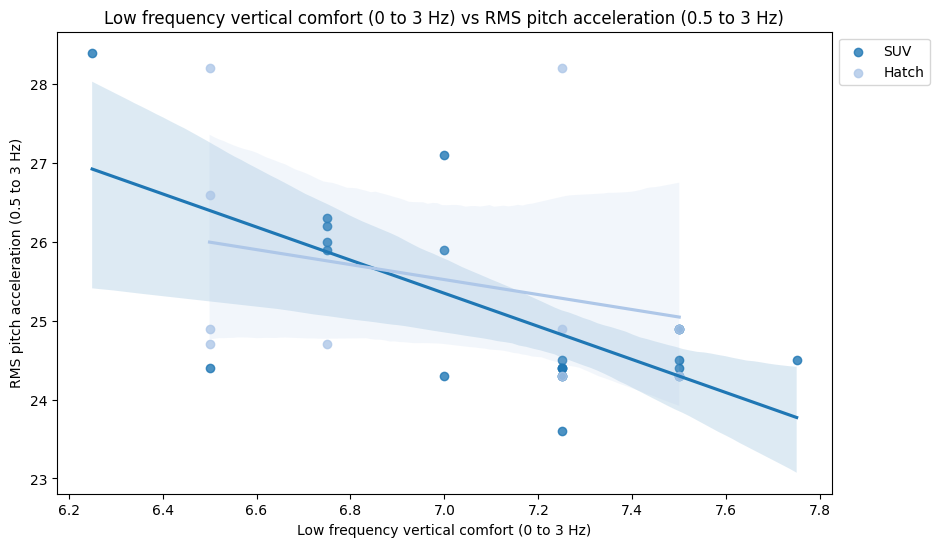

In [144]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ae", y="u", color=color, label=category)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs RMS pitch acceleration (0.5 to 3 Hz)

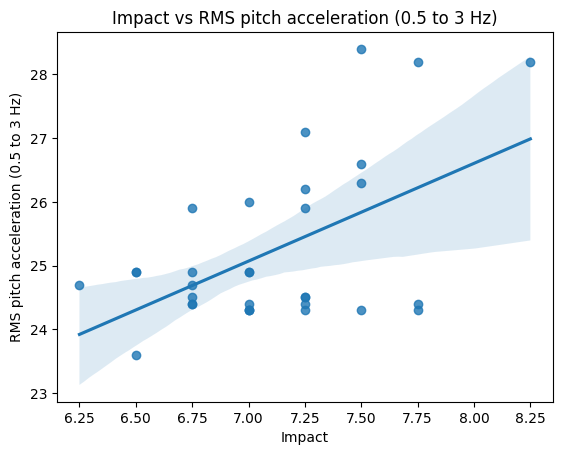

In [145]:
sns.regplot(x=train_df["ai"], y=train_df["u"])
plt.xlabel("Impact")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.show()

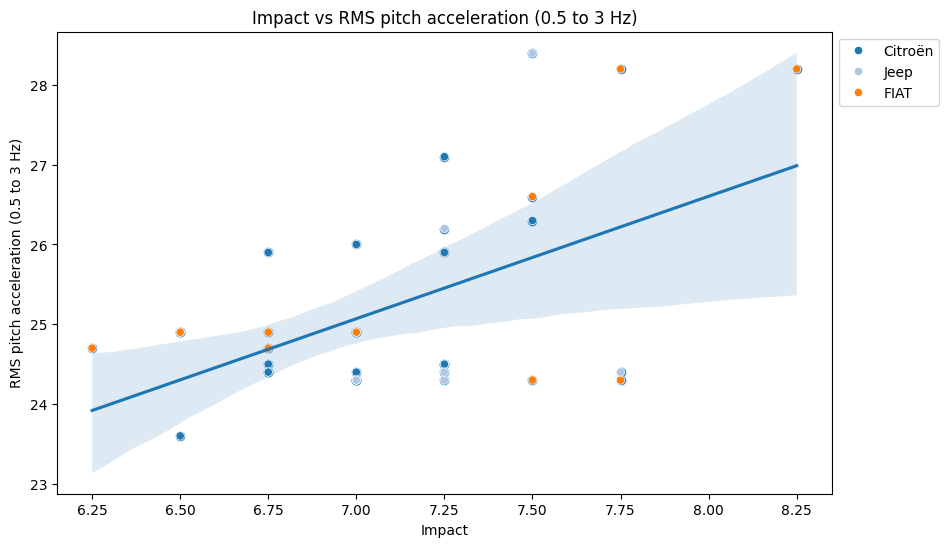

In [146]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["u"])
sns.scatterplot(data=train_df, x="ai", y="u", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

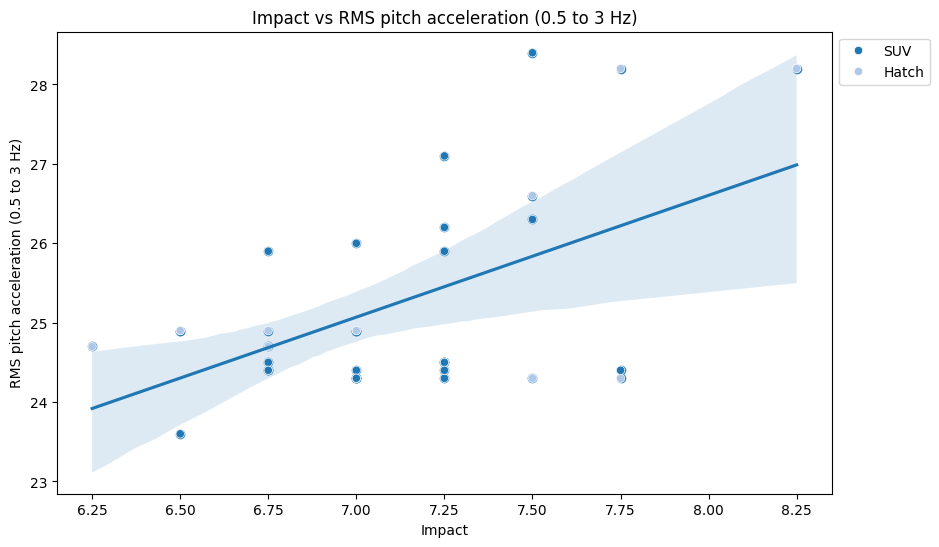

In [147]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["u"])
sns.scatterplot(data=train_df, x="ai", y="u", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

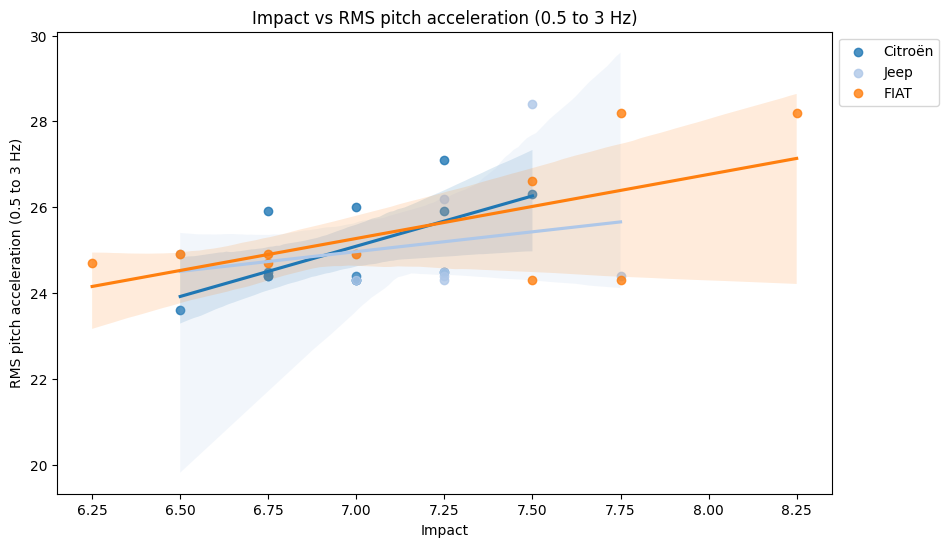

In [148]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="u", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

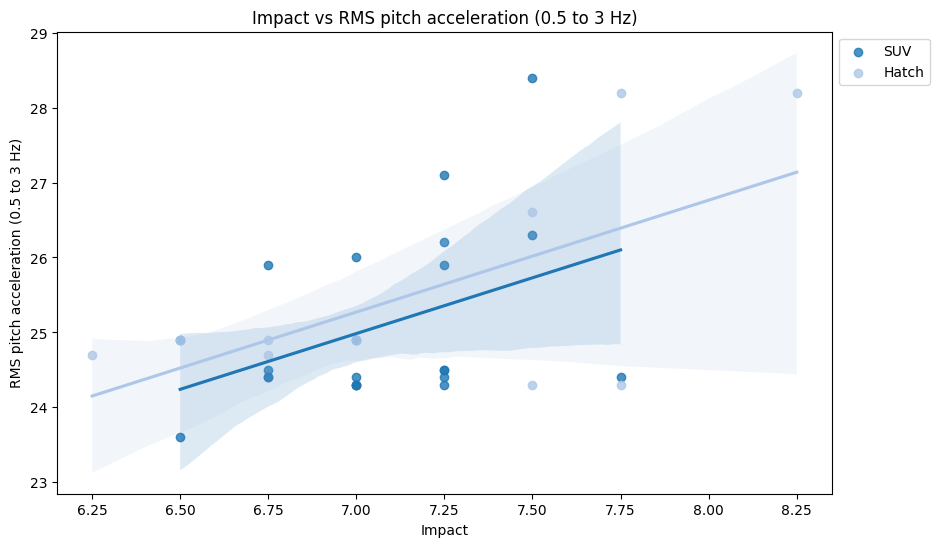

In [149]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="u", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Pitch vs RMS pitch acceleration (0.5 to 3 Hz)

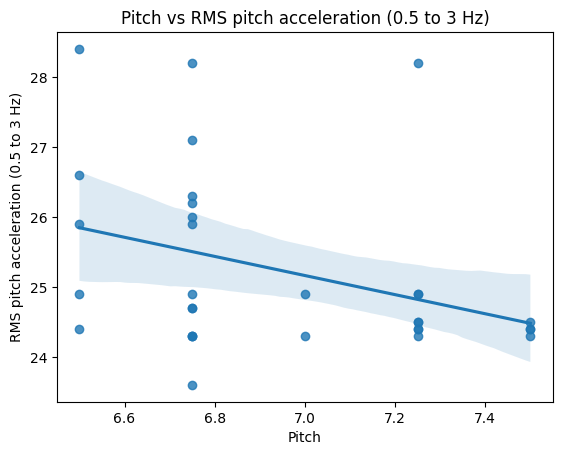

In [150]:
sns.regplot(x=train_df["aj"], y=train_df["u"])
plt.xlabel("Pitch")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Pitch vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.show()

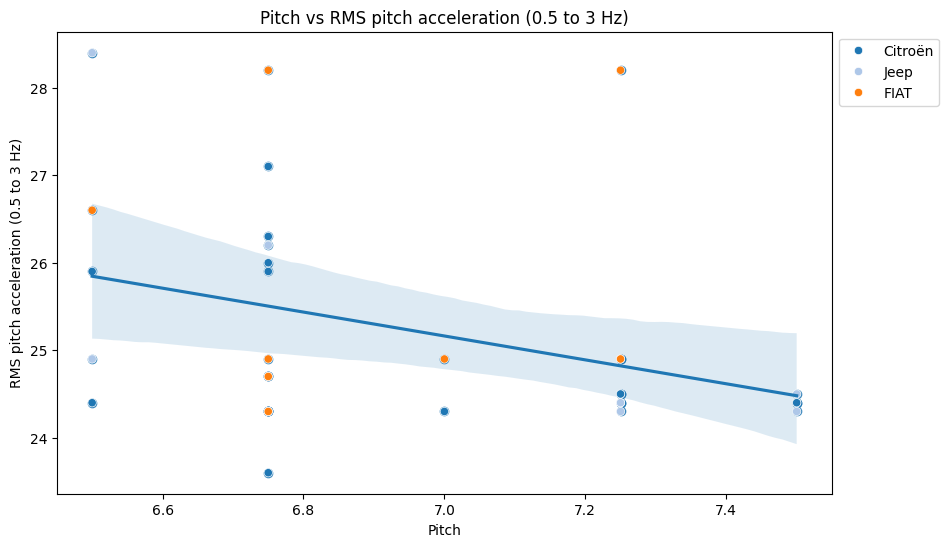

In [151]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["u"])
sns.scatterplot(data=train_df, x="aj", y="u", hue='Brand', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Pitch vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

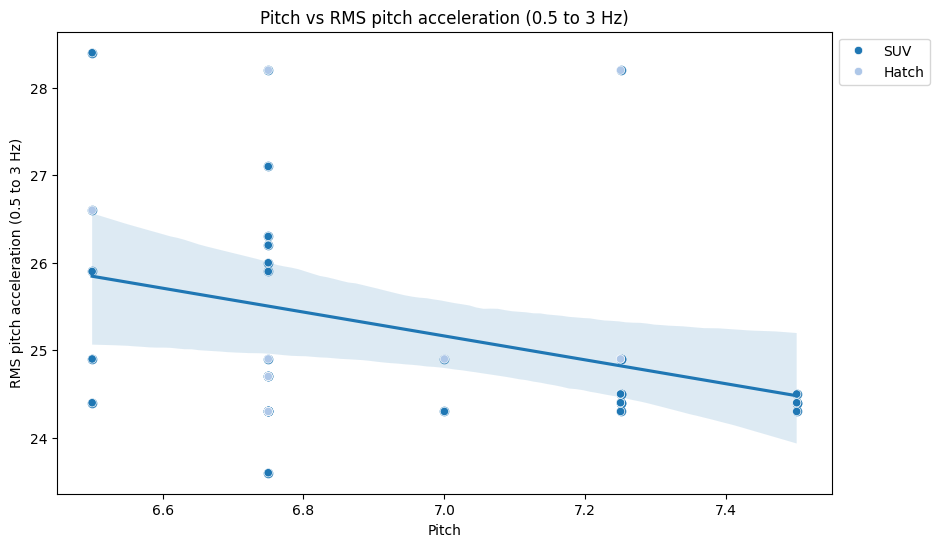

In [152]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["aj"], y=train_df["u"])
sns.scatterplot(data=train_df, x="aj", y="u", hue='Category', palette='tab20')
plt.xlabel("Pitch")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Pitch vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

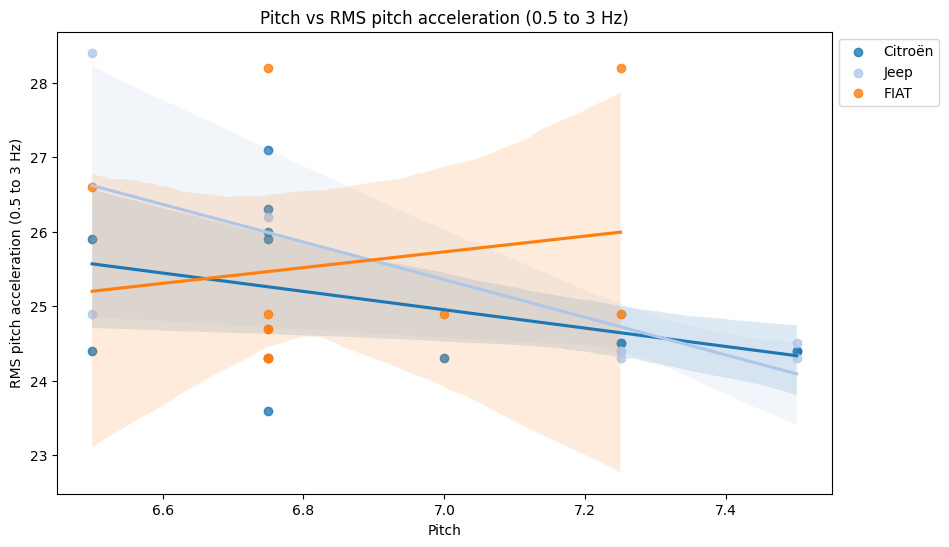

In [153]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="aj", y="u", color=color, label=brand)

plt.xlabel("Pitch")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Pitch vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

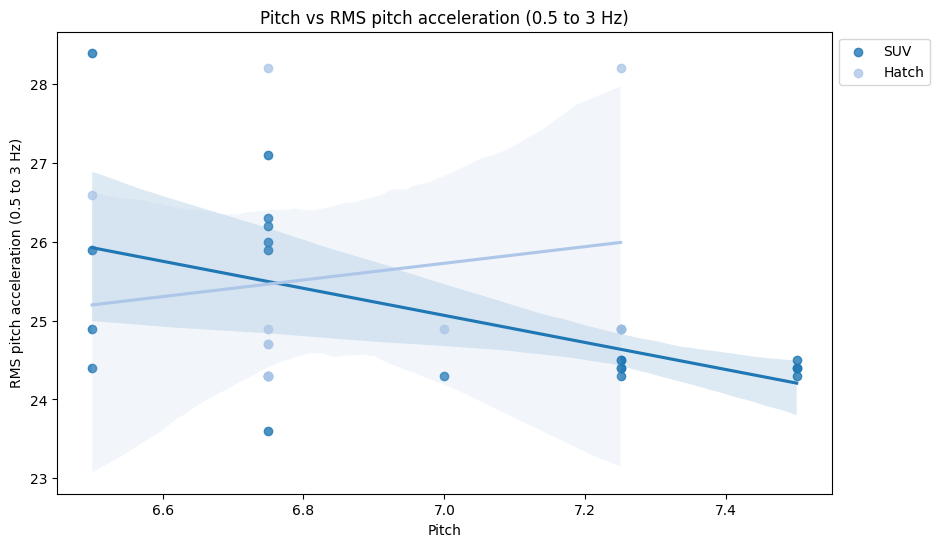

In [154]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="aj", y="u", color=color, label=category)

plt.xlabel("Pitch")
plt.ylabel("RMS pitch acceleration (0.5 to 3 Hz)")
plt.title("Pitch vs RMS pitch acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)

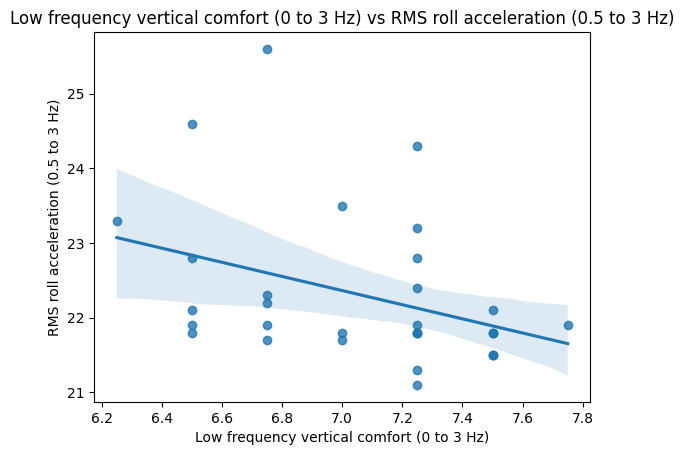

In [155]:
sns.regplot(x=train_df["ae"], y=train_df["v"])
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)")
plt.show()

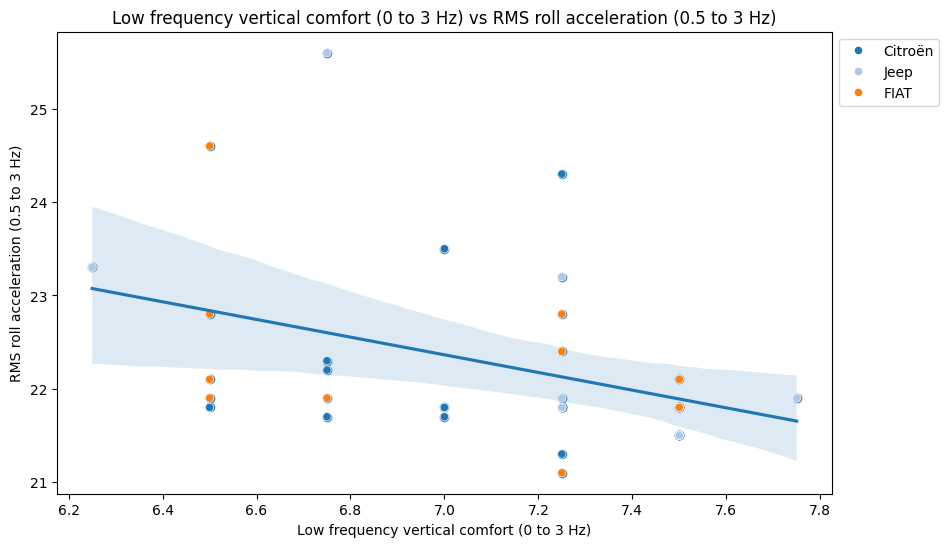

In [156]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["v"])
sns.scatterplot(data=train_df, x="ae", y="v", hue='Brand', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

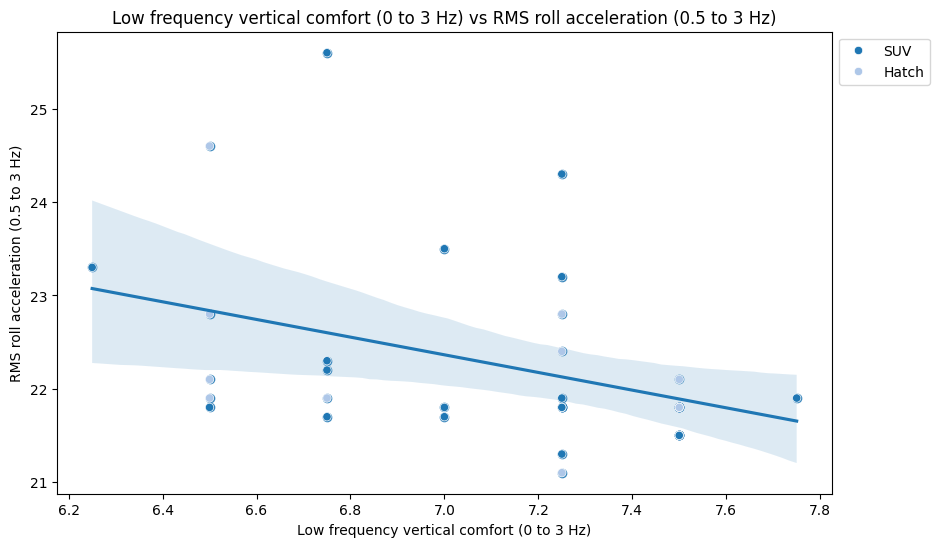

In [157]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ae"], y=train_df["v"])
sns.scatterplot(data=train_df, x="ae", y="v", hue='Category', palette='tab20')
plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

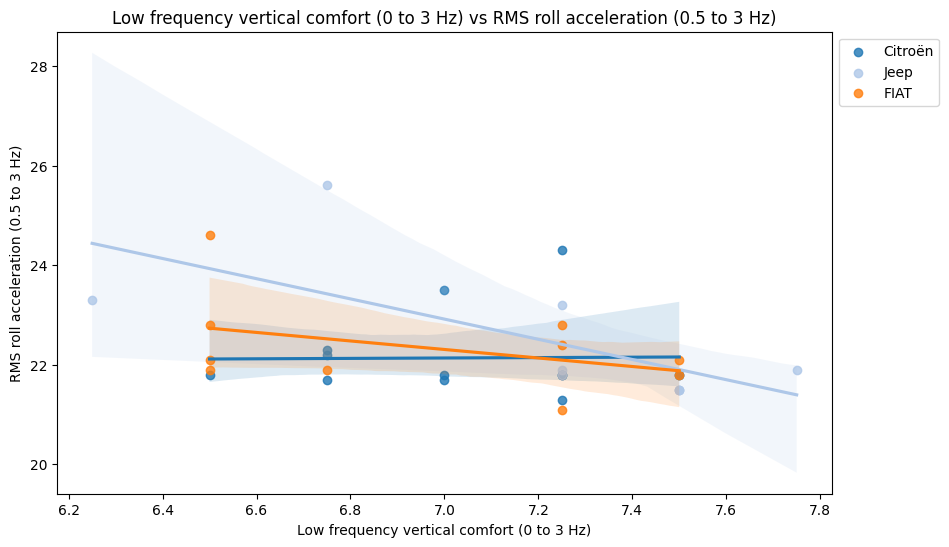

In [158]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ae", y="v", color=color, label=brand)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

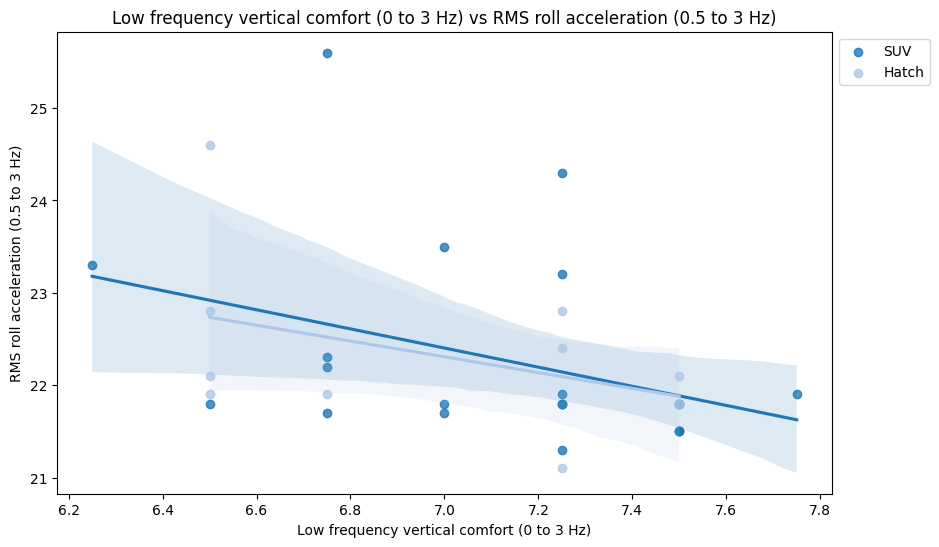

In [159]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ae", y="v", color=color, label=category)

plt.xlabel("Low frequency vertical comfort (0 to 3 Hz)")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Low frequency vertical comfort (0 to 3 Hz) vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs RMS roll acceleration (0.5 to 3 Hz)

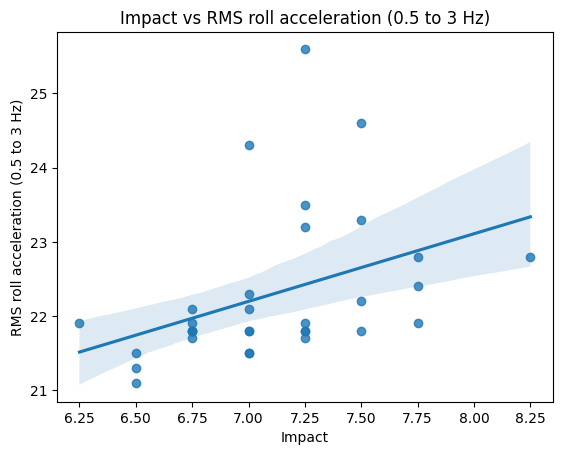

In [160]:
sns.regplot(x=train_df["ai"], y=train_df["v"])
plt.xlabel("Impact")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS roll acceleration (0.5 to 3 Hz)")
plt.show()

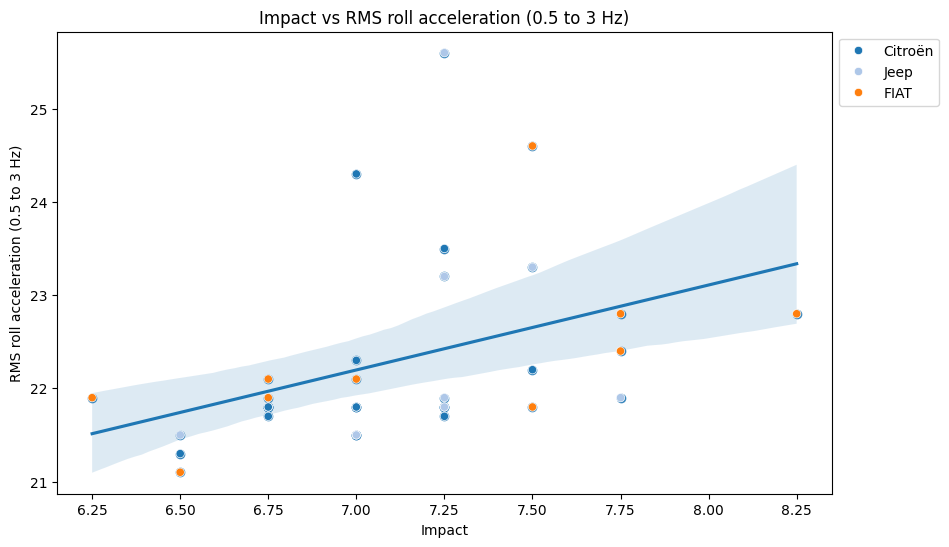

In [161]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["v"])
sns.scatterplot(data=train_df, x="ai", y="v", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

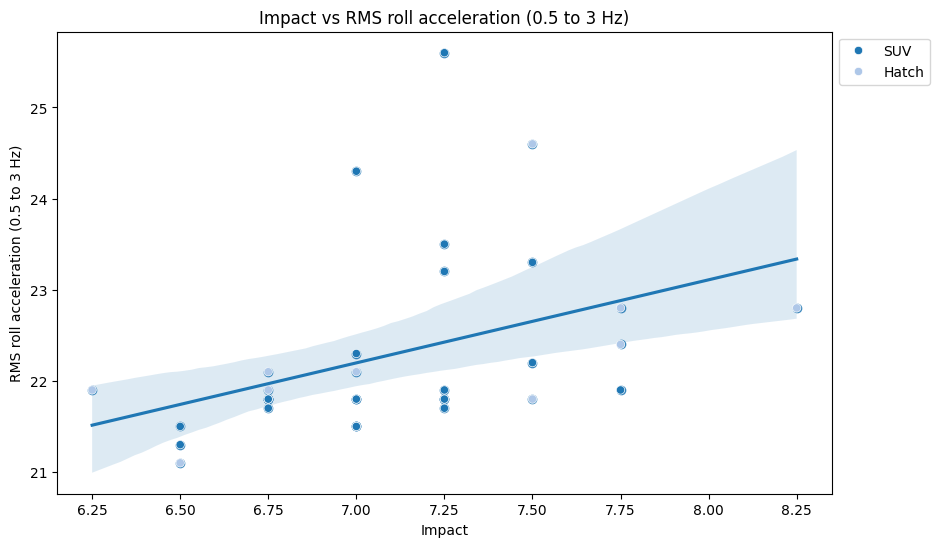

In [162]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["v"])
sns.scatterplot(data=train_df, x="ai", y="v", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

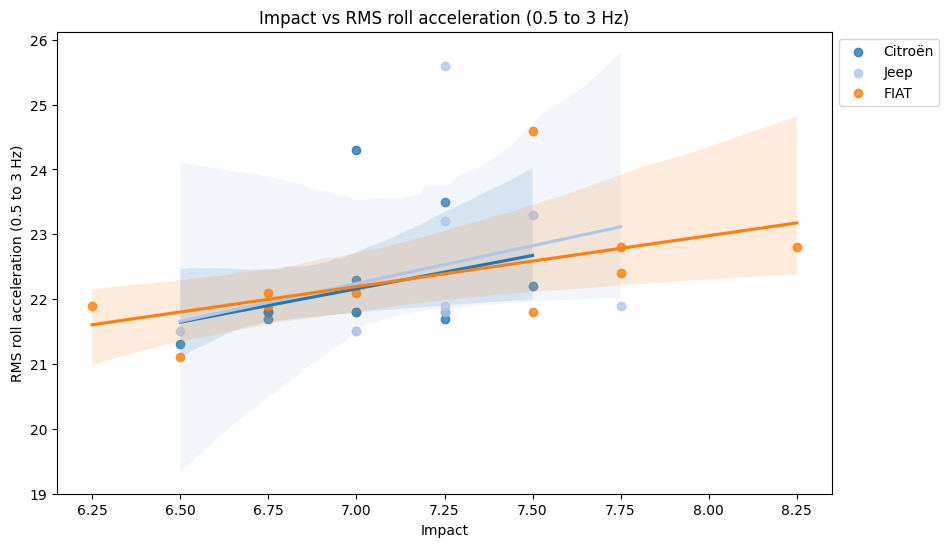

In [163]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="v", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

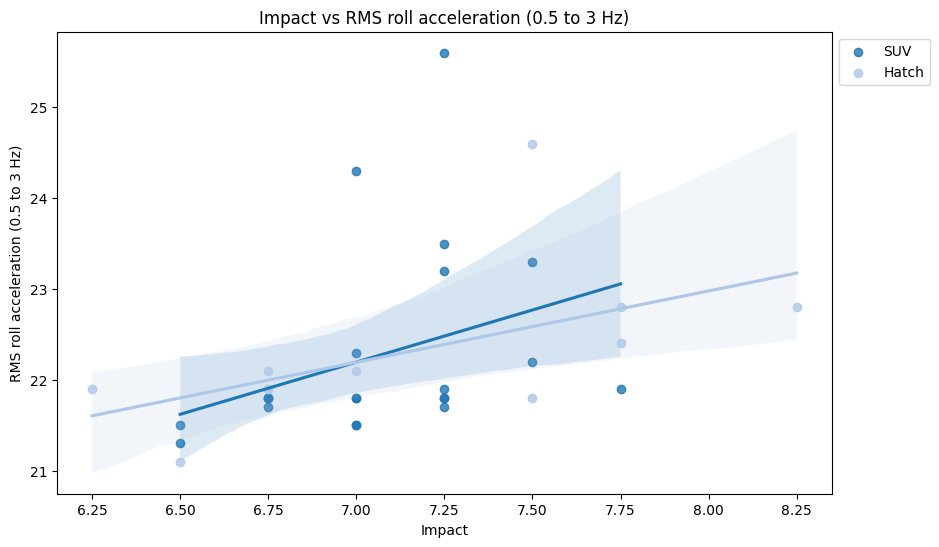

In [164]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="v", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("RMS roll acceleration (0.5 to 3 Hz)")
plt.title("Impact vs RMS roll acceleration (0.5 to 3 Hz)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

###Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​

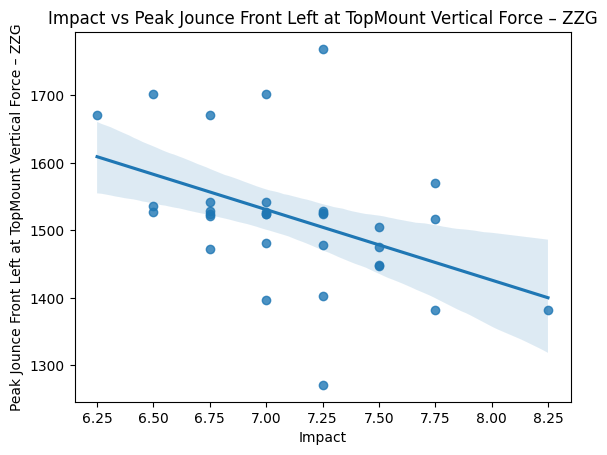

In [165]:
sns.regplot(x=train_df["ai"], y=train_df["w"])
plt.xlabel("Impact")
plt.ylabel("Peak Jounce Front Left at TopMount Vertical Force – ZZG")
plt.title("Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​")
plt.show()

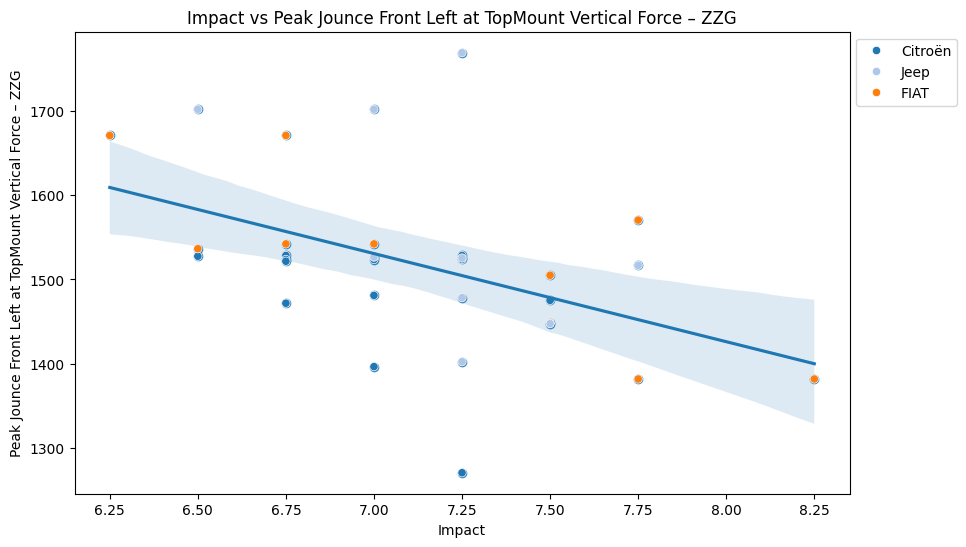

In [166]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["w"])
sns.scatterplot(data=train_df, x="ai", y="w", hue='Brand', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Peak Jounce Front Left at TopMount Vertical Force – ZZG")
plt.title("Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

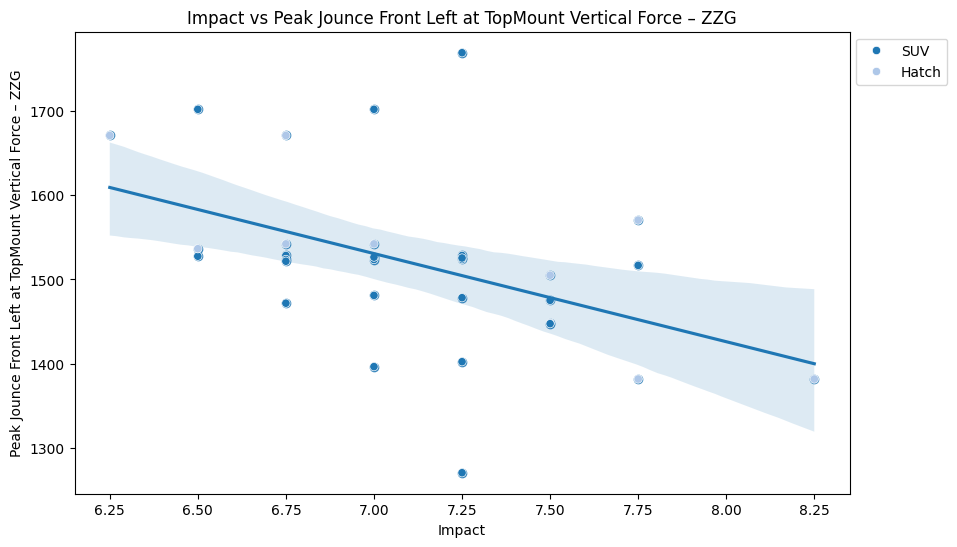

In [167]:
plt.figure(figsize=(10, 6))
sns.regplot(x=train_df["ai"], y=train_df["w"])
sns.scatterplot(data=train_df, x="ai", y="w", hue='Category', palette='tab20')
plt.xlabel("Impact")
plt.ylabel("Peak Jounce Front Left at TopMount Vertical Force – ZZG")
plt.title("Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

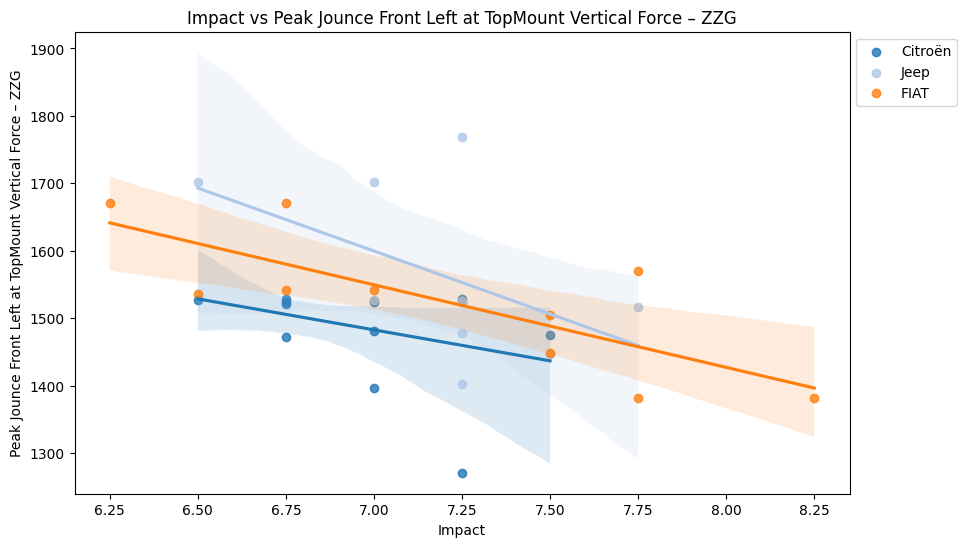

In [168]:
plt.figure(figsize=(10, 6))

brands = train_df['Brand'].unique()
palette = sns.color_palette('tab20', n_colors=len(brands))

for brand, color in zip(brands, palette):

    subset = train_df[train_df['Brand'] == brand]

    sns.regplot(data=subset, x="ai", y="w", color=color, label=brand)

plt.xlabel("Impact")
plt.ylabel("Peak Jounce Front Left at TopMount Vertical Force – ZZG")
plt.title("Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

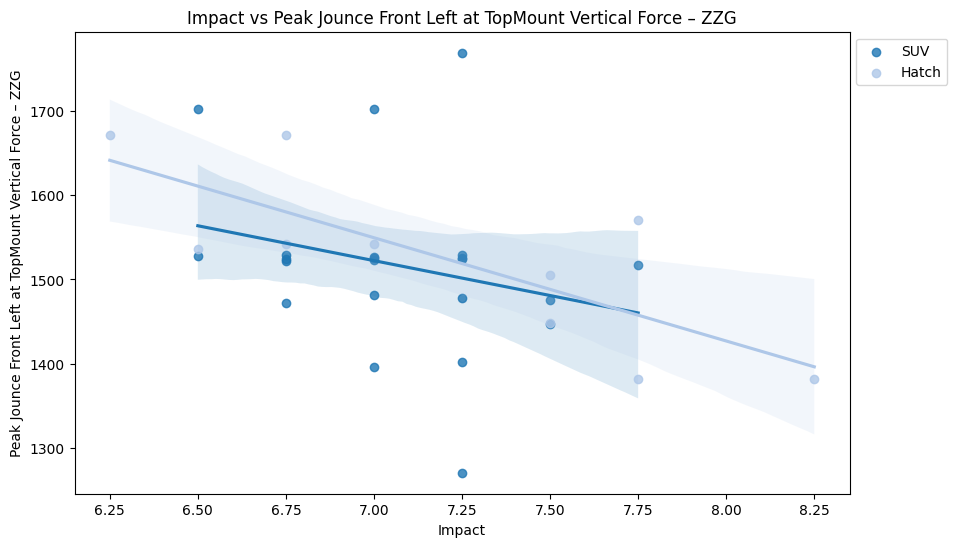

In [169]:
plt.figure(figsize=(10, 6))

categorys = train_df['Category'].unique()
palette = sns.color_palette('tab20', n_colors=len(categorys))

for category, color in zip(categorys, palette):

    subset = train_df[train_df['Category'] == category]

    sns.regplot(data=subset, x="ai", y="w", color=color, label=category)

plt.xlabel("Impact")
plt.ylabel("Peak Jounce Front Left at TopMount Vertical Force – ZZG")
plt.title("Impact vs Peak Jounce Front Left at TopMount Vertical Force – ZZG​​")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

##**7 - Feature Engineering - Regression Problem**

In [170]:
train_df.head()

Letter,a,b,c,d,e,f,g,h,i,j,...,ad,ae,af,ag,ah,ai,aj,ak,Category,Brand
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00,SUV,Citroën
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75,SUV,Citroën
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25,SUV,Citroën
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50,SUV,Jeep
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75,SUV,Citroën


In [171]:
train_df_fteng = train_df

train_df_fteng = pd.get_dummies(train_df, columns=['Category','Brand'])

train_df_fteng.head()

,a,b,c,d,e,f,g,h,i,j,...,ag,ah,ai,aj,ak,Category_Hatch,Category_SUV,Brand_Citroën,Brand_FIAT,Brand_Jeep
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,7.00,7.00,7.00,7.00,7.00,False,True,True,False,False
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,7.00,6.75,7.50,6.75,6.75,False,True,True,False,False
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,6.75,6.25,6.75,6.75,6.25,False,True,True,False,False
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,7.50,7.25,7.25,7.50,7.50,False,True,False,False,True
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,7.25,7.50,7.00,7.50,6.75,False,True,True,False,False


In [172]:
train_df_fteng = train_df_fteng.drop(columns=['a', 'b', 'Category_Hatch', 'Category_SUV', 'Brand_Citroën', 'Brand_FIAT', 'Brand_Jeep'])
train_df_fteng.head()

,c,d,e,f,g,h,i,j,k,l,...,ab,ac,ad,ae,af,ag,ah,ai,aj,ak
0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,0.71,0.19,...,-914.08,-1046.96,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,0.72,0.19,...,-909.86,-1047.92,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,0.73,0.19,...,-912.63,-1035.19,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,0.72,0.19,...,-906.35,-1049.76,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,0.74,0.19,...,-916.89,-1045.62,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75


##**8 - Machine Learning - Regression Problem**

In [173]:
from sklearn.pipeline import Pipeline #Organisation, Flow and Avoiding Data Leakage

# Model Imports
from sklearn.dummy import DummyRegressor # Dummy regression algorithm
from sklearn.linear_model import LinearRegression, SGDRegressor, BayesianRidge, Lasso, ElasticNet # Linear Regression algorithm, Stochastic Gradient Descent Regression, Bayesian Ridge Regression, L1 sets coefficients of useless features to zero, Combination of L1+L2
from sklearn.tree import DecisionTreeRegressor # Decision tree algorithm
from sklearn.neighbors import KNeighborsRegressor # K-nearest neighbours regression algorithm
from sklearn.svm import SVR, LinearSVR # Support Vector Machine regression algorithm
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, AdaBoostRegressor # Random Forest algorithm; Gradient Descent; Random split selection; +Weight on Residual Errors
from sklearn.neural_network import MLPRegressor # Multi-layer Perceptron algorithm - scikit-learn's standard neural network, essential to check whether non-linear patterns exist
from sklearn.gaussian_process import GaussianProcessRegressor # Gaussian Process Regression algorithm
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C # Kernel for the GPR
import xgboost as xgb # XGBoost algorithm
import lightgbm as lgb # LightGBM algorithm (developed by Microsoft; grows trees leaf-wise instead of level-wise - usually leads to better convergence and accuracy)
import catboost as cb # CatBoost algorithm (developed by Yandex; native handling of categorical features without one-hot/label encoding; better performance without hyperparameter tuning)



###**Multi-Output Learning: Strategy and Definitions**

**Group 1:** Algorithms that natively support Multi-Output:
* DummyRegressor
* LinearRegression
* Lasso
* ElasticNet
* DecisionTreeRegressor
* KNeighborsRegressor
* RandomForestRegressor
* ExtraTreesRegressor
* MLPRegressor (Neural Networks)
* XGBoost (XGBRegressor)
* CatBoostRegressor
* GaussianProcessRegressor (GPR)


**Group 2:** Algorithms that do not natively support Multi-Output (chosen strategy: **Wrapper**)
* SVR
* LinearSVR
* SGDRegressor
* BayesianRidge
* GradientBoostingRegressor
* AdaBoostRegressor
* LightGBM (LGBMRegressor)

In [174]:
from sklearn.multioutput import MultiOutputRegressor #Wrapper
# --- Evaluation Tools and Metrics ---
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, LeaveOneOut, train_test_split, GridSearchCV #Cross-Validation chosen! LeaveOneOut if cv=3 or cv=5 is too unstable
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Splitting the training data into X: features and y: target
X = train_df_fteng.drop(['ae','af','ag','ah','ai','aj','ak'],axis=1)

#target Multi-Output
y_all = train_df_fteng[['ae','af','ag','ah','ai','aj','ak']]

#target Single-Output
y_ae = train_df_fteng[['ae']]
y_af = train_df_fteng[['af']]
y_ag = train_df_fteng[['ag']]
y_ah = train_df_fteng[['ah']]
y_ai = train_df_fteng[['ai']]
y_aj = train_df_fteng[['aj']]
y_ak = train_df_fteng[['ak']]

#Splitting the training data again into training and test data // Not necessary because the sample size is small; I will use the Cross-Validation method
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)

In [175]:
X.head()

,c,d,e,f,g,h,i,j,k,l,...,u,v,w,x,y,z,aa,ab,ac,ad
0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,0.71,0.19,...,24.30,21.80,1524.94,1086.81,1789.63,1588.52,-1255.01,-914.08,-1046.96,-740.91
1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,0.72,0.19,...,26.30,22.20,1475.24,1088.43,1781.84,1580.02,-1254.11,-909.86,-1047.92,-738.95
2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,0.73,0.19,...,25.90,21.70,1528.47,1087.80,1790.71,1593.04,-1255.03,-912.63,-1035.19,-727.42
3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,0.72,0.19,...,24.50,21.90,1768.97,1502.67,1824.86,1616.27,-1164.30,-906.35,-1049.76,-746.75
4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,0.74,0.19,...,24.40,21.80,1523.68,1087.42,1775.56,1587.75,-1256.23,-916.89,-1045.62,-742.34


###**Data Normalisation**

**Strategy:** Do not use a single normalisation for all algorithms; separate them into groups.

**Group 1:** Tree-Based Algorithms (do not need Scaling)
* DecisionTreeRegressor
* RandomForestRegressor
* ExtraTreesRegressor
* GradientBoostingRegressor
* AdaBoostRegressor
* XGBoost (XGBRegressor)
* LGBM (LGBMRegressor)
* CatBoost (CatBoostRegressor)
* DummyRegressor

**Group 2:** Gradient/Distance-Based and Probabilistic Algorithms (Scaling is critical - I will adopt RobustScaler)
* LinearRegression
* SGDRegressor
* BayesianRidge
* Lasso
* ElasticNet
* KNeighborsRegressor
* SVR
* LinearSVR
* MLPRegressor (Neural Networks)
* GaussianProcessRegressor (GPR)

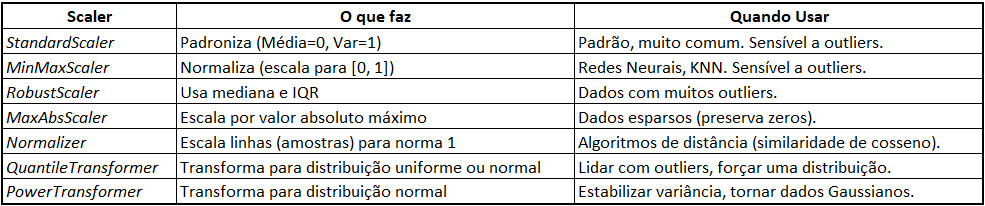

In [176]:
# Preprocessing: Scalers and Transformers
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, PowerTransformer #I will use RobustScaler and PowerTransformer method=Yeo-Johnson

###**Machine Learning Models**

In [177]:
warnings.filterwarnings('ignore')
cv_splits = 5 #or 3, LeaveOneOut()
cv_obj = KFold(n_splits=cv_splits, shuffle=True, random_state=42)

print(f"Setup de Classificação pronto. CV com StratifiedKFold (k={cv_obj}).")

Setup de Classificação pronto. CV com StratifiedKFold (k=KFold(n_splits=5, random_state=42, shuffle=True)).


In [178]:
# Dictionary to store all pipelines
pipelines = {}

#DummyRegressor
pipelines['DummyRegressor'] = Pipeline([
    ('model', DummyRegressor(strategy='mean'))
])

#DecisionTreeRegressor
pipelines['DecisionTree'] = Pipeline([
    ('model', DecisionTreeRegressor(random_state=42))
])

#RandomForestRegressor
pipelines['RandomForest'] = Pipeline([
    ('model', RandomForestRegressor(random_state=42))
])

#ExtraTreesRegressor
pipelines['ExtraTrees'] = Pipeline([
    ('model', ExtraTreesRegressor(random_state=42))
])

#XGBoost (XGBRegressor)
pipelines['XGBoost'] = Pipeline([
    ('model', xgb.XGBRegressor(random_state=42))
])

#LightGBM (LGBMRegressor)
pipelines['LightGBM'] = Pipeline([
    ('model', MultiOutputRegressor(lgb.LGBMRegressor(random_state=42,
                               n_estimators=50,      # Reduced to be fast
                               min_child_samples=1,  # Leaves with 1 sample
                               n_jobs=1,             # Avoids parallelism problems in CV
                              verbose = -1)))        #verbose=1 default, 0 errors and warnings, -1 fatal errors
])

#GradientBoostingRegressor
pipelines['GradientBoosting'] = Pipeline([
    ('model', MultiOutputRegressor(GradientBoostingRegressor(random_state=42)))
])

#CatBoost (CatBoostRegressor)
pipelines['CatBoost'] = Pipeline([
    ('model', cb.CatBoostRegressor(random_state=42,
                                  verbose=0, #verbose=0 clean console
                                  loss_function='MultiRMSE')) # Required for multi-output
])

#AdaBoost (AdaBoostRegressor)
pipelines['AdaBoost'] = Pipeline([
    ('model', MultiOutputRegressor(AdaBoostRegressor(random_state=42)))
])

#KNeighborsRegressor
pipelines['KNeighbors'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', KNeighborsRegressor())
])

#LinearRegression
pipelines['LinearRegression'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', LinearRegression())
])

#Lasso
pipelines['Lasso'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', Lasso(random_state=42))
])

#ElasticNet
pipelines['ElasticNet'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', ElasticNet(random_state=42))
])

#SGDRegressor
pipelines['SGDRegressor'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', MultiOutputRegressor(SGDRegressor(random_state=42)))
])

#BayesianRidge
pipelines['BayesianRidge'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', MultiOutputRegressor(BayesianRidge()))
])

#KNeighbors Regressor
pipelines['KNeighbors'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', KNeighborsRegressor())
])

#Multi-Layer Perceptron Regressor
pipelines['MLPRegressor'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', MLPRegressor(random_state=42, max_iter=1000, early_stopping=True))
])

#GussianProcessRegressor
kernel_gpr = C(1.0) * RBF(1.0) # Default kernel for the GPR
pipelines['GPR'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', GaussianProcessRegressor(kernel=kernel_gpr, random_state=42, alpha=1e-5)) # Alpha for stability
])

#SVR
pipelines['SVR'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', MultiOutputRegressor(SVR()))
])

#LinearSVR
pipelines['LinearSVR'] = Pipeline([
    ('scaler', RobustScaler()),
    ('model', MultiOutputRegressor(LinearSVR(random_state=42, max_iter=5000, dual=True))) # max_iter=5000 to ensure convergence
])

print(f"Total de {len(pipelines)} pipelines definidos.")
print(list(pipelines.keys()))

Total de 19 pipelines definidos.
['DummyRegressor', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM', 'GradientBoosting', 'CatBoost', 'AdaBoost', 'KNeighbors', 'LinearRegression', 'Lasso', 'ElasticNet', 'SGDRegressor', 'BayesianRidge', 'MLPRegressor', 'GPR', 'SVR', 'LinearSVR']


##**9 - Results - Regression Problem**

###**Multi-Outputs | Multi Features**

In [179]:
print("\n--- INICIANDO AVALIAÇÃO DETALHADA (Multi-Outputs | Multi Features) ---")

# Dictionary to store the results for the comparison chart
# We will use the mean R² as our comparison metric
model_comparison_scores = {}
target_names = y_all.columns

for nome, pipe in pipelines.items():
    print(f"Avaliando Modelo: {nome}")

    try:
        # 1. Obtain predictions using cross-validation
        # y_pred will have shape (N_AMOSTRAS, N_OUTPUTS)
        y_pred = cross_val_predict(pipe, X, y_all, cv=cv_obj)

        # 2. Compute and store the Mean R² (for the comparison chart)
        # 'uniform_average' computes the R² of each target and takes the mean
        r2_medio = r2_score(y_all, y_pred, multioutput='uniform_average')
        model_comparison_scores[nome] = r2_medio

        print(f"R² Médio (Média dos 7 outputs): {r2_medio:.4f}")
        print(" (Quanto mais perto de 1.0, melhor o modelo explica a variância)\n")

        # 3. Detailed Metrics Report (Per Output)
        print("--- Relatório de Métricas Detalhado (por Output) ---")

        # Create lists to store the 7 actual and predicted values
        # (This makes plotting easier)
        y_true_cols = []
        y_pred_cols = []

        for i, target in enumerate(target_names):
            y_true_col = y_all.iloc[:, i]
            y_pred_col = y_pred[:, i]

            y_true_cols.append(y_true_col)
            y_pred_cols.append(y_pred_col)

            # Compute metrics for this specific target
            r2 = r2_score(y_true_col, y_pred_col)
            rmse = np.sqrt(mean_squared_error(y_true_col, y_pred_col))
            mae = mean_absolute_error(y_true_col, y_pred_col)

            print(f"\nTarget: '{target}'")
            print(f"  R² Score: {r2:8.4f}")
            print(f"  RMSE:     {rmse:8.4f} pontos SAE")
            print(f"  MAE:      {mae:8.4f} pontos SAE")

        # 4. Plot "Actual vs. Predicted" Charts (the "Equivalent" of the Confusion Matrix)
        print(f"\n--- Plotando Gráficos Real vs. Previsto para {nome} ---")
        n_outputs = len(target_names)
        n_cols = 3
        n_rows = (n_outputs + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        fig.suptitle(f"Real vs. Previsto para: {nome}", fontsize=16)
        axes = axes.flatten()

        for i, target in enumerate(target_names):
            ax = axes[i]

            # Take the data of this target
            y_t = y_true_cols[i]
            y_p = y_pred_cols[i]

            # Create the scatter plot
            sns.scatterplot(x=y_t, y=y_p, ax=ax, alpha=0.6)
            ax.set_title(f"Target: '{target}'")
            ax.set_xlabel("Valores Reais")
            ax.set_ylabel("Valores Previstos")

            # Add the diagonal line (perfect prediction)
            # Find the limits for the line
            min_val = min(y_t.min(), y_p.min()) * 0.95
            max_val = max(y_t.max(), y_p.max()) * 1.05
            ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)
            ax.set_xlim(min_val, max_val)
            ax.set_ylim(min_val, max_val)


        # Hide unused axes
        for i in range(n_outputs, len(axes)):
            axes[i].axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    except Exception as e:
        print(f"!!!!!!!! NÃO FOI POSSÍVEL AVALIAR O MODELO {nome} !!!!!!!!")
        print(f"Erro: {e}")
        # Store a very poor R² for failures
        model_comparison_scores[nome] = -np.inf

Output hidden; open in https://colab.research.google.com to view.

Iniciando geração de gráficos de importância de features...

--- Processando Modelo: DummyRegressor ---
Calculando Permutation Importance (agnóstico ao modelo)...
Modelo DummyRegressor não atribui importância a nenhuma feature (importância total é 0).
Pulando o gráfico de Pareto...

--- Processando Modelo: DecisionTree ---
Calculando Permutation Importance (agnóstico ao modelo)...


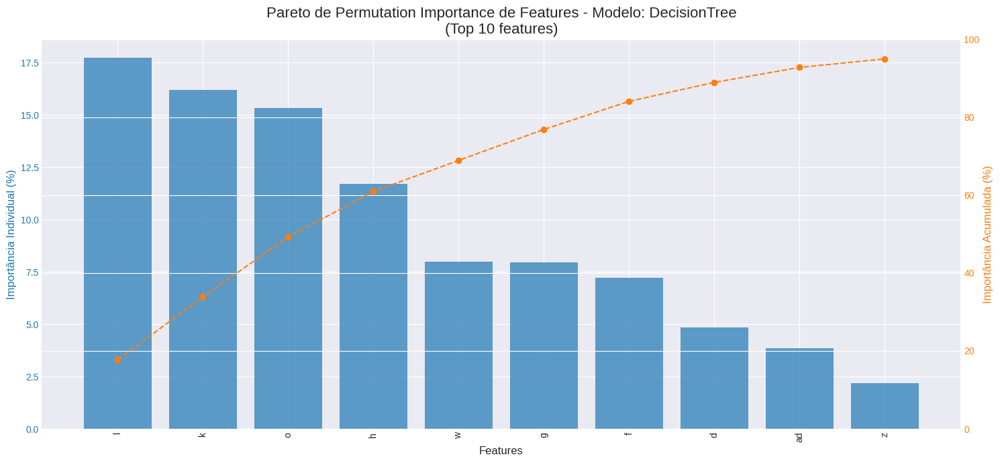


--- Processando Modelo: RandomForest ---
Calculando Permutation Importance (agnóstico ao modelo)...


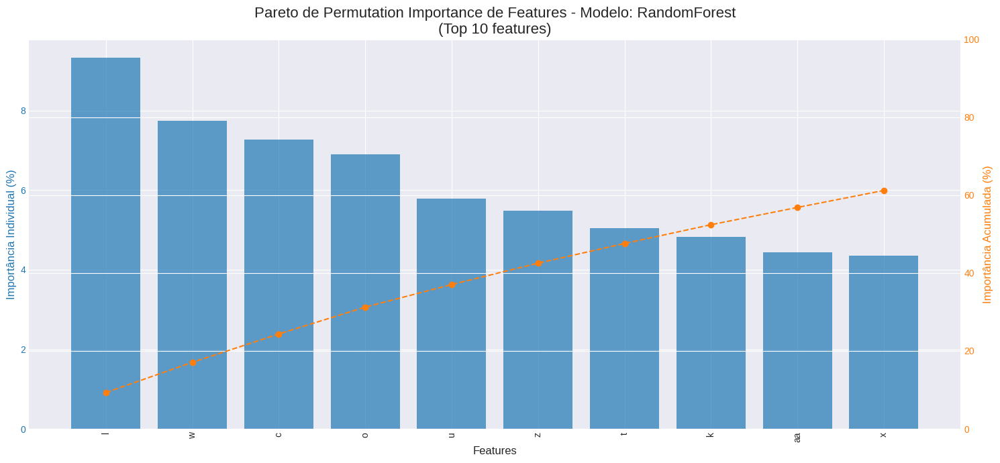


--- Processando Modelo: ExtraTrees ---
Calculando Permutation Importance (agnóstico ao modelo)...


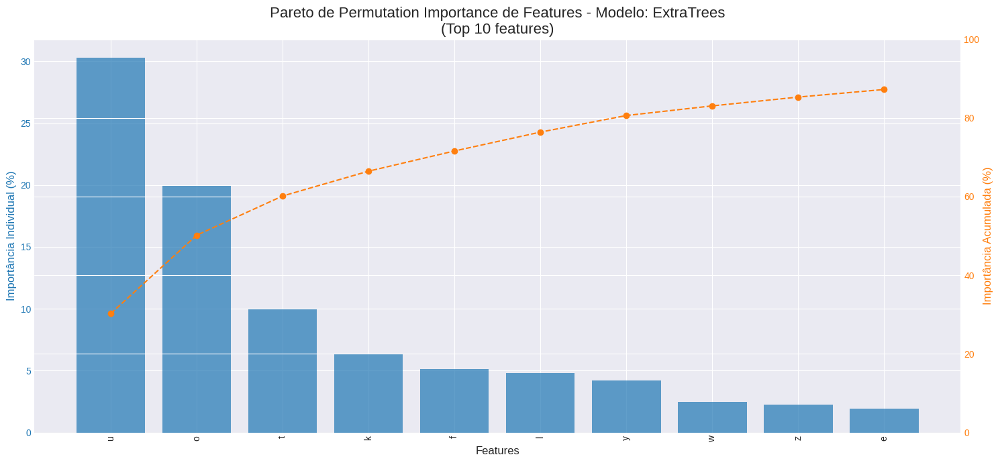


--- Processando Modelo: XGBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


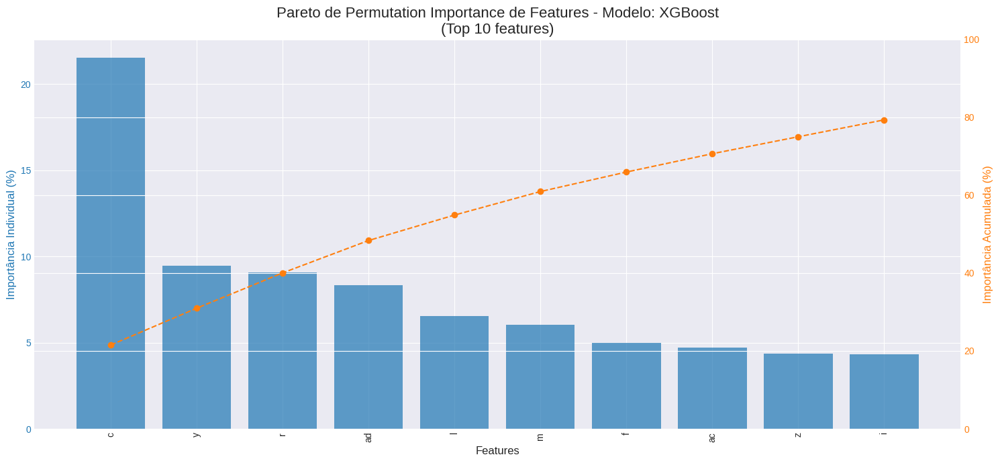


--- Processando Modelo: LightGBM ---
Calculando Permutation Importance (agnóstico ao modelo)...


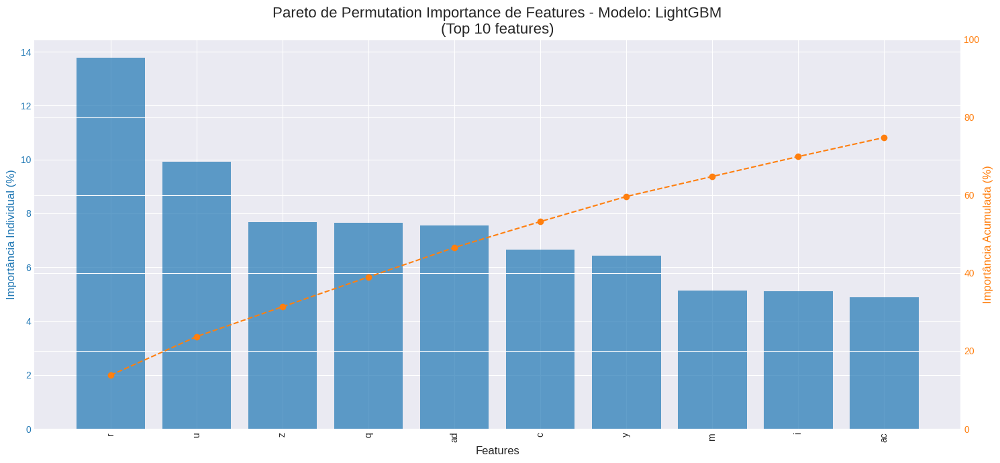


--- Processando Modelo: GradientBoosting ---
Calculando Permutation Importance (agnóstico ao modelo)...


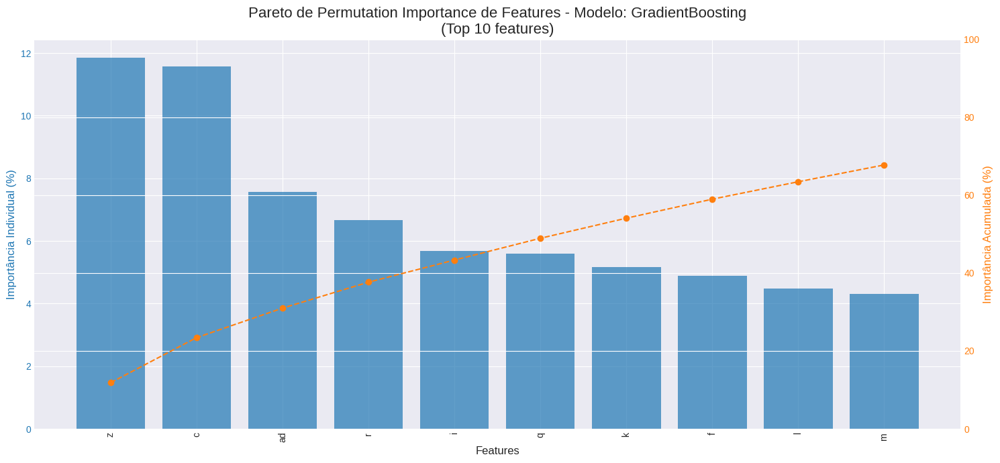


--- Processando Modelo: CatBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


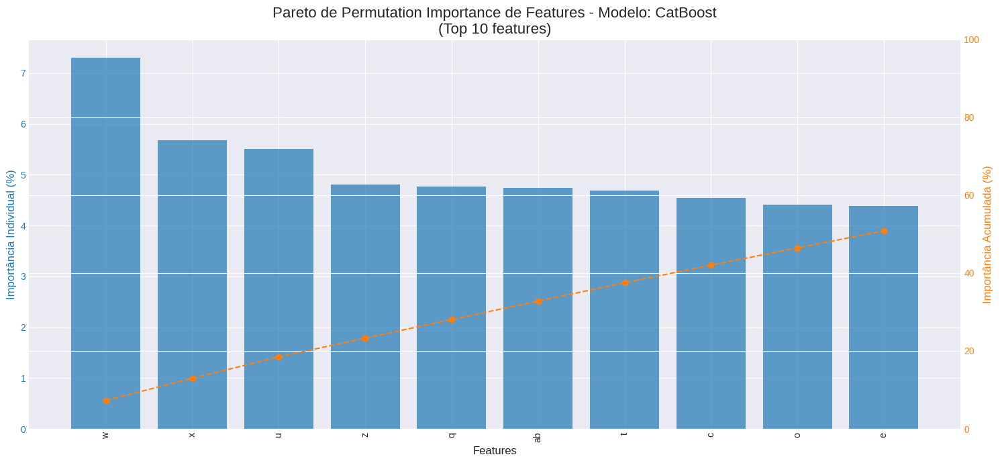


--- Processando Modelo: AdaBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


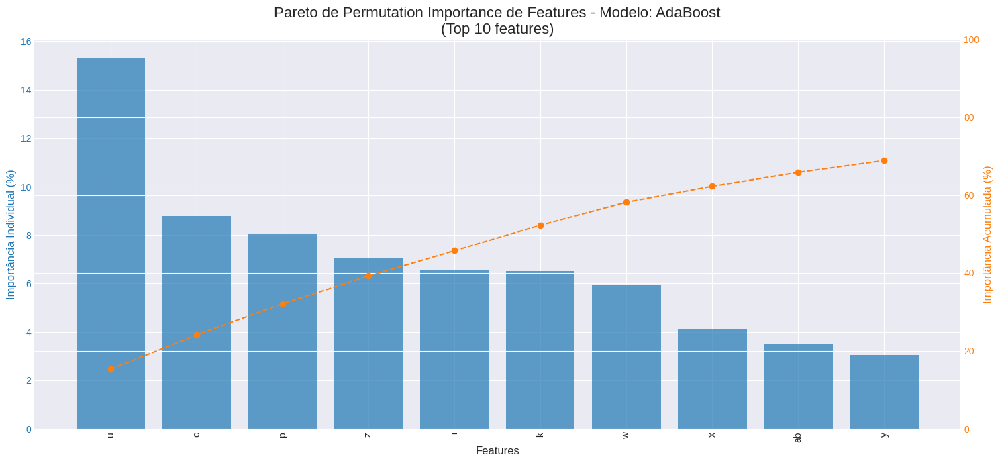


--- Processando Modelo: KNeighbors ---
Calculando Permutation Importance (agnóstico ao modelo)...


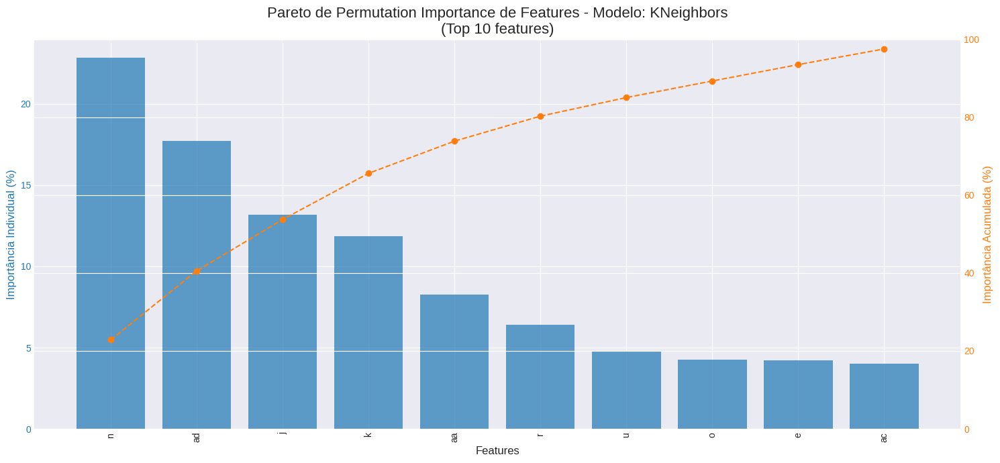


--- Processando Modelo: LinearRegression ---
Calculando Permutation Importance (agnóstico ao modelo)...


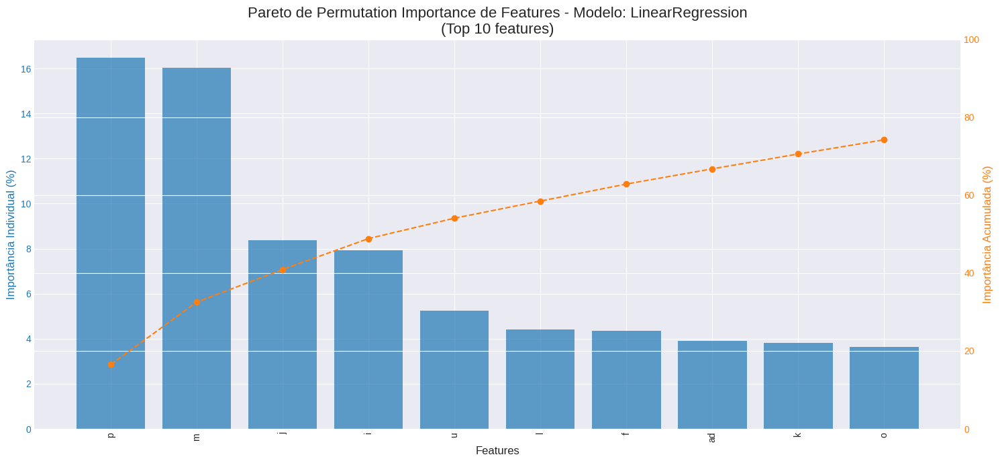


--- Processando Modelo: Lasso ---
Calculando Permutation Importance (agnóstico ao modelo)...


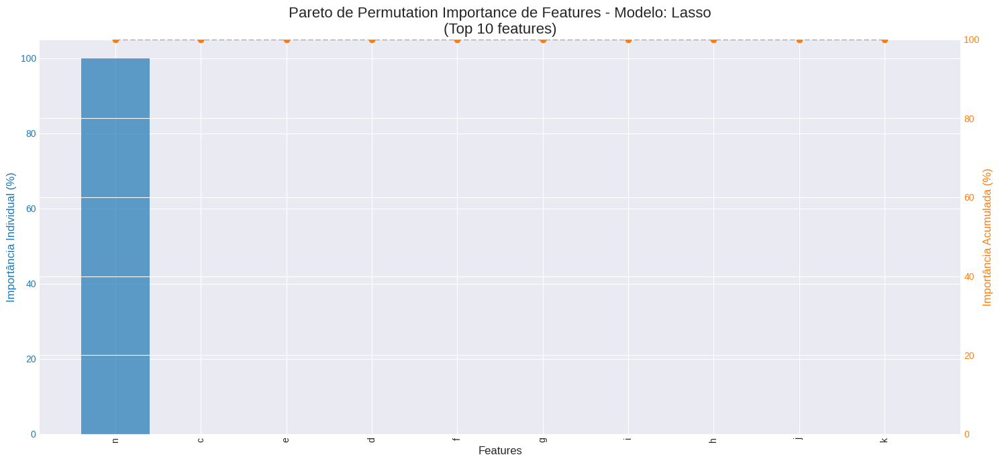


--- Processando Modelo: ElasticNet ---
Calculando Permutation Importance (agnóstico ao modelo)...


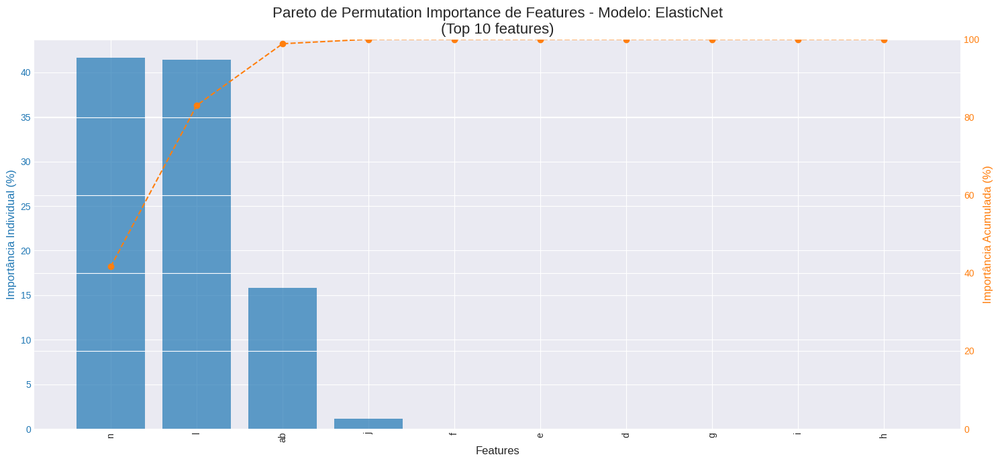


--- Processando Modelo: SGDRegressor ---
Calculando Permutation Importance (agnóstico ao modelo)...


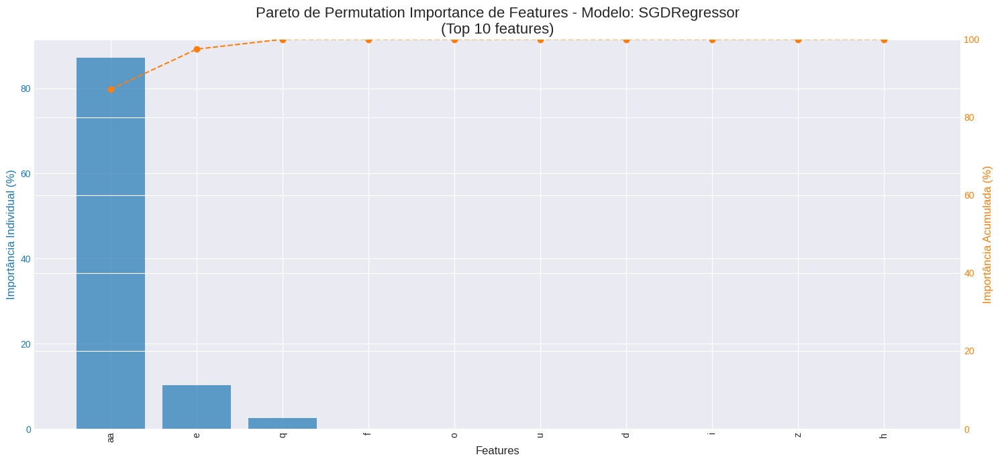


--- Processando Modelo: BayesianRidge ---
Calculando Permutation Importance (agnóstico ao modelo)...


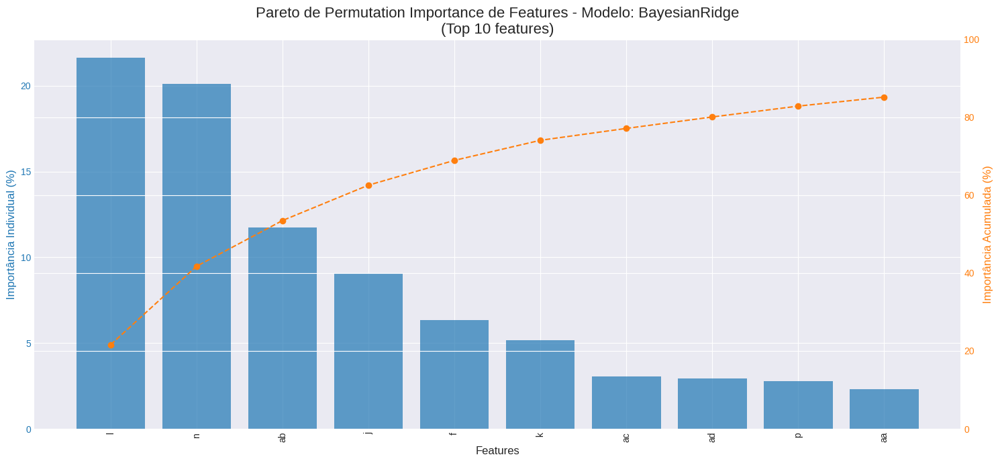


--- Processando Modelo: MLPRegressor ---
Calculando Permutation Importance (agnóstico ao modelo)...


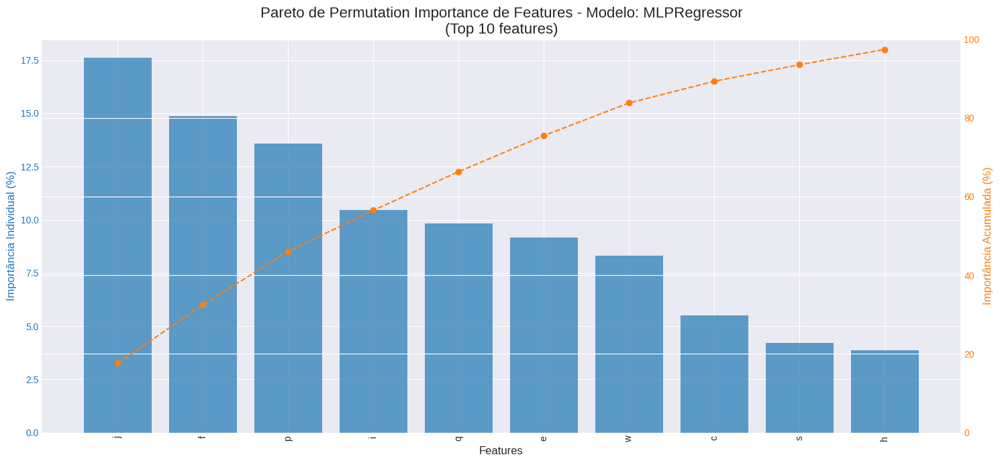


--- Processando Modelo: GPR ---
Calculando Permutation Importance (agnóstico ao modelo)...


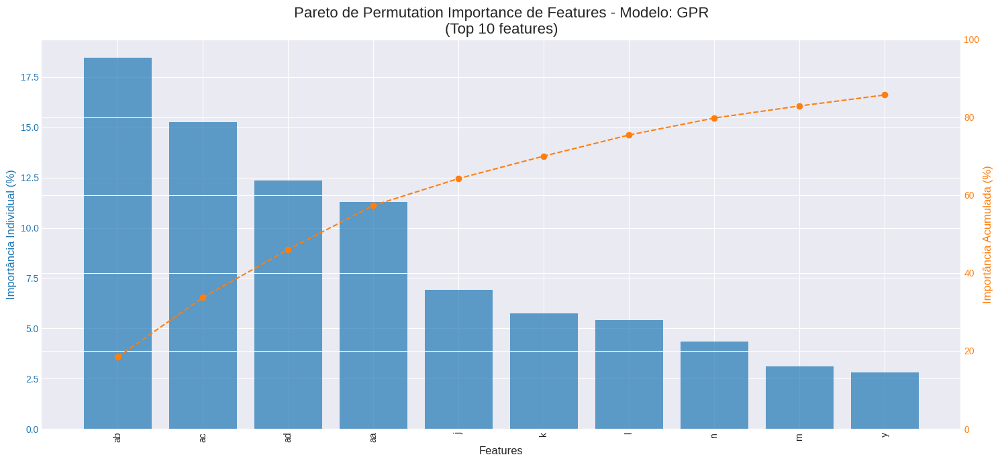


--- Processando Modelo: SVR ---
Calculando Permutation Importance (agnóstico ao modelo)...


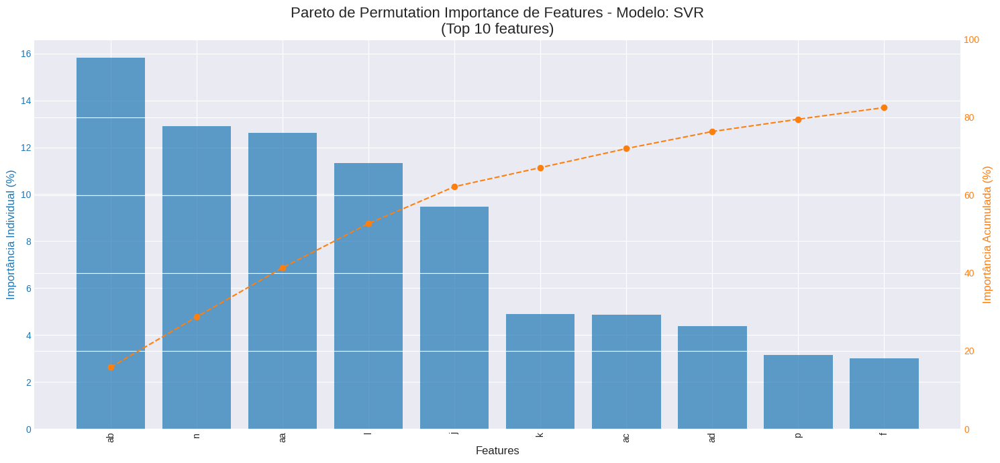


--- Processando Modelo: LinearSVR ---
Calculando Permutation Importance (agnóstico ao modelo)...


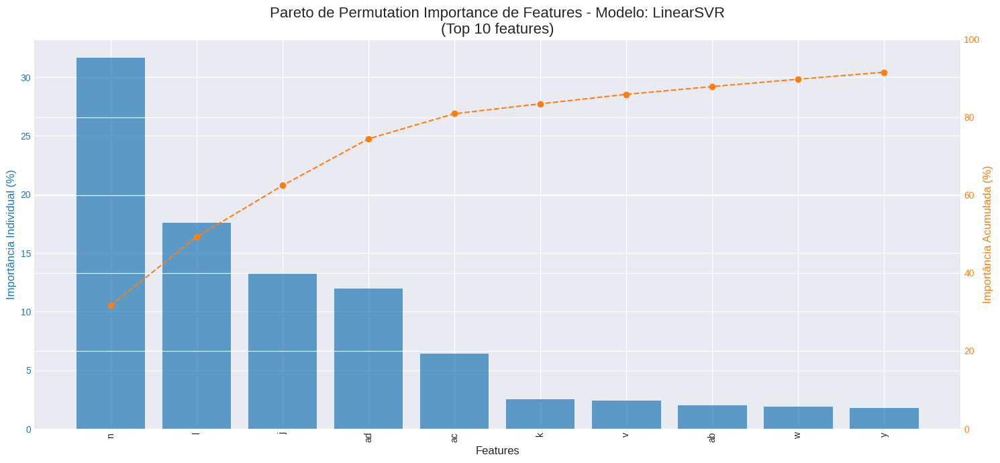


Concluído.


In [180]:
from sklearn.inspection import permutation_importance # Extract feature importance from models in which it is implicit

# --- Settings ---
N_TOP_FEATURES = 10 # How many of the top features you want to show in the chart
plt.style.use('seaborn-v0_8-darkgrid')

print("Iniciando geração de gráficos de importância de features...")

# Main loop over each model
for nome, pipe in pipelines.items():
    print(f"\n--- Processando Modelo: {nome} ---")

    # 1. Train the model on the FULL dataset
    # To obtain the importance, we train on all the data
    try:
        pipe.fit(X, y_all)
    except Exception as e:
        print(f"Erro ao treinar {nome}: {e}")
        continue

    # 2. Extract the feature importances
    # This is complex because of the wrappers and model types
    print("Calculando Permutation Importance (agnóstico ao modelo)...")
    importances = None

    # Take the final step of the pipeline (the model)
    model_step = pipe.named_steps['model']

    try:
        # n_repeats=5 shuffles each feature 5 times to obtain a statistically more stable mean.
        # n_jobs=-1 uses all processors.
        result = permutation_importance(
            pipe,
            X,             # Data on which to compute the importance
            y_all,         # Targets on which to compute the importance
            n_repeats=10,  # Increased for more stability (good for small n)
            random_state=42,
            n_jobs=-1
        )

        # The importance is the mean drop in the score
        importances = result.importances_mean

    except Exception as e:
        print(f"Erro ao calcular Permutation Importance para {nome}: {e}")
        continue

    # 3. Check whether the importance can be extracted
    if importances is None:
        print(f"Modelo {nome} falhou no cálculo de Permutation Importance. Pulando...")
        continue

    # 4. Create the Pareto DataFrame
    feature_names = X.columns

    # Create the DataFrame and sort
    pareto_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    # Compute Individual and Cumulative %
    pareto_df['Importance'] = pareto_df['Importance'].clip(lower=0)

    # Check whether the total sum of the importance is zero
    total_importance = pareto_df['Importance'].sum()
    if total_importance == 0:
        print(f"Modelo {nome} não atribui importância a nenhuma feature (importância total é 0).")
        print("Pulando o gráfico de Pareto...")
        continue

    pareto_df['Importance (%)'] = (pareto_df['Importance'] / pareto_df['Importance'].sum()) * 100
    pareto_df['Cumulative (%)'] = pareto_df['Importance (%)'].cumsum()

    # Keep only the Top N
    pareto_df_top = pareto_df.head(N_TOP_FEATURES)

    # 5. Plot the Pareto Chart
    fig, ax1 = plt.subplots(figsize=(15, 7))

    # Title
    plt.title(f"Pareto de Permutation Importance de Features - Modelo: {nome}\n(Top {N_TOP_FEATURES} features)", fontsize=16)

    # Axis 1: Individual Importance Bars
    color = 'C0'
    ax1.set_xlabel('Features', fontsize=12)
    ax1.set_ylabel(f'Importância Individual (%)', color=color, fontsize=12)
    ax1.bar(pareto_df_top['Feature'], pareto_df_top['Importance (%)'], color=color, alpha=0.7)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.tick_params(axis='x', rotation=90) # Rotate feature names

    # Axis 2: Cumulative Importance Line
    ax2 = ax1.twinx()
    color = 'C1'
    ax2.set_ylabel('Importância Acumulada (%)', color=color, fontsize=12)
    ax2.plot(pareto_df_top['Feature'], pareto_df_top['Cumulative (%)'], color=color, marker='o', linestyle='--')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 100) # A Pareto chart always goes from 0 to 100

    fig.tight_layout() # Adjust layout
    plt.show()

print("\nConcluído.")

Gerando Gráfico de Pareto do PCA...


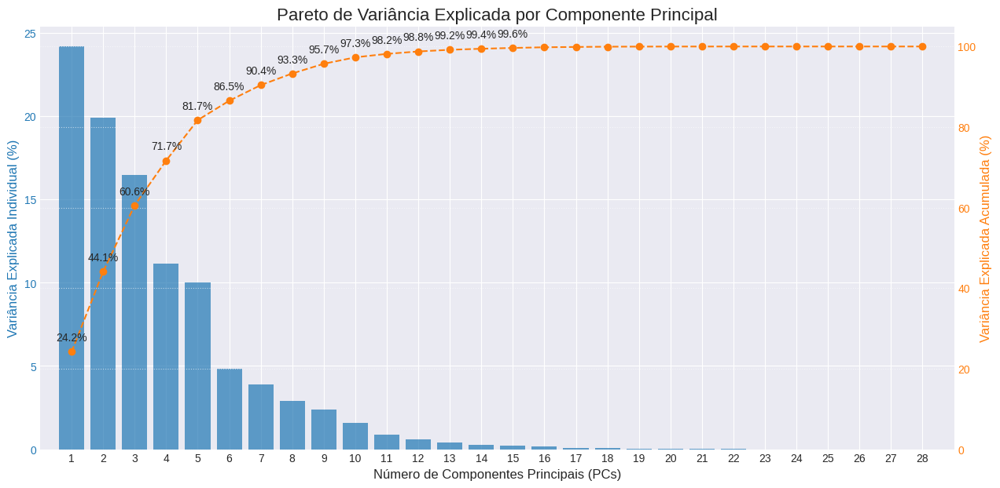

In [181]:
# 1. Prepare the Data for PCA
# It is crucial to scale the data BEFORE applying PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Run PCA
# We instantiate PCA without setting n_components in order to get ALL of them
# so that the variance chart can be analysed
pca = PCA()
pca.fit(X_scaled)

# 3. Compute Explained Variance (Individual and Cumulative)
# Your example code was perfect
explained_variance = pca.explained_variance_ratio_ * 100 # As a percentage
cumulative_variance = np.cumsum(explained_variance)
n_components_total = len(explained_variance)

# 4. Plot the Pareto Chart (your code)
print("Gerando Gráfico de Pareto do PCA...")

fig, ax1 = plt.subplots(figsize=(15, 7))

# Bar chart for the individual variance
ax1.bar(range(1, n_components_total + 1), explained_variance, color='C0', alpha=0.7)
ax1.set_xlabel("Número de Componentes Principais (PCs)", fontsize=12)
ax1.set_ylabel("Variância Explicada Individual (%)", color='C0', fontsize=12)
ax1.tick_params(axis='y', labelcolor='C0')
ax1.set_title("Pareto de Variância Explicada por Componente Principal", fontsize=16)

# Create a secondary Y axis for the cumulative variance
ax2 = ax1.twinx()
ax2.plot(range(1, n_components_total + 1), cumulative_variance, color='C1', marker='o', linestyle='--')
ax2.set_ylabel("Variância Explicada Acumulada (%)", color='C1', fontsize=12)
ax2.tick_params(axis='y', labelcolor='C1')
ax2.set_ylim(0, 105) # Show up to slightly above 100%

# Add percentage labels on the line
for i, txt in enumerate(cumulative_variance):
    # Show labels only for the first 10-15 PCs to avoid clutter
    if i < 15:
        ax2.annotate(f'{txt:.1f}%', (i + 1, txt), textcoords="offset points", xytext=(0, 10), ha='center')

plt.xticks(range(1, n_components_total + 1))
# Limit the X axis to the first 20 or 30 components if you have many
plt.xlim(0, min(n_components_total + 1, 30))

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [182]:
# 1. Number of components in your chart
N_COMPONENTES_ESCOLHIDO = 3

print(f"Iniciando avaliação com PCA (n_components={N_COMPONENTES_ESCOLHIDO})...")

# 2. New pipeline dictionary
pipelines_com_pca = {}

# Native Models (Group 1)
modelos_nativos = {
    'DummyRegressor': DummyRegressor(strategy='mean'),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'RandomForest': RandomForestRegressor(random_state=42),
    'ExtraTrees': ExtraTreesRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42),
    'CatBoost': cb.CatBoostRegressor(random_state=42, verbose=0, loss_function='MultiRMSE'),
    'LinearRegression': LinearRegression(),
    'Lasso': Lasso(random_state=42),
    'ElasticNet': ElasticNet(random_state=42),
    'KNeighbors': KNeighborsRegressor(),
    'MLPRegressor': MLPRegressor(random_state=42, max_iter=1000, early_stopping=True),
    'GPR': GaussianProcessRegressor(kernel=C(1.0) * RBF(1.0), random_state=42, alpha=1e-5)
}

for nome, modelo in modelos_nativos.items():
    pipelines_com_pca[nome] = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=N_COMPONENTES_ESCOLHIDO)),
        ('model', modelo)
    ])


# Models with Wrapper (Group 2)
modelos_wrapper = {
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'LightGBM': lgb.LGBMRegressor(random_state=42, n_estimators=50, min_child_samples=1, n_jobs=1, verbose=-1),
    'SGDRegressor': SGDRegressor(random_state=42),
    'BayesianRidge': BayesianRidge(),
    'SVR': SVR(),
    'LinearSVR': LinearSVR(random_state=42, max_iter=5000, dual=True)
}

for nome, modelo in modelos_wrapper.items():
    pipelines_com_pca[nome] = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=N_COMPONENTES_ESCOLHIDO)),
        ('model', MultiOutputRegressor(modelo))
    ])

print(f"Total de {len(pipelines_com_pca)} pipelines com PCA definidos.")


# 3. Metrics Table
results_list_pca = []
target_names = y_all.columns

# Use X_limpo (it will be scaled and transformed INSIDE the pipeline)
for nome, pipe in pipelines_com_pca.items():
    print(f"Processando: {nome}...")
    try:
        y_pred = cross_val_predict(pipe, X, y_all, cv=cv_obj)

        # Loop to compute metrics for each of the 7 targets
        for i, target in enumerate(target_names):
            y_true_col = y_all.iloc[:, i]
            y_pred_col = y_pred[:, i]

            # Metric calculations filled in
            r2 = r2_score(y_true_col, y_pred_col)
            rmse = np.sqrt(mean_squared_error(y_true_col, y_pred_col))
            mae = mean_absolute_error(y_true_col, y_pred_col)

            results_list_pca.append({
                'Modelo': nome,
                'Target': target,
                'R2': r2,
                'RMSE (pontos SAE)': rmse,
                'MAE (pontos SAE)': mae
            })
    except Exception as e:
        print(f"Erro em {nome}: {e}")

        # Failure result so that the model appears in the table
        results_list_pca.append({
            'Modelo': nome,
            'Target': target_names[0], # For the record only
            'R2': -np.inf,
            'RMSE (pontos SAE)': np.inf,
            'MAE (pontos SAE)': np.inf
        })

# 4. Analyse the results
metrics_df_pca = pd.DataFrame(results_list_pca)
summary_df_pca = metrics_df_pca.groupby('Modelo').mean(numeric_only=True)
summary_df_pca = summary_df_pca.sort_values(by='R2', ascending=False)

print("\n Tabela Resumo (Média das Métricas com PCA)")
print(summary_df_pca)

Iniciando avaliação com PCA (n_components=3)...
Total de 19 pipelines com PCA definidos.
Processando: DummyRegressor...
Processando: DecisionTree...
Processando: RandomForest...
Processando: ExtraTrees...
Processando: XGBoost...
Processando: CatBoost...
Processando: LinearRegression...
Processando: Lasso...
Processando: ElasticNet...
Processando: KNeighbors...
Processando: MLPRegressor...
Processando: GPR...
Processando: GradientBoosting...
Processando: AdaBoost...
Processando: LightGBM...
Processando: SGDRegressor...
Processando: BayesianRidge...
Processando: SVR...
Processando: LinearSVR...

 Tabela Resumo (Média das Métricas com PCA)
                     R2  RMSE (pontos SAE)  MAE (pontos SAE)
Modelo                                                      
BayesianRidge     -0.05               0.37              0.31
Lasso             -0.05               0.37              0.32
DummyRegressor    -0.05               0.37              0.32
ElasticNet        -0.05               0.37        

###**Re-evaluation**

Strategy:

1. Check the performance of the models as Single Output;
2. Check the performance of the models as Single Output with a drastic reduction of the dimensions (the 3 best dimensions for each model);
3. Re-evaluate the performance of the models as Multi Output, but with a reduction of the dimensions (the 3 best dimensions for each model);

In [183]:
# 0. SETUP: IMPORTS AND DATA

from sklearn.feature_selection import SelectFromModel

# --- General Settings ---
warnings.filterwarnings('ignore')
N_FEATURES_DESEJADO = 3

In [184]:
# DATA LOADING AND PREPARATION

# 1. Define X_bruto and y_all
X_bruto = train_df_fteng.drop(['ae','af','ag','ah','ai','aj','ak'], axis=1)
y_all = train_df_fteng[['ae','af','ag','ah','ai','aj','ak']]
target_names = y_all.columns

# 2. Create X_limpo (with One-Hot Encoding)
print("--- Preparando X_limpo (com get_dummies) ---")
colunas_categoricas = X_bruto.select_dtypes(include=['object', 'category']).columns
if not colunas_categoricas.empty:
    print(f"Colunas categóricas encontradas: {list(colunas_categoricas)}")
    X_limpo = pd.get_dummies(X_bruto, columns=colunas_categoricas, drop_first=True)
else:
    print("Nenhuma coluna categórica encontrada.")
    X_limpo = X_bruto

print(f"Dataset pronto. N={len(y_all)} amostras, P={len(X_limpo.columns)} features")

--- Preparando X_limpo (com get_dummies) ---
Nenhuma coluna categórica encontrada.
Dataset pronto. N=32 amostras, P=28 features


In [185]:
# REUSABLE EVALUATION FUNCTION (FOR STEPS 1 AND 2)

def run_single_output_evaluation(pipelines_dict, X, y_all, target_names, cv):
    """
    Runs the evaluation of multiple pipelines on multiple single-output targets.
    Returns a DataFrame of metrics.
    """
    results_list = []

    # OUTER loop: iterates over each target ('ae', 'af', ...)
    for target in target_names:
        print(f"\n--- Avaliando Target: {target} ---")
        y_target = y_all[target] # Take the current target column

        # INNER loop: iterates over each model
        for nome, pipe in pipelines_dict.items():
            try:
                y_pred = cross_val_predict(pipe, X, y_target, cv=cv_obj)

                r2 = r2_score(y_target, y_pred)
                rmse = np.sqrt(mean_squared_error(y_target, y_pred))
                mae = mean_absolute_error(y_target, y_pred)

                results_list.append({
                    'Modelo': nome,
                    'Target': target,
                    'R2': r2,
                    'RMSE': rmse,
                    'MAE': mae
                })
            except Exception as e:
                print(f"!!!!!!!! ERRO ao processar {nome} para {target}: {e} !!!!!!!!")
                results_list.append({
                    'Modelo': nome,
                    'Target': target,
                    'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan
                })

    print("\nFunção de avaliação single-output concluída.")
    return pd.DataFrame(results_list)

In [186]:
# STEP 1: Single Output (All Features)

print("\n" + "="*50)
print("INICIANDO PASSO 1: Single Output (Todas as Features)")
print("="*50)

def define_pipelines_step1():
    """
    Defines pipelines for SINGLE-OUTPUT.
    NO MultiOutputRegressor is used.
    """
    pipelines_s1 = {}

# --- Group 1: Trees (No Scaler) ---
    pipelines_s1['DummyRegressor'] = Pipeline([('model', DummyRegressor(strategy='mean'))])
    pipelines_s1['DecisionTree'] = Pipeline([('model', DecisionTreeRegressor(random_state=42))])
    pipelines_s1['RandomForest'] = Pipeline([('model', RandomForestRegressor(random_state=42))])
    pipelines_s1['ExtraTrees'] = Pipeline([('model', ExtraTreesRegressor(random_state=42))])
    pipelines_s1['GradientBoosting'] = Pipeline([('model', GradientBoostingRegressor(random_state=42))])
    pipelines_s1['AdaBoost'] = Pipeline([('model', AdaBoostRegressor(random_state=42))])
    pipelines_s1['XGBoost'] = Pipeline([('model', xgb.XGBRegressor(random_state=42, eval_metric='rmse'))])
    pipelines_s1['LightGBM'] = Pipeline([('model', lgb.LGBMRegressor(random_state=42, verbose=-1))])
    pipelines_s1['CatBoost'] = Pipeline([('model', cb.CatBoostRegressor(random_state=42, verbose=0))])

    # --- Group 2: Distance/Gradient (With RobustScaler) ---
    pipelines_s1['LinearRegression'] = Pipeline([('scaler', RobustScaler()), ('model', LinearRegression())])
    pipelines_s1['Lasso'] = Pipeline([('scaler', RobustScaler()), ('model', Lasso(random_state=42))])
    pipelines_s1['ElasticNet'] = Pipeline([('scaler', RobustScaler()), ('model', ElasticNet(random_state=42))])
    pipelines_s1['KNeighbors'] = Pipeline([('scaler', RobustScaler()), ('model', KNeighborsRegressor())])
    pipelines_s1['SVR'] = Pipeline([('scaler', RobustScaler()), ('model', SVR())])
    pipelines_s1['LinearSVR'] = Pipeline([('scaler', RobustScaler()), ('model', LinearSVR(random_state=42, max_iter=5000))])
    pipelines_s1['SGDRegressor'] = Pipeline([('scaler', RobustScaler()), ('model', SGDRegressor(random_state=42))])
    pipelines_s1['BayesianRidge'] = Pipeline([('scaler', RobustScaler()), ('model', BayesianRidge())])
    pipelines_s1['MLPRegressor'] = Pipeline([('scaler', RobustScaler()), ('model', MLPRegressor(random_state=42, max_iter=1000, early_stopping=True))])

    kernel_gpr = C(1.0) * RBF(1.0)
    pipelines_s1['GPR'] = Pipeline([('scaler', RobustScaler()), ('model', GaussianProcessRegressor(kernel=kernel_gpr, random_state=42, alpha=1e-5))])

    return pipelines_s1

# --- Running Step 1 ---
pipelines_s1 = define_pipelines_step1()
metrics_df_s1 = run_single_output_evaluation(pipelines_s1, X_limpo, y_all, target_names, cv=cv_obj)

print("\nRESULTADO PASSO 1: Resumo (Média das Métricas por Modelo)")
summary_s1 = metrics_df_s1.groupby('Modelo').mean(numeric_only=True).sort_values(by='R2', ascending=False)
print(summary_s1)


INICIANDO PASSO 1: Single Output (Todas as Features)

--- Avaliando Target: ae ---

--- Avaliando Target: af ---

--- Avaliando Target: ag ---

--- Avaliando Target: ah ---

--- Avaliando Target: ai ---

--- Avaliando Target: aj ---

--- Avaliando Target: ak ---

Função de avaliação single-output concluída.

RESULTADO PASSO 1: Resumo (Média das Métricas por Modelo)
                                           R2            RMSE             MAE
Modelo                                                                       
DummyRegressor                          -0.05            0.37            0.32
LightGBM                                -0.05            0.37            0.32
Lasso                                   -0.09            0.38            0.32
ElasticNet                              -0.10            0.38            0.33
BayesianRidge                           -0.11            0.38            0.33
RandomForest                            -0.14            0.38            0.32
KNeighb

In [187]:
# STEP 2: Single Output (Top 3 Features)

print("\n" + "="*50)
print(f"INICIANDO PASSO 2: Single Output (Top {N_FEATURES_DESEJADO} Features)")
print("="*50)

def define_pipelines_step2(n_features):
    """
    Defines pipelines for SINGLE-OUTPUT with SelectFromModel.
    Uses different selectors for trees vs. linear models.
    """
    pipelines_s2 = {}

    # Estimators for Selection
    # For Trees: Tree estimator
    selector_tree = SelectFromModel(
        RandomForestRegressor(random_state=42, n_estimators=50), # Lighter RF for selection
        max_features=n_features,
        prefit=False
    )
    # For Linear/Scalers: Linear estimator
    # Note: the linear selector is also placed after the scaler
    selector_linear = SelectFromModel(
        LinearRegression(), # Use .coef_
        max_features=n_features,
        prefit=False
    )

    # Group 1: Trees (No Scaler, with Tree Selector)
    pipelines_s2['DummyRegressor'] = Pipeline([('model', DummyRegressor(strategy='mean'))]) # No selection
    pipelines_s2['DecisionTree_Top3'] = Pipeline([('selector', selector_tree), ('model', DecisionTreeRegressor(random_state=42))])
    pipelines_s2['RandomForest_Top3'] = Pipeline([('selector', selector_tree), ('model', RandomForestRegressor(random_state=42))])
    pipelines_s2['ExtraTrees_Top3'] = Pipeline([('selector', selector_tree), ('model', ExtraTreesRegressor(random_state=42))])
    pipelines_s2['GradientBoosting_Top3'] = Pipeline([('selector', selector_tree), ('model', GradientBoostingRegressor(random_state=42))])
    pipelines_s2['AdaBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', AdaBoostRegressor(random_state=42))])
    pipelines_s2['XGBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', xgb.XGBRegressor(random_state=42, eval_metric='rmse'))])
    pipelines_s2['LightGBM_Top3'] = Pipeline([('selector', selector_tree), ('model', lgb.LGBMRegressor(random_state=42, verbose=-1))])
    pipelines_s2['CatBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', cb.CatBoostRegressor(random_state=42, verbose=0))])

    # Group 2: Distance/Gradient (With Scaler and Linear Selector)
    pipelines_s2['LinearRegression_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', LinearRegression())])
    pipelines_s2['Lasso_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', Lasso(random_state=42))])
    pipelines_s2['ElasticNet_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', ElasticNet(random_state=42))])
    pipelines_s2['KNeighbors_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', KNeighborsRegressor())])
    pipelines_s2['SVR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', SVR())])
    pipelines_s2['LinearSVR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', LinearSVR(random_state=42, max_iter=5000))])
    pipelines_s2['SGDRegressor_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', SGDRegressor(random_state=42))])
    pipelines_s2['BayesianRidge_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', BayesianRidge())])
    pipelines_s2['MLPRegressor_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', MLPRegressor(random_state=42, max_iter=1000, early_stopping=True))])
    pipelines_s2['GPR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector_linear), ('model', GaussianProcessRegressor(kernel=C(1.0) * RBF(1.0), random_state=42, alpha=1e-5))])

    return pipelines_s2

# Running Step 2
pipelines_s2 = define_pipelines_step2(n_features=N_FEATURES_DESEJADO)
print(f"{len(pipelines_s2)} pipelines definidos para o Passo 2.")
metrics_df_s2 = run_single_output_evaluation(pipelines_s2, X_limpo, y_all, target_names, cv=cv_obj)

print("\nRESULTADO PASSO 2: Resumo (Média das Métricas por Modelo)")
summary_s2 = metrics_df_s2.groupby('Modelo').mean(numeric_only=True).sort_values(by='R2', ascending=False)
print(summary_s2)


INICIANDO PASSO 2: Single Output (Top 3 Features)
19 pipelines definidos para o Passo 2.

--- Avaliando Target: ae ---

--- Avaliando Target: af ---

--- Avaliando Target: ag ---

--- Avaliando Target: ah ---

--- Avaliando Target: ai ---

--- Avaliando Target: aj ---

--- Avaliando Target: ak ---

Função de avaliação single-output concluída.

RESULTADO PASSO 2: Resumo (Média das Métricas por Modelo)
                           R2  RMSE  MAE
Modelo                                  
BayesianRidge_Top3      -0.00  0.36 0.31
ElasticNet_Top3         -0.05  0.37 0.32
DummyRegressor          -0.05  0.37 0.32
Lasso_Top3              -0.05  0.37 0.32
LightGBM_Top3           -0.05  0.37 0.32
KNeighbors_Top3         -0.10  0.38 0.31
SVR_Top3                -0.19  0.39 0.32
RandomForest_Top3       -0.26  0.40 0.33
LinearSVR_Top3          -0.35  0.42 0.33
AdaBoost_Top3           -0.40  0.42 0.34
LinearRegression_Top3   -0.42  0.42 0.33
ExtraTrees_Top3         -0.50  0.44 0.35
SGDRegressor_Top3    

In [188]:
# STEP 3: Multi-Output (Top 3 Features)

print("\n" + "="*50)
print(f"INICIANDO PASSO 3: Multi-Output (Top {N_FEATURES_DESEJADO} Features)")
print("="*50)

def define_pipelines_step3(n_features):
    """
    Defines pipelines for MULTI-OUTPUT with SelectFromModel.
    Uses MultiOutputRegressor where necessary.
    Uses a single (RF-based) selector for all models.
    """
    pipelines_s3 = {}

    # --- Estimator for Selection ---
    # RandomForestRegressor (native multi-output) to select the features that are, on average, the best for ALL targets
    selector = SelectFromModel(
        RandomForestRegressor(random_state=42, n_estimators=50),
        max_features=n_features,
        prefit=False
    )

    # Group 1: Trees (No Scaler, with Selector)
    pipelines_s3['DummyRegressor'] = Pipeline([('model', DummyRegressor(strategy='mean'))]) # No selection
    pipelines_s3['DecisionTree_Top3'] = Pipeline([('selector', selector), ('model', DecisionTreeRegressor(random_state=42))])
    pipelines_s3['RandomForest_Top3'] = Pipeline([('selector', selector), ('model', RandomForestRegressor(random_state=42))])
    pipelines_s3['ExtraTrees_Top3'] = Pipeline([('selector', selector), ('model', ExtraTreesRegressor(random_state=42))])
    pipelines_s3['GradientBoosting_Top3'] = Pipeline([('selector', selector), ('model', MultiOutputRegressor(GradientBoostingRegressor(random_state=42)))])
    pipelines_s3['AdaBoost_Top3'] = Pipeline([('selector', selector), ('model', MultiOutputRegressor(AdaBoostRegressor(random_state=42)))])
    pipelines_s3['XGBoost_Top3'] = Pipeline([('selector', selector), ('model', xgb.XGBRegressor(random_state=42))]) # XGB is native
    pipelines_s3['LightGBM_Top3'] = Pipeline([('selector', selector), ('model', MultiOutputRegressor(lgb.LGBMRegressor(random_state=42, verbose=-1)))])
    pipelines_s3['CatBoost_Top3'] = Pipeline([('selector', selector), ('model', cb.CatBoostRegressor(random_state=42, verbose=0, loss_function='MultiRMSE'))]) # CatBoost is native

    # Group 2: Distance/Gradient (With Scaler and Selector)
    pipelines_s3['LinearRegression_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', LinearRegression())])
    pipelines_s3['Lasso_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', Lasso(random_state=42))])
    pipelines_s3['ElasticNet_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', ElasticNet(random_state=42))])
    pipelines_s3['KNeighbors_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', KNeighborsRegressor())])
    pipelines_s3['SVR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', MultiOutputRegressor(SVR()))])
    pipelines_s3['LinearSVR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', MultiOutputRegressor(LinearSVR(random_state=42, max_iter=5000)))])
    pipelines_s3['SGDRegressor_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', MultiOutputRegressor(SGDRegressor(random_state=42)))])
    pipelines_s3['BayesianRidge_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', MultiOutputRegressor(BayesianRidge()))])
    pipelines_s3['MLPRegressor_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', MLPRegressor(random_state=42, max_iter=1000, early_stopping=True))])
    pipelines_s3['GPR_Top3'] = Pipeline([('scaler', RobustScaler()), ('selector', selector), ('model', GaussianProcessRegressor(kernel=C(1.0) * RBF(1.0), random_state=42, alpha=1e-5))])

    return pipelines_s3

def run_multi_output_evaluation(pipelines_dict, X, y_all, target_names, cv):
    """
    Runs the evaluation of multiple pipelines in MULTI-OUTPUT mode.
    Prints metrics and plots (your original Phase 1 code).
    Returns a detailed DataFrame of metrics.
    """
    results_list = []

    for nome, pipe in pipelines_dict.items():
        print(f"Avaliando Modelo: {nome}")

        try:
            y_pred = cross_val_predict(pipe, X, y_all, cv=cv_obj)

            # Compute Aggregated Mean R²
            r2_medio = r2_score(y_all, y_pred, multioutput='uniform_average')
            print(f"R² Médio (Média dos 7 outputs): {r2_medio:.4f}\n")

            print("Relatório de Métricas Detalhado (por Output)")
            y_true_cols = []
            y_pred_cols = []

            for i, target in enumerate(target_names):
                y_true_col = y_all.iloc[:, i]
                y_pred_col = y_pred[:, i]

                y_true_cols.append(y_true_col)
                y_pred_cols.append(y_pred_col)

                r2 = r2_score(y_true_col, y_pred_col)
                rmse = np.sqrt(mean_squared_error(y_true_col, y_pred_col))
                mae = mean_absolute_error(y_true_col, y_pred_col)

                results_list.append({
                    'Modelo': nome, 'Target': target,
                    'R2': r2, 'RMSE': rmse, 'MAE': mae
                })

                print(f"\nTarget: '{target}'")
                print(f"  R² Score: {r2:8.4f}")
                print(f"  RMSE:     {rmse:8.4f}")
                print(f"  MAE:      {mae:8.4f}")

            # Plot Actual vs. Predicted Charts
            print(f"\n Plotando Gráficos Real vs. Previsto para {nome}")
            n_outputs = len(target_names)
            n_cols = 3
            n_rows = (n_outputs + n_cols - 1) // n_cols
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
            fig.suptitle(f"Real vs. Previsto para: {nome}", fontsize=16)
            axes = axes.flatten()

            for i, target in enumerate(target_names):
                ax = axes[i]
                y_t, y_p = y_true_cols[i], y_pred_cols[i]

                sns.scatterplot(x=y_t, y=y_p, ax=ax, alpha=0.6)
                ax.set_title(f"Target: '{target}'")
                ax.set_xlabel("Valores Reais"); ax.set_ylabel("Valores Previstos")

                min_val = min(y_t.min(), y_p.min()) * 0.95
                max_val = max(y_t.max(), y_p.max()) * 1.05
                ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)
                ax.set_xlim(min_val, max_val); ax.set_ylim(min_val, max_val)

            for i in range(n_outputs, len(axes)): axes[i].axis('off')
            plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.show()

        except Exception as e:
            print(f"NÃO FOI POSSÍVEL AVALIAR O MODELO {nome}")
            print(f"Erro: {e}")
            for target in target_names:
                results_list.append({
                    'Modelo': nome, 'Target': target,
                    'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan
                })

    return pd.DataFrame(results_list)

# Running Step 3
pipelines_s3 = define_pipelines_step3(n_features=N_FEATURES_DESEJADO)
print(f"{len(pipelines_s3)} pipelines definidos para o Passo 3.")
metrics_df_s3 = run_multi_output_evaluation(pipelines_s3, X_limpo, y_all, target_names, cv=cv_obj)

print("\n RESULTADO PASSO 3: Resumo (Média das Métricas por Modelo)")
summary_s3 = metrics_df_s3.groupby('Modelo').mean(numeric_only=True).sort_values(by='R2', ascending=False)
print(summary_s3)

print("\n" + "="*50)
print("AVALIAÇÃO EM 3 PASSOS CONCLUÍDA")
print("="*50)

Output hidden; open in https://colab.research.google.com to view.

**Conclusions for the Regression Problem:**
- Single Output (All Features) performance very close to Multi Output (All Features)
- Single Output (3 Features) performance very close to Multi Output (3 Features)
The problem is that the sample size is 32

##**10 - Feature Engineering - Classification Problem**

**Next steps:**
To try to extract a little more performance from these models, transform the numerical data of the target variables into categorical data, thereby turning a regression problem into a classification problem, and check with the corresponding models whether they perform better than regression.

In [189]:
train_df.head()

Letter,a,b,c,d,e,f,g,h,i,j,...,ad,ae,af,ag,ah,ai,aj,ak,Category,Brand
0,M000,0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,...,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00,SUV,Citroën
1,M001,1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,...,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75,SUV,Citroën
2,M002,2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,...,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25,SUV,Citroën
3,M005,3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,...,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50,SUV,Jeep
4,M013,4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,...,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75,SUV,Citroën


In [190]:
train_df_fteng_classifier = train_df.copy()
train_df_fteng_classifier = train_df_fteng_classifier.drop(columns=['a','b','Category','Brand'])
train_df_fteng_classifier.head()

Letter,c,d,e,f,g,h,i,j,k,l,...,ab,ac,ad,ae,af,ag,ah,ai,aj,ak
0,0.46,0.13,1.18,0.16,0.39,0.79,0.31,0.13,0.71,0.19,...,-914.08,-1046.96,-740.91,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,0.45,0.13,1.20,0.17,0.38,0.78,0.32,0.13,0.72,0.19,...,-909.86,-1047.92,-738.95,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,0.45,0.13,1.21,0.16,0.37,0.79,0.31,0.13,0.73,0.19,...,-912.63,-1035.19,-727.42,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,0.47,0.13,1.03,0.14,0.45,0.92,0.34,0.13,0.72,0.19,...,-906.35,-1049.76,-746.75,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,0.47,0.13,1.21,0.17,0.39,0.79,0.29,0.09,0.74,0.19,...,-916.89,-1045.62,-742.34,7.50,7.50,7.25,7.50,7.00,7.50,6.75


###**Discretisation of Objective Variable Features**

In [191]:
# 1. Identify the columns you want to transform
try:
    cols_to_bin = train_df_fteng_classifier.loc[:, 'c':'ad'].columns
    print(f"Colunas a serem binarizadas: {list(cols_to_bin)}")
except KeyError:
    print("Erro: Verifique se as colunas 'C' e 'AD' existem no seu DataFrame.")
    cols_to_bin = []

# 2. Create the empty Lookup Table
df_classificado = train_df_fteng_classifier.copy()
lookup_dict = {}
colunas_com_problemas = []

print(f"Iniciando binarização e criação da tabela de lookup para {len(cols_to_bin)} features...")

# 3. Iterate and apply the transformation
print("\nIniciando binarização por quartil e criação da tabela de lookup...")

for col in cols_to_bin:
    bin_faixas = {}
    try:
        # STEP A: Find the bin edges

        # Try to apply pd.qcut q=4 quartiles
        _, bin_edges = pd.qcut(train_df_fteng_classifier[col],
                                     q=4,
                                     duplicates='drop',
                                     retbins=True, # Return the bin edges
                                     precision=2)

        # STEP B: Create the Classified DataFrame
        n_bins_criados = len(bin_edges) - 1
        labels_criados = list(range(n_bins_criados)) # e.g.: [0, 1, 2, 3] or [0, 1, 2, 3, 4]

        df_classificado[col] = pd.cut(train_df_fteng_classifier[col],
                                                bins=bin_edges,
                                                labels=labels_criados,
                                                include_lowest=True, # Ensures the smallest value is included
                                                duplicates='drop')

        # STEP C: Create the Lookup Table
        ranges = pd.IntervalIndex.from_breaks(bin_edges, closed='right')

        # Fill bin_faixas with the bins
        for i, interval in enumerate(ranges):
            bin_faixas[i] = str(interval)

    except Exception as e:
        # Catch errors other than the binning one
        print(f"Aviso ao processar a coluna '{col}': {e}.")
        colunas_com_problemas.append(col)
        n_unicos = train_df_fteng_classifier[col].nunique()

        if n_unicos == 1:
            val = train_df_fteng_classifier[col].unique()[0]
            print(f"Info '{col}': Coluna é constante (valor={val}). Atribuindo ao bin 0.")
            # Update bin_faixas (dictionary)
            bin_faixas[0] = f"Valor Constante [{val}]"
            # Update the main DataFrame
            df_classificado[col] = 0
        else:
            print(f"!!! Erro ao processar '{col}' (com {n_unicos} únicos): {e}. Atribuindo 0.")
            bin_faixas[0] = "Erro no processamento"
            df_classificado[col] = 0

    # Add this column's bin map to the main dictionary
    lookup_dict[col] = bin_faixas

if not colunas_com_problemas:
    print("\nBinarização concluída com sucesso para todas as colunas!")
else:
    print(f"\nBinarização concluída, mas as colunas {colunas_com_problemas} falharam.")

Colunas a serem binarizadas: ['c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'aa', 'ab', 'ac', 'ad']
Iniciando binarização e criação da tabela de lookup para 28 features...

Iniciando binarização por quartil e criação da tabela de lookup...

Binarização concluída com sucesso para todas as colunas!


In [192]:
#HTML dynamic table visualisation

from IPython.display import display, HTML

# 1. Convert the lookup dictionary into a DataFrame
lookup_table = pd.DataFrame.from_dict(lookup_dict, orient='index')
lookup_table = lookup_table.fillna("NA") # Fill 'NaN' with 'NA'

# Style the lookup table for better visualisation
lookup_style = lookup_table.style.set_caption("Tabela de Lookup (Legenda das Faixas)") \
                                 .set_properties(**{'text-align': 'left', 'border': '1px solid #ddd'}) \
                                 .set_table_styles([
                                     {'selector': 'th', 'props': [('text-align', 'left'), ('background-color', '#0f0f0f')]},
                                     {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]}
                                 ])
# display() renders the formatted HTML object in the notebook console
display(lookup_style)

# Take the example
exemplo_df = df_classificado.loc[:, cols_to_bin].head()

print("\n")
# Style the example table
exemplo_style = exemplo_df.style.set_caption("Exemplo do DataFrame Classificado (Primeiras 5 linhas)") \
                                .set_properties(**{'text-align': 'center', 'border': '1px solid #ddd'}) \
                                .set_table_styles([
                                    {'selector': 'th', 'props': [('text-align', 'center'), ('background-color', '#0f0f0f')]},
                                    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]}
                                ])

display(exemplo_style)

,0,1,2,3
c,"(0.395, 0.434]","(0.434, 0.4495]","(0.4495, 0.45775]","(0.45775, 0.58]"
d,"(0.083, 0.093]","(0.093, 0.13]","(0.13, 0.193]",NA
e,"(1.027, 1.18575]","(1.18575, 1.21]","(1.21, 1.2295]","(1.2295, 1.439]"
f,"(0.119, 0.164]","(0.164, 0.1655]","(0.1655, 0.17200000000000001]","(0.17200000000000001, 0.218]"
g,"(0.289801908, 0.359271523]","(0.359271523, 0.3687211125]","(0.3687211125, 0.38779661425]","(0.38779661425, 0.452775073]"
h,"(0.399082569, 0.543859649]","(0.543859649, 0.78313253]","(0.78313253, 0.792682927]","(0.792682927, 1.621848739]"
i,"(0.279, 0.312]","(0.312, 0.314]","(0.314, 0.34]","(0.34, 0.387]"
j,"(0.076, 0.126]","(0.126, 0.13]","(0.13, 0.178]",NA
k,"(0.637, 0.71575]","(0.71575, 0.721]","(0.721, 0.736]","(0.736, 0.88]"
l,"(0.106, 0.1895]","(0.1895, 0.193]","(0.193, 0.195]","(0.195, 0.255]"


Letter,c,d,e,f,g,h,i,j,k,l,m,n,o,p,q,r,s,t,u,v,w,x,y,z,aa,ab,ac,ad
0,3,1,0,0,3,2,1,1,0,2,2,2,0,1,2,2,0,1,0,0,2,1,1,1,2,1,1,2
1,2,1,1,2,2,1,2,1,2,2,2,2,2,2,1,1,2,2,3,2,1,1,0,1,2,2,1,2
2,1,1,2,0,2,2,1,1,2,1,0,3,3,0,2,3,2,1,2,0,2,1,1,2,2,2,2,3
3,3,2,0,0,3,3,2,1,1,0,3,3,2,3,0,1,0,0,1,1,3,3,2,2,3,3,0,0
4,3,1,1,1,3,2,0,0,3,0,0,0,0,3,2,2,0,0,0,0,1,1,0,1,1,1,1,1


###**Discretisation of Subjective Variable Features**

In [193]:
df_classificado.head()

Letter,c,d,e,f,g,h,i,j,k,l,...,ab,ac,ad,ae,af,ag,ah,ai,aj,ak
0,3,1,0,0,3,2,1,1,0,2,...,1,1,2,7.00,7.00,7.00,7.00,7.00,7.00,7.00
1,2,1,1,2,2,1,2,1,2,2,...,2,1,2,6.75,7.25,7.00,6.75,7.50,6.75,6.75
2,1,1,2,0,2,2,1,1,2,1,...,2,2,3,6.75,6.75,6.75,6.25,6.75,6.75,6.25
3,3,2,0,0,3,3,2,1,1,0,...,3,0,0,7.75,7.25,7.50,7.25,7.25,7.50,7.50
4,3,1,1,1,3,2,0,0,3,0,...,1,1,1,7.50,7.50,7.25,7.50,7.00,7.50,6.75


In [194]:
#1. Define the Bin Edges and Labels
print(f"Iniciando discretização de {len(y_all.columns)} colunas de target...")

# Bins (Edges):
#   1. (-inf, <7.0)   -> 'Regular'
#   2. [7.0, 7.5]     -> 'Bom'
#   3. (7.5, +inf)   -> 'Ótimo'

bins = [
    -np.inf,                      # Lower bound
    np.nextafter(7.0, -np.inf), # < 7.0
    7.5,                          # <= 7.5
    np.inf                        # Upper bound
]

# Labels for the bins
labels = ['Regular', 'Bom', 'Ótimo']

# 2. Identify the target columns
target_cols = ['ae', 'af', 'ag', 'ah', 'ai', 'aj', 'ak']

# 3. Apply the Transformation (pd.cut)
for col in target_cols:
    if col in df_classificado.columns:
        try:
            # pd.cut reads the continuous value of each column and replaces it with the label ('Regular', 'Bom', 'Ótimo')
            df_classificado[col] = pd.cut(df_classificado[col],
                                         bins=bins,
                                         labels=labels,
                                         right=True)
        except Exception as e:
            print(f"Erro ao processar a coluna '{col}': {e}")
            print("Certifique-se de que esta célula só é executada UMA VEZ.")
    else:
        print(f"Aviso: Coluna target '{col}' não encontrada em 'df_classificado'.")

print("Discretização dos targets concluída.")

# 4. Check the Result
print("\nResultado da Discretização:")
display(df_classificado.head())

print("\n--- Distribuição das Novas Classes (Ex: Target 'ae') ---")
if 'ae' in df_classificado:
    print(df_classificado['ae'].value_counts())

Iniciando discretização de 7 colunas de target...
Discretização dos targets concluída.

Resultado da Discretização:


Letter,c,d,e,f,g,h,i,j,k,l,...,ab,ac,ad,ae,af,ag,ah,ai,aj,ak
0,3,1,0,0,3,2,1,1,0,2,...,1,1,2,Bom,Bom,Bom,Bom,Bom,Bom,Bom
1,2,1,1,2,2,1,2,1,2,2,...,2,1,2,Regular,Bom,Bom,Regular,Bom,Regular,Regular
2,1,1,2,0,2,2,1,1,2,1,...,2,2,3,Regular,Regular,Regular,Regular,Regular,Regular,Regular
3,3,2,0,0,3,3,2,1,1,0,...,3,0,0,Ótimo,Bom,Bom,Bom,Bom,Bom,Bom
4,3,1,1,1,3,2,0,0,3,0,...,1,1,1,Bom,Bom,Bom,Bom,Bom,Bom,Regular



--- Distribuição das Novas Classes (Ex: Target 'ae') ---
ae
Bom        20
Regular    11
Ótimo       1
Name: count, dtype: int64


##**11 - Machine Learning - Classification Problem**

In [195]:
from sklearn.pipeline import Pipeline #Organisation, Flow and Avoiding Data Leakage

# Model Imports
from sklearn.dummy import DummyClassifier # Dummy classification algorithm
from sklearn.linear_model import LogisticRegression, SGDClassifier # Logistic Regression algorithm, Stochastic Gradient Descent Classification
from sklearn.tree import DecisionTreeClassifier # Decision tree algorithm
from sklearn.neighbors import KNeighborsClassifier # K-nearest neighbours classification algorithm
from sklearn.svm import SVC, LinearSVC # Support Vector Machine classification algorithm
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, AdaBoostClassifier # Random Forest algorithm; Gradient Descent; Random split selection; +Weight on Residual Errors
from sklearn.neural_network import MLPClassifier # Multi-layer Perceptron algorithm - scikit-learn's standard neural network, essential to check whether non-linear patterns exist
from sklearn.gaussian_process import GaussianProcessClassifier # Gaussian Process classification algorithm
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C # Kernel for the GPR
from sklearn.naive_bayes import GaussianNB, BernoulliNB # Naive Bayes classification algorithm | Bernoulli
import xgboost as xgb # XGBoost algorithm
import lightgbm as lgb # LightGBM algorithm (developed by Microsoft; grows trees leaf-wise instead of level-wise - usually leads to better convergence and accuracy)
import catboost as cb # CatBoost algorithm (developed by Yandex; native handling of categorical features without one-hot/label encoding; better performance without hyperparameter tuning)

###**Multi-Output Learning: Strategy and Definitions**

**Group 1:** Algorithms that natively support Multi-Output:
* DummyClassifier
* DecisionTreeClassifier
* KNeighborsClassifier
* RandomForestClassifier
* ExtraTreesClassifier
* GaussianProcessClassifier

**Group 2:** Algorithms that do not natively support Multi-Output (chosen strategy: **Wrapper**)
* LogisticRegression
* Lasso (derived from LogisticRegression(penalty='l1', solver='liblinear' or 'saga'))
* ElasticNet (derived from LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5))
* SGDClassifier
* SVC
* LinearSVC
* BernoulliNB
* GradientBoostingClassifier
* MLPClassifier (Neural Networks)
* GaussianProcessClassifier (GPC)
* XGBoost (XGBClassifier)
* CatBoostClassifier (using loss_function='MultiCrossEntropy')
* AdaBoostClassifier
* LightGBM (LGBMClassifier)

In [196]:
# Evaluation Tools and Metrics
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, LeaveOneOut, train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Splitting the training data into X: features and y: target
cols_targets = ['ae', 'af', 'ag', 'ah', 'ai', 'aj', 'ak']
y_class_all = df_classificado[cols_targets]
class_labels = ['Regular', 'Bom', 'Ótimo']
n_targets = y_class_all.shape[1] # Should be 7

# Encoder that knows the order of the 7 columns
encoder = OrdinalEncoder(categories=[class_labels] * n_targets)

# New y_class_all_numeric
y_class_numeric = encoder.fit_transform(y_class_all).astype(int)

# Definition of the individual targets (1D Series with classes)
y_class_ae = y_class_all['ae']
y_class_af = y_class_all['af']
y_class_ag = y_class_all['ag']
y_class_ah = y_class_all['ah']
y_class_ai = y_class_all['ai']
y_class_aj = y_class_all['aj']
y_class_ak = y_class_all['ak']

# Creation of individual targets for class_numeric
y_class_ae_num = y_class_numeric[:, 0]
y_class_af_num = y_class_numeric[:, 1]
y_class_ag_num = y_class_numeric[:, 2]
y_class_ah_num = y_class_numeric[:, 3]
y_class_ai_num = y_class_numeric[:, 4]
y_class_aj_num = y_class_numeric[:, 5]
y_class_ak_num = y_class_numeric[:, 6]

print(f"y (targets) de classificação criado. Shape: {y_class_all.shape}")
print(f"Exemplo de y (target 'ae'):\n {y_class_ae.value_counts().head()}")

print(f"\ny_class_numeric (para XGB/CatBoost) criado. Shape: {y_class_numeric.shape}")
print(f"Tipo de dados: {y_class_numeric.dtype}")

# Defining X (Features) - selecting only the feature columns
cols_features = df_classificado.loc[:, 'c':'ad'].columns
X_features_categoricas = df_classificado[cols_features]

# Dummies of the features ONLY, with drop_first=True
X_class = pd.get_dummies(X_features_categoricas, drop_first=True)

print(f"\nX (features) de classificação criado. Shape: {X_class.shape}")
print(f"Exemplo de colunas de X: {list(X_class.columns[:5])}")

y (targets) de classificação criado. Shape: (32, 7)
Exemplo de y (target 'ae'):
 ae
Bom        20
Regular    11
Ótimo       1
Name: count, dtype: int64

y_class_numeric (para XGB/CatBoost) criado. Shape: (32, 7)
Tipo de dados: int64

X (features) de classificação criado. Shape: (32, 82)
Exemplo de colunas de X: ['c_1', 'c_2', 'c_3', 'd_1', 'd_2']


In [197]:
from catboost import CatBoostClassifier
class CatBoostClassifierWithIntOutput(CatBoostClassifier):
    """
    CatBoostClassifier wrapper that fixes TWO bugs:
    1. Forces the .predict() output to 1D (shape) using .ravel()
    2. Forces the output to 'int' (dtype)
    This fixes the 'inhomogeneous shape' bug in cross_val_predict.
    """
    def predict(self, X, prediction_type='Class', ntree_start=0, ntree_end=0, thread_count=-1, verbose=None, task_type="CPU"):
        # 1. Call CatBoost's original .predict()
        predictions = super().predict(X, prediction_type, ntree_start, ntree_end, thread_count, verbose, task_type)

        # 2. FIX 1: Flatten the array (e.g. from (N, 1) to (N,))
        predictions_1d = predictions.ravel()

        # 3. FIX 2: Force conversion to INT
        predictions_int = predictions_1d.astype(int)

        return predictions_int

print("Wrapper 'CatBoostClassifierWithIntOutput' V2 (com .ravel()) definido.")

Wrapper 'CatBoostClassifierWithIntOutput' V2 (com .ravel()) definido.


###**Data Normalisation**

**Strategy:** Do not use a single normalisation for all algorithms; separate them into groups.

**Group 1:** Tree-Based Algorithms (do not need Scaling)
* DecisionTreeClassifier
* RandomForestClassifier
* ExtraTreesClassifier
* GradientBoostingClassifier
* AdaBoostClassifier
* XGBoost (XGBClassifier)
* LGBM (LGBMClassifier)
* CatBoost (CatBoostClassifier)
* DummyClassifier (Baseline)
* BernoulliNB (Replaces GaussianNB, since the new dataset follows a Bernoulli distribution)

**Group 2:** Gradient/Distance-Based and Probabilistic Algorithms (Scaling may be beneficial - I will adopt StandardScaler)
* LogisticRegression
* SGDClassifier
* BayesianRidge
* Lasso (derived from LogisticRegression(penalty='l1', solver='liblinear' or 'saga'))
* ElasticNet (derived from LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5))
* KNeighborsClassifier
* SVC
* LinearSVC
* MLPClassifier (Neural Networks)
* GaussianProcessClassifier (GPR)

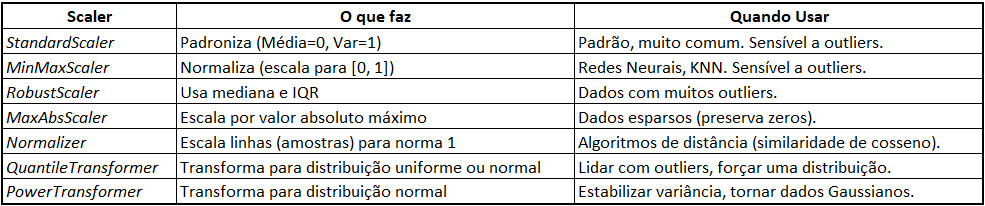

###**Machine Learning Models**

In [198]:
# Cross-Validation Strategy
CV_SPLITS = 5
cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=42)

print(f"Setup de Classificação pronto. CV com KFold (k={CV_SPLITS}).")

Setup de Classificação pronto. CV com KFold (k=5).


In [199]:
# Dictionary to store all pipelines
pipelines_class = {}

#DummyClassifier
pipelines_class['DummyClassifier'] = Pipeline([
    ('model', DummyClassifier(strategy='most_frequent'))
])

#DecisionTreeClassifier
pipelines_class['DecisionTree'] = Pipeline([
    ('model', DecisionTreeClassifier(random_state=42))
])

#RandomForestClassifier
pipelines_class['RandomForest'] = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

#ExtraTreesClassifier
pipelines_class['ExtraTrees'] = Pipeline([
    ('model', ExtraTreesClassifier(random_state=42))
])

#XGBoost (XGBClassifier)
pipelines_class['XGBoost'] = Pipeline([
    ('model', MultiOutputClassifier(xgb.XGBClassifier(
        random_state=42,
        use_label_encoder=False,
        eval_metric='mlogloss' # eval_metric is still useful
    )))
])

#CatBoostClassifier
pipelines_class['CatBoost'] = Pipeline([
    ('model', MultiOutputClassifier(
        CatBoostClassifierWithIntOutput(random_state=42,verbose=0)
    ))
])

#KNeighborsClassifier
pipelines_class['KNeighbors'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

#Multi-Layer Perceptron Classifier
pipelines_class['MLPClassifier'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(MLPClassifier(random_state=42, max_iter=1000, early_stopping=True)))
])

#GaussianProcessClassifier
kernel_gpc = C(1.0) * RBF(1.0)
pipelines_class['GPC'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(GaussianProcessClassifier(kernel=kernel_gpc, random_state=42)))
])

#BernoulliNB Classifier
pipelines_class['BernoulliNB'] = Pipeline([
    ('model', MultiOutputClassifier(BernoulliNB()))
])

#GradientBoostingClassifier
pipelines_class['GradientBoosting'] = Pipeline([
    ('model', MultiOutputClassifier(GradientBoostingClassifier(random_state=42)))
])

#AdaBoost (AdaBoostClassifier)
pipelines_class['AdaBoost'] = Pipeline([
    ('model', MultiOutputClassifier(AdaBoostClassifier(random_state=42)))
])

#LightGBM (LGBMClassifier)
pipelines_class['LightGBM'] = Pipeline([
    ('model', MultiOutputClassifier(lgb.LGBMClassifier(
        random_state=42,
        verbose=-1,            #verbose=1 default, 0 errors and warnings, -1 fatal errors
        n_jobs=1,              # Wrapper uses all cores
        n_estimators=50,       # Reduced to be fast
        min_child_samples=1    # Leaves with 1 sample
    )))
])

#LogisticRegression Classifier
pipelines_class['LogisticRegression'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(LogisticRegression(random_state=42, max_iter=1000)))
])

#Lasso Classifier
pipelines_class['Lasso (LogReg L1)'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(LogisticRegression(penalty='l1', solver='liblinear', random_state=42)))
])

#ElasticNet Classifier
pipelines_class['ElasticNet (LogReg)'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, max_iter=1000)))
])

#SGDClassifier
pipelines_class['SGDClassifier'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(SGDClassifier(random_state=42)))
])

#SVC
pipelines_class['SVC'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(SVC(random_state=42)))
])

#LinearSVC
pipelines_class['LinearSVC'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MultiOutputClassifier(LinearSVC(random_state=42, max_iter=5000, dual=True)))
])

print(f"Total de {len(pipelines_class)} pipelines definidos.")
print(list(pipelines_class.keys()))

Total de 19 pipelines definidos.
['DummyClassifier', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'XGBoost', 'CatBoost', 'KNeighbors', 'MLPClassifier', 'GPC', 'BernoulliNB', 'GradientBoosting', 'AdaBoost', 'LightGBM', 'LogisticRegression', 'Lasso (LogReg L1)', 'ElasticNet (LogReg)', 'SGDClassifier', 'SVC', 'LinearSVC']


##**12 - Results - Classification Problem**

###**Multi-Outputs | Multi Features**


--- INICIANDO AVALIAÇÃO DETALHADA (CLASSIFICAÇÃO) ---

Avaliando Modelo: DummyClassifier
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        11
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para 

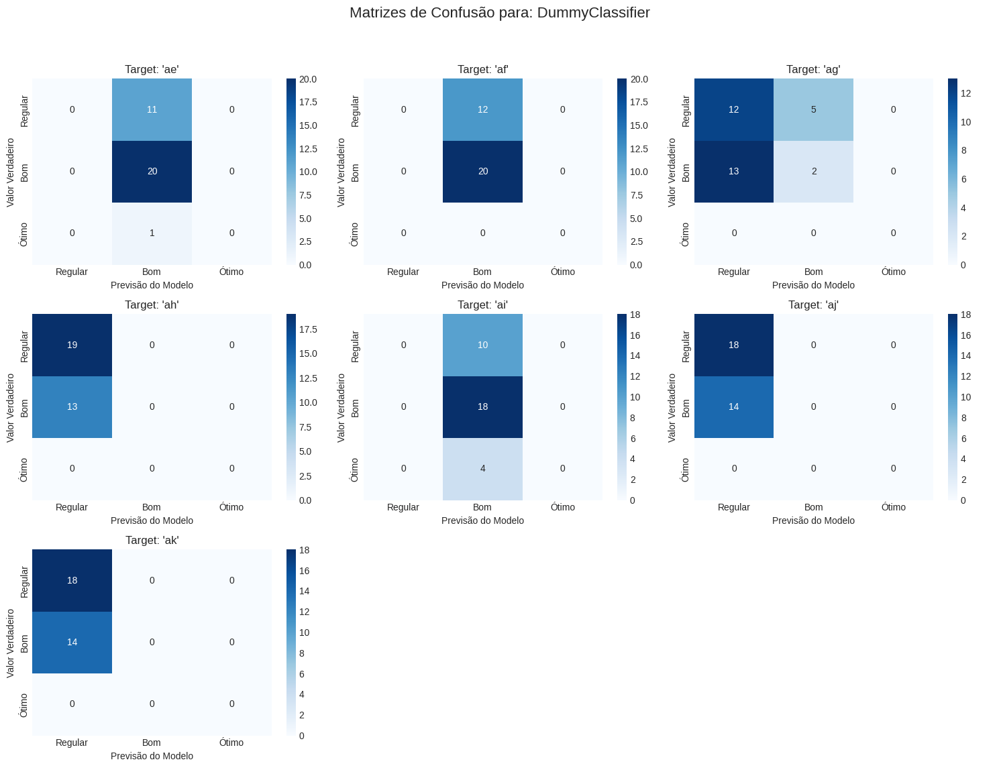


Avaliando Modelo: DecisionTree
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.36      0.35        11
         Bom       0.61      0.55      0.58        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.31      0.30      0.31        32
weighted avg       0.50      0.47      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.57      0.33      0.42        12
         Bom       0.68      0.85      0.76        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.66        32
   macro avg       0.42      0.39      0.39        32
weighted avg       0.64      0.66      0.63        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sco

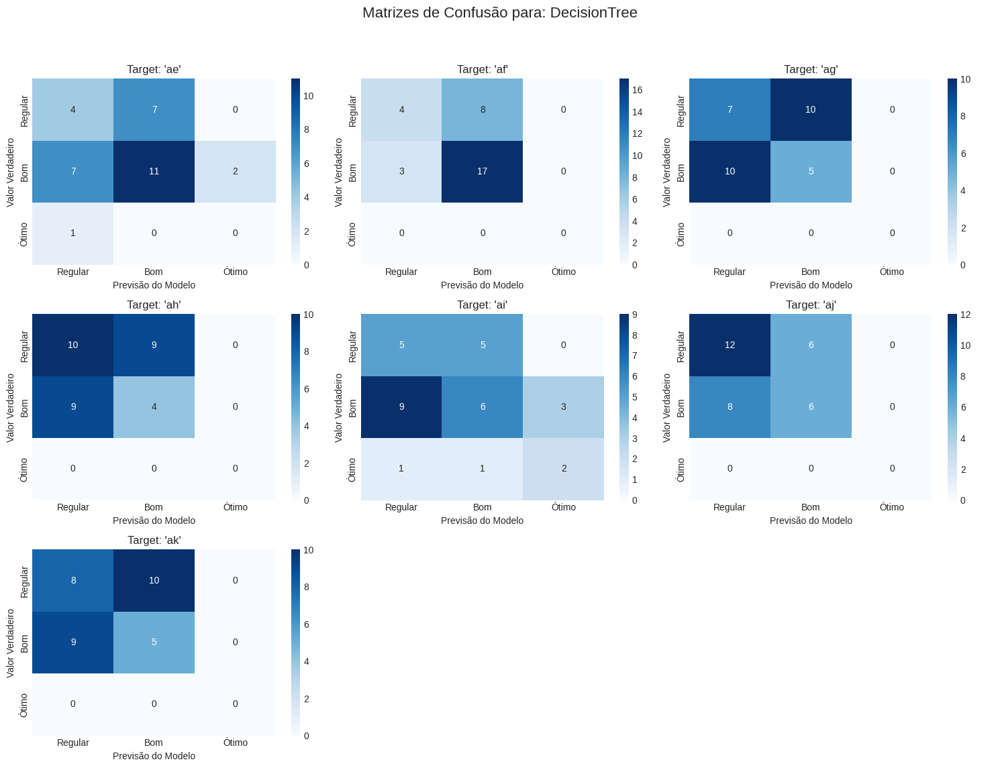


Avaliando Modelo: RandomForest
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.43      0.27      0.33        11
         Bom       0.64      0.80      0.71        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.36      0.36      0.35        32
weighted avg       0.55      0.59      0.56        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.33      0.40        12
         Bom       0.67      0.80      0.73        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.38      0.38        32
weighted avg       0.60      0.62      0.60        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sco

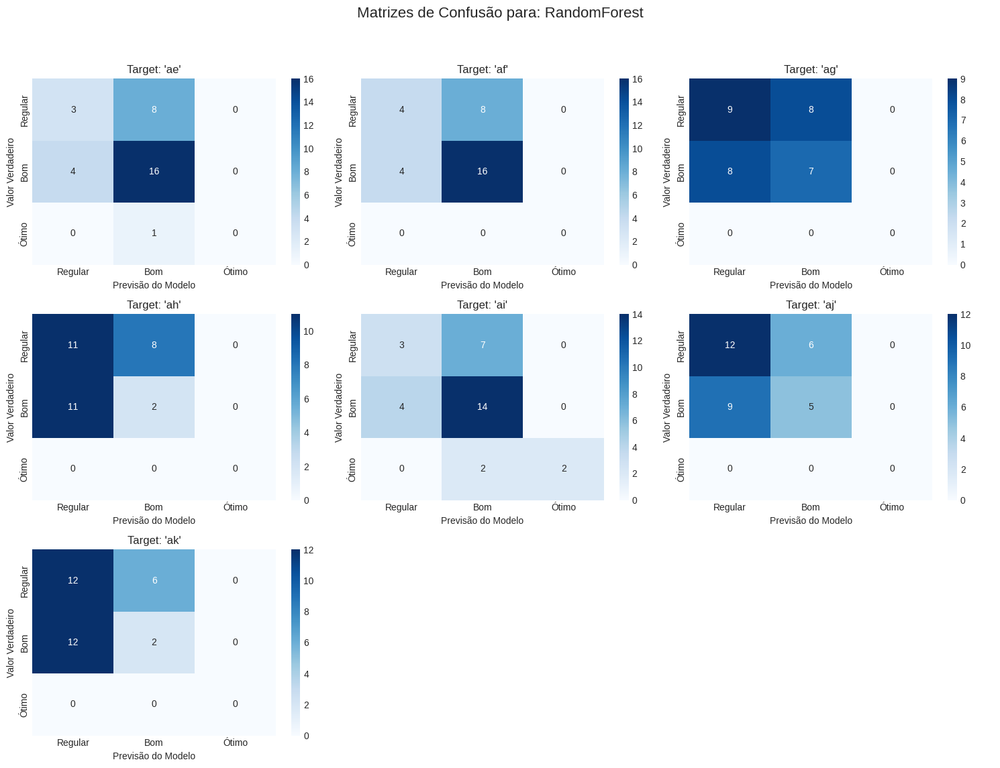


Avaliando Modelo: ExtraTrees
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.38      0.27      0.32        11
         Bom       0.62      0.75      0.68        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.33      0.34      0.33        32
weighted avg       0.52      0.56      0.53        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.40      0.33      0.36        12
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.35      0.34      0.34        32
weighted avg       0.55      0.56      0.55        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score

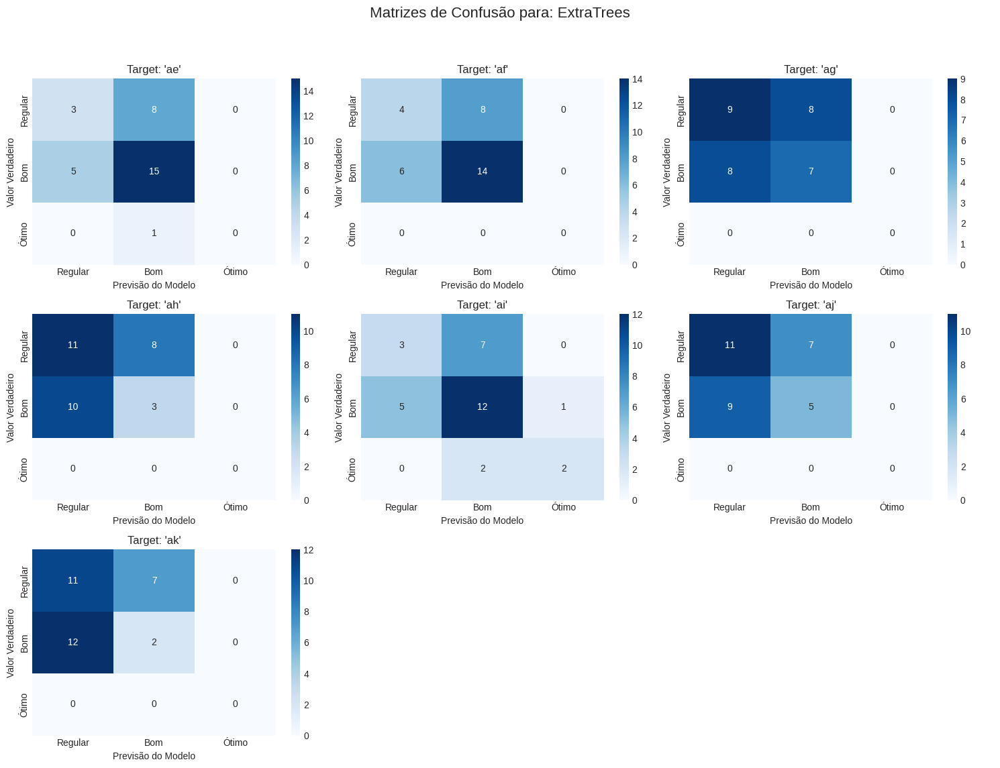


Avaliando Modelo: XGBoost
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.30      0.27      0.29        11
         Bom       0.59      0.65      0.62        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.50        32
   macro avg       0.30      0.31      0.30        32
weighted avg       0.47      0.50      0.49        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.43      0.25      0.32        12
         Bom       0.64      0.80      0.71        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.59        32
   macro avg       0.36      0.35      0.34        32
weighted avg       0.56      0.59      0.56        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score   

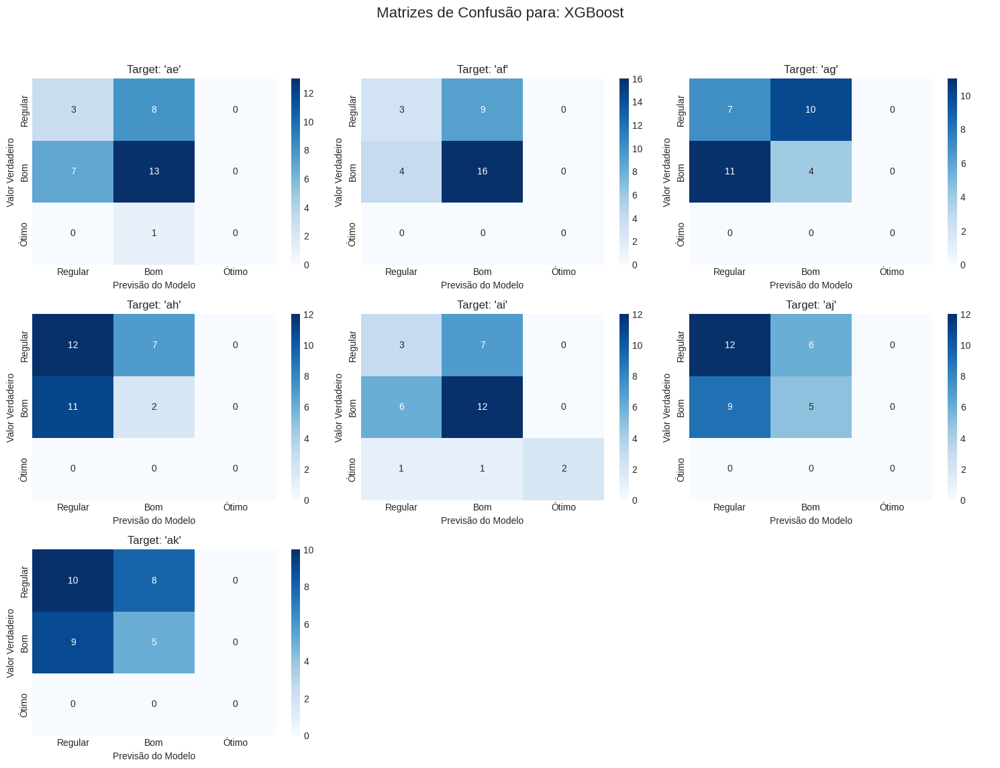


Avaliando Modelo: CatBoost
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.50      0.45      0.48        11
         Bom       0.68      0.75      0.71        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.62        32
   macro avg       0.39      0.40      0.40        32
weighted avg       0.60      0.62      0.61        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.42      0.45        12
         Bom       0.68      0.75      0.71        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.39      0.39        32
weighted avg       0.61      0.62      0.62        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score  

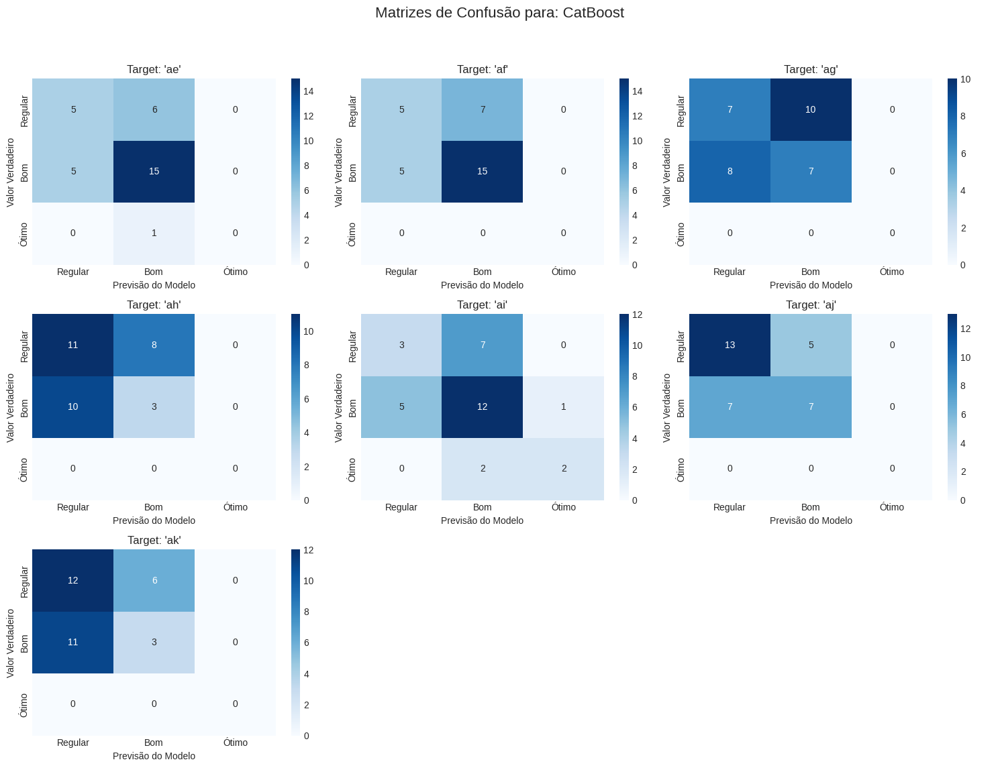


Avaliando Modelo: KNeighbors
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.38      0.45      0.42        11
         Bom       0.63      0.60      0.62        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.53        32
   macro avg       0.34      0.35      0.34        32
weighted avg       0.53      0.53      0.53        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.45      0.42      0.43        12
         Bom       0.67      0.70      0.68        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.59        32
   macro avg       0.37      0.37      0.37        32
weighted avg       0.59      0.59      0.59        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score

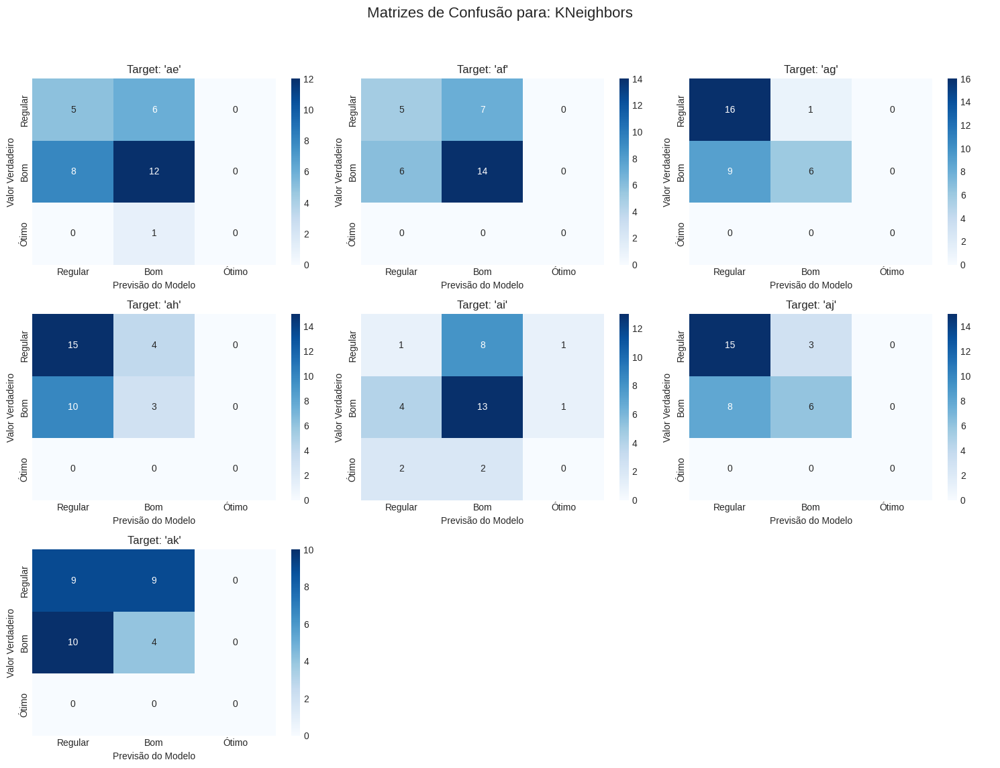


Avaliando Modelo: MLPClassifier
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.18      0.24        11
         Bom       0.56      0.50      0.53        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.38        32
   macro avg       0.30      0.23      0.25        32
weighted avg       0.46      0.38      0.41        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.36      0.42      0.38        12
         Bom       0.61      0.55      0.58        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.50        32
   macro avg       0.32      0.32      0.32        32
weighted avg       0.52      0.50      0.51        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sc

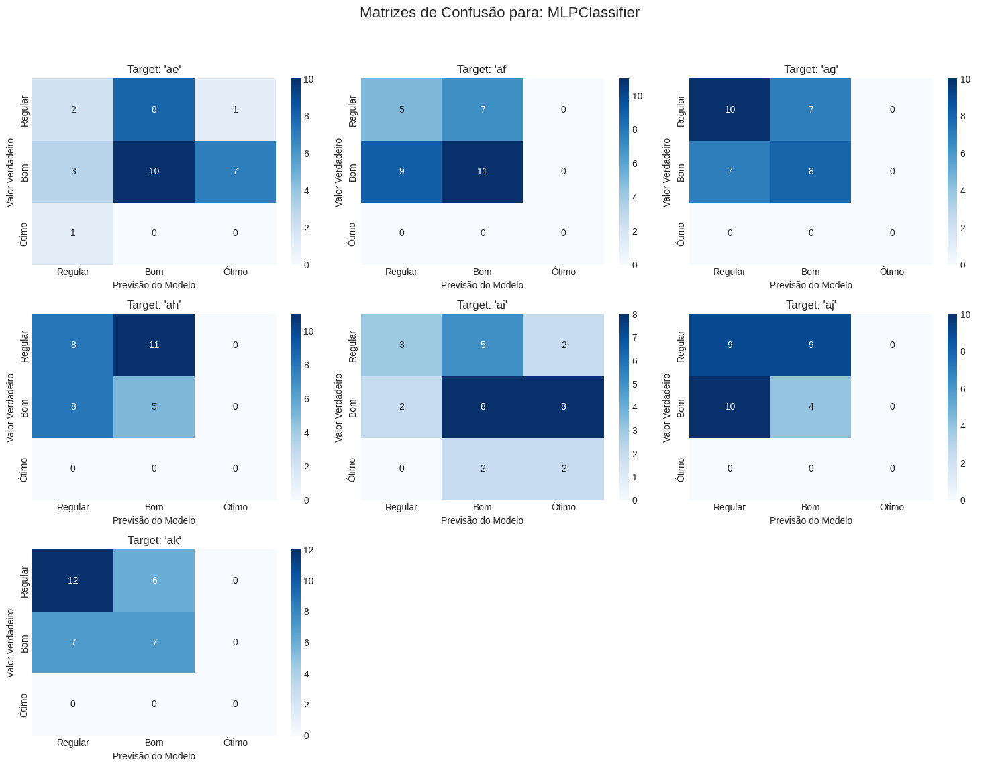


Avaliando Modelo: GPC
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.18      0.24        11
         Bom       0.38      0.15      0.21        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.16        32
   macro avg       0.24      0.11      0.15        32
weighted avg       0.35      0.16      0.21        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.43      0.50      0.46        12
         Bom       0.67      0.60      0.63        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.37      0.37      0.36        32
weighted avg       0.58      0.56      0.57        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score   supp

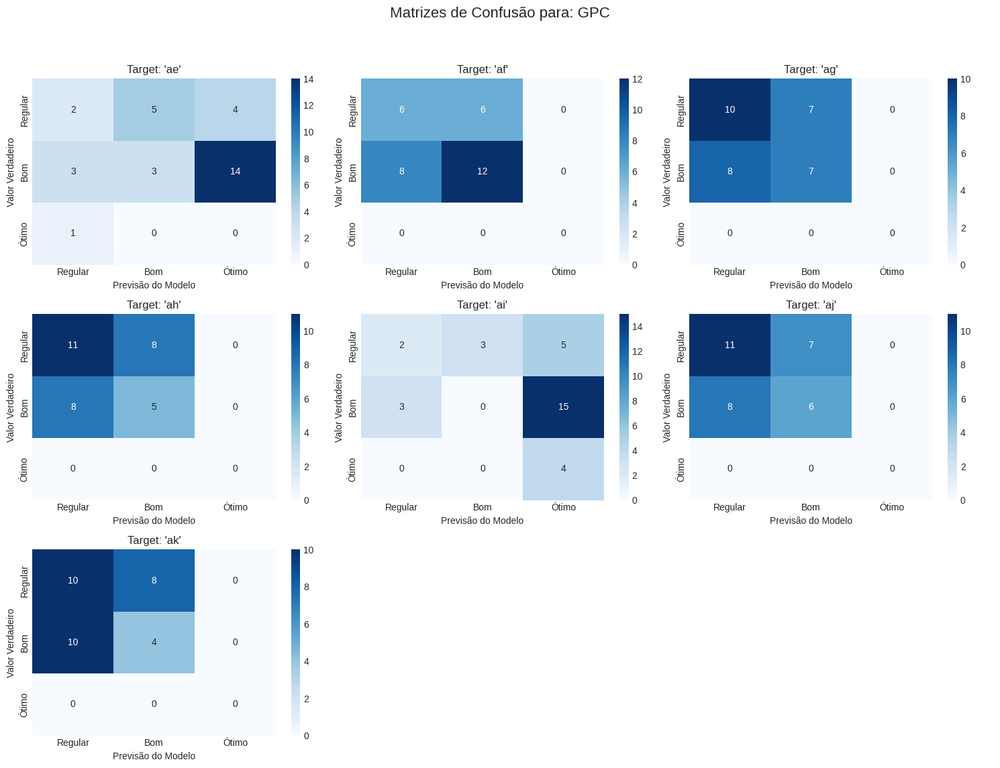


Avaliando Modelo: BernoulliNB
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.45      0.38        11
         Bom       0.65      0.55      0.59        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.50        32
   macro avg       0.33      0.33      0.33        32
weighted avg       0.52      0.50      0.50        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.42      0.42      0.42        12
         Bom       0.65      0.65      0.65        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.36      0.36      0.36        32
weighted avg       0.56      0.56      0.56        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-scor

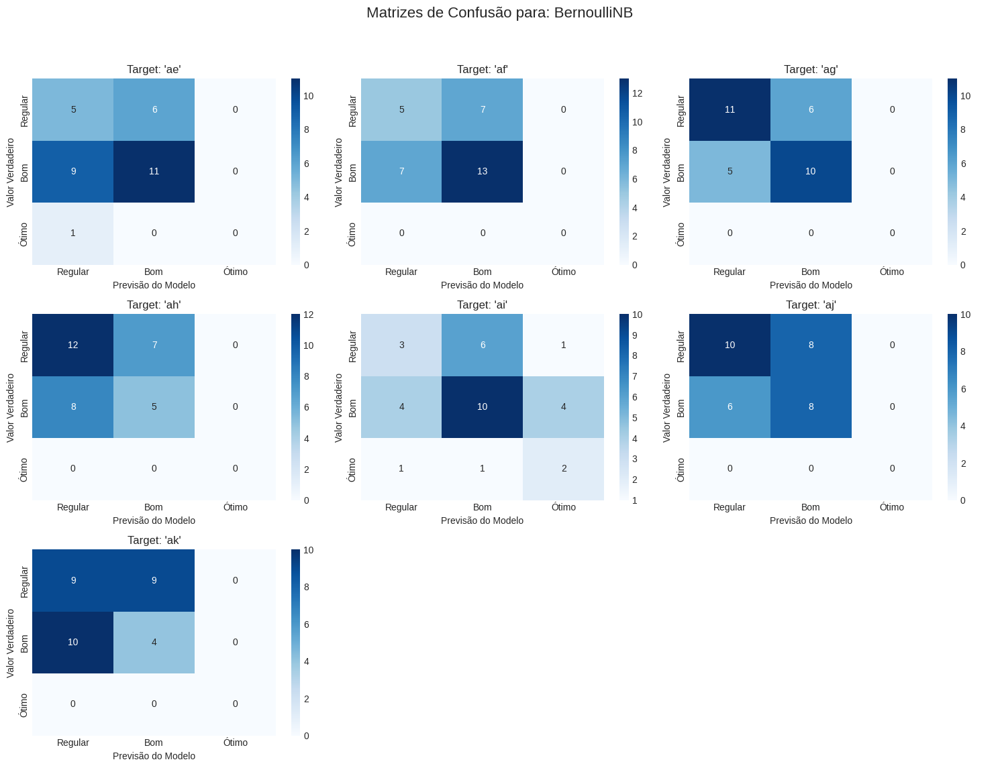


Avaliando Modelo: GradientBoosting
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.55      0.46        11
         Bom       0.60      0.45      0.51        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.33      0.33      0.33        32
weighted avg       0.51      0.47      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.33      0.33      0.33        12
         Bom       0.60      0.60      0.60        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.50        32
   macro avg       0.31      0.31      0.31        32
weighted avg       0.50      0.50      0.50        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1

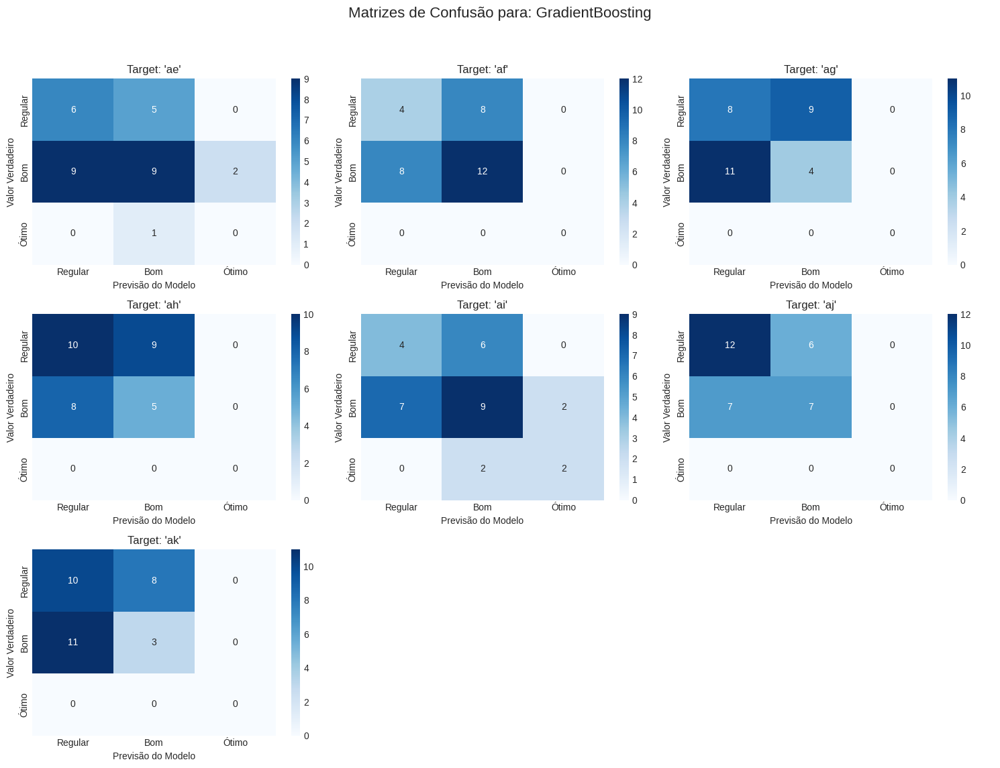


Avaliando Modelo: AdaBoost
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.45      0.38        11
         Bom       0.53      0.40      0.46        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.41        32
   macro avg       0.29      0.28      0.28        32
weighted avg       0.45      0.41      0.42        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.33      0.25      0.29        12
         Bom       0.61      0.70      0.65        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.31      0.32      0.31        32
weighted avg       0.51      0.53      0.51        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score  

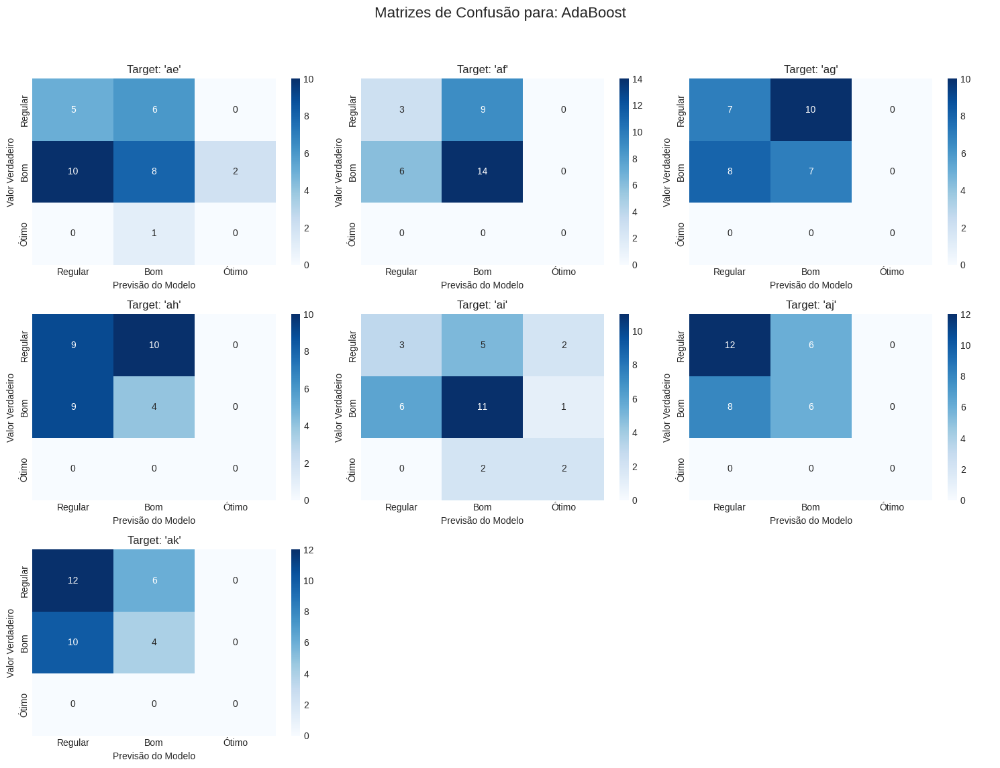


Avaliando Modelo: LightGBM
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.42      0.45      0.43        11
         Bom       0.61      0.55      0.58        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.50        32
   macro avg       0.34      0.33      0.34        32
weighted avg       0.53      0.50      0.51        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.38      0.42      0.40        12
         Bom       0.63      0.60      0.62        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.34      0.34      0.34        32
weighted avg       0.54      0.53      0.53        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score  

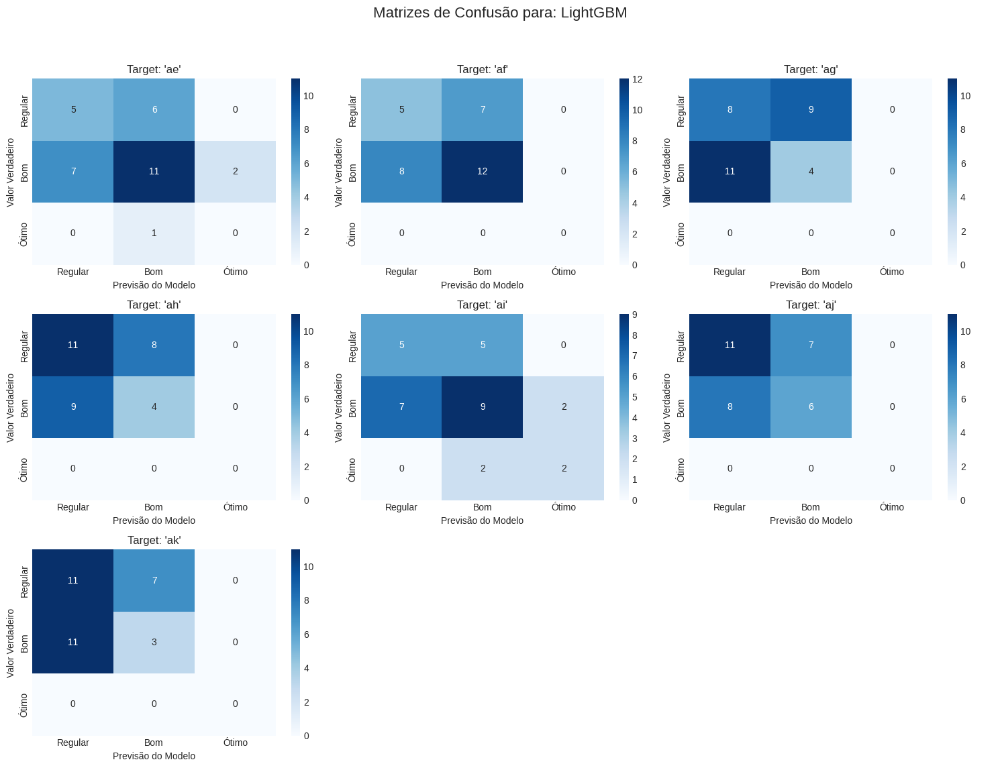


Avaliando Modelo: LogisticRegression
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.31      0.36      0.33        11
         Bom       0.58      0.55      0.56        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.30      0.30      0.30        32
weighted avg       0.47      0.47      0.47        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.36      0.33      0.35        12
         Bom       0.62      0.65      0.63        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.33      0.33      0.33        32
weighted avg       0.52      0.53      0.53        32


--- Relatório para Target: 'ag' ---
              precision    recall  

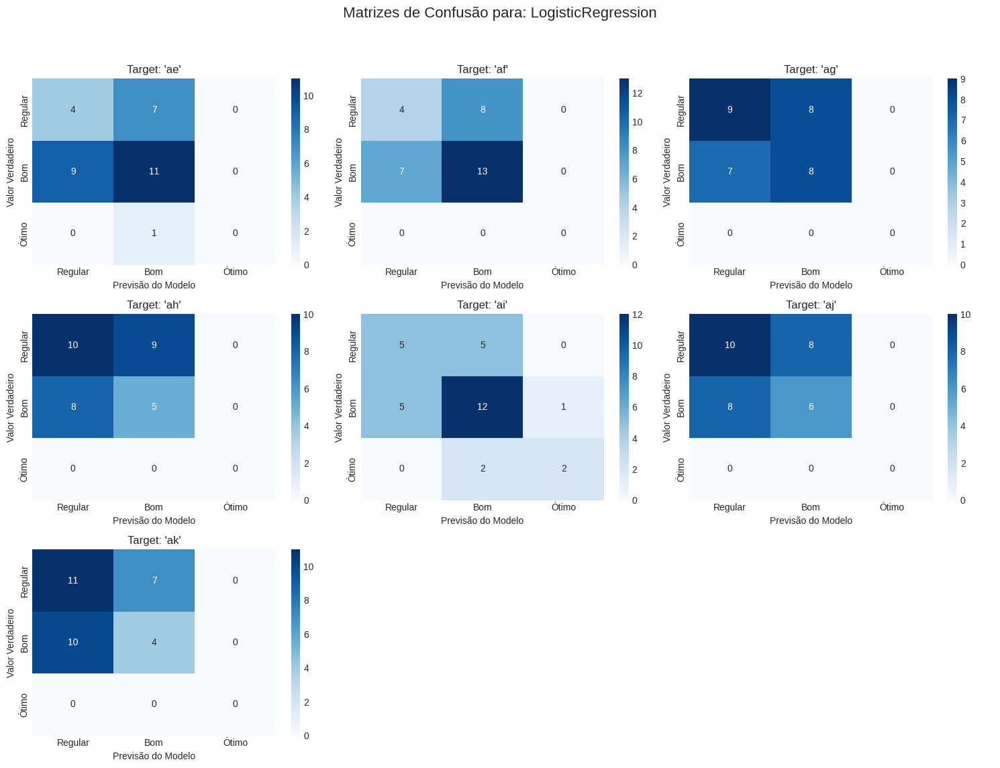


Avaliando Modelo: Lasso (LogReg L1)
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.35      0.55      0.43        11
         Bom       0.64      0.45      0.53        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.33      0.33      0.32        32
weighted avg       0.52      0.47      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.30      0.25      0.27        12
         Bom       0.59      0.65      0.62        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.50        32
   macro avg       0.30      0.30      0.30        32
weighted avg       0.48      0.50      0.49        32


--- Relatório para Target: 'ag' ---
              precision    recall  f

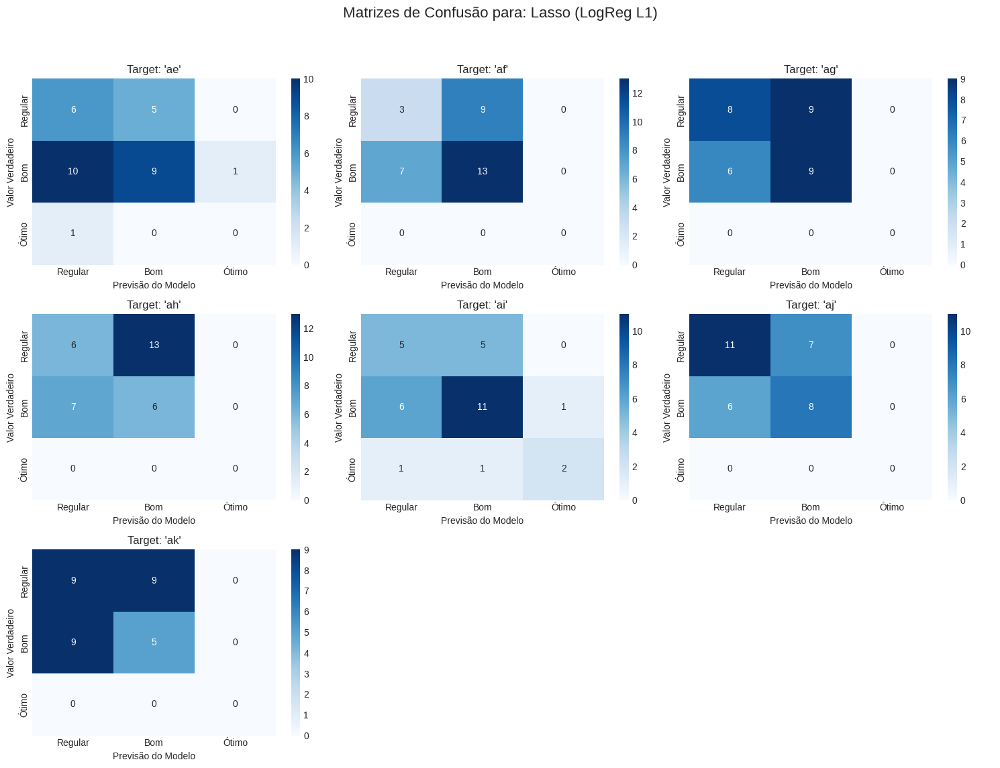


Avaliando Modelo: ElasticNet (LogReg)
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.36      0.45      0.40        11
         Bom       0.59      0.50      0.54        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.32      0.32      0.31        32
weighted avg       0.49      0.47      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.40      0.33      0.36        12
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.35      0.34      0.34        32
weighted avg       0.55      0.56      0.55        32


--- Relatório para Target: 'ag' ---
              precision    recall 

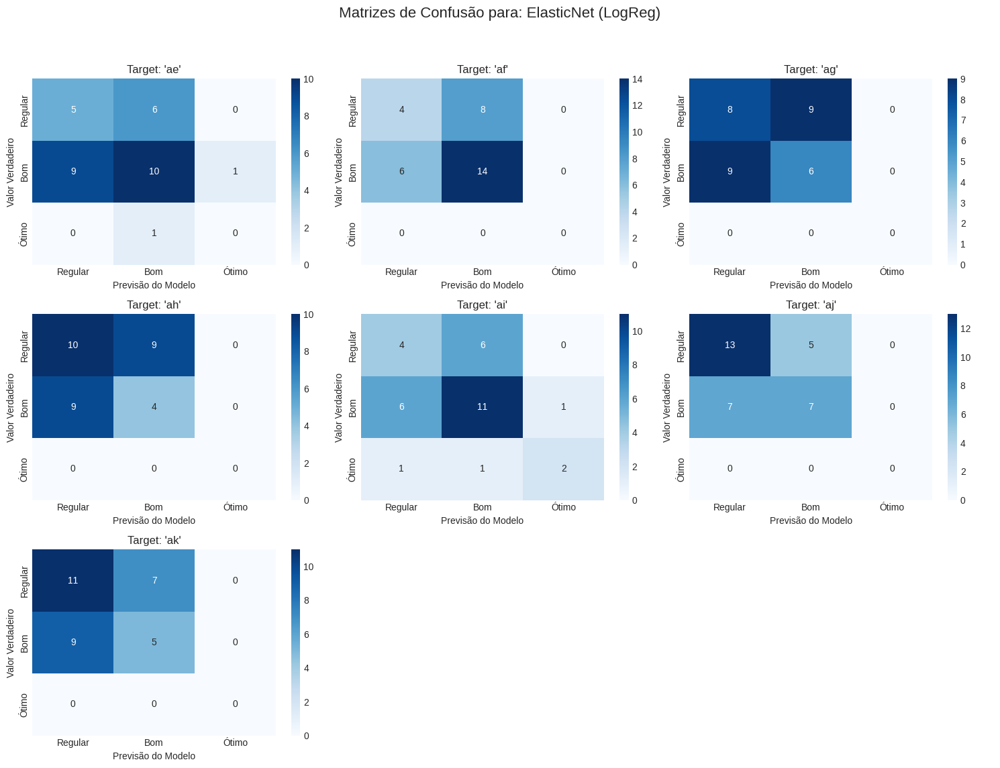


Avaliando Modelo: SGDClassifier
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.17      0.18      0.17        11
         Bom       0.53      0.50      0.51        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.38        32
   macro avg       0.23      0.23      0.23        32
weighted avg       0.39      0.38      0.38        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.40      0.33      0.36        12
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.35      0.34      0.34        32
weighted avg       0.55      0.56      0.55        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sc

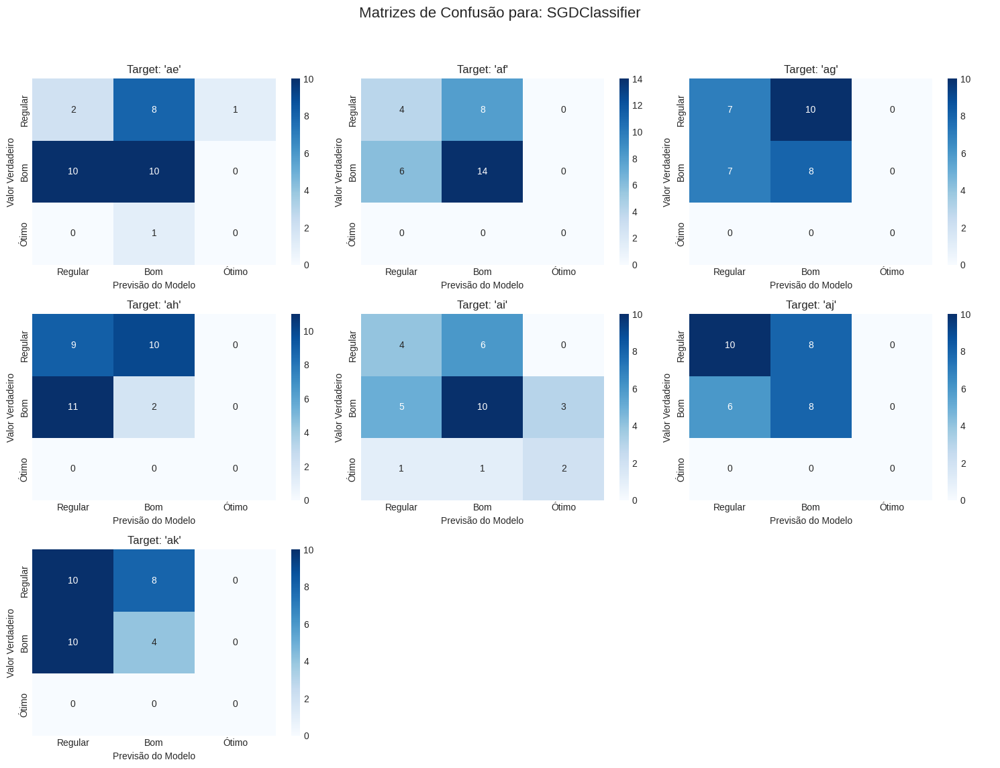


Avaliando Modelo: SVC
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.18      0.25        11
         Bom       0.63      0.85      0.72        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.34      0.34      0.32        32
weighted avg       0.53      0.59      0.54        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.67      0.17      0.27        12
         Bom       0.66      0.95      0.78        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.66        32
   macro avg       0.44      0.37      0.35        32
weighted avg       0.66      0.66      0.58        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score   supp

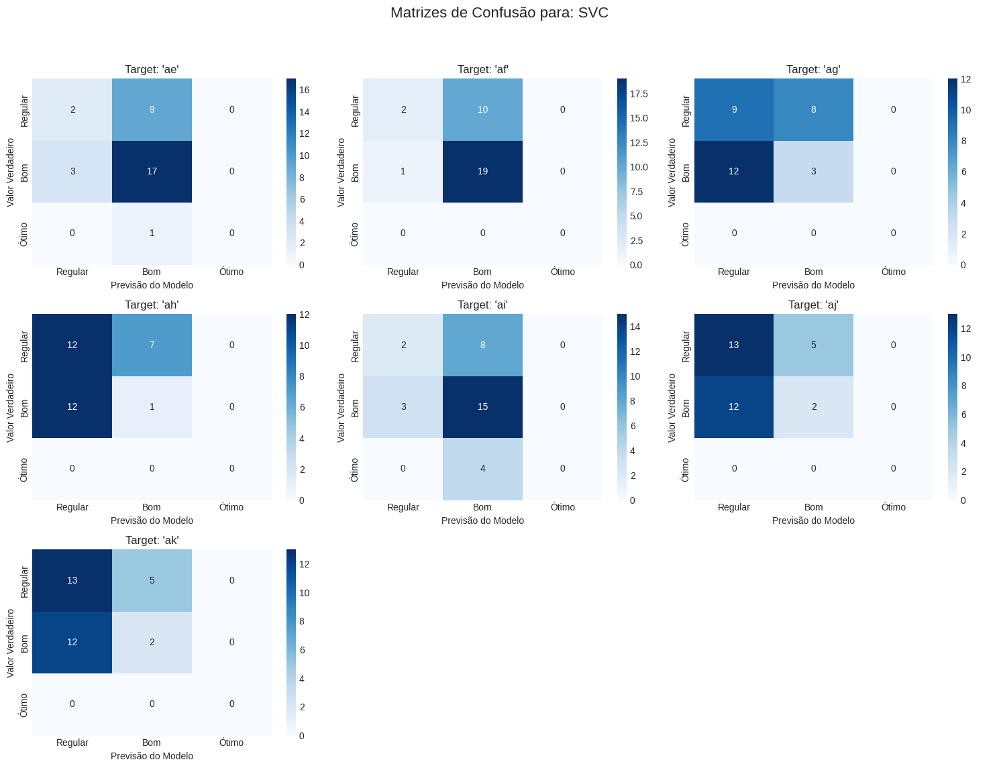


Avaliando Modelo: LinearSVC
--- Métricas Detalhadas e Relatórios (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.31      0.36      0.33        11
         Bom       0.59      0.50      0.54        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.44        32
   macro avg       0.30      0.29      0.29        32
weighted avg       0.47      0.44      0.45        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.40      0.33      0.36        12
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.35      0.34      0.34        32
weighted avg       0.55      0.56      0.55        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score 

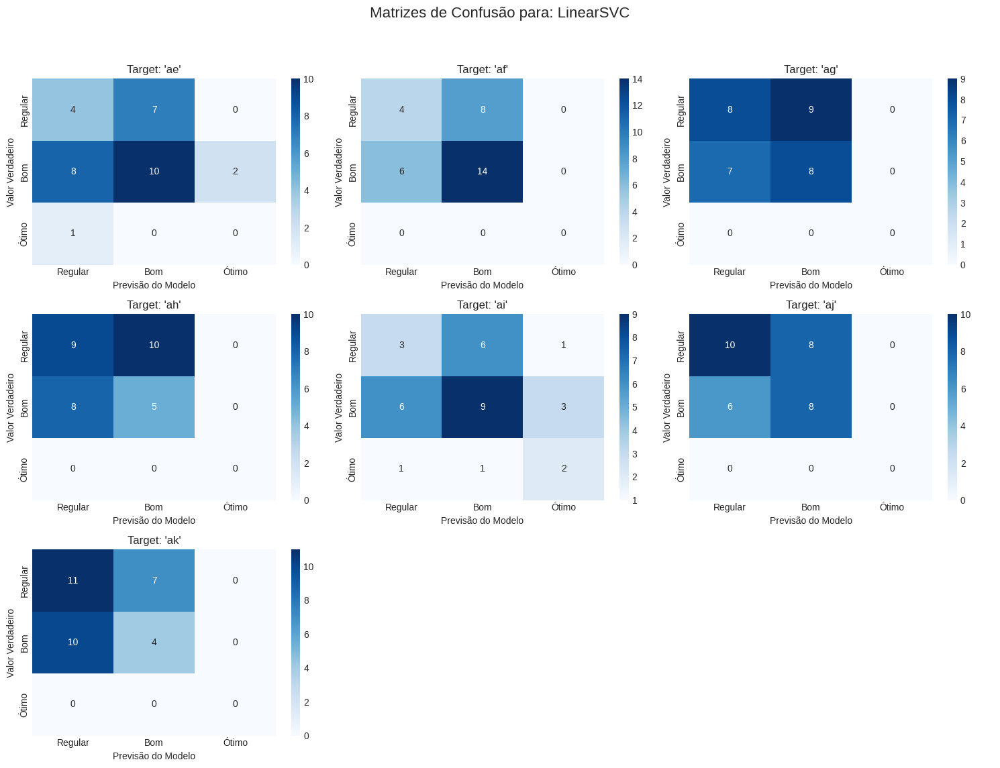

In [200]:
print("\n--- INICIANDO AVALIAÇÃO DETALHADA (CLASSIFICAÇÃO) ---")

# --- Setup ---
all_metrics_list = []
target_names = y_class_all.columns
class_labels = ['Regular', 'Bom', 'Ótimo']
numeric_labels = [0, 1, 2] # Numeric labels used by y_class_numeric

# --- Main Evaluation Loop ---
for nome, pipe in pipelines_class.items():
    print(f"\n======================================================")
    print(f"Avaliando Modelo: {nome}")
    print(f"======================================================")

    # ====================================================================
    # --- START OF THE FIXED BLOCK ---
    # ====================================================================
    try:
        # 1. Obtain predictions using cross-validation
        # (This line was correct)
        y_pred = cross_val_predict(pipe, X_class, y_class_numeric, cv=cv)

        # 2. Chart Setup (Confusion Matrix)
        # (This part was correct)
        n_outputs = len(target_names)
        n_cols = 3
        n_rows = (n_outputs + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        fig.suptitle(f"Matrizes de Confusão para: {nome}", fontsize=16)
        axes = axes.flatten()

        print("--- Métricas Detalhadas e Relatórios (por Output) ---")

        # 3. Detailed Loop (per Target)
        for i, target in enumerate(target_names):
            ax = axes[i]

            # --- FIX 1: PANDAS (.iloc) vs. NUMPY ([:, i]) ---
            # 'y_class_numeric' is a NumPy array, not a DataFrame.
            # Use NumPy indexing [:, i]
            y_true_col = y_class_numeric[:, i]

            # (This line was correct in your code)
            y_pred_col_num = y_pred[:, i]
            # --- END OF FIX 1 ---

            # --- a. Compute Metrics for the Summary Table ---

            # --- FIX 2: Use the correct variable ---
            # You defined 'y_pred_col_num', but were using 'y_pred_col'
            # (which was not defined) in your metrics.
            accuracy = accuracy_score(y_true_col, y_pred_col_num)
            precision = precision_score(y_true_col, y_pred_col_num, average='weighted', labels=numeric_labels, zero_division=0)
            recall = recall_score(y_true_col, y_pred_col_num, average='weighted', labels=numeric_labels, zero_division=0)
            f1 = f1_score(y_true_col, y_pred_col_num, average='weighted', labels=numeric_labels, zero_division=0)
            # --- END OF FIX 2 ---

            # Add to the list for the final table
            all_metrics_list.append({
                'Modelo': nome,
                'Target': target,
                'Accuracy': accuracy,
                'Precision (w)': precision,
                'Recall (w)': recall,
                'F1-Score (w)': f1
            })

            # --- b. Print the Classification Report (Tabulated) ---
            print(f"\n--- Relatório para Target: '{target}' ---")

            # (This part was correct in your code)
            report = classification_report(y_true_col, y_pred_col_num,
                                           labels=numeric_labels,
                                           target_names=class_labels,
                                           zero_division=0)
            print(report)

            # --- c. Plot the Confusion Matrix ---
            # (This part was correct in your code)
            cm = confusion_matrix(y_true_col, y_pred_col_num, labels=numeric_labels)

            sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', ax=ax,
                        xticklabels=class_labels, yticklabels=class_labels)

            ax.set_title(f"Target: '{target}'")
            ax.set_xlabel('Previsão do Modelo')
            ax.set_ylabel('Valor Verdadeiro')

        # Hide unused axes
        for i in range(n_outputs, len(axes)):
            axes[i].axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    except Exception as e:
        # (The except block is correct)
        print(f"!!!!!!!! NÃO FOI POSSÍVEL AVALIAR O MODELO {nome} !!!!!!!!")
        print(f"Erro: {e}")
        for target in target_names:
            all_metrics_list.append({
                'Modelo': nome, 'Target': target,
                'Accuracy': 0, 'Precision (w)': 0, 'Recall (w)': 0, 'F1-Score (w)': 0
            })

In [201]:
# 4. Final Summary Table (Mean over All Targets)

# Convert the list of metrics into a DataFrame
metrics_df = pd.DataFrame(all_metrics_list)

# Group by model and compute the mean
summary_df = metrics_df.groupby('Modelo').mean(numeric_only=True)

# Sort by F1-Score, which is a good balance metric
summary_df = summary_df.sort_values(by='F1-Score (w)', ascending=False)

# Display the final table formatted as HTML
display(summary_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision (w)': '{:.4f}',
    'Recall (w)': '{:.4f}',
    'F1-Score (w)': '{:.4f}'
}).background_gradient(cmap='viridis', subset=['F1-Score (w)']))

,Accuracy,Precision (w),Recall (w),F1-Score (w)
Modelo,,,,
KNeighbors,0.5536,0.5441,0.5536,0.5345
BernoulliNB,0.5268,0.5315,0.5268,0.5270
CatBoost,0.5357,0.5224,0.5357,0.5255
RandomForest,0.5268,0.5060,0.5268,0.5075
ElasticNet (LogReg),0.5089,0.5095,0.5089,0.5074
LogisticRegression,0.5089,0.5068,0.5089,0.5067
Lasso (LogReg L1),0.4955,0.5082,0.4955,0.4960
LinearSVC,0.4866,0.4930,0.4866,0.4872
ExtraTrees,0.5000,0.4813,0.5000,0.4871


Avaliador (scorer) F1 Multi-Output customizado foi definido.
Iniciando geração de gráficos de importância (CLASSIFICAÇÃO)...

--- Processando Modelo: DummyClassifier ---
Calculando Permutation Importance (agnóstico ao modelo)...
Modelo DummyClassifier não atribui importância a nenhuma feature (importância total é 0).
Pulando o gráfico de Pareto...

--- Processando Modelo: DecisionTree ---
Calculando Permutation Importance (agnóstico ao modelo)...


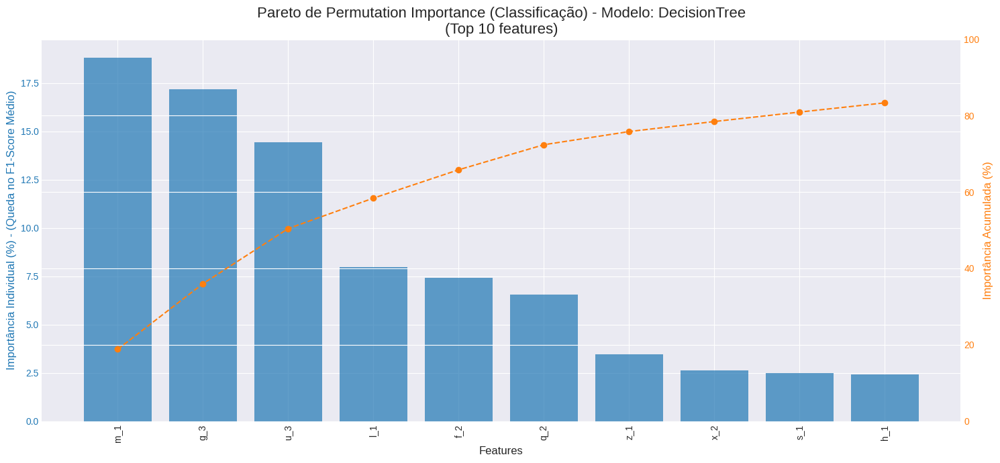


--- Processando Modelo: RandomForest ---
Calculando Permutation Importance (agnóstico ao modelo)...


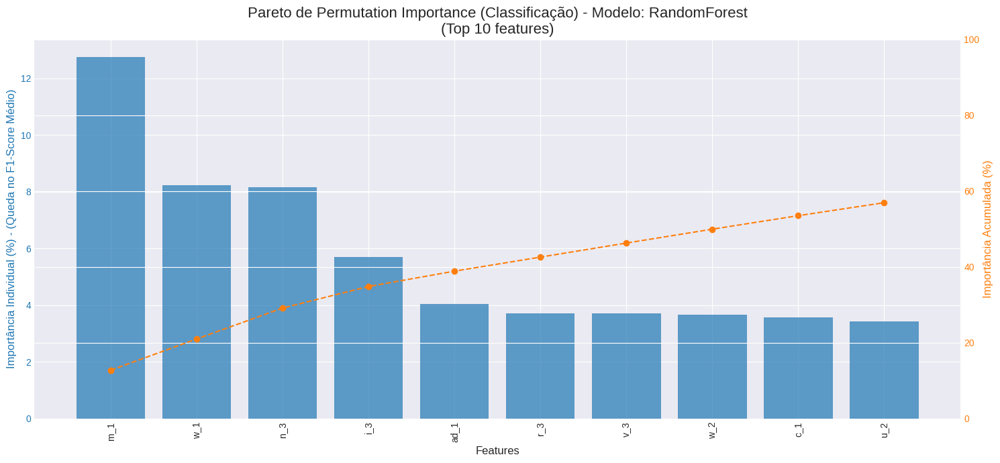


--- Processando Modelo: ExtraTrees ---
Calculando Permutation Importance (agnóstico ao modelo)...


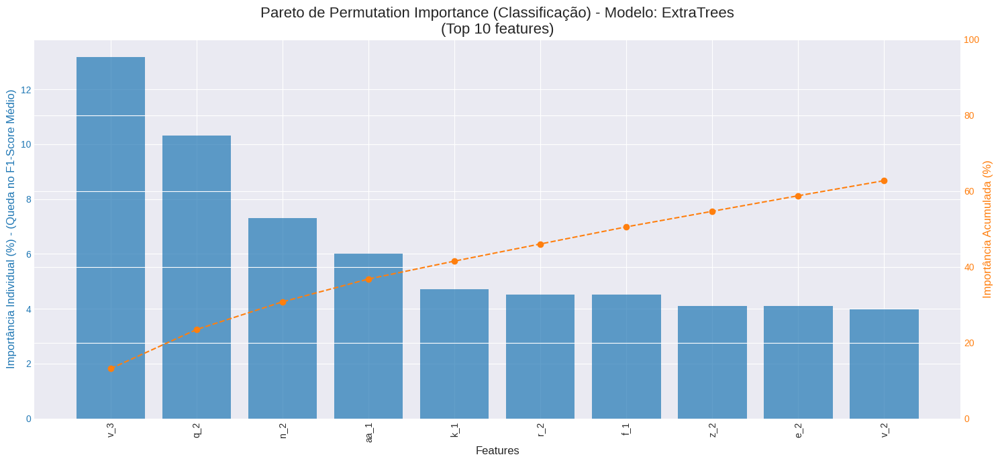


--- Processando Modelo: XGBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


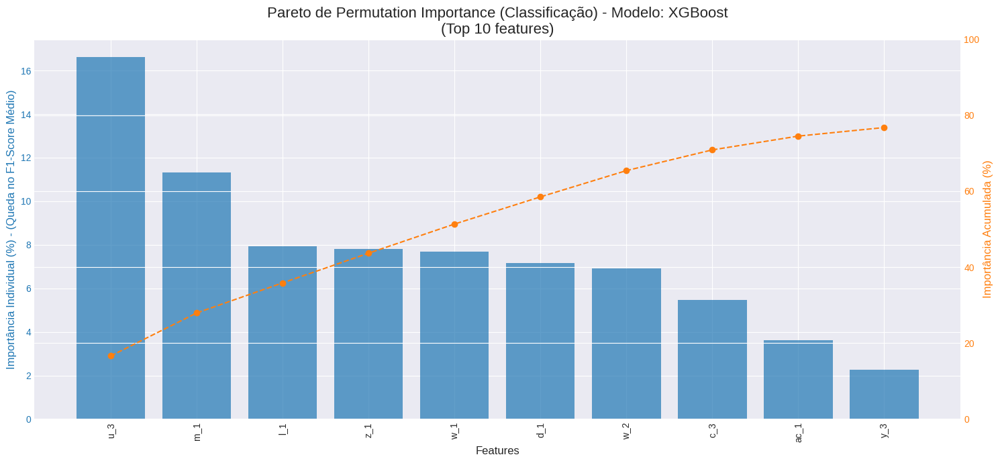


--- Processando Modelo: CatBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


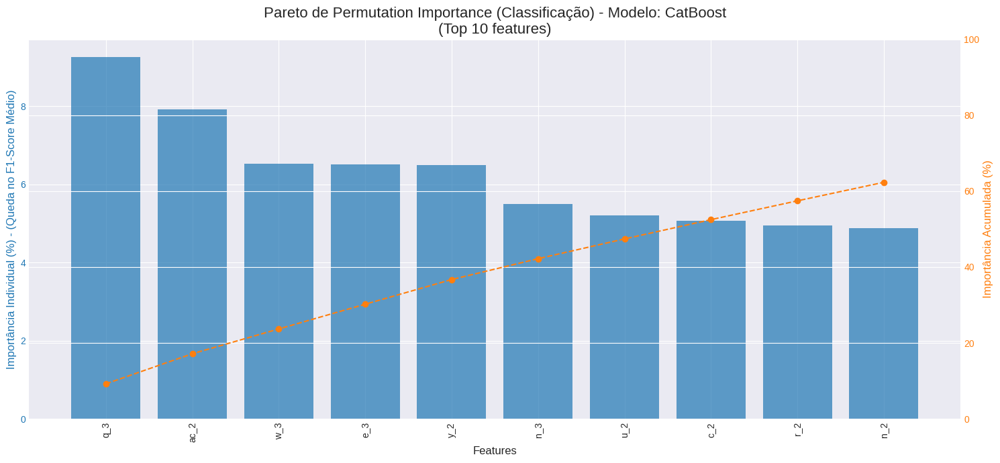


--- Processando Modelo: KNeighbors ---
Calculando Permutation Importance (agnóstico ao modelo)...


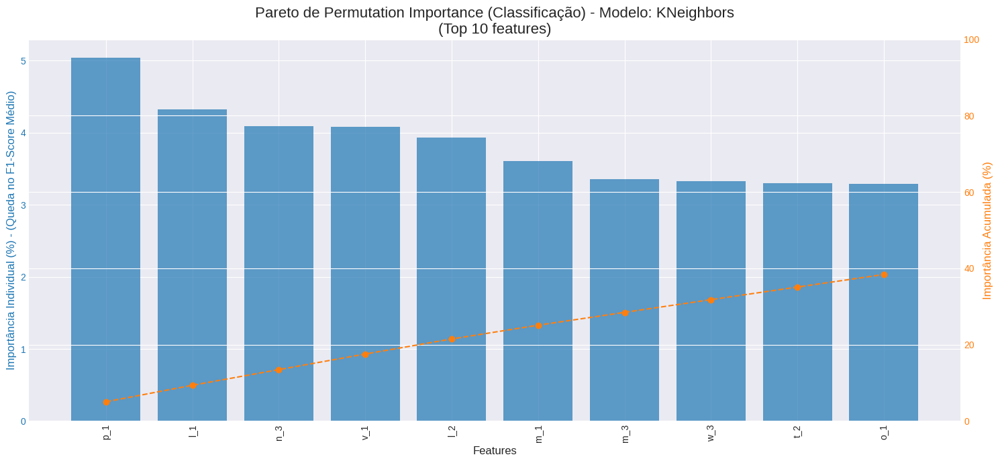


--- Processando Modelo: MLPClassifier ---
Calculando Permutation Importance (agnóstico ao modelo)...


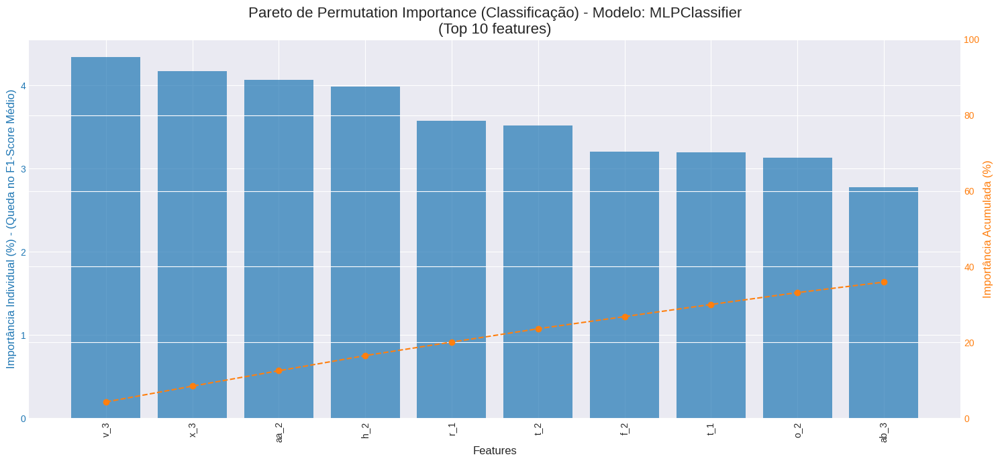


--- Processando Modelo: GPC ---
Calculando Permutation Importance (agnóstico ao modelo)...


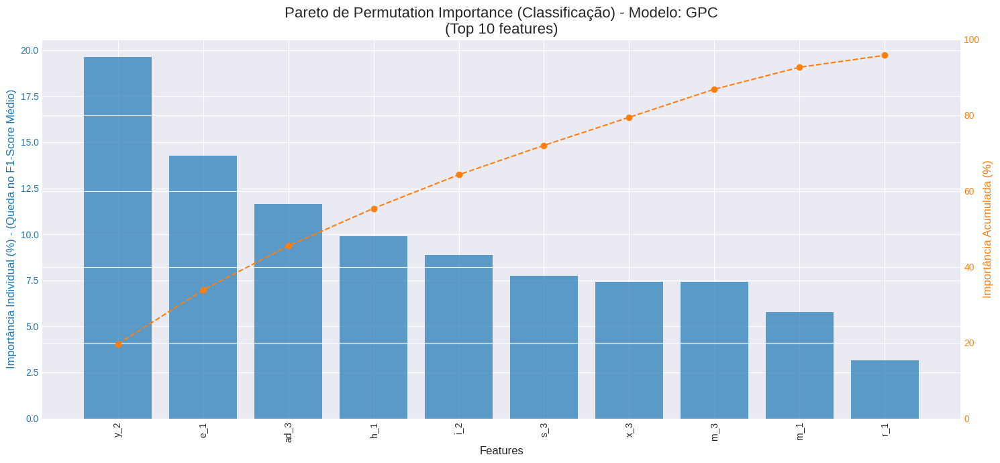


--- Processando Modelo: BernoulliNB ---
Calculando Permutation Importance (agnóstico ao modelo)...


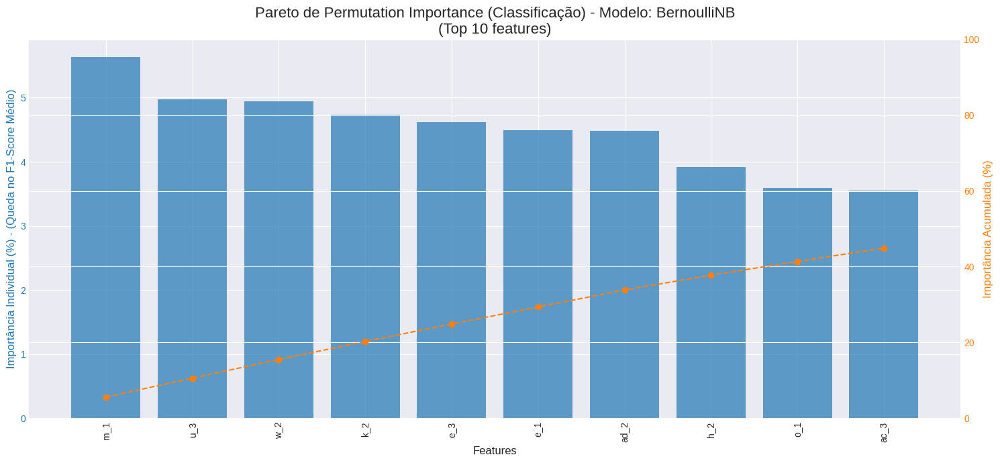


--- Processando Modelo: GradientBoosting ---
Calculando Permutation Importance (agnóstico ao modelo)...


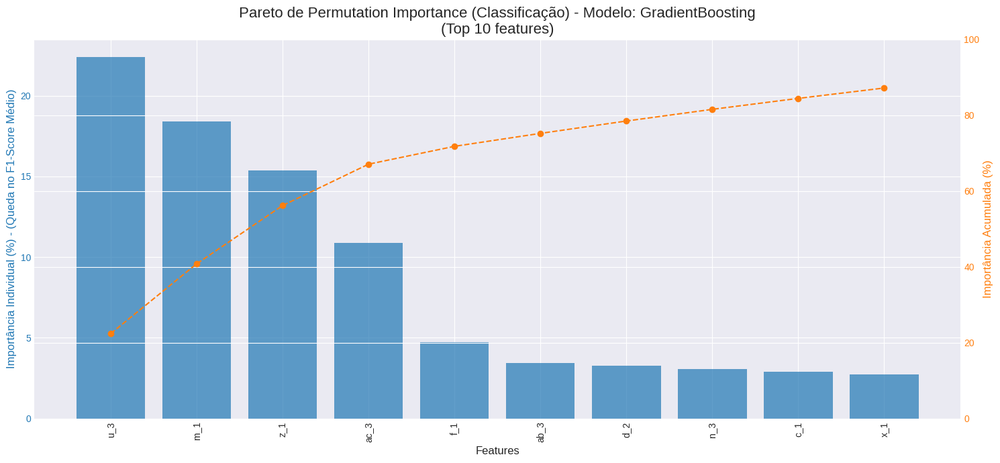


--- Processando Modelo: AdaBoost ---
Calculando Permutation Importance (agnóstico ao modelo)...


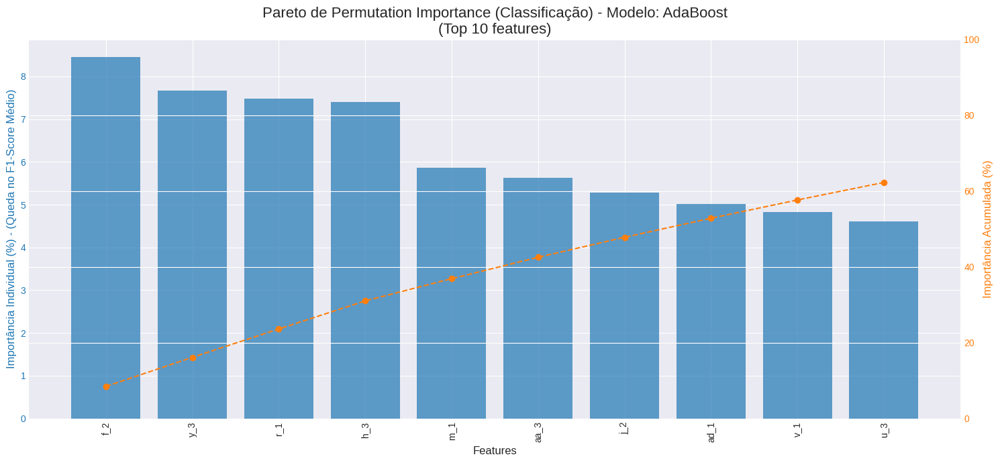


--- Processando Modelo: LightGBM ---
Calculando Permutation Importance (agnóstico ao modelo)...


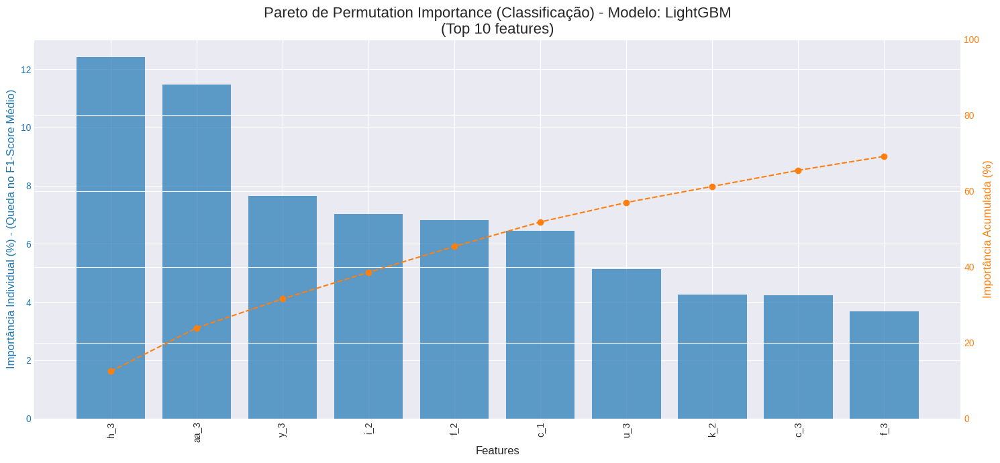


--- Processando Modelo: LogisticRegression ---
Calculando Permutation Importance (agnóstico ao modelo)...


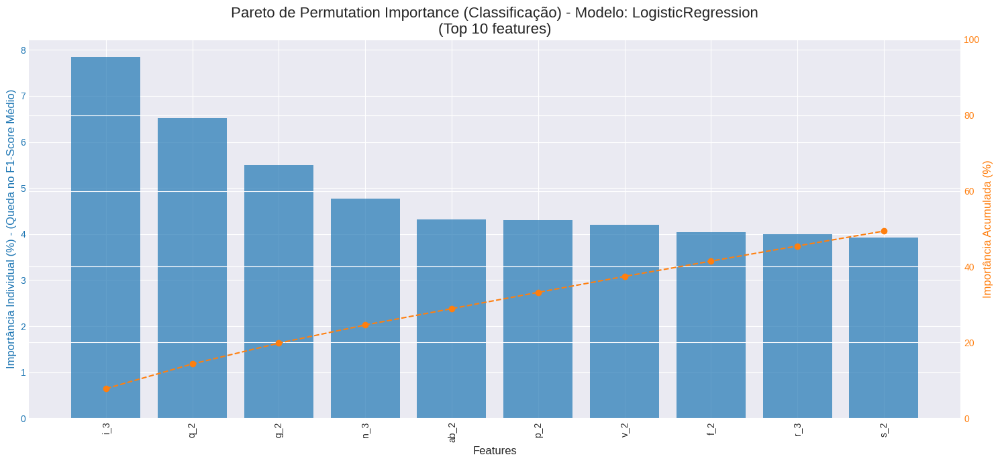


--- Processando Modelo: Lasso (LogReg L1) ---
Calculando Permutation Importance (agnóstico ao modelo)...


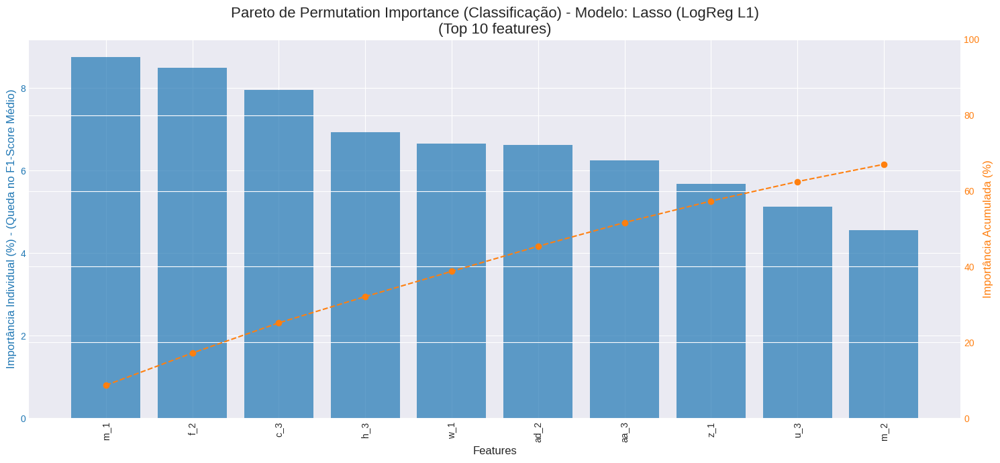


--- Processando Modelo: ElasticNet (LogReg) ---
Calculando Permutation Importance (agnóstico ao modelo)...


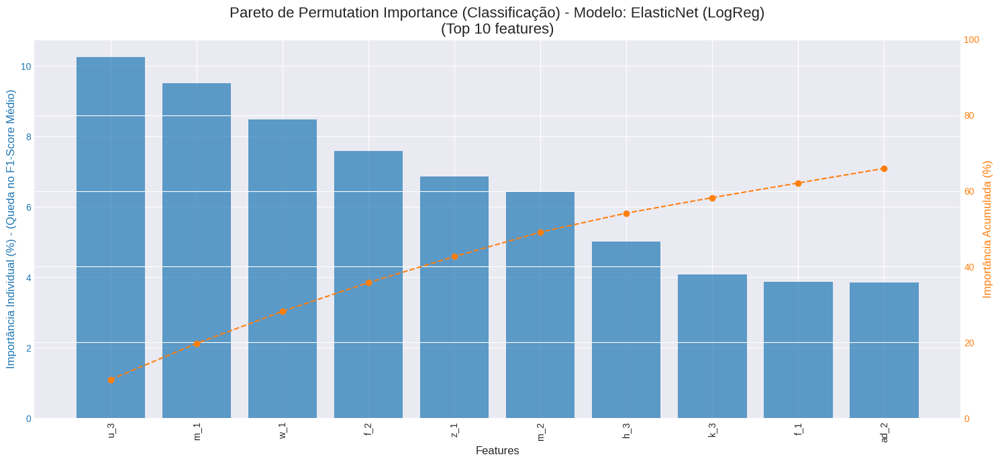


--- Processando Modelo: SGDClassifier ---
Calculando Permutation Importance (agnóstico ao modelo)...


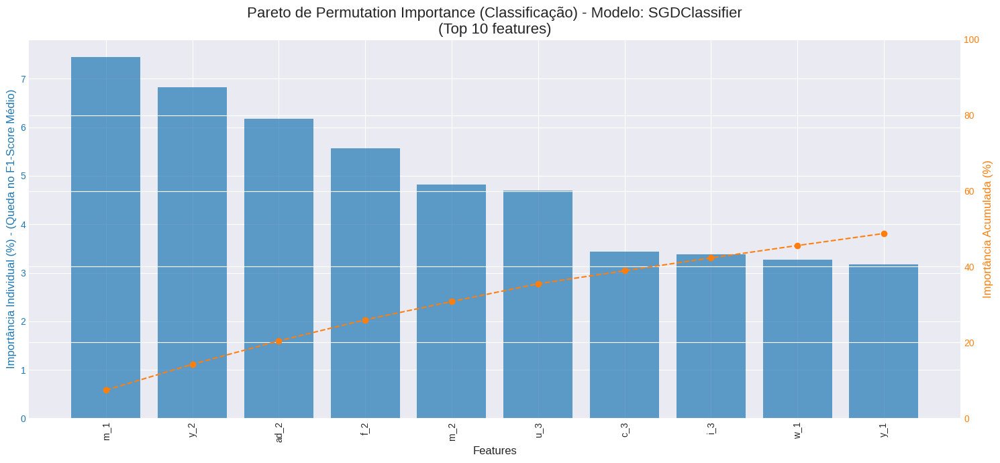


--- Processando Modelo: SVC ---
Calculando Permutation Importance (agnóstico ao modelo)...


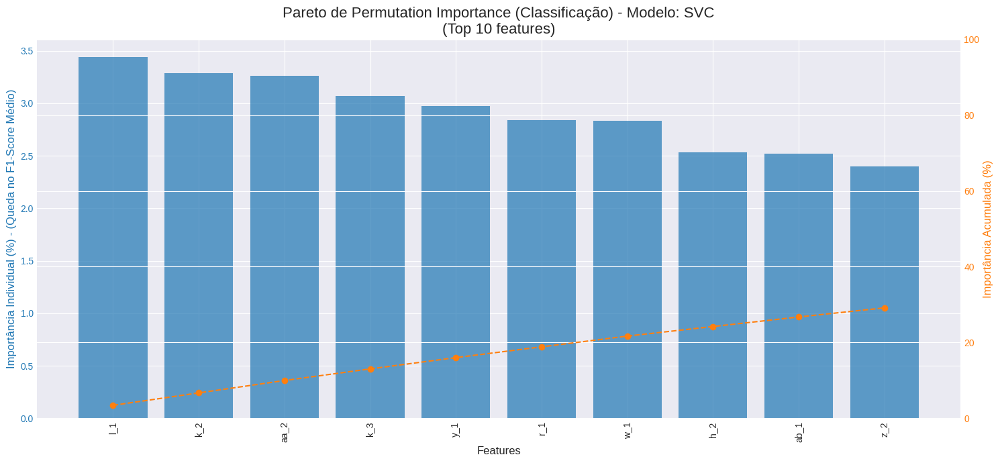


--- Processando Modelo: LinearSVC ---
Calculando Permutation Importance (agnóstico ao modelo)...


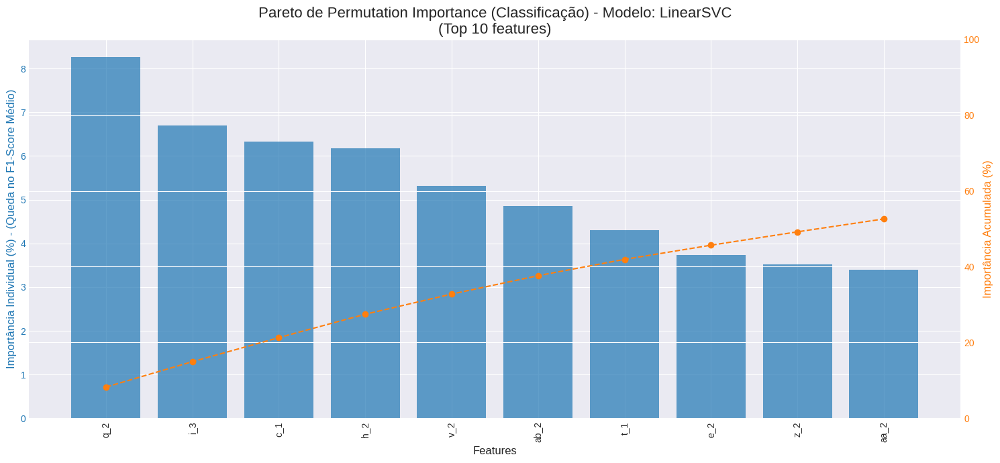


Concluído.


In [202]:
from sklearn.metrics import f1_score, make_scorer

# ====================================================================
# --- 1. THE FIX: CREATE A MULTI-OUTPUT SCORER ---
# ====================================================================

def multioutput_f1_scorer(y_true, y_pred):
    """
    Computes the 'weighted' F1-Score for EACH target (column)
    and returns the MEAN of the scores.
    """
    # y_true and y_pred are NumPy arrays (N, 7)
    n_targets = y_true.shape[1]
    scores = []

    # Numeric labels we are using
    labels = [0, 1, 2]

    for i in range(n_targets):
        # Compute the F1 for column 'i'
        score = f1_score(y_true[:, i], y_pred[:, i],
                         average='weighted',
                         labels=labels,
                         zero_division=0)
        scores.append(score)

    # Return the mean of the 7 scores
    return np.mean(scores)

# Create a "scorer" object that scikit-learn understands
custom_scorer = make_scorer(multioutput_f1_scorer, greater_is_better=True)

print("Avaliador (scorer) F1 Multi-Output customizado foi definido.")


# ====================================================================
# --- 2. YOUR PLOTTING CODE (WITH THE FIX APPLIED) ---
# ====================================================================

# --- Settings ---
N_TOP_FEATURES = 10
plt.style.use('seaborn-v0_8-darkgrid')

print("Iniciando geração de gráficos de importância (CLASSIFICAÇÃO)...")

# Main loop over each model
for nome, pipe in pipelines_class.items(): # <-- Fixed to pipelines_class
    print(f"\n--- Processando Modelo: {nome} ---")

    # 1. Train the model on the FULL dataset
    try:
        pipe.fit(X_class, y_class_numeric)
    except Exception as e:
        print(f"Erro ao treinar {nome}: {e}")
        continue

    # 2. Extract the feature importances
    print("Calculando Permutation Importance (agnóstico ao modelo)...")
    importances = None

    try:
        result = permutation_importance(
            pipe,
            X_class,
            y_class_numeric,
            scoring=custom_scorer, # <--- CHANGE: Using our custom scorer
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )

        importances = result.importances_mean

    except Exception as e:
        print(f"Erro ao calcular Permutation Importance para {nome}: {e}")
        continue

    # 3. Check whether the importance can be extracted
    if importances is None:
        print(f"Modelo {nome} falhou no cálculo. Pulando...")
        continue

    # 4. Create the Pareto DataFrame
    feature_names = X_class.columns

    pareto_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    pareto_df['Importance'] = pareto_df['Importance'].clip(lower=0)

    total_importance = pareto_df['Importance'].sum()
    if total_importance == 0:
        print(f"Modelo {nome} não atribui importância a nenhuma feature (importância total é 0).")
        print("Pulando o gráfico de Pareto...")
        continue

    pareto_df['Importance (%)'] = (pareto_df['Importance'] / total_importance) * 100
    pareto_df['Cumulative (%)'] = pareto_df['Importance (%)'].cumsum()

    pareto_df_top = pareto_df.head(N_TOP_FEATURES)

    # 5. Plot the Pareto Chart
    fig, ax1 = plt.subplots(figsize=(15, 7))

    plt.title(f"Pareto de Permutation Importance (Classificação) - Modelo: {nome}\n(Top {N_TOP_FEATURES} features)", fontsize=16)

    color = 'C0'
    ax1.set_xlabel('Features', fontsize=12)
    ax1.set_ylabel(f'Importância Individual (%) - (Queda no F1-Score Médio)', color=color, fontsize=12)
    ax1.bar(pareto_df_top['Feature'], pareto_df_top['Importance (%)'], color=color, alpha=0.7)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.tick_params(axis='x', rotation=90)

    ax2 = ax1.twinx()
    color = 'C1'
    ax2.set_ylabel('Importância Acumulada (%)', color=color, fontsize=12)
    ax2.plot(pareto_df_top['Feature'], pareto_df_top['Cumulative (%)'], color=color, marker='o', linestyle='--')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 100)

    fig.tight_layout()
    plt.show()

print("\nConcluído.")

Preparando dados para PCA (shape de X_class: (32, 82))
PCA calculado. Número total de componentes: 32
Gerando Gráfico de Pareto do PCA...
Para reter 95% da variância, são necessários 19 componentes.


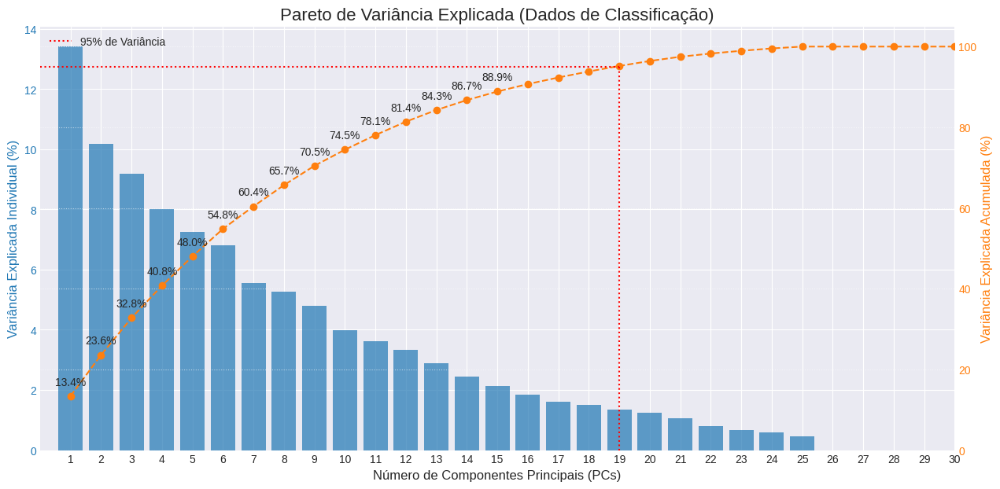

In [203]:
# ====================================================================
# --- 1. Prepare the Data for PCA ---
# ====================================================================
print(f"Preparando dados para PCA (shape de X_class: {X_class.shape})")
# It is crucial to scale the data BEFORE applying PCA

scaler = StandardScaler()

# CHANGE HERE: Using X_class (dummies) instead of X (continuous)
X_scaled = scaler.fit_transform(X_class)

# ====================================================================
# --- 2. Run PCA ---
# ====================================================================
# We instantiate PCA without setting n_components in order to get ALL of them
# so that the variance chart can be analysed
pca = PCA()
pca.fit(X_scaled)

# ====================================================================
# --- 3. Compute Explained Variance (Individual and Cumulative) ---
# ====================================================================
explained_variance = pca.explained_variance_ratio_ * 100 # As a percentage
cumulative_variance = np.cumsum(explained_variance)
n_components_total = len(explained_variance)

print(f"PCA calculado. Número total de componentes: {n_components_total}")

# ====================================================================
# --- 4. Plot the Pareto Chart ---
# ====================================================================
print("Gerando Gráfico de Pareto do PCA...")

fig, ax1 = plt.subplots(figsize=(15, 7))

# Bar chart for the individual variance
ax1.bar(range(1, n_components_total + 1), explained_variance, color='C0', alpha=0.7)
ax1.set_xlabel("Número de Componentes Principais (PCs)", fontsize=12)
ax1.set_ylabel("Variância Explicada Individual (%)", color='C0', fontsize=12)
ax1.tick_params(axis='y', labelcolor='C0')
ax1.set_title("Pareto de Variância Explicada (Dados de Classificação)", fontsize=16)

# Create a secondary Y axis for the cumulative variance
ax2 = ax1.twinx()
ax2.plot(range(1, n_components_total + 1), cumulative_variance, color='C1', marker='o', linestyle='--')
ax2.set_ylabel("Variância Explicada Acumulada (%)", color='C1', fontsize=12)
ax2.tick_params(axis='y', labelcolor='C1')
ax2.set_ylim(0, 105) # Show up to slightly above 100%

# Add percentage labels on the line
for i, txt in enumerate(cumulative_variance):
    # Show labels only for the first 15 PCs to avoid clutter
    if i < 15:
        ax2.annotate(f'{txt:.1f}%', (i + 1, txt), textcoords="offset points", xytext=(0, 10), ha='center')

# Add a 95% (or 90%) line
# (Optional, but useful)
target_variance = 95
components_for_95 = np.argmax(cumulative_variance >= target_variance) + 1
if components_for_95 > 0 and components_for_95 < n_components_total:
    ax2.hlines(target_variance, 0, components_for_95, linestyles='dotted', colors='red', label=f'{target_variance}% de Variância')
    ax2.vlines(components_for_95, 0, target_variance, linestyles='dotted', colors='red')
    print(f"Para reter {target_variance}% da variância, são necessários {components_for_95} componentes.")
    ax2.legend()

plt.xticks(range(1, n_components_total + 1))
# Limit the X axis (still very useful, since you have N=32)
# With N=32, you will only have 31 components with variance.
# The line below limits the chart to 30 components.
plt.xlim(0, min(n_components_total + 1, 30))

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [204]:
# ====================================================================
# --- 1. Settings ---
# ====================================================================
N_COMPONENTES_ESCOLHIDO = 3

print(f"Iniciando avaliação de CLASSIFICAÇÃO com PCA (n_components={N_COMPONENTES_ESCOLHIDO})...")

# ====================================================================
# --- 2. Dictionary of Pipelines with PCA (for Classification) ---
# ====================================================================
pipelines_com_pca_class = {}

# --- Native Models (Group 1) ---
# (These support multi-output and will be trained directly)
modelos_nativos_class = {
    'DummyClassifier': DummyClassifier(strategy='most_frequent'),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42),
    'ExtraTrees': ExtraTreesClassifier(random_state=42),
    'KNeighbors': KNeighborsClassifier()
}

for nome, modelo in modelos_nativos_class.items():
    pipelines_com_pca_class[nome] = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=N_COMPONENTES_ESCOLHIDO)),
        ('model', modelo)
    ])

# --- Models with Wrapper (Group 2) ---
# (These do NOT support multi-output and require the Wrapper)
kernel_gpc = C(1.0) * RBF(1.0)
modelos_wrapper_class = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'Lasso (LogReg L1)': LogisticRegression(penalty='l1', solver='liblinear', random_state=42),
    'ElasticNet (LogReg)': LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, max_iter=1000),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42),
    'LinearSVC': LinearSVC(random_state=42, max_iter=5000, dual=True),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'LightGBM': lgb.LGBMClassifier(random_state=42, n_estimators=50, min_child_samples=1, n_jobs=1, verbose=-1),
    'XGBoost': xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss'),
    'CatBoost': CatBoostClassifierWithIntOutput(random_state=42, verbose=0), # Using the wrapper we created
    'BernoulliNB': BernoulliNB(),
    'MLPClassifier': MLPClassifier(random_state=42, max_iter=1000, early_stopping=True),
    'GPC': GaussianProcessClassifier(kernel=kernel_gpc, random_state=42)
}

for nome, modelo in modelos_wrapper_class.items():
    pipelines_com_pca_class[nome] = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=N_COMPONENTES_ESCOLHIDO)),
        ('model', MultiOutputClassifier(modelo)) # <-- Using MultiOutputClassifier
    ])

print(f"Total de {len(pipelines_com_pca_class)} pipelines de CLASSIFICAÇÃO com PCA definidos.")


# ====================================================================
# --- 3. Metrics Table (for Classification) ---
# ====================================================================
results_list_pca_class = []
target_names = y_class_all.columns # Names 'ae', 'af', ...
numeric_labels = [0, 1, 2] # Classes ['Regular', 'Bom', 'Ótimo']

# We use X_class (dummies) and y_class_numeric (ints [0, 1, 2])
# We use 'cv' (KFold) because 'y' is multi-output
for nome, pipe in pipelines_com_pca_class.items():
    print(f"Processando: {nome}...")
    try:
        y_pred = cross_val_predict(pipe, X_class, y_class_numeric, cv=cv)

        # Loop to compute metrics for each of the 7 targets
        for i, target in enumerate(target_names):
            # Using NumPy indexing
            y_true_col = y_class_numeric[:, i]
            y_pred_col = y_pred[:, i]

            # --- CHANGE: Classification metric calculations ---
            accuracy = accuracy_score(y_true_col, y_pred_col)
            precision = precision_score(y_true_col, y_pred_col, average='weighted', labels=numeric_labels, zero_division=0)
            recall = recall_score(y_true_col, y_pred_col, average='weighted', labels=numeric_labels, zero_division=0)
            f1 = f1_score(y_true_col, y_pred_col, average='weighted', labels=numeric_labels, zero_division=0)

            results_list_pca_class.append({
                'Modelo': nome,
                'Target': target,
                'Accuracy': accuracy,
                'Precision (w)': precision,
                'Recall (w)': recall,
                'F1-Score (w)': f1
            })

    except Exception as e:
        print(f"!!!!!!!! ERRO EM {nome} !!!!!!!!")
        print(f"Erro: {e}")
        # Failure result
        results_list_pca_class.append({
            'Modelo': nome,
            'Target': target_names[0],
            'Accuracy': 0, 'Precision (w)': 0, 'Recall (w)': 0, 'F1-Score (w)': 0
        })

# ====================================================================
# --- 4. Analyse the results ---
# ====================================================================
metrics_df_pca_class = pd.DataFrame(results_list_pca_class)

# Summary table grouping the 7 targets
summary_df_pca_class = metrics_df_pca_class.groupby('Modelo').mean(numeric_only=True)

# CHANGE: Sorting by F1-Score
summary_df_pca_class = summary_df_pca_class.sort_values(by='F1-Score (w)', ascending=False)

print("\n--- Tabela Resumo (Média das Métricas de Classificação com PCA) ---")
# Display the final table formatted as HTML
display(summary_df_pca_class.style.format({
    'Accuracy': '{:.4f}',
    'Precision (w)': '{:.4f}',
    'Recall (w)': '{:.4f}',
    'F1-Score (w)': '{:.4f}'
}).background_gradient(cmap='viridis', subset=['F1-Score (w)']))

Iniciando avaliação de CLASSIFICAÇÃO com PCA (n_components=3)...
Total de 19 pipelines de CLASSIFICAÇÃO com PCA definidos.
Processando: DummyClassifier...
Processando: DecisionTree...
Processando: RandomForest...
Processando: ExtraTrees...
Processando: KNeighbors...
Processando: LogisticRegression...
Processando: Lasso (LogReg L1)...
Processando: ElasticNet (LogReg)...
Processando: SGDClassifier...
Processando: SVC...
Processando: LinearSVC...
Processando: GradientBoosting...
Processando: AdaBoost...
Processando: LightGBM...
Processando: XGBoost...
Processando: CatBoost...
Processando: BernoulliNB...
Processando: MLPClassifier...
Processando: GPC...

--- Tabela Resumo (Média das Métricas de Classificação com PCA) ---


,Accuracy,Precision (w),Recall (w),F1-Score (w)
Modelo,,,,
Lasso (LogReg L1),0.5446,0.5083,0.5446,0.5117
BernoulliNB,0.5357,0.4994,0.5357,0.5053
RandomForest,0.5134,0.4996,0.5134,0.4991
GPC,0.5179,0.4924,0.5179,0.4951
ExtraTrees,0.5089,0.4919,0.5089,0.4923
SVC,0.5491,0.4967,0.5491,0.4877
SGDClassifier,0.5000,0.4788,0.5000,0.4858
CatBoost,0.4955,0.4857,0.4955,0.4818
XGBoost,0.4821,0.4794,0.4821,0.4775


###**Re-evaluation**

In [205]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import KFold, StratifiedKFold

# --- General Settings ---
warnings.filterwarnings('ignore')
N_FEATURES_DESEJADO = 3
CV_SPLITS = 5

# Create BOTH CV splitters (we will need both)
# 1. For Multi-Output (Step 3 of your strategy)
cv_multi_output = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=42)
# 2. For Single-Output (Steps 1 and 2 of your strategy)
cv_single_output = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=42)
print("Setup de Classificação pronto.")

Setup de Classificação pronto.


In [206]:
# ====================================================================
# --- 1. DATA LOADING AND PREPARATION (ADAPTED) ---
# ====================================================================

# 1.1 Define X_bruto and y_all (continuous)
# (This is the same as in your code)
X_bruto = train_df_fteng.drop(['ae','af','ag','ah','ai','aj','ak'], axis=1)
y_all_continuous = train_df_fteng[['ae','af','ag','ah','ai','aj','ak']]
target_names = y_all_continuous.columns
print(f"Dados brutos carregados. X_bruto: {X_bruto.shape}, y_all_continuous: {y_all_continuous.shape}")

# --- NEW STEP: Convert Targets for Classification ---

# 1.2 Define Bin Edges and Labels (Regular, Bom, Ótimo)
bins = [-np.inf, np.nextafter(7.0, -np.inf), 7.5, np.inf]
class_labels = ['Regular', 'Bom', 'Ótimo'] # Class names
numeric_labels = [0, 1, 2] # Numeric labels

# 1.3 Apply pd.cut to create y_class_all (with strings)
y_class_all = pd.DataFrame(index=y_all_continuous.index)
for col in target_names:
    y_class_all[col] = pd.cut(y_all_continuous[col], bins=bins, labels=class_labels, right=True)
print(f"Targets classificados ('Regular', 'Bom', 'Ótimo') criados. Shape: {y_class_all.shape}")

# 1.4 Apply OrdinalEncoder (for XGBoost/CatBoost)
encoder = OrdinalEncoder(categories=[class_labels] * len(target_names))
y_class_numeric = encoder.fit_transform(y_class_all).astype(int)
print(f"Targets numéricos (0, 1, 2) criados. Shape: {y_class_numeric.shape}")

# ====================================================================
# --- 2. CREATE X_class (ADAPTED) ---
# ====================================================================
# This logic is the same as in your regression code,
# we just rename X_limpo -> X_class

print("\n--- Preparando X_class (com get_dummies) ---")
colunas_categoricas = X_bruto.select_dtypes(include=['object', 'category']).columns

if not colunas_categoricas.empty:
    print(f"Colunas categóricas encontradas em X_bruto: {list(colunas_categoricas)}")
    X_class = pd.get_dummies(X_bruto, columns=colunas_categoricas, drop_first=True)
else:
    print("Nenhuma coluna categórica encontrada em X_bruto.")
    X_class = X_bruto.copy() # Use .copy() to avoid warnings

print(f"\nSetup de dados concluído. N={len(y_class_all)} amostras.")
print(f"X_class (Features) Shape: {X_class.shape} (P={len(X_class.columns)})")
print(f"y_class_numeric (Targets) Shape: {y_class_numeric.shape}")

Dados brutos carregados. X_bruto: (32, 28), y_all_continuous: (32, 7)
Targets classificados ('Regular', 'Bom', 'Ótimo') criados. Shape: (32, 7)
Targets numéricos (0, 1, 2) criados. Shape: (32, 7)

--- Preparando X_class (com get_dummies) ---
Nenhuma coluna categórica encontrada em X_bruto.

Setup de dados concluído. N=32 amostras.
X_class (Features) Shape: (32, 28) (P=28)
y_class_numeric (Targets) Shape: (32, 7)


In [207]:
# REUSABLE EVALUATION FUNCTION (FIXED TO USE NUMERIC Y)

def run_single_output_classification_evaluation(pipelines_dict, X, y_numeric, target_names, cv):
    """
    Runs the evaluation of multiple pipelines on multiple single-output targets (classification).
    Returns a DataFrame of metrics.
    'y_numeric' MUST be the NumPy array with classes (0, 1, 2).
    'cv' MUST be the StratifiedKFold.
    """
    results_list = []

    # Numeric labels we are using
    numeric_labels = [0, 1, 2]

    # OUTER loop: iterates over each target ('ae', 'af', ...)
    # The 'target' (string) is used only for the report
    for i, target in enumerate(target_names):
        print(f"\n--- Avaliando Target: {target} ---")

        # CHANGE: Takes column [i] of the NumPy array y_numeric
        y_target = y_numeric[:, i]

        # INNER loop: iterates over each model
        for nome, pipe in pipelines_dict.items():
            try:
                # CHANGE: Using 'cv_single_output' (StratifiedKFold)
                y_pred = cross_val_predict(pipe, X, y_target, cv=cv)

                # --- CHANGE: Classification Metrics ---
                accuracy = accuracy_score(y_target, y_pred)
                precision = precision_score(y_target, y_pred, average='weighted', zero_division=0, labels=numeric_labels)
                recall = recall_score(y_target, y_pred, average='weighted', zero_division=0, labels=numeric_labels)
                f1 = f1_score(y_target, y_pred, average='weighted', zero_division=0, labels=numeric_labels)

                results_list.append({
                    'Modelo': nome,
                    'Target': target,
                    'Accuracy': accuracy,
                    'Precision (w)': precision,
                    'Recall (w)': recall,
                    'F1-Score (w)': f1
                })
            except Exception as e:
                print(f"!!!!!!!! ERRO ao processar {nome} para {target}: {e} !!!!!!!!")
                results_list.append({
                    'Modelo': nome,
                    'Target': target,
                    'Accuracy': np.nan, 'Precision (w)': np.nan, 'Recall (w)': np.nan, 'F1-Score (w)': np.nan
                })

    print("\nFunção de avaliação single-output de classificação concluída.")
    return pd.DataFrame(results_list)

In [208]:
# STEP 1: Single Output (All Features) - CLASSIFICATION

print("\n" + "="*50)
print("INICIANDO PASSO 1: Single Output (Classificação - Todas as Features)")
print("="*50)

def define_pipelines_step1_class():
    """
    Defines pipelines for CLASSIFICATION SINGLE-OUTPUT.
    NO MultiOutputClassifier is used.
    """
    pipelines_s1_class = {}

    # --- Group 1: Trees and Naive Bayes (No Scaler) ---
    pipelines_s1_class['DummyClassifier'] = Pipeline([('model', DummyClassifier(strategy='most_frequent'))])
    pipelines_s1_class['DecisionTree'] = Pipeline([('model', DecisionTreeClassifier(random_state=42))])
    pipelines_s1_class['RandomForest'] = Pipeline([('model', RandomForestClassifier(random_state=42))])
    pipelines_s1_class['ExtraTrees'] = Pipeline([('model', ExtraTreesClassifier(random_state=42))])
    pipelines_s1_class['GradientBoosting'] = Pipeline([('model', GradientBoostingClassifier(random_state=42))])
    pipelines_s1_class['AdaBoost'] = Pipeline([('model', AdaBoostClassifier(random_state=42))])
    pipelines_s1_class['XGBoost'] = Pipeline([('model', xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss'))])
    pipelines_s1_class['LightGBM'] = Pipeline([('model', lgb.LGBMClassifier(random_state=42, verbose=-1, min_child_samples=1, n_jobs=1))])
    pipelines_s1_class['CatBoost'] = Pipeline([('model', CatBoostClassifierWithIntOutput(random_state=42, verbose=0))])
    pipelines_s1_class['BernoulliNB'] = Pipeline([('model', BernoulliNB())])

    # --- Group 2: Distance/Gradient (With StandardScaler) ---
    pipelines_s1_class['LogisticRegression'] = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(random_state=42, max_iter=1000))])
    pipelines_s1_class['Lasso (LogReg L1)'] = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(penalty='l1', solver='liblinear', random_state=42))])
    pipelines_s1_class['ElasticNet (LogReg)'] = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, max_iter=1000))])
    pipelines_s1_class['KNeighbors'] = Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier())])
    pipelines_s1_class['SVC'] = Pipeline([('scaler', StandardScaler()), ('model', SVC(random_state=42))])
    pipelines_s1_class['LinearSVC'] = Pipeline([('scaler', StandardScaler()), ('model', LinearSVC(random_state=42, max_iter=5000, dual=True))])
    pipelines_s1_class['SGDClassifier'] = Pipeline([('scaler', StandardScaler()), ('model', SGDClassifier(random_state=42))])
    pipelines_s1_class['MLPClassifier'] = Pipeline([('scaler', StandardScaler()), ('model', MLPClassifier(random_state=42, max_iter=1000, early_stopping=True))])

    kernel_gpc = C(1.0) * RBF(1.0)
    pipelines_s1_class['GPC'] = Pipeline([('scaler', StandardScaler()), ('model', GaussianProcessClassifier(kernel=kernel_gpc, random_state=42))])

    return pipelines_s1_class

# --- Running Step 1 (Classification) ---
pipelines_s1_class = define_pipelines_step1_class()
print(f"\n{len(pipelines_s1_class)} pipelines de classificação definidos para o Passo 1.")

# ====================================================================
# --- MAIN CHANGE HERE ---
# Calling the new function with the NUMERIC data
# X_class = Dummies of the features
# y_class_numeric = NumPy array (N, 7) with ints [0, 1, 2]
# cv_single_output = StratifiedKFold
# ====================================================================
metrics_df_s1_class = run_single_output_classification_evaluation(
    pipelines_s1_class,
    X_class,
    y_class_numeric, # <-- CHANGE: y_class_all -> y_class_numeric
    target_names,
    cv=cv_single_output # <-- CHANGE: Using StratifiedKFold
)

print("\n--- RESULTADO PASSO 1 (Classificação): Resumo (Média das Métricas por Modelo) ---")
summary_s1_class = metrics_df_s1_class.groupby('Modelo').mean(numeric_only=True).sort_values(by='F1-Score (w)', ascending=False)

# Display the final table formatted as HTML
display(summary_s1_class.style.format({
    'Accuracy': '{:.4f}',
    'Precision (w)': '{:.4f}',
    'Recall (w)': '{:.4f}',
    'F1-Score (w)': '{:.4f}'
}).background_gradient(cmap='viridis', subset=['F1-Score (w)']))


INICIANDO PASSO 1: Single Output (Classificação - Todas as Features)

19 pipelines de classificação definidos para o Passo 1.

--- Avaliando Target: ae ---

--- Avaliando Target: af ---

--- Avaliando Target: ag ---

--- Avaliando Target: ah ---

--- Avaliando Target: ai ---

--- Avaliando Target: aj ---

--- Avaliando Target: ak ---

Função de avaliação single-output de classificação concluída.

--- RESULTADO PASSO 1 (Classificação): Resumo (Média das Métricas por Modelo) ---


,Accuracy,Precision (w),Recall (w),F1-Score (w)
Modelo,,,,
KNeighbors,0.5670,0.5473,0.5670,0.5422
ElasticNet (LogReg),0.5446,0.5298,0.5446,0.5362
Lasso (LogReg L1),0.5402,0.5338,0.5402,0.5341
ExtraTrees,0.5268,0.5276,0.5268,0.5259
CatBoost,0.5089,0.5042,0.5089,0.5050
LogisticRegression,0.5089,0.5025,0.5089,0.5042
RandomForest,0.5045,0.5003,0.5045,0.5001
AdaBoost,0.4955,0.5007,0.4955,0.4947
SGDClassifier,0.4911,0.4940,0.4911,0.4897


In [209]:
# STEP 2: Single Output (Top 3 Features) - CLASSIFICATION

print("\n" + "="*50)
print(f"INICIANDO PASSO 2: Single Output (Classificação - Top {N_FEATURES_DESEJADO} Features)")
print("="*50)

def define_pipelines_step2_class(n_features):
    """
    Defines pipelines for CLASSIFICATION SINGLE-OUTPUT with SelectFromModel.
    Uses different selectors for trees vs. linear models.
    """
    pipelines_s2_class = {}

    # --- Estimators for Selection ---

    # CHANGE: For trees, we use RandomForestClassifier
    selector_tree = SelectFromModel(
        RandomForestClassifier(random_state=42, n_estimators=50),
        max_features=n_features,
        prefit=False
    )

    # CHANGE: For linear models, we use LogisticRegression with L1 (Lasso)
    selector_linear = SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', random_state=42, max_iter=1000),
        max_features=n_features,
        prefit=False
    )

    # --- Group 1: Trees and Naive Bayes (No Scaler, with Tree Selector) ---
    pipelines_s2_class['DummyClassifier_Top3'] = Pipeline([('model', DummyClassifier(strategy='most_frequent'))]) # No selection
    pipelines_s2_class['DecisionTree_Top3'] = Pipeline([('selector', selector_tree), ('model', DecisionTreeClassifier(random_state=42))])
    pipelines_s2_class['RandomForest_Top3'] = Pipeline([('selector', selector_tree), ('model', RandomForestClassifier(random_state=42))])
    pipelines_s2_class['ExtraTrees_Top3'] = Pipeline([('selector', selector_tree), ('model', ExtraTreesClassifier(random_state=42))])
    pipelines_s2_class['GradientBoosting_Top3'] = Pipeline([('selector', selector_tree), ('model', GradientBoostingClassifier(random_state=42))])
    pipelines_s2_class['AdaBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', AdaBoostClassifier(random_state=42))])
    pipelines_s2_class['XGBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss'))])
    pipelines_s2_class['LightGBM_Top3'] = Pipeline([('selector', selector_tree), ('model', lgb.LGBMClassifier(random_state=42, verbose=-1, min_child_samples=1, n_jobs=1))])
    # Using the CatBoost wrapper we created
    pipelines_s2_class['CatBoost_Top3'] = Pipeline([('selector', selector_tree), ('model', CatBoostClassifierWithIntOutput(random_state=42, verbose=0))])
    pipelines_s2_class['BernoulliNB_Top3'] = Pipeline([('selector', selector_tree), ('model', BernoulliNB())])

    # --- Group 2: Distance/Gradient (With Scaler and Linear Selector) ---
    # CHANGE: Using StandardScaler instead of RobustScaler
    pipelines_s2_class['LogisticRegression_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', LogisticRegression(random_state=42, max_iter=1000))])
    pipelines_s2_class['Lasso_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', LogisticRegression(penalty='l1', solver='liblinear', random_state=42))])
    pipelines_s2_class['ElasticNet_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, max_iter=1000))])
    pipelines_s2_class['KNeighbors_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', KNeighborsClassifier())])
    pipelines_s2_class['SVC_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', SVC(random_state=42))])
    pipelines_s2_class['LinearSVC_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', LinearSVC(random_state=42, max_iter=5000, dual=True))])
    pipelines_s2_class['SGDClassifier_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', SGDClassifier(random_state=42))])
    pipelines_s2_class['MLPClassifier_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', MLPClassifier(random_state=42, max_iter=1000, early_stopping=True))])

    kernel_gpc = C(1.0) * RBF(1.0)
    pipelines_s2_class['GPC_Top3'] = Pipeline([('scaler', StandardScaler()), ('selector', selector_linear), ('model', GaussianProcessClassifier(kernel=kernel_gpc, random_state=42))])

    return pipelines_s2_class

# --- Running Step 2 (Classification) ---
pipelines_s2_class = define_pipelines_step2_class(n_features=N_FEATURES_DESEJADO)
print(f"\n{len(pipelines_s2_class)} pipelines de classificação definidos para o Passo 2.")

# ====================================================================
# --- MAIN CHANGE HERE ---
# Calling the CLASSIFICATION evaluation function
# X_class = Dummies of the features
# y_class_numeric = NumPy array (N, 7) with ints [0, 1, 2]
# cv_single_output = StratifiedKFold
# ====================================================================
metrics_df_s2_class = run_single_output_classification_evaluation(
    pipelines_s2_class,
    X_class,
    y_class_numeric,
    target_names,
    cv=cv_single_output
)

print("\n--- RESULTADO PASSO 2 (Classificação): Resumo (Média das Métricas por Modelo) ---")
# CHANGE: Sort by 'F1-Score (w)'
summary_s2_class = metrics_df_s2_class.groupby('Modelo').mean(numeric_only=True).sort_values(by='F1-Score (w)', ascending=False)

# Display the final table formatted as HTML
display(summary_s2_class.style.format({
    'Accuracy': '{:.4f}',
    'Precision (w)': '{:.4f}',
    'Recall (w)': '{:.4f}',
    'F1-Score (w)': '{:.4f}'
}).background_gradient(cmap='viridis', subset=['F1-Score (w)']))


INICIANDO PASSO 2: Single Output (Classificação - Top 3 Features)

19 pipelines de classificação definidos para o Passo 2.

--- Avaliando Target: ae ---

--- Avaliando Target: af ---

--- Avaliando Target: ag ---

--- Avaliando Target: ah ---

--- Avaliando Target: ai ---

--- Avaliando Target: aj ---

--- Avaliando Target: ak ---

Função de avaliação single-output de classificação concluída.

--- RESULTADO PASSO 2 (Classificação): Resumo (Média das Métricas por Modelo) ---


,Accuracy,Precision (w),Recall (w),F1-Score (w)
Modelo,,,,
SVC_Top3,0.5893,0.5818,0.5893,0.5715
Lasso_Top3,0.5536,0.5435,0.5536,0.5412
KNeighbors_Top3,0.5536,0.5391,0.5536,0.5388
LinearSVC_Top3,0.5491,0.5344,0.5491,0.5375
GPC_Top3,0.5491,0.5394,0.5491,0.5363
LogisticRegression_Top3,0.5446,0.5251,0.5446,0.5283
ElasticNet_Top3,0.5446,0.5239,0.5446,0.5269
SGDClassifier_Top3,0.5179,0.5269,0.5179,0.5177
RandomForest_Top3,0.5045,0.5071,0.5045,0.5009



INICIANDO PASSO 3: Multi-Output (Classificação - Top 3 Features)

19 pipelines de classificação definidos para o Passo 3.

Avaliando Modelo: DummyClassifier_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        11
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
wei

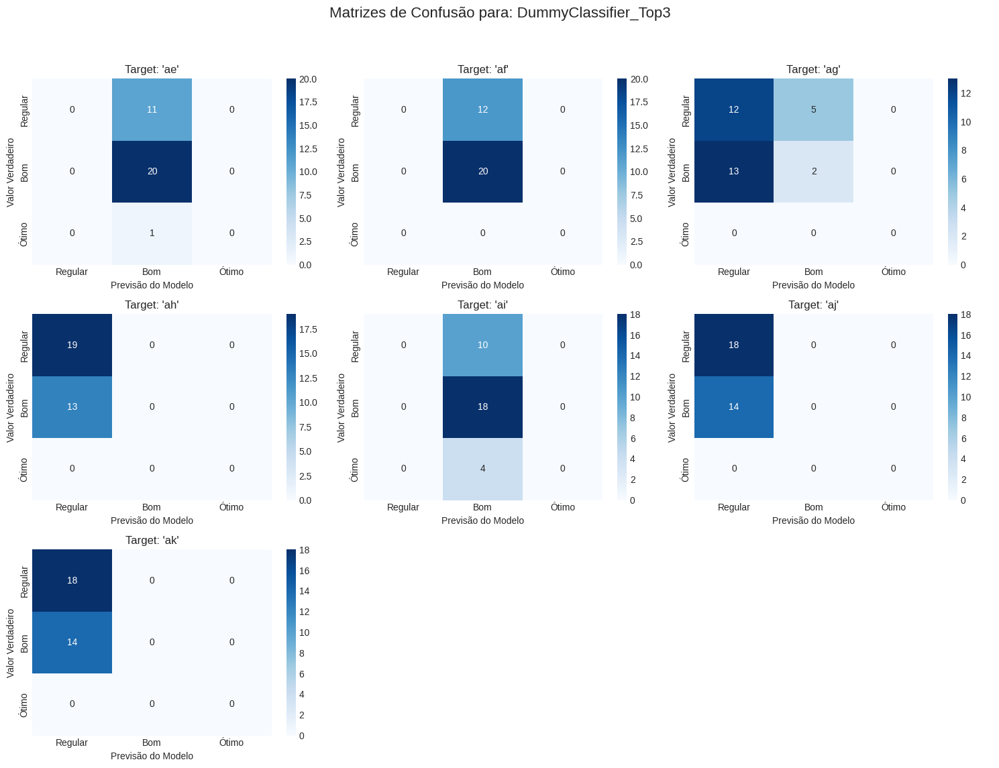


Avaliando Modelo: KNeighbors_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.25      0.09      0.13        11
         Bom       0.61      0.85      0.71        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.29      0.31      0.28        32
weighted avg       0.47      0.56      0.49        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.25      0.17      0.20        12
         Bom       0.58      0.70      0.64        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.50        32
   macro avg       0.28      0.29      0.28        32
weighted avg       0.46      0.50      0.47        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-s

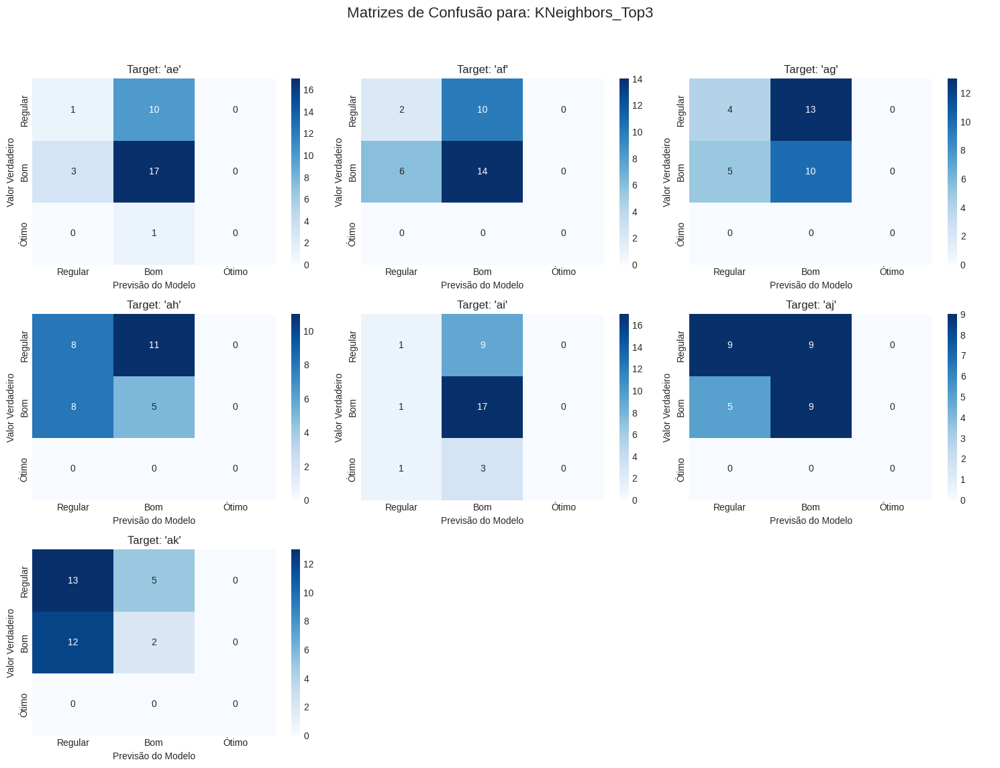


Avaliando Modelo: DecisionTree_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.55      0.46        11
         Bom       0.65      0.55      0.59        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.53        32
   macro avg       0.35      0.37      0.35        32
weighted avg       0.54      0.53      0.53        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.38      0.42      0.40        12
         Bom       0.63      0.60      0.62        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.34      0.34      0.34        32
weighted avg       0.54      0.53      0.53        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1

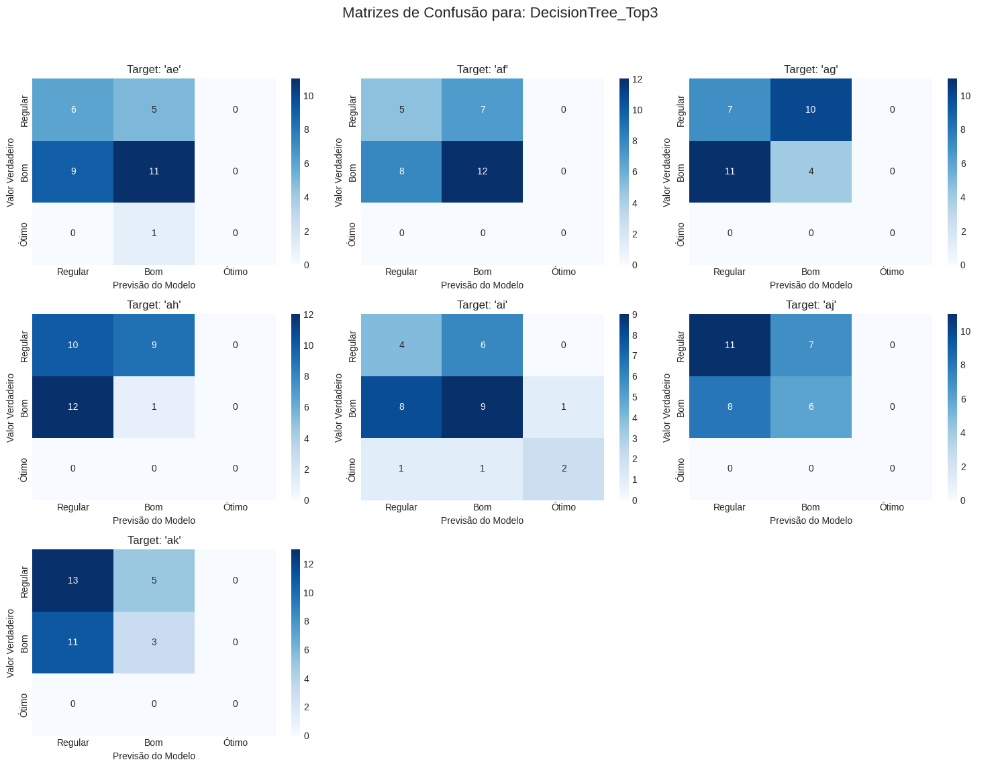


Avaliando Modelo: RandomForest_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.36      0.38        11
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.35      0.35      0.35        32
weighted avg       0.54      0.56      0.55        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.33      0.40        12
         Bom       0.67      0.80      0.73        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.38      0.38        32
weighted avg       0.60      0.62      0.60        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1

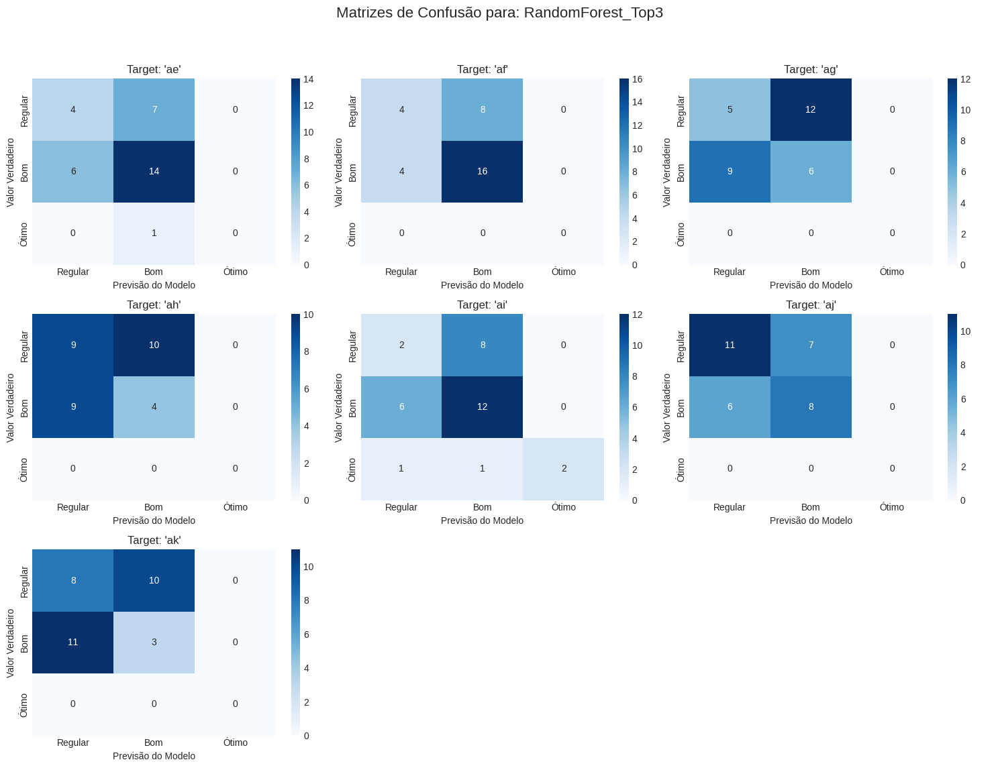


Avaliando Modelo: ExtraTrees_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.36      0.38        11
         Bom       0.64      0.70      0.67        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.35      0.35      0.35        32
weighted avg       0.54      0.56      0.55        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.42      0.45        12
         Bom       0.68      0.75      0.71        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.39      0.39        32
weighted avg       0.61      0.62      0.62        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-s

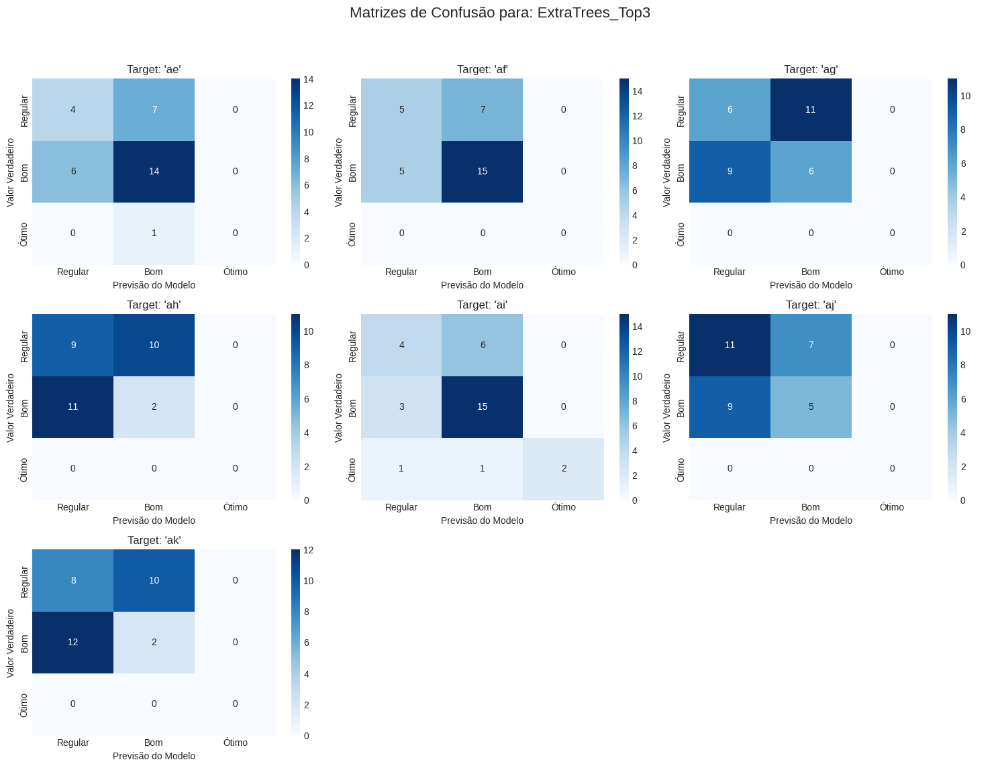


Avaliando Modelo: GradientBoosting_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.42      0.45      0.43        11
         Bom       0.65      0.65      0.65        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.36      0.37      0.36        32
weighted avg       0.55      0.56      0.56        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.46      0.50      0.48        12
         Bom       0.68      0.65      0.67        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.59        32
   macro avg       0.38      0.38      0.38        32
weighted avg       0.60      0.59      0.60        32


--- Relatório para Target: 'ag' ---
              precision    recall

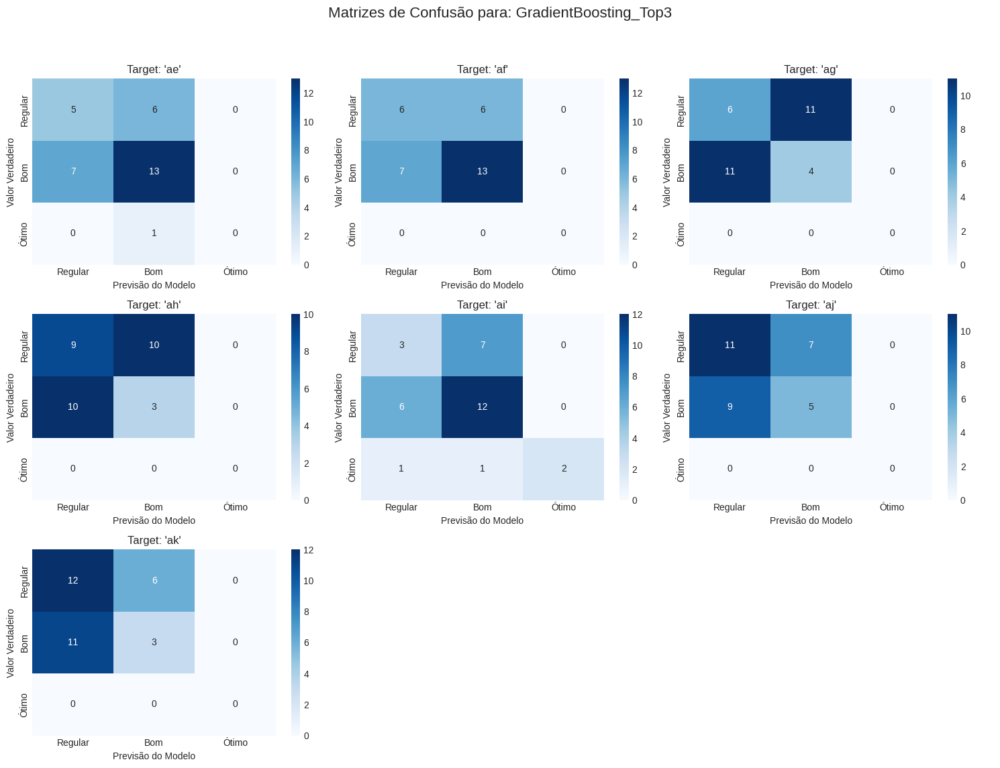


Avaliando Modelo: AdaBoost_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.38      0.27      0.32        11
         Bom       0.62      0.75      0.68        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.33      0.34      0.33        32
weighted avg       0.52      0.56      0.53        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.43      0.25      0.32        12
         Bom       0.64      0.80      0.71        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.59        32
   macro avg       0.36      0.35      0.34        32
weighted avg       0.56      0.59      0.56        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sco

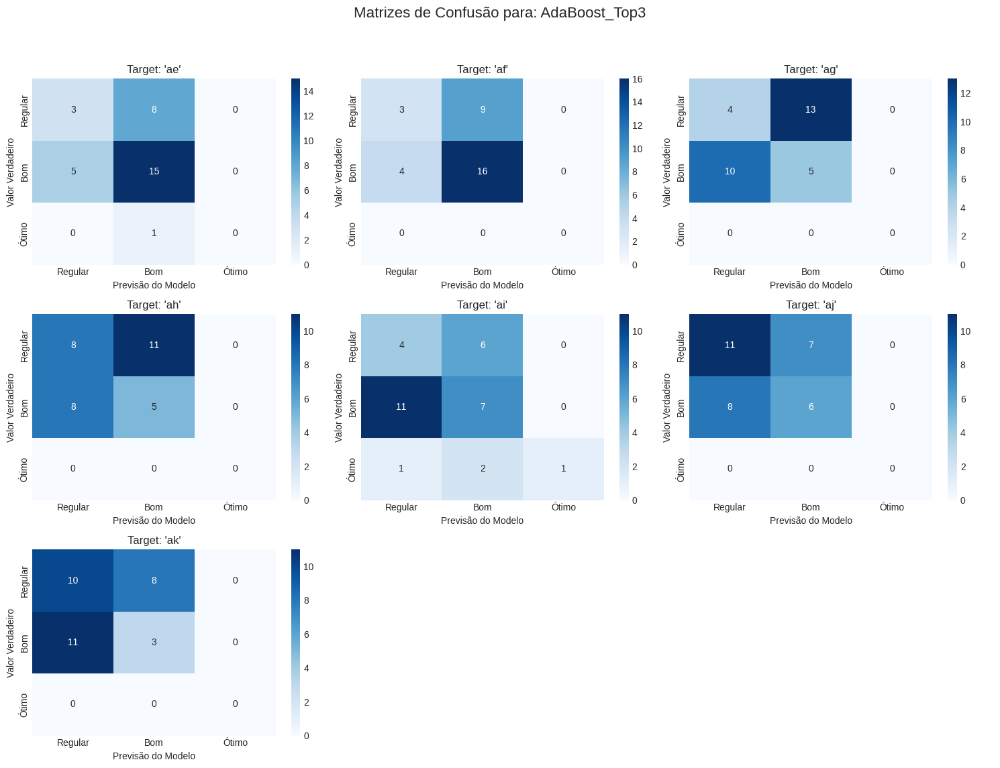


Avaliando Modelo: LightGBM_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.36      0.35        11
         Bom       0.60      0.60      0.60        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.50        32
   macro avg       0.31      0.32      0.32        32
weighted avg       0.49      0.50      0.49        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.33      0.33      0.33        12
         Bom       0.60      0.60      0.60        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.50        32
   macro avg       0.31      0.31      0.31        32
weighted avg       0.50      0.50      0.50        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sco

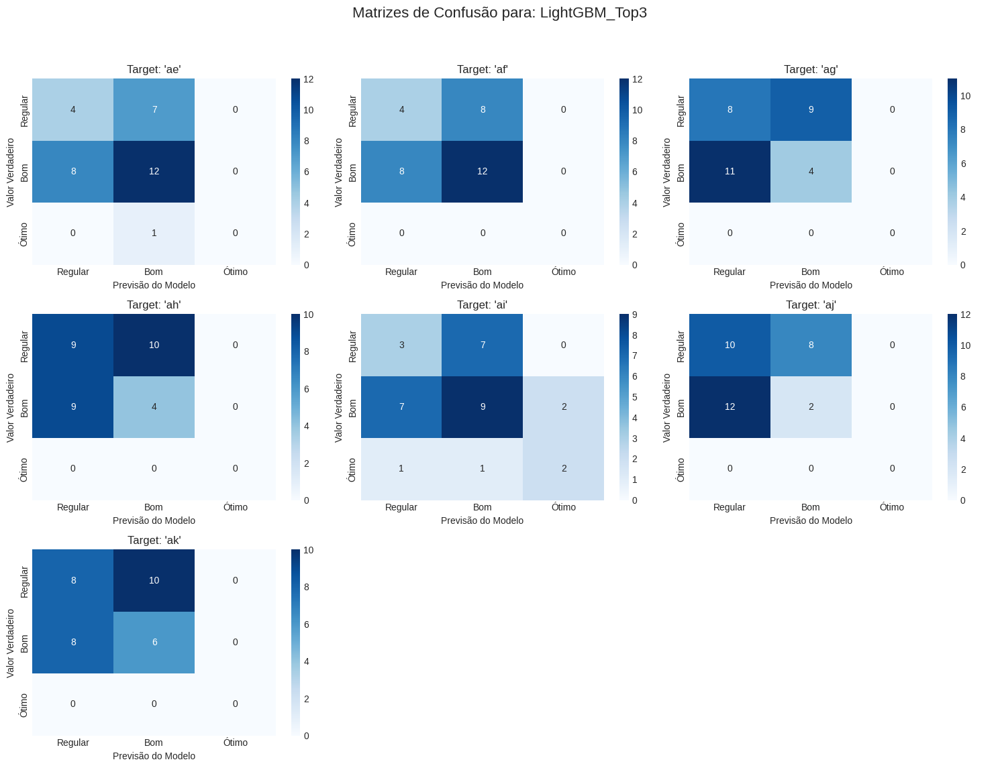


Avaliando Modelo: XGBoost_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.36      0.38        11
         Bom       0.68      0.75      0.71        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.36      0.37      0.37        32
weighted avg       0.56      0.59      0.58        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.33      0.40        12
         Bom       0.67      0.80      0.73        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.38      0.38        32
weighted avg       0.60      0.62      0.60        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-scor

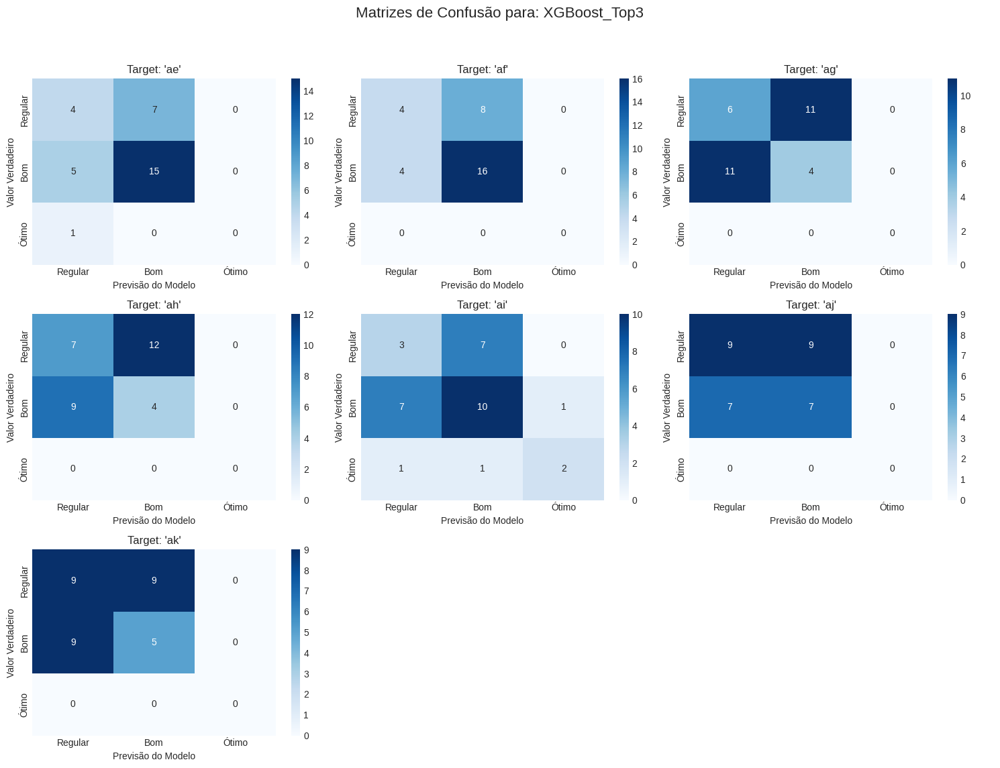


Avaliando Modelo: CatBoost_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.30      0.27      0.29        11
         Bom       0.62      0.65      0.63        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.50        32
   macro avg       0.31      0.31      0.31        32
weighted avg       0.49      0.50      0.49        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.50      0.33      0.40        12
         Bom       0.67      0.80      0.73        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.39      0.38      0.38        32
weighted avg       0.60      0.62      0.60        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sco

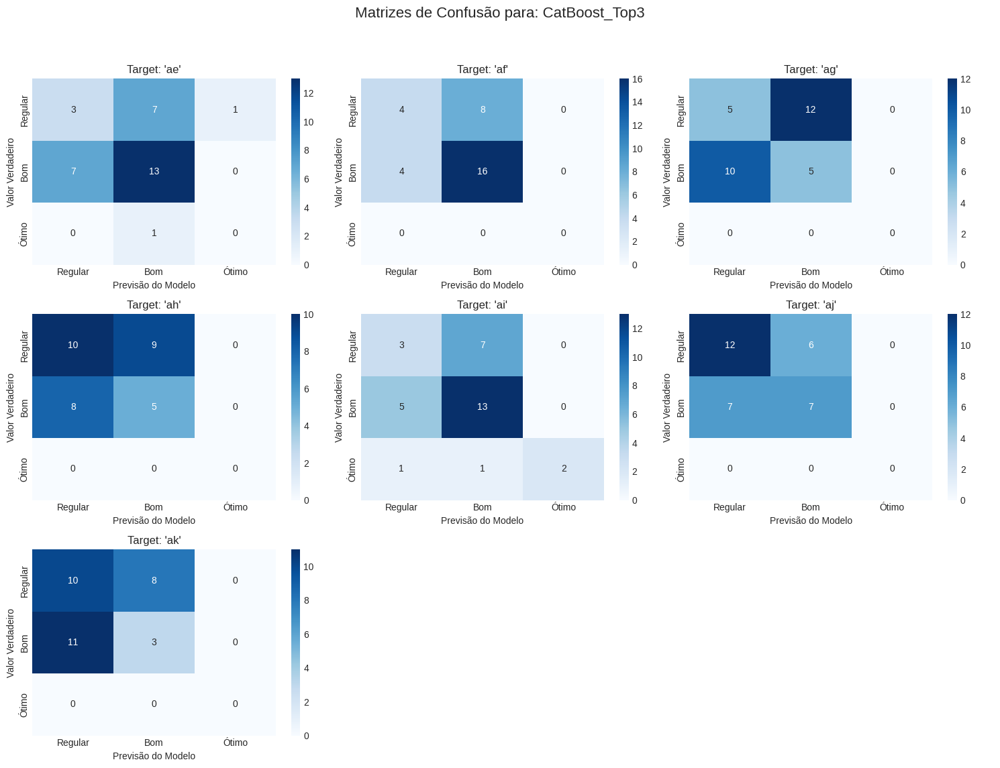


Avaliando Modelo: BernoulliNB_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        11
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-

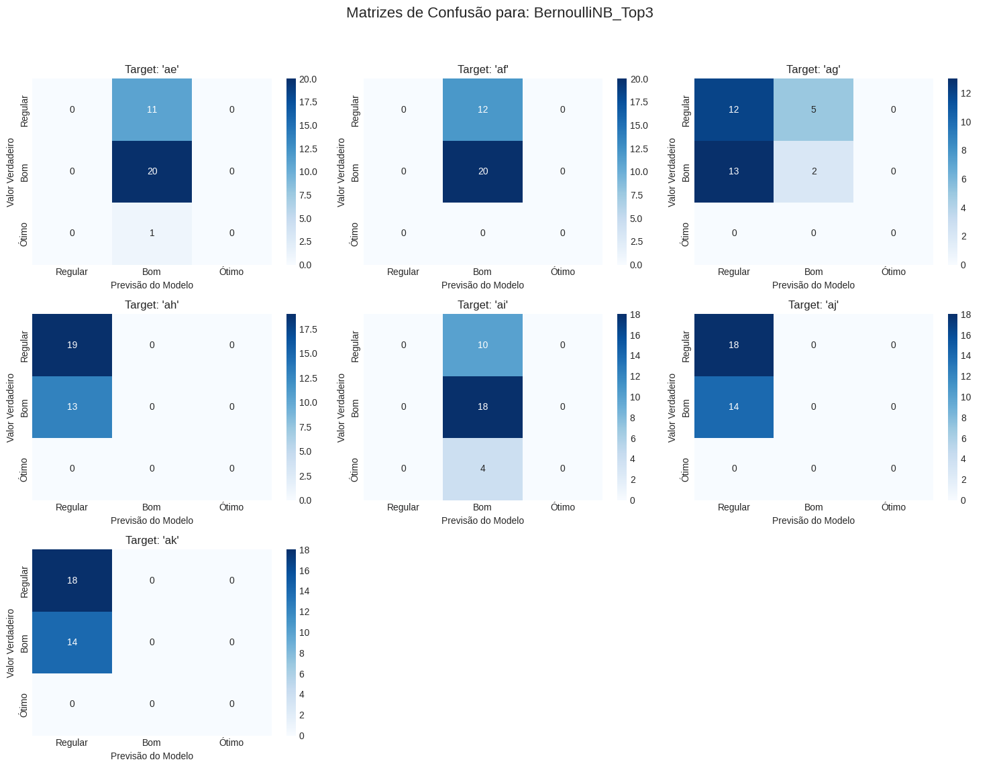


Avaliando Modelo: LogisticRegression_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.09      0.14        11
         Bom       0.62      0.90      0.73        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.32      0.33      0.29        32
weighted avg       0.50      0.59      0.51        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.59      0.85      0.69        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.20      0.28      0.23        32
weighted avg       0.37      0.53      0.43        32


--- Relatório para Target: 'ag' ---
              precision    reca

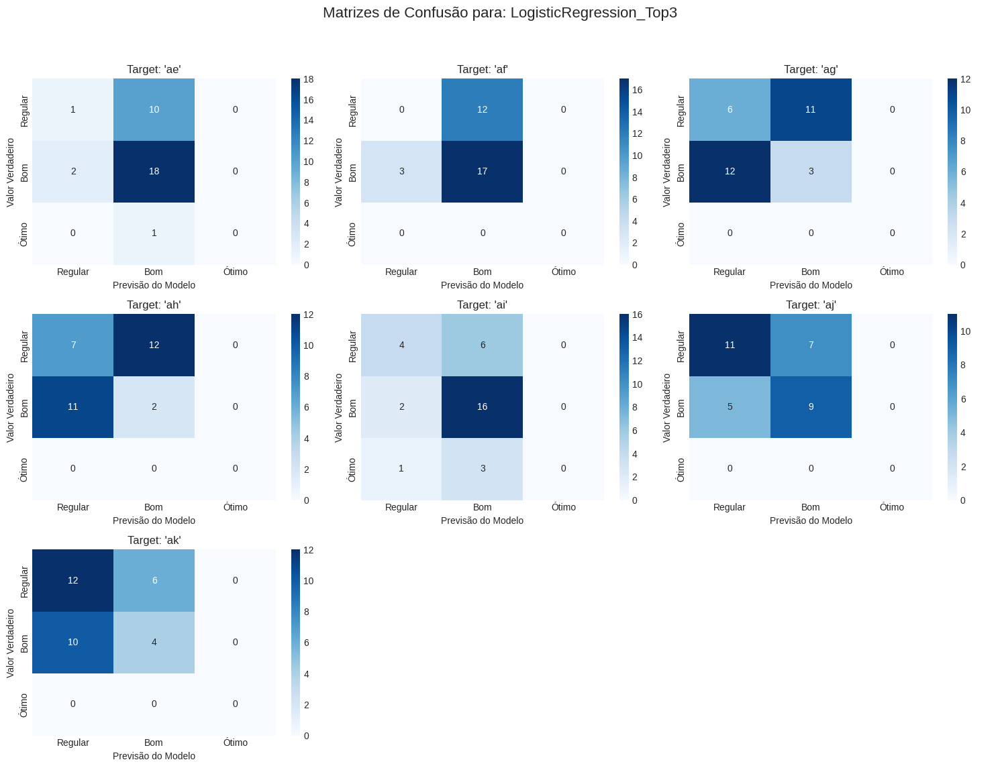


Avaliando Modelo: Lasso_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.50      0.27      0.35        11
         Bom       0.65      0.85      0.74        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.62        32
   macro avg       0.38      0.37      0.36        32
weighted avg       0.58      0.62      0.58        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.60      0.90      0.72        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.20      0.30      0.24        32
weighted avg       0.38      0.56      0.45        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score 

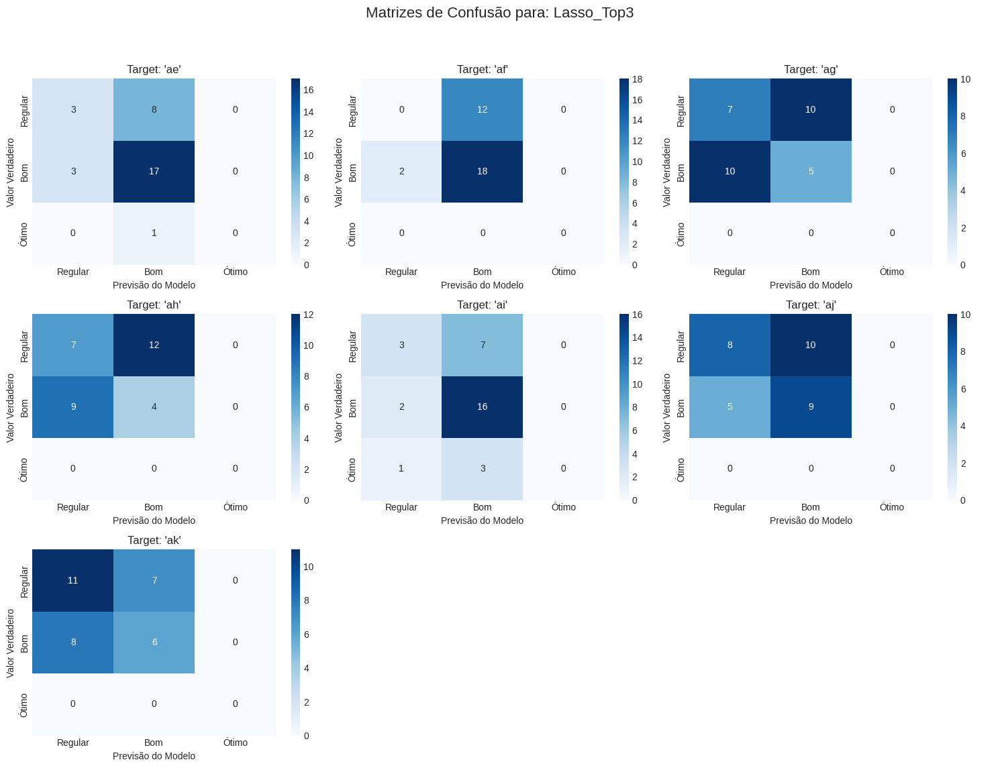


Avaliando Modelo: ElasticNet_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.09      0.14        11
         Bom       0.62      0.90      0.73        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.32      0.33      0.29        32
weighted avg       0.50      0.59      0.51        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.60      0.90      0.72        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.56        32
   macro avg       0.20      0.30      0.24        32
weighted avg       0.38      0.56      0.45        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-s

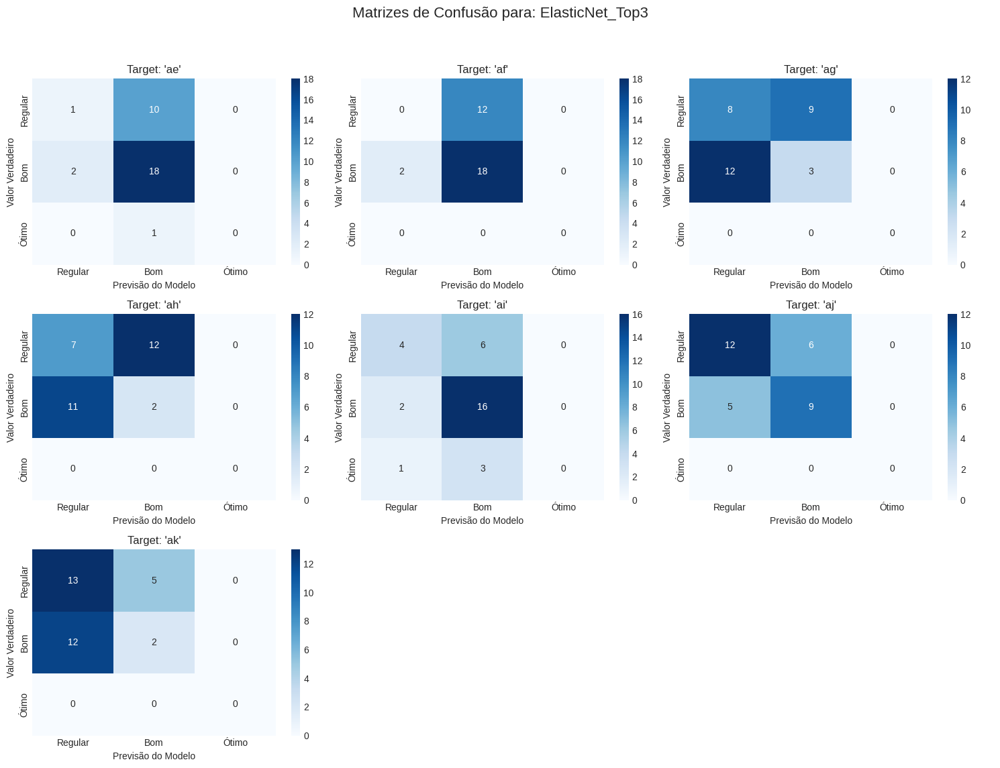


Avaliando Modelo: SGDClassifier_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.20      0.09      0.12        11
         Bom       0.58      0.70      0.64        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.47        32
   macro avg       0.26      0.26      0.25        32
weighted avg       0.43      0.47      0.44        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.41      0.58      0.48        12
         Bom       0.67      0.50      0.57        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.36      0.36      0.35        32
weighted avg       0.57      0.53      0.54        32


--- Relatório para Target: 'ag' ---
              precision    recall  f

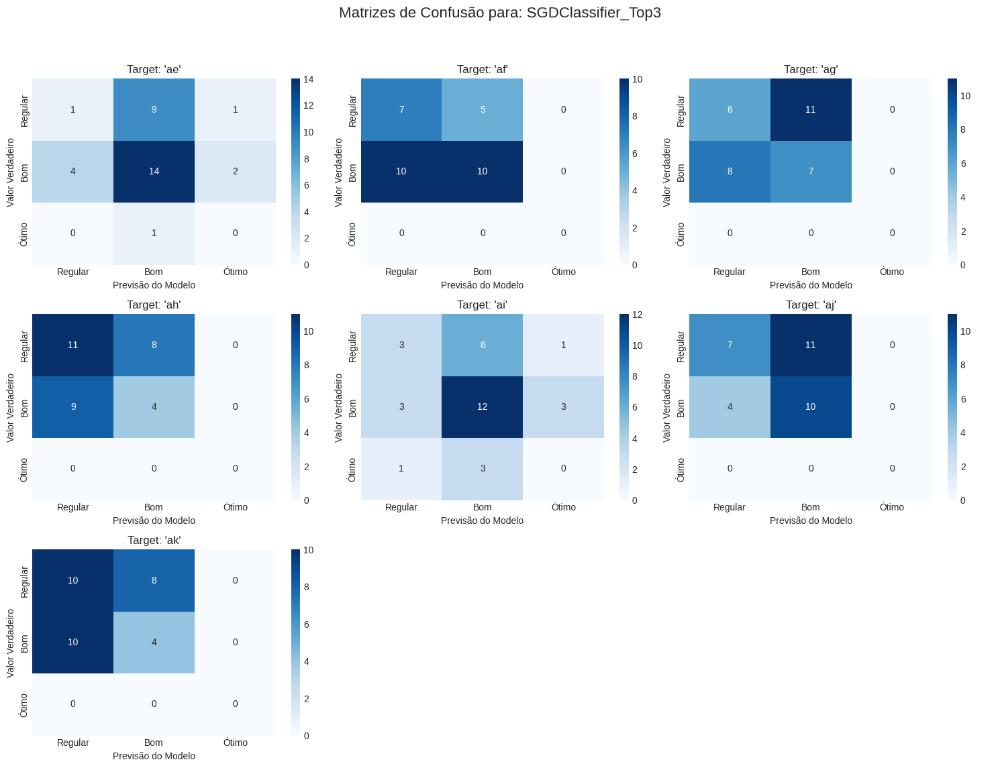


Avaliando Modelo: SVC_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.33      0.09      0.14        11
         Bom       0.62      0.90      0.73        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.32      0.33      0.29        32
weighted avg       0.50      0.59      0.51        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.33      0.08      0.13        12
         Bom       0.62      0.90      0.73        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.59        32
   macro avg       0.32      0.33      0.29        32
weighted avg       0.51      0.59      0.51        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score   

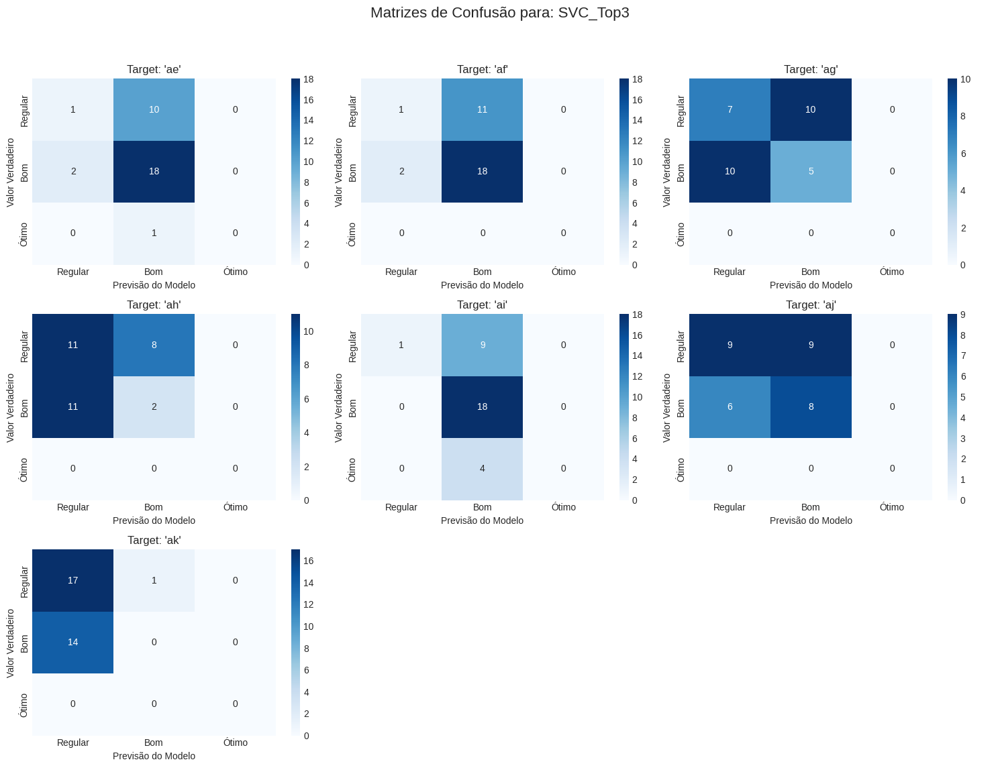


Avaliando Modelo: LinearSVC_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.50      0.18      0.27        11
         Bom       0.62      0.80      0.70        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.56        32
   macro avg       0.37      0.33      0.32        32
weighted avg       0.56      0.56      0.53        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.59      0.85      0.69        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.53        32
   macro avg       0.20      0.28      0.23        32
weighted avg       0.37      0.53      0.43        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-sc

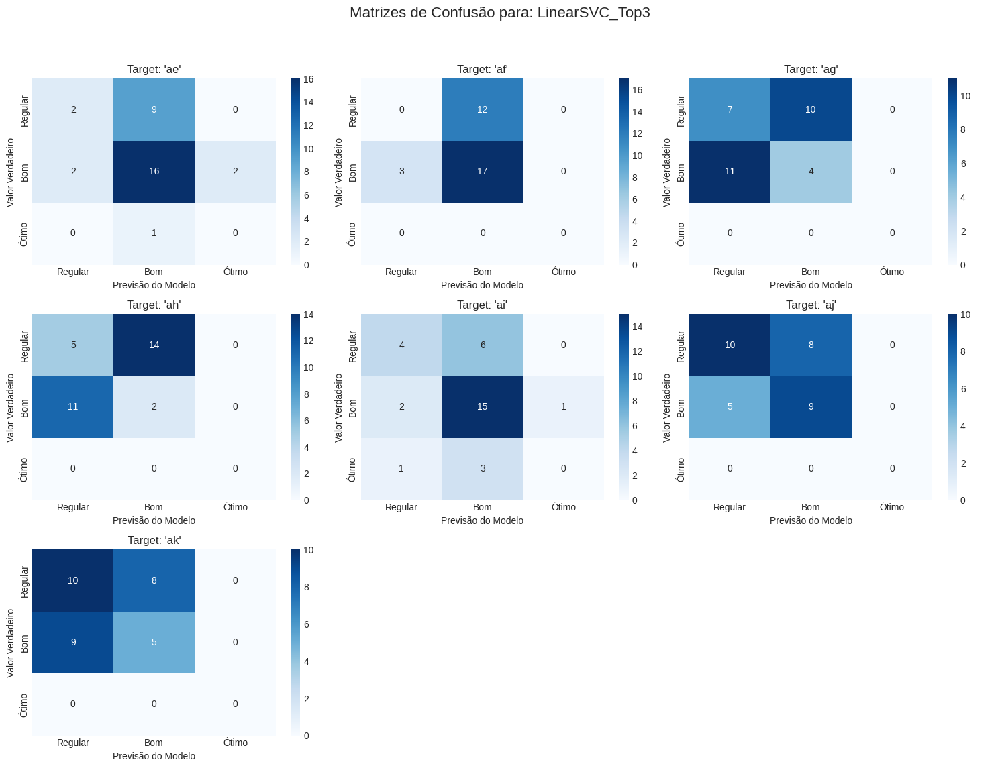


Avaliando Modelo: MLPClassifier_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.20      0.09      0.12        11
         Bom       0.56      0.50      0.53        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.34        32
   macro avg       0.25      0.20      0.22        32
weighted avg       0.42      0.34      0.37        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.00      0.00      0.00        12
         Bom       0.62      1.00      0.77        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.62        32
   macro avg       0.21      0.33      0.26        32
weighted avg       0.39      0.62      0.48        32


--- Relatório para Target: 'ag' ---
              precision    recall  f

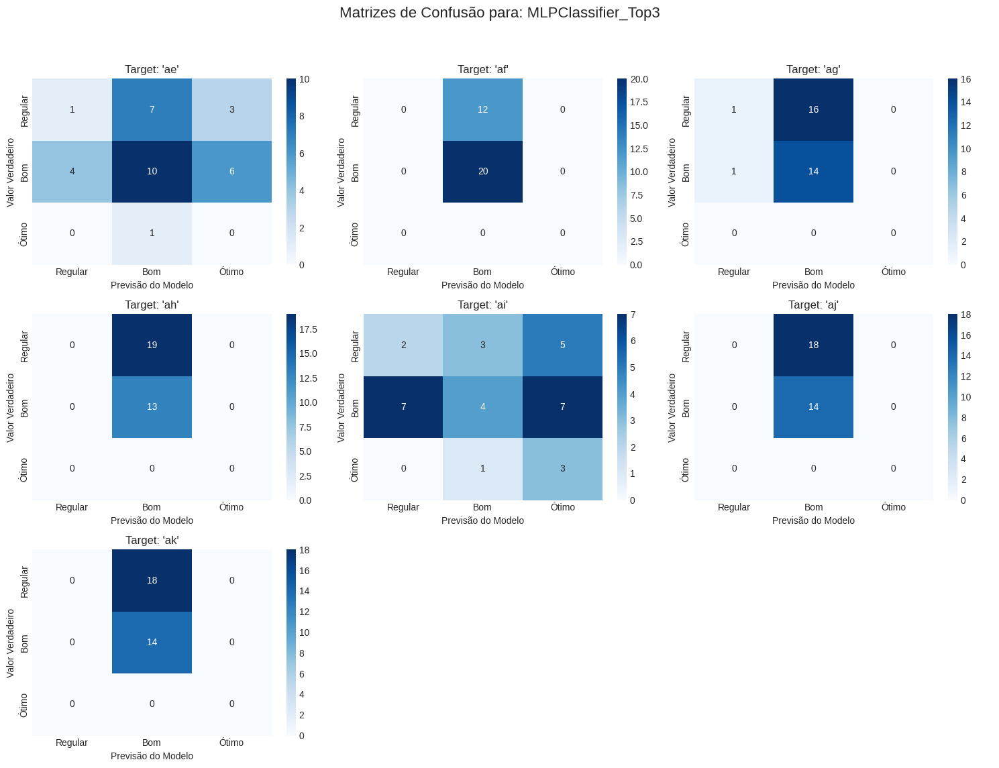


Avaliando Modelo: GPC_Top3
--- Relatório de Métricas Detalhado (por Output) ---

--- Relatório para Target: 'ae' ---
              precision    recall  f1-score   support

     Regular       0.40      0.18      0.25        11
         Bom       0.63      0.85      0.72        20
       Ótimo       0.00      0.00      0.00         1

    accuracy                           0.59        32
   macro avg       0.34      0.34      0.32        32
weighted avg       0.53      0.59      0.54        32


--- Relatório para Target: 'af' ---
              precision    recall  f1-score   support

     Regular       0.57      0.33      0.42        12
         Bom       0.68      0.85      0.76        20
       Ótimo       0.00      0.00      0.00         0

    accuracy                           0.66        32
   macro avg       0.42      0.39      0.39        32
weighted avg       0.64      0.66      0.63        32


--- Relatório para Target: 'ag' ---
              precision    recall  f1-score   

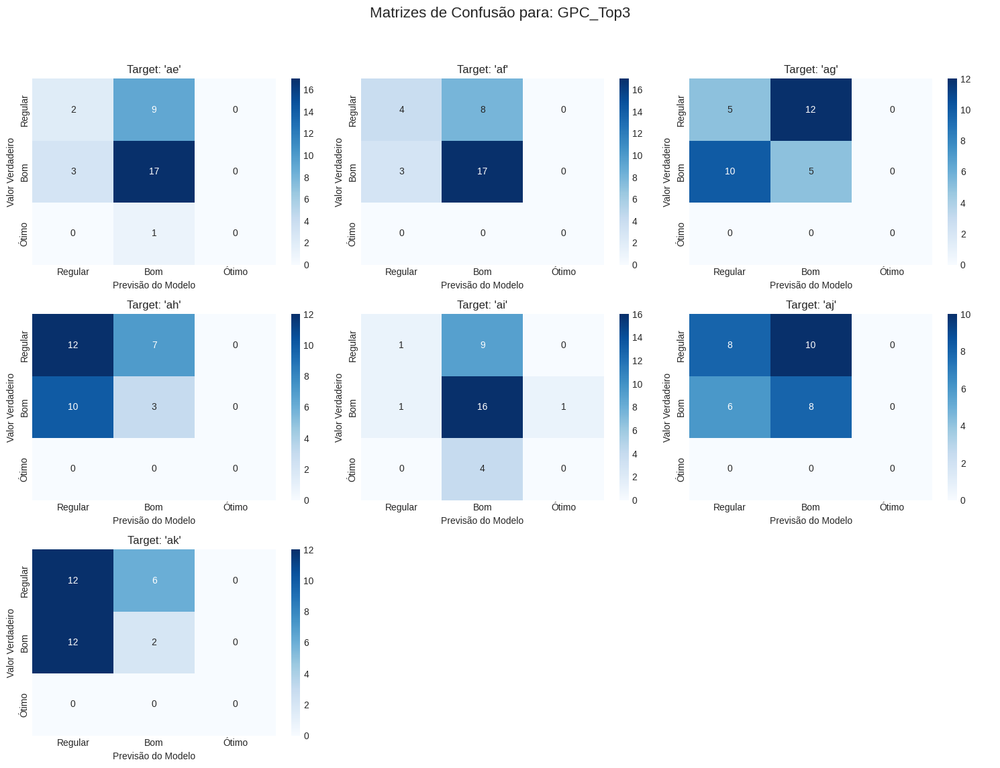


--- RESULTADO PASSO 3 (Classificação): Resumo (Média das Métricas por Modelo) ---


,Accuracy,Precision (w),Recall (w),F1-Score (w)
Modelo,,,,
CatBoost_Top3,0.4955,0.4914,0.4955,0.4893
Lasso_Top3,0.5089,0.4679,0.5089,0.4774
RandomForest_Top3,0.4821,0.4785,0.4821,0.4763
ExtraTrees_Top3,0.4821,0.4737,0.4821,0.4744
GradientBoosting_Top3,0.4777,0.4750,0.4777,0.4728
GPC_Top3,0.5000,0.4720,0.5000,0.4672
SGDClassifier_Top3,0.4732,0.4750,0.4732,0.4653
XGBoost_Top3,0.4688,0.4669,0.4688,0.4652
KNeighbors_Top3,0.5000,0.4599,0.5000,0.4606



AVALIAÇÃO EM 3 PASSOS (CLASSIFICAÇÃO) CONCLUÍDA


In [210]:
# (Make sure that all model and pipeline imports,
#  and the 'CatBoostClassifierWithIntOutput' class are in memory)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor # (Required by the selector)

# ====================================================================
# --- STEP 3: Multi-Output (Top 3 Features) - CLASSIFICATION ---
# ====================================================================

print("\n" + "="*50)
print(f"INICIANDO PASSO 3: Multi-Output (Classificação - Top {N_FEATURES_DESEJADO} Features)")
print("="*50)

def define_pipelines_step3_class(n_features):
    """
    Defines pipelines for CLASSIFICATION MULTI-OUTPUT with SelectFromModel.
    Uses a single selector (RandomForestRegressor) for all.

    FIX: ALL MODELS (except KNN and Dummy) are wrapped
    in MultiOutputClassifier.
    """
    pipelines_s3_class = {}

    # --- Model Imports (to be safe) ---
    from sklearn.dummy import DummyClassifier
    from sklearn.linear_model import LogisticRegression, SGDClassifier
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC, LinearSVC
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, AdaBoostClassifier
    from sklearn.neural_network import MLPClassifier
    from sklearn.gaussian_process import GaussianProcessClassifier
    from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
    from sklearn.naive_bayes import BernoulliNB
    import xgboost as xgb
    import lightgbm as lgb
    # (CatBoostClassifierWithIntOutput must already be defined)

    # --- Estimator for Selection ---
    selector = SelectFromModel(
        RandomForestRegressor(random_state=42, n_estimators=50),
        max_features=n_features,
        prefit=False
    )

    kernel_gpc = C(1.0) * RBF(1.0)

    # --- Model Dictionaries (Base) ---
    # NATIVE models (Group 1)
    models_native = {
        'DummyClassifier_Top3': DummyClassifier(strategy='most_frequent'),
        'KNeighbors_Top3': KNeighborsClassifier()
    }

    # WRAPPER models (Group 2)
    models_wrapper = {
        'DecisionTree_Top3': DecisionTreeClassifier(random_state=42),
        'RandomForest_Top3': RandomForestClassifier(random_state=42),
        'ExtraTrees_Top3': ExtraTreesClassifier(random_state=42),
        'GradientBoosting_Top3': GradientBoostingClassifier(random_state=42),
        'AdaBoost_Top3': AdaBoostClassifier(random_state=42),
        'LightGBM_Top3': lgb.LGBMClassifier(random_state=42, verbose=-1, min_child_samples=1, n_jobs=1),
        'XGBoost_Top3': xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss'),
        'CatBoost_Top3': CatBoostClassifierWithIntOutput(random_state=42, verbose=0),
        'BernoulliNB_Top3': BernoulliNB(),
        'LogisticRegression_Top3': LogisticRegression(random_state=42, max_iter=1000),
        'Lasso_Top3': LogisticRegression(penalty='l1', solver='liblinear', random_state=42),
        'ElasticNet_Top3': LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, max_iter=1000),
        'SGDClassifier_Top3': SGDClassifier(random_state=42),
        'SVC_Top3': SVC(random_state=42),
        'LinearSVC_Top3': LinearSVC(random_state=42, max_iter=5000, dual=True),
        'MLPClassifier_Top3': MLPClassifier(random_state=42, max_iter=1000, early_stopping=True),
        'GPC_Top3': GaussianProcessClassifier(kernel=kernel_gpc, random_state=42)
    }

    # --- Scaler Dictionaries ---
    # Models that require a scaler
    needs_scaler = [
        'KNeighbors_Top3', 'LogisticRegression_Top3', 'Lasso_Top3',
        'ElasticNet_Top3', 'SGDClassifier_Top3', 'SVC_Top3',
        'LinearSVC_Top3', 'MLPClassifier_Top3', 'GPC_Top3'
    ]

    # --- Building the Pipelines ---

    # Native Models
    for nome, modelo in models_native.items():
        if nome in needs_scaler:
            pipelines_s3_class[nome] = Pipeline([('scaler', StandardScaler()), ('selector', selector), ('model', modelo)])
        else:
            # DummyClassifier does not need a selector
            if 'Dummy' in nome:
                pipelines_s3_class[nome] = Pipeline([('model', modelo)])
            else:
                pipelines_s3_class[nome] = Pipeline([('selector', selector), ('model', modelo)])

    # Wrapper Models
    for nome, modelo in models_wrapper.items():
        if nome in needs_scaler:
            pipelines_s3_class[nome] = Pipeline([('scaler', StandardScaler()), ('selector', selector), ('model', MultiOutputClassifier(modelo))])
        else:
            pipelines_s3_class[nome] = Pipeline([('selector', selector), ('model', MultiOutputClassifier(modelo))])

    return pipelines_s3_class

# ====================================================================
# --- EVALUATION FUNCTION (FIXED) ---
# ====================================================================
def run_multi_output_classification_evaluation(pipelines_dict, X, y_numeric, target_names, cv):
    """
    Evaluation function (FIXED).
    """
    results_list = []
    class_labels = ['Regular', 'Bom', 'Ótimo']
    numeric_labels = [0, 1, 2]

    for nome, pipe in pipelines_dict.items():
        print(f"\n======================================================")
        print(f"Avaliando Modelo: {nome}")
        print(f"======================================================")

        try:
            y_pred = cross_val_predict(pipe, X, y_numeric, cv=cv)

            # --- FIX HERE ---
            # REMOVED the computation of f1_medio(y_numeric, y_pred)
            # which was causing the metric error.
            # print(f"Mean F1-Score...")

            print("--- Relatório de Métricas Detalhado (por Output) ---")

            n_outputs = len(target_names)
            n_cols = 3
            n_rows = (n_outputs + n_cols - 1) // n_cols
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
            fig.suptitle(f"Matrizes de Confusão para: {nome}", fontsize=16)
            axes = axes.flatten()

            for i, target in enumerate(target_names):
                ax = axes[i]
                y_true_col = y_numeric[:, i]
                y_pred_col = y_pred[:, i]

                # Metrics (now 1D vs 1D, works perfectly)
                accuracy = accuracy_score(y_true_col, y_pred_col)
                precision = precision_score(y_true_col, y_pred_col, average='weighted', zero_division=0, labels=numeric_labels)
                recall = recall_score(y_true_col, y_pred_col, average='weighted', zero_division=0, labels=numeric_labels)
                f1 = f1_score(y_true_col, y_pred_col, average='weighted', zero_division=0, labels=numeric_labels)

                results_list.append({
                    'Modelo': nome, 'Target': target,
                    'Accuracy': accuracy, 'Precision (w)': precision,
                    'Recall (w)': recall, 'F1-Score (w)': f1
                })

                print(f"\n--- Relatório para Target: '{target}' ---")
                report = classification_report(y_true_col, y_pred_col,
                                               labels=numeric_labels,
                                               target_names=class_labels,
                                               zero_division=0)
                print(report)

                cm = confusion_matrix(y_true_col, y_pred_col, labels=numeric_labels)
                sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', ax=ax,
                            xticklabels=class_labels, yticklabels=class_labels)
                ax.set_title(f"Target: '{target}'")
                ax.set_xlabel('Previsão do Modelo'); ax.set_ylabel('Valor Verdadeiro')

            for i in range(n_outputs, len(axes)): axes[i].axis('off')
            plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.show()

        except Exception as e:
            print(f"!!!!!!!! NÃO FOI POSSÍVEL AVALIAR O MODELO {nome} !!!!!!!!")
            print(f"Erro: {e}")
            for target in target_names:
                results_list.append({
                    'Modelo': nome, 'Target': target,
                    'Accuracy': np.nan, 'Precision (w)': np.nan,
                    'Recall (w)': np.nan, 'F1-Score (w)': np.nan
                })

    return pd.DataFrame(results_list)

# ====================================================================
# --- Running Step 3 (Classification) ---
# ====================================================================
pipelines_s3_class = define_pipelines_step3_class(n_features=N_FEATURES_DESEJADO)
print(f"\n{len(pipelines_s3_class)} pipelines de classificação definidos para o Passo 3.")

metrics_df_s3_class = run_multi_output_classification_evaluation(
    pipelines_s3_class,
    X_class,
    y_class_numeric,
    target_names,
    cv=cv_multi_output # <-- Using KFold (cv_multi_output)
)

print("\n--- RESULTADO PASSO 3 (Classificação): Resumo (Média das Métricas por Modelo) ---")
summary_s3_class = metrics_df_s3_class.groupby('Modelo').mean(numeric_only=True).sort_values(by='F1-Score (w)', ascending=False)

display(summary_s3_class.style.format({
    'Accuracy': '{:.4f}',
    'Precision (w)': '{:.4f}',
    'Recall (w)': '{:.4f}',
    'F1-Score (w)': '{:.4f}'
}).background_gradient(cmap='viridis', subset=['F1-Score (w)']))

print("\n" + "="*50)
print("AVALIAÇÃO EM 3 PASSOS (CLASSIFICAÇÃO) CONCLUÍDA")
print("="*50)

##**13 - Final Results**

In [211]:
# ====================================================================
# --- BLOCK 1: COLLECT YOUR 8 RESULT DATAFRAMES ---
# ====================================================================
# (This part is correct, since you obtained "Sucesso!")

try:
    # --- SCENARIO 1: Multi-Output & All Features ---
    sum_reg_multi_all = pd.DataFrame.from_dict(model_comparison_scores, orient='index', columns=['R2'])
    sum_class_multi_all = summary_df

    # --- SCENARIO 2: Single-Output & All Features ---
    sum_reg_single_all = summary_s1
    sum_class_single_all = summary_s1_class

    # --- SCENARIO 3: Single-Output & Top 3 Features ---
    sum_reg_single_top3 = summary_s2
    sum_class_single_top3 = summary_s2_class

    # --- SCENARIO 4: Multi-Output & Top 3 Features ---
    sum_reg_multi_top3 = summary_s3
    sum_class_multi_top3 = summary_s3_class

    data_frames_prontos = True

except NameError as e:
    print(f"!!!!!! ERRO: Variável de resumo não encontrada: {e} !!!!!!!!")
    data_frames_prontos = False

# ====================================================================
# --- BLOCK 2: CLEANING FUNCTION (FIXED) ---
# ====================================================================

def clean_model_name(name):
    """Removes the suffixes from the model names for the merge."""
    name = str(name).replace('_Top3', '')
    if 'Lasso' in name: return 'Lasso'
    if 'ElasticNet' in name: return 'ElasticNet'
    return name

def process_summary(df, tipo, cenario, metric_col):
    """
    Processes a summary DataFrame, cleaning it for the merge.
    (Fixed version to handle 'index' and 'Modelo')
    """
    if not isinstance(df, pd.DataFrame):
        print(f"Aviso: {tipo}/{cenario} não é um DataFrame. Pulando.")
        return None

    # 1. Move the index (whether 'index' or 'Modelo') into a column
    df = df.reset_index()

    # 2. FIX: Rename 'index' OR 'Modelo' to 'Modelo_Original'
    df = df.rename(columns={'index': 'Modelo_Original', 'Modelo': 'Modelo_Original'})

    # 3. Now the 'Modelo_Original' column definitely exists
    df['Modelo'] = df['Modelo_Original'].apply(clean_model_name)

    df['Tipo'] = tipo
    df['Cenário'] = cenario
    df = df.rename(columns={metric_col: 'Score'})
    df['Métrica'] = metric_col

    # Select the most important columns
    return df[['Modelo', 'Tipo', 'Cenário', 'Score', 'Métrica']]

# ====================================================================
# --- BLOCK 3: PROCESS AND CONCATENATE EVERYTHING (Unchanged) ---
# ====================================================================
if data_frames_prontos:
    print("\nProcessando e unindo todos os resultados...")

    lista_de_resultados = [
        # Regression
        process_summary(sum_reg_multi_all, 'Regressão', 'Multi-Output | All-Features', 'R2'),
        process_summary(sum_reg_single_all, 'Regressão', 'Single-Output | All-Features', 'R2'),
        process_summary(sum_reg_single_top3, 'Regressão', 'Single-Output | Top-3', 'R2'),
        process_summary(sum_reg_multi_top3, 'Regressão', 'Multi-Output | Top-3', 'R2'),

        # Classification
        process_summary(sum_class_multi_all, 'Classificação', 'Multi-Output | All-Features', 'F1-Score (w)'),
        process_summary(sum_class_single_all, 'Classificação', 'Single-Output | All-Features', 'F1-Score (w)'),
        process_summary(sum_class_single_top3, 'Classificação', 'Single-Output | Top-3', 'F1-Score (w)'),
        process_summary(sum_class_multi_top3, 'Classificação', 'Multi-Output | Top-3', 'F1-Score (w)')
    ]

    lista_de_resultados = [df for df in lista_de_resultados if df is not None]

    master_results_df = pd.concat(lista_de_resultados, ignore_index=True)

    # ====================================================================
    # --- BLOCK 4: PIVOT TO THE FINAL VIEW (Unchanged) ---
    # ====================================================================

    final_pivot_table = master_results_df.pivot_table(
        index='Modelo',
        columns=['Tipo', 'Cenário'],
        values='Score'
    )

    col_order = [
        ('Regressão',     'Multi-Output | All-Features'),
        ('Classificação', 'Multi-Output | All-Features'),
        ('Regressão',     'Multi-Output | Top-3'),
        ('Classificação', 'Multi-Output | Top-3'),
        ('Regressão',     'Single-Output | All-Features'),
        ('Classificação', 'Single-Output | All-Features'),
        ('Regressão',     'Single-Output | Top-3'),
        ('Classificação', 'Single-Output | Top-3')
    ]

    col_order_existente = [col for col in col_order if col in final_pivot_table.columns]

    final_pivot_table = final_pivot_table[col_order_existente]

    print("\n" + "="*80)
    print("--- TABELA-MESTRA DE COMPARAÇÃO DE RESULTADOS ---")
    print(" (Regressão = R² Score | Classificação = F1-Score Ponderado)")
    print("="*80)

    display(final_pivot_table.style
            .format("{:.4f}", na_rep="-")
            .background_gradient(cmap='viridis', axis=0)
            .set_properties(**{'border': '1px solid #ddd', 'text-align': 'center'})
            .set_table_styles([
                {'selector': 'th', 'props': [('background-color', '#0f0f0f'), ('font-size', '11px')]},
                {'selector': 'th.col_heading', 'props': [('text-align', 'center')]},
                {'selector': 'th.row_heading', 'props': [('text-align', 'left')]}
            ])
           )
else:
    print("\nScript interrompido. Preencha os DataFrames no Bloco 1 para continuar.")


Processando e unindo todos os resultados...

--- TABELA-MESTRA DE COMPARAÇÃO DE RESULTADOS ---
 (Regressão = R² Score | Classificação = F1-Score Ponderado)


Tipo,Regressão,Classificação,Regressão,Classificação,Regressão,Classificação,Regressão,Classificação
Cenário,Multi-Output | All-Features,Multi-Output | All-Features,Multi-Output | Top-3,Multi-Output | Top-3,Single-Output | All-Features,Single-Output | All-Features,Single-Output | Top-3,Single-Output | Top-3
Modelo,,,,,,,,
AdaBoost,-0.4465,0.4739,-0.5692,0.4422,-0.4465,0.4947,-0.3969,0.4610
BayesianRidge,-0.1088,-,-0.1075,-,-0.1088,-,-0.0044,-
BernoulliNB,-,0.5270,-,0.4297,-,0.4268,-,0.4268
CatBoost,-0.3121,0.5255,-0.5456,0.4893,-0.3562,0.5050,-0.5497,0.4924
DecisionTree,-0.8536,0.4707,-1.0230,0.4580,-1.0180,0.4455,-0.8149,0.4291
DummyClassifier,-,0.4297,-,0.4297,-,0.4268,-,0.4268
DummyRegressor,-0.0520,-,-0.0520,-,-0.0520,-,-0.0520,-
ElasticNet,-0.1040,0.5074,-0.0815,0.4605,-0.1040,0.5362,-0.0459,0.5269


In [212]:
# ====================================================================
# --- BLOCK 1: COLLECT YOUR 8 RESULT DATAFRAMES ---
# ====================================================================
# (This part is correct, since you obtained "Sucesso!")
print("Coletando DataFrames de resumo...")
try:
    # --- SCENARIO 1: Multi-Output & All Features ---
    sum_reg_multi_all = pd.DataFrame.from_dict(model_comparison_scores, orient='index', columns=['R2'])
    sum_class_multi_all = summary_df

    # --- SCENARIO 2: Single-Output & All Features ---
    sum_reg_single_all = summary_s1
    sum_class_single_all = summary_s1_class

    # --- SCENARIO 3: Single-Output & Top 3 Features ---
    sum_reg_single_top3 = summary_s2
    sum_class_single_top3 = summary_s2_class

    # --- SCENARIO 4: Multi-Output & Top 3 Features ---
    sum_reg_multi_top3 = summary_s3
    sum_class_multi_top3 = summary_s3_class

    data_frames_prontos = True

except NameError as e:
    print(f"!!!!!! ERRO: Variável de resumo não encontrada: {e} !!!!!!!!")
    data_frames_prontos = False

# ====================================================================
# --- BLOCK 2: CLEANING FUNCTION (FIXED) ---
# ====================================================================

def get_model_group_name(original_name):
    """
    Groups corresponding regression and classification models
    under a single group name.
    """
    name = str(original_name)

    # Remove feature-selection suffixes
    name = name.replace('_Top3', '')

    # Group the pairs
    if 'Dummy' in name: return '01. Dummy (Baseline)'

    # Linear Models
    if 'Lasso' in name: return '02. Lasso'
    if 'ElasticNet' in name: return '03. ElasticNet'
    if 'LinearRegression' in name or 'LogisticRegression' in name: return '04. Linear / Logistic'

    # Bayesian Models
    if 'BayesianRidge' in name or 'BernoulliNB' in name: return '05. Bayesian / NaiveBayes'

    # Trees
    if 'DecisionTree' in name: return '06. DecisionTree'
    if 'RandomForest' in name: return '07. RandomForest'
    if 'ExtraTrees' in name: return '08. ExtraTrees'

    # Boosting
    if 'GradientBoosting' in name: return '09. GradientBoosting'
    if 'AdaBoost' in name: return '10. AdaBoost'
    if 'XGBoost' in name: return '11. XGBoost'
    if 'LightGBM' in name: return '12. LightGBM'
    if 'CatBoost' in name: return '13. CatBoost'

    # Distance/Instance-based Models
    if 'KNeighbors' in name: return '14. KNeighbors'

    # SVMs (Order matters: check Linear first)
    if 'LinearSVR' in name or 'LinearSVC' in name: return '15. SVM (Linear)'
    if 'SVR' in name or 'SVC' in name: return '16. SVM (Kernel RBF)'

    # Others
    if 'SGD' in name: return '17. SGD'
    if 'MLP' in name: return '18. MLP (Rede Neural)'
    if 'GPR' in name or 'GPC' in name: return '19. Gaussian Process'

    return original_name # Fallback

def process_summary(df, tipo, cenario, metric_col):
    """
    Processes a summary DataFrame, cleaning it for the merge.
    (Fixed version to handle 'index' and 'Modelo')
    """
    if not isinstance(df, pd.DataFrame):
        print(f"Aviso: {tipo}/{cenario} não é um DataFrame. Pulando.")
        return None

    df = df.reset_index()
    df = df.rename(columns={'index': 'Modelo_Original', 'Modelo': 'Modelo_Original'})

    # FIX: Uses the new grouping function
    df['Modelo'] = df['Modelo_Original'].apply(get_model_group_name)

    df['Tipo'] = tipo
    df['Cenário'] = cenario
    df = df.rename(columns={metric_col: 'Score'})
    df['Métrica'] = metric_col

    return df[['Modelo', 'Tipo', 'Cenário', 'Score', 'Métrica']]

# ====================================================================
# --- BLOCK 3: PROCESS AND CONCATENATE EVERYTHING (Unchanged) ---
# ====================================================================
if data_frames_prontos:
    print("\nProcessando e unindo todos os resultados...")

    lista_de_resultados = [
        # Regression
        process_summary(sum_reg_multi_all, 'Regressão', 'Multi-Output | All-Features', 'R2'),
        process_summary(sum_reg_single_all, 'Regressão', 'Single-Output | All-Features', 'R2'),
        process_summary(sum_reg_single_top3, 'Regressão', 'Single-Output | Top-3', 'R2'),
        process_summary(sum_reg_multi_top3, 'Regressão', 'Multi-Output | Top-3', 'R2'),

        # Classification
        process_summary(sum_class_multi_all, 'Classificação', 'Multi-Output | All-Features', 'F1-Score (w)'),
        process_summary(sum_class_single_all, 'Classificação', 'Single-Output | All-Features', 'F1-Score (w)'),
        process_summary(sum_class_single_top3, 'Classificação', 'Single-Output | Top-3', 'F1-Score (w)'),
        process_summary(sum_class_multi_top3, 'Classificação', 'Multi-Output | Top-3', 'F1-Score (w)')
    ]

    lista_de_resultados = [df for df in lista_de_resultados if df is not None]

    master_results_df = pd.concat(lista_de_resultados, ignore_index=True)

# ====================================================================
# --- BLOCK 4: PIVOT TO THE FINAL VIEW (With Fixed Gradient) ---
# ====================================================================

if data_frames_prontos:
    # (The pivoting and reordering code remains the same)
    final_pivot_table = master_results_df.pivot_table(
        index='Modelo',
        columns=['Tipo', 'Cenário'],
        values='Score'
    )

    col_order = [
        ('Regressão',     'Multi-Output | All-Features'),
        ('Classificação', 'Multi-Output | All-Features'),
        ('Regressão',     'Multi-Output | Top-3'),
        ('Classificação', 'Multi-Output | Top-3'),
        ('Regressão',     'Single-Output | All-Features'),
        ('Classificação', 'Single-Output | All-Features'),
        ('Regressão',     'Single-Output | Top-3'),
        ('Classificação', 'Single-Output | Top-3')
    ]

    col_order_existente = [col for col in col_order if col in final_pivot_table.columns]
    final_pivot_table = final_pivot_table[col_order_existente]
    final_pivot_table = final_pivot_table.sort_index(ascending=True)

    print("\n" + "="*80)
    print("--- TABELA-MESTRA DE COMPARAÇÃO DE RESULTADOS ---")
    print(" (Regressão = R² Score | Classificação = F1-Score Ponderado)")
    print("="*80)

    # --- FIX: Apply separate gradients with 'PRGn_r' ---

    cols_reg = [col for col in final_pivot_table.columns if col[0] == 'Regressão']
    cols_class = [col for col in final_pivot_table.columns if col[0] == 'Classificação']

    styled_table = final_pivot_table.style.format("{:.4f}", na_rep="-")

    # 3. Apply Gradient 1 (Regression: -1 to 1)
    styled_table = styled_table.background_gradient(
        cmap='viridis',   # <-- CHANGE: 'PRGn' -> 'PRGn_r' (Reversed)
        subset=cols_reg#,
        #vmin=-1.0,       # <-- Now Purple = -1.0
        #vmax=1.0         # <-- Now Green = 1.0
    )

    # 4. Apply Gradient 2 (Classification: 0 to 1)
    styled_table = styled_table.background_gradient(
        cmap='viridis',   # <-- CHANGE: 'PRGn' -> 'PRGn_r' (Reversed)
        subset=cols_class#,
        #vmin=0.0,        # <-- Now "Middle" (White/Beige) = 0.0
        #vmax=1.0         # <-- Now Green = 1.0
    )

    # 5. Apply the rest of the style (with White/Black header)
    styled_table = styled_table.set_properties(
        **{'border': '1px solid #ddd', 'text-align': 'center'}
    ).set_table_styles([
        # --- CHANGE: White Background, Black Text ---
        {'selector': 'th', 'props': [('background-color', '#ffffff'),
                                     ('color', '#000000'),
                                     ('font-size', '11px'),
                                     ('border-bottom', '1px solid #000000')
                                    ]},
        {'selector': 'th.col_heading', 'props': [('text-align', 'center')]},
        {'selector': 'th.row_heading', 'props': [('text-align', 'left')]}
    ])

    # 6. Display the final result
    display(styled_table)

else:
    print("\nScript interrompido. Preencha os DataFrames no Bloco 1 para continuar.")

Coletando DataFrames de resumo...

Processando e unindo todos os resultados...

--- TABELA-MESTRA DE COMPARAÇÃO DE RESULTADOS ---
 (Regressão = R² Score | Classificação = F1-Score Ponderado)


Tipo,Regressão,Classificação,Regressão,Classificação,Regressão,Classificação,Regressão,Classificação
Cenário,Multi-Output | All-Features,Multi-Output | All-Features,Multi-Output | Top-3,Multi-Output | Top-3,Single-Output | All-Features,Single-Output | All-Features,Single-Output | Top-3,Single-Output | Top-3
Modelo,,,,,,,,
01. Dummy (Baseline),-0.0520,0.4297,-0.0520,0.4297,-0.0520,0.4268,-0.0520,0.4268
02. Lasso,-0.0859,0.4960,-0.0734,0.4774,-0.0859,0.5341,-0.0520,0.5412
03. ElasticNet,-0.1040,0.5074,-0.0815,0.4605,-0.1040,0.5362,-0.0459,0.5269
04. Linear / Logistic,-8.7841,0.5067,-0.3784,0.4545,-8.7841,0.5042,-0.4160,0.5283
05. Bayesian / NaiveBayes,-0.1088,0.5270,-0.1075,0.4297,-0.1088,0.4268,-0.0044,0.4268
06. DecisionTree,-0.8536,0.4707,-1.0230,0.4580,-1.0180,0.4455,-0.8149,0.4291
07. RandomForest,-0.0896,0.5075,-0.3387,0.4763,-0.1414,0.5001,-0.2551,0.5009
08. ExtraTrees,-0.3486,0.4871,-0.5977,0.4744,-0.3600,0.5259,-0.5004,0.4806
